# The JC-PINN material model, explained from data to prediction

**Course:** Multiscale Modelling of Materials using Machine Learning. **Material:** additively manufactured AlSi10Mg
(aircraft wing-rib bracket). **Date of the verified run:** 7 November 2026.

This notebook is the complete account of the model. It covers what the model is, the physics it is built on,
how it was trained and chosen without looking at the test data, and what it predicts. Every number and figure below is
computed in this notebook from the saved model and the 73 simulation curves embedded in it. You can run it top to bottom
on Google Colab, Kaggle or a laptop without the raw data. Part 9 can optionally retrain everything from the professor's
folder.

| Part | What it covers |
|---|---|
| 1 | Setup |
| 2 | The data: 73 simulated stress–strain curves |
| 3 | The governing equation (our customised Johnson–Cook law) |
| 4 | Why the equation alone is not enough |
| 5 | The model: equation backbone × neural-network correction |
| 6 | The loss function and the physics (PINN) terms |
| 7 | Training and choosing the settings without seeing the test data |
| 8 | The output: test results, unseen conditions, the control experiment and predictions |
| 9 | Optional: retrain from the professor's data |
| 10 | Limits and viva questions |

## 1. Setup

The next cell detects the platform and writes the embedded files into a work folder:
* the model code `src/jc_pinn.py`, the frozen settings and the 36/37 case split;
* the verified run: the saved equation, the constants and the selection results;
* the 73 curves.

Colab and Kaggle already include every package needed: PyTorch, NumPy, SciPy, scikit-learn and Matplotlib.

In [1]:
import importlib, importlib.util, json, os, sys, time
from pathlib import Path

def has_module(name):
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False

IN_COLAB = 'COLAB_RELEASE_TAG' in os.environ or has_module('google.colab')
IN_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ or Path('/kaggle/input').exists()
WORK = Path('/content/jc_pinn') if IN_COLAB else Path('/kaggle/working/jc_pinn') if IN_KAGGLE else Path.cwd() / 'jc_pinn_work'
missing = [m for m in ('torch', 'scipy', 'sklearn', 'matplotlib') if not has_module(m)]
if missing:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch', 'scipy', 'scikit-learn', 'matplotlib'])

EMBEDDED = {'src/jc_pinn.py': '"""Johnson-Cook-governed physics-informed network (JC-PINN) for the AlSi10Mg Svm(E11) curves.\n\nGoverning equation (the user\'s customised Johnson-Cook law, Equation 1, 7 November 2026)::\n\n    sigma_JC = [A - B*eps^n] * [1 + C*ln(rate/rate0)] * [1 - Tstar^m] * [G/G0]^q * [1 - phi]^r\n\n    Tstar = (T - T_ref)/(T_melt - T_ref),  phi = 1 - density/rho0\n\nModel: the equation is the backbone and a small network learns a bounded correction::\n\n    sigma = sigma_JC(theta) * exp(delta(z)),  delta = 5-16-16-1 tanh network, last layer starts at 0\n\n    loss = mean(((sigma - S)/s_y)^2)                 data term, 120 equal-weight points per case\n         + lambda_phys * mean_collocation(delta^2)   physics term: delta = ln(sigma) - ln(sigma_JC)\n         + (alpha/N) * sum ||W||^2                   weight decay on network weights\n\ndelta is exactly the log residual of Equation 1, so the physics term is the PINN residual loss.\nCollocation points cover the whole planned design box, including conditions without data.\nlambda_phys = 0 gives an unconstrained data fit; a very large lambda_phys returns Equation 1.\n\nThe script runs training-only selection, saves and locks the selected model, and only then\nloads the 37 test histories. Run ``python src/jc_pinn.py --help``.\n"""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport math\nimport multiprocessing as mp\nimport os\nfrom pathlib import Path\nimport platform\nimport time\n\nimport numpy as np\n\nROOT = Path(__file__).resolve().parents[1]\nPARAMS = [\'A\', \'B\', \'n\', \'C\', \'m\', \'q\', \'r\']           # physical constants of Equation 1\nCAL_VARS = [\'A\', \'beta\', \'n\', \'C\', \'m\', \'q\', \'r\']      # bounded calibration variables\nHEADER = \'TIME Evm Svm E11 E22 E33 E23 E13 E12 SCAU11 SCAU22 SCAU33 SCAU23 SCAU13 SCAU12 TEMP\'.split()\n\n\n# ----------------------------------------------------------------------------- utilities\ndef json_text(value):\n    """Strict JSON (no NaN) that also accepts NumPy scalars and arrays."""\n    def convert(v):\n        if isinstance(v, np.generic):\n            return v.item()\n        if isinstance(v, np.ndarray):\n            return v.tolist()\n        raise TypeError(f\'Unsupported JSON value: {type(v).__name__}\')\n    return json.dumps(value, indent=2, default=convert, allow_nan=False) + \'\\n\'\n\n\ndef sha(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef load_config(path=None):\n    return json.loads(Path(path or ROOT / \'configs/jc_pinn.json\').read_text())\n\n\ndef strain_grid(cfg):\n    g = cfg[\'grid\']\n    return np.linspace(g[\'strain_min\'], g[\'strain_max\'], g[\'strain_points\'])\n\n\ndef queries(X, grid):\n    """Case conditions (n,4) x strain grid -> query rows [T, log10 rate, density, G, E11]."""\n    return np.c_[np.repeat(X, len(grid), axis=0), np.tile(grid, len(X))]\n\n\n# ----------------------------------------------------------------------------- data\ndef load_cases(raw, ids, grid):\n    """Read STR_STR.OUT histories and interpolate Svm onto the common E11 grid.\n\n    Identical to src/single_mlp.py\'s loader so all project models see the same curves.\n    Returns X (n,4) = [T degC, log10 rate, density, G], Y (n, len(grid)) and a hash audit.\n    """\n    raw = Path(raw)\n    with (raw / \'simulation_matrix.csv\').open() as f:\n        matrix = {int(r[\'Simulation_ID\']): r for r in csv.DictReader(f)}\n    X, Y, audit = [], [], []\n    for i in ids:\n        path = raw / f\'simulation_{int(i):04d}\' / \'STR_STR.OUT\'\n        with path.open() as f:\n            if f.readline().split() != HEADER:\n                raise ValueError(f\'Unexpected header in {path}\')\n        a = np.loadtxt(path, skiprows=1, usecols=(2, 3))\n        if not np.isfinite(a).all() or not np.all(np.diff(a[:, 1]) > 0):\n            raise ValueError(f\'Invalid curve {i}\')\n        if grid[0] < a[0, 1] or grid[-1] > a[-1, 1]:\n            raise ValueError(f\'Curve {i} would require extrapolation\')\n        r = matrix[int(i)]\n        X.append([float(r[\'temperature\']), np.log10(float(r[\'strain_rate\'])),\n                  float(r[\'density\']), float(r[\'shear_modulus\'])])\n        Y.append(np.interp(grid, a[:, 1], a[:, 0]))\n        audit.append(dict(id=int(i), sha256=sha(path), rows=len(a)))\n    return np.array(X), np.array(Y), audit\n\n\ndef fingerprints(ids, Y):\n    """Small per-case summary used to confirm that a new environment reads identical curves."""\n    return {str(int(i)): [float(y[0]), float(y[len(y) // 2]), float(y[-1]), float(np.mean(y))] for i, y in zip(ids, Y)}\n\n\ndef check_fingerprints(ids, Y, expected, tol=1e-8):\n    if not expected:\n        return None\n    got = fingerprints(ids, Y)\n    worst = max(max(abs(a - b) for a, b in zip(got[k], expected[k])) for k in got)\n    if worst > tol:\n        raise ValueError(f\'Curves differ from the committed curves by {worst:g}; check the data folder\')\n    return worst\n\n\n# ----------------------------------------------------------------------------- Equation 1\ndef _terms_numpy(X5, const):\n    T, lograte, rho, G, eps = (X5[:, j] for j in range(5))\n    ln_rate = math.log(10.0) * (lograte - math.log10(const[\'rate0\']))\n    Ts = np.clip((T - const[\'T_ref\']) / (const[\'T_melt\'] - const[\'T_ref\']), 0.0, None)\n    return eps, ln_rate, Ts, G / const[\'G0\'], rho / const[\'rho0\']\n\n\ndef jc_numpy(theta, X5, const):\n    """Equation 1 in NumPy. theta = (A, B, n, C, m, q, r); X5 rows = [T, log10 rate, density, G, E11]."""\n    A, B, n, C, m, q, r = theta\n    eps, ln_rate, Ts, g, om = _terms_numpy(np.asarray(X5, dtype=float), const)\n    Tm = np.where(Ts > 0, np.exp(m * np.log(np.maximum(Ts, 1e-300))), 0.0)\n    return (A - B * eps ** n) * (1.0 + C * ln_rate) * (1.0 - Tm) * g ** q * om ** r\n\n\ndef theta_from_cal(v, const):\n    """Calibration variables (A, beta, n, C, m, q, r) -> physical constants (A, B, n, C, m, q, r)."""\n    A, beta, n, C, m, q, r = v\n    return np.array([A, A * beta / const[\'eps_ref\'] ** n, n, C, m, q, r])\n\n\ndef cal_from_theta(theta, const):\n    A, B, n, C, m, q, r = theta\n    return np.array([A, B * const[\'eps_ref\'] ** n / A, n, C, m, q, r])\n\n\ndef calibrate_jc(Xq, yq, cfg, y_scale):\n    """Fit the seven constants of Equation 1 alone by bounded least squares (multi-start)."""\n    from scipy.optimize import least_squares\n    const, cal = cfg[\'constants\'], cfg[\'calibration\']\n    lo = np.array([cal[\'bounds\'][k][0] for k in CAL_VARS])\n    hi = np.array([cal[\'bounds\'][k][1] for k in CAL_VARS])\n    rng = np.random.default_rng(cal[\'seed\'])\n    starts = [np.array([float(np.max(yq)), 0.5, 0.8, 0.03, 1.0, 0.5, 0.05])]\n    sub_lo = np.array([0.5 * np.max(yq), 0.05, 0.2, 0.0, 0.3, 0.0, 0.0])\n    sub_hi = np.array([1.5 * np.max(yq), 0.95, 2.0, 0.2, 4.0, 2.0, 1.0])\n    starts += [rng.uniform(sub_lo, sub_hi) for _ in range(cal[\'starts\'] - 1)]\n    resid = lambda v: (jc_numpy(theta_from_cal(v, const), Xq, const) - yq) / y_scale\n    runs = []\n    for v0 in starts:\n        res = least_squares(resid, np.clip(v0, lo, hi), bounds=(lo, hi), jac=\'3-point\', method=\'trf\',\n                            x_scale=\'jac\', ftol=cal[\'tol\'], xtol=cal[\'tol\'], gtol=cal[\'tol\'], max_nfev=cal[\'max_nfev\'])\n        runs.append(dict(start=v0.tolist(), v=res.x.tolist(), cost=float(res.cost), status=int(res.status), nfev=int(res.nfev)))\n    best = min(runs, key=lambda r: r[\'cost\'])\n    v = np.array(best[\'v\'])\n    at_bound = [k for k, x, a, b in zip(CAL_VARS, v, lo, hi) if np.isclose(x, a, atol=1e-9) or np.isclose(x, b, atol=1e-9)]\n    theta = theta_from_cal(v, const)\n    return v, dict(theta=dict(zip(PARAMS, theta.tolist())), cal_vars=dict(zip(CAL_VARS, v.tolist())),\n                   normalised_mse=float(2 * best[\'cost\'] / len(yq)), at_bounds=at_bound,\n                   starts=runs, best_start=runs.index(best))\n\n\n# ----------------------------------------------------------------------------- torch model\ndef _torch():\n    import torch\n    torch.set_default_dtype(torch.float64)\n    return torch\n\n\ndef jc_torch(theta, X5, const):\n    """Equation 1 in torch (same formula as jc_numpy, differentiable in theta and inputs)."""\n    torch = _torch()\n    A, B, n, C, m, q, r = theta\n    T, lograte, rho, G, eps = X5.unbind(1)\n    ln_rate = math.log(10.0) * (lograte - math.log10(const[\'rate0\']))\n    Ts = ((T - const[\'T_ref\']) / (const[\'T_melt\'] - const[\'T_ref\'])).clamp_min(0.0)\n    Tm = torch.where(Ts > 0, torch.exp(m * torch.log(Ts.clamp_min(1e-300))), torch.zeros_like(Ts))\n    return (A - B * eps ** n) * (1 + C * ln_rate) * (1 - Tm) * (G / const[\'G0\']) ** q * (rho / const[\'rho0\']) ** r\n\n\ndef torch_log_stress(mem, X5, const, x_mean, x_scale):\n    """ln(sigma) of one saved member, evaluated in torch from its exported numbers."""\n    torch = _torch()\n    t = lambda v: torch.tensor(v, dtype=torch.float64)\n    cols = mem.get(\'inputs\', list(range(5)))\n    z = (X5[:, cols] - t(x_mean)[cols]) / t(x_scale)[cols]\n    h = torch.tanh(torch.tanh(z @ t(mem[\'W1\']).T + t(mem[\'b1\'])) @ t(mem[\'W2\']).T + t(mem[\'b2\']))\n    return torch.log(jc_torch(t(mem[\'theta\']), X5, const)) + h @ t(mem[\'w3\']) + mem[\'b3\']\n\n\ndef build_model(v_cal, cfg, x_mean, x_scale, joint, seed):\n    """Equation-1 backbone with a zero-initialised 5-16-16-1 tanh correction network."""\n    torch = _torch()\n    nn = torch.nn\n    const, b = cfg[\'constants\'], cfg[\'calibration\'][\'bounds\']\n    lo = torch.tensor([b[k][0] for k in CAL_VARS])\n    hi = torch.tensor([b[k][1] for k in CAL_VARS])\n\n    class JCPINN(nn.Module):\n        def __init__(self):\n            super().__init__()\n            torch.manual_seed(seed)\n            h1, h2 = cfg[\'network\'][\'hidden\']\n            self.cols = list(cfg[\'network\'].get(\'correction_inputs\', range(5)))\n            self.l1, self.l2, self.l3 = nn.Linear(len(self.cols), h1), nn.Linear(h1, h2), nn.Linear(h2, 1)\n            nn.init.zeros_(self.l3.weight)\n            nn.init.zeros_(self.l3.bias)\n            self.register_buffer(\'x_mean\', torch.tensor(np.asarray(x_mean)[self.cols]))\n            self.register_buffer(\'x_scale\', torch.tensor(np.asarray(x_scale)[self.cols]))\n            self.register_buffer(\'lo\', lo)\n            self.register_buffer(\'hi\', hi)\n            frac = ((torch.tensor(np.asarray(v_cal, dtype=float)) - lo) / (hi - lo)).clamp(1e-6, 1 - 1e-6)\n            u = torch.log(frac) - torch.log1p(-frac)\n            if joint:\n                self.u = nn.Parameter(u)\n            else:\n                self.register_buffer(\'u\', u)\n\n        def cal_vars(self):\n            return self.lo + (self.hi - self.lo) * torch.sigmoid(self.u)\n\n        def theta(self):\n            A, beta, n, C, m, q, r = self.cal_vars()\n            return torch.stack([A, A * beta / const[\'eps_ref\'] ** n, n, C, m, q, r])\n\n        def backbone(self, X5):\n            return jc_torch(self.theta(), X5, const)\n\n        def delta(self, X5):\n            z = (X5[:, self.cols] - self.x_mean) / self.x_scale\n            return self.l3(torch.tanh(self.l2(torch.tanh(self.l1(z))))).squeeze(1)\n\n        def forward(self, X5):\n            base, d = self.backbone(X5), self.delta(X5)\n            return base * torch.exp(d), base, d\n\n    return JCPINN()\n\n\ndef collocation(cfg):\n    """Fixed scrambled-Sobol input locations over the planned design box (no targets)."""\n    torch = _torch()\n    box = cfg[\'collocation\'][\'box\']\n    keys = [\'temperature\', \'log10_rate\', \'density\', \'G\', \'E11\']\n    eng = torch.quasirandom.SobolEngine(5, scramble=True, seed=cfg[\'collocation\'][\'seed\'])\n    u = eng.draw(cfg[\'collocation\'][\'points\']).double().numpy()\n    lo = np.array([box[k][0] for k in keys])\n    hi = np.array([box[k][1] for k in keys])\n    return lo + (hi - lo) * u\n\n\ndef physics_residual(model, Xc, form):\n    """Mean squared residual of Equation 1 at collocation points (no targets involved).\n\n    level: delta = ln(sigma) - ln(sigma_JC), i.e. the model\'s stress level should follow Equation 1.\n    trend: d(delta)/dz_c for the four conditions c = T, log10 rate, density, G, i.e. the model\'s\n           sensitivities d ln(sigma)/dc should equal Equation 1\'s (derivative form via autograd,\n           converted to standardised units with the scaling chain rule). The strain-shape\n           correction delta(E11) stays free.\n    """\n    torch = _torch()\n    if form == \'level\':\n        return torch.mean(model.delta(Xc) ** 2)\n    if form == \'trend\':\n        X = Xc.detach().requires_grad_(True)\n        g, = torch.autograd.grad(model.delta(X).sum(), X, create_graph=True)\n        scale = torch.ones(5, dtype=X.dtype)\n        scale[model.cols] = model.x_scale\n        return torch.mean(((g * scale)[:, :4] ** 2).sum(1))\n    raise ValueError(form)\n\n\ndef train_member(Xq, yq, Cq, v_cal, cfg, x_mean, x_scale, y_scale, cand, seed):\n    """Train one JC-PINN member: Adam warm-up then L-BFGS, full batch, float64, deterministic."""\n    torch = _torch()\n    torch.set_num_threads(1)\n    tr = cfg[\'training\']\n    lam, joint, form = cand[\'lambda_phys\'], cand[\'theta_mode\'] == \'joint\', cand[\'physics\']\n    model = build_model(v_cal, cfg, x_mean, x_scale, joint, seed)\n    Xd, yd, Xc = torch.tensor(Xq), torch.tensor(yq), torch.tensor(Cq)\n    N = len(yq)\n    weights = [model.l1.weight, model.l2.weight, model.l3.weight]\n\n    def parts(report=False):\n        s, _, _ = model(Xd)\n        data = torch.mean(((s - yd) / y_scale) ** 2)\n        need = lam > 0 or report\n        phys = physics_residual(model, Xc, \'level\' if form == \'none\' else form) if need else torch.zeros(())\n        reg = tr[\'alpha\'] / N * sum((w ** 2).sum() for w in weights)\n        return data + lam * phys + reg, data, phys, reg\n\n    net_params = [p for name, p in model.named_parameters() if name != \'u\']\n    groups = [dict(params=net_params)]\n    if joint:\n        groups.append(dict(params=[model.u], lr=tr[\'adam_lr\'] * tr[\'theta_lr_scale\']))\n    start = time.perf_counter()\n    adam = torch.optim.Adam(groups, lr=tr[\'adam_lr\'])\n    for _ in range(tr[\'adam_steps\']):\n        adam.zero_grad()\n        loss = parts()[0]\n        loss.backward()\n        adam.step()\n    after_adam = parts()[0].item()\n    lbfgs = torch.optim.LBFGS([p for g in groups for p in g[\'params\']], lr=1.0, max_iter=tr[\'lbfgs_max_iter\'],\n                              max_eval=int(tr[\'lbfgs_max_iter\'] * 1.25), history_size=tr[\'lbfgs_history\'],\n                              tolerance_grad=tr[\'lbfgs_tolerance_grad\'], tolerance_change=tr[\'lbfgs_tolerance_change\'],\n                              line_search_fn=\'strong_wolfe\')\n\n    def closure():\n        lbfgs.zero_grad()\n        loss = parts()[0]\n        loss.backward()\n        return loss\n    lbfgs.step(closure)\n    state = lbfgs.state[lbfgs._params[0]]\n    total, data, phys, reg = (x.item() for x in parts(report=True))\n    if not all(np.isfinite([total, data, phys, reg])):\n        raise FloatingPointError(\'Non-finite loss after training\')\n    info = dict(seed=seed, **cand, loss=total, data_loss=data,\n                physics_loss=phys, weight_loss=reg, loss_after_adam=after_adam, lbfgs_iterations=int(state.get(\'n_iter\', 0)),\n                lbfgs_evaluations=int(state.get(\'func_evals\', 0)), seconds=time.perf_counter() - start)\n    return export_member(model), info\n\n\ndef export_member(model):\n    t = lambda p: p.detach().numpy().tolist()\n    return dict(inputs=model.cols, W1=t(model.l1.weight), b1=t(model.l1.bias), W2=t(model.l2.weight), b2=t(model.l2.bias),\n                w3=t(model.l3.weight)[0], b3=float(model.l3.bias.detach()[0]),\n                cal_vars=t(model.cal_vars()), theta=t(model.theta()))\n\n\n# ----------------------------------------------------------------------------- portable equation\ndef member_delta(member, X5, x_mean, x_scale):\n    cols = member.get(\'inputs\', list(range(5)))\n    z = (np.asarray(X5, dtype=float)[:, cols] - np.array(x_mean)[cols]) / np.array(x_scale)[cols]\n    h1 = np.tanh(z @ np.array(member[\'W1\']).T + member[\'b1\'])\n    h2 = np.tanh(h1 @ np.array(member[\'W2\']).T + member[\'b2\'])\n    return h2 @ np.array(member[\'w3\']) + member[\'b3\']\n\n\ndef equation_predict(eq, X5, parts=False):\n    """Evaluate a saved equation.json with NumPy only. X5 rows = [T, log10 rate, density, G, E11].\n\n    Ensemble rule: geometric mean of member stresses,\n    sigma = exp(mean_k[ln sigma_JC(theta_k) + delta_k]) = sigma_JC(theta)*exp(mean_k delta_k) for one shared theta.\n    """\n    X5 = np.atleast_2d(np.asarray(X5, dtype=float))\n    logs, bases, deltas = [], [], []\n    for mem in eq[\'members\']:\n        base = jc_numpy(mem[\'theta\'], X5, eq[\'constants\'])\n        d = member_delta(mem, X5, eq[\'x_mean\'], eq[\'x_scale\'])\n        logs.append(np.log(base) + d)\n        bases.append(base)\n        deltas.append(d)\n    s = np.exp(np.mean(logs, axis=0))\n    if parts:\n        return s, np.exp(np.mean(np.log(bases), axis=0)), np.mean(deltas, axis=0)\n    return s\n\n\ndef make_equation(members, cfg, x_mean, x_scale, y_scale, cand, fit_ids):\n    return dict(\n        name=\'JC-PINN: user Equation 1 backbone with neural correction\',\n        governing_equation=cfg[\'governing_equation\'], model=cfg[\'model\'], constants=cfg[\'constants\'],\n        variable_mapping=cfg[\'variable_mapping\'], input_order=cfg[\'network\'][\'inputs\'],\n        theta_names=PARAMS, theta=dict(zip(PARAMS, np.mean([m[\'theta\'] for m in members], axis=0).tolist())),\n        selected=cand, correction_inputs=members[0][\'inputs\'], x_mean=list(x_mean), x_scale=list(x_scale), target_scale=y_scale,\n        members=members, fit_ids=[int(i) for i in fit_ids],\n        ensemble=\'sigma = exp(mean_k[ln sigma_JC(theta_k) + delta_k(z)]); z = (x - x_mean)/x_scale; \'\n                 \'delta_k = w3.tanh(W2.tanh(W1.z + b1) + b2) + b3\',\n        validity=dict(temperature_C=[30, 200], temperature_extrapolation_C=[200, 300], log10_rate=[-5, -3],\n                      density=[2488.05, 2700], G_MPa=[23313.95, 25300], E11=[0.0002, 0.0999],\n                      note=extrapolation_note(cand)))\n\n\ndef extrapolation_note(cand):\n    if cand[\'lambda_phys\'] > 0:\n        return (f"Data cover 30-200 C; 200-300 C is held to Equation 1 only through the {cand[\'physics\']} physics "\n                \'residual and is unvalidated.\')\n    return (\'Data cover 30-200 C; with lambda_phys = 0 nothing constrains 200-300 C except the Equation 1 backbone \'\n            \'and the smooth network, so those curves are unvalidated extrapolation.\')\n\n\n# ----------------------------------------------------------------------------- fitting and scoring\ndef scalers(Xq, Y):\n    x_mean, x_scale = Xq.mean(0), Xq.std(0)\n    x_scale = np.where(x_scale > 0, x_scale, 1.0)\n    return x_mean, x_scale, float(Y.std())\n\n\ndef lookup(X, Y, V):\n    """Curve-copy baseline: nearest training curve at the same temperature and rate (src/single_mlp.py)."""\n    out = []\n    for v in V:\n        same = (X[:, 0] == v[0]) & (X[:, 1] == v[1])\n        if not same.any():\n            same[:] = True\n        c = X[same]\n        d = np.abs(c[:, 0] - v[0]) / 50 + np.abs(c[:, 1] - v[1]) + np.abs(c[:, 2] - v[2]) / 1000 + np.abs(c[:, 3] - v[3]) / 1000\n        out.append(Y[same][d.argmin()])\n    return np.array(out)\n\n\ndef scores(y, p):\n    rmse = np.sqrt(np.mean((y - p) ** 2, axis=1))\n    mae = np.mean(np.abs(y - p), axis=1)\n    norm = rmse / np.sqrt(np.mean(y * y, axis=1))\n    return dict(mean_rmse=float(rmse.mean()), median_rmse=float(np.median(rmse)), worst_rmse=float(rmse.max()),\n                mean_mae=float(mae.mean()), mean_nrmse=float(norm.mean()), worst_nrmse=float(norm.max()),\n                case_rmse=rmse.tolist(), case_mae=mae.tolist())\n\n\ndef candidates(cfg):\n    sel = cfg[\'selection\']\n    return [dict(physics=form, lambda_phys=float(lam), theta_mode=mode)\n            for mode in sel[\'theta_modes\'] for form, lams in sel[\'physics\'].items() for lam in lams]\n\n\ndef splits(X, ids, cfg):\n    """Three whole-case folds plus nine temperature/rate group holdouts, training cases only."""\n    from sklearn.model_selection import KFold\n    out = []\n    kf = KFold(cfg[\'selection\'][\'folds\'], shuffle=True, random_state=cfg[\'selection\'][\'fold_seed\'])\n    for k, (tr, va) in enumerate(kf.split(X)):\n        out.append(dict(kind=\'fold\', name=f\'fold{k}\', fit=tr, val=va))\n    for T, rate in sorted(set(map(tuple, X[:, :2]))):\n        va = np.flatnonzero((X[:, 0] == T) & (X[:, 1] == rate))\n        out.append(dict(kind=\'group\', name=f\'T{T:g}_rate{rate:g}\', temperature=T, log10_rate=rate,\n                        fit=np.setdiff1d(np.arange(len(X)), va), val=va))\n    for s in out:\n        s[\'fit_ids\'], s[\'val_ids\'] = ids[s[\'fit\']].tolist(), ids[s[\'val\']].tolist()\n        assert not set(s[\'fit_ids\']) & set(s[\'val_ids\'])\n    return out\n\n\ndef _member_task(args):\n    """Worker: train one member on a fitting set and predict its validation queries."""\n    key, Xq, yq, Vq, Cq, v_cal, cfg, x_mean, x_scale, y_scale, cand, seed = args\n    member, info = train_member(Xq, yq, Cq, v_cal, cfg, x_mean, x_scale, y_scale, cand, seed)\n    log_pred = np.log(jc_numpy(member[\'theta\'], Vq, cfg[\'constants\'])) + member_delta(member, Vq, x_mean, x_scale)\n    return key, log_pred, member, info\n\n\ndef _pool(workers):\n    method = \'fork\' if \'fork\' in mp.get_all_start_methods() else \'spawn\'\n    return mp.get_context(method).Pool(workers)\n\n\ndef _run_tasks(tasks, workers, label):\n    results, t0 = [], time.perf_counter()\n    if workers <= 1:\n        it = map(_member_task, tasks)\n        pool = None\n    else:\n        pool = _pool(workers)\n        it = pool.imap_unordered(_member_task, tasks)\n    for k, r in enumerate(it, 1):\n        results.append(r)\n        if k % max(1, len(tasks) // 20) == 0 or k == len(tasks):\n            print(f\'  {label}: {k}/{len(tasks)} fits, {time.perf_counter() - t0:.0f} s\', flush=True)\n    if pool is not None:\n        pool.close()\n        pool.join()\n    return results\n\n\ndef select(X, Y, ids, grid, cfg, workers, Cq):\n    """Training-only selection of (lambda_phys, theta_mode) with the pre-registered balanced score."""\n    sp = splits(X, ids, cfg)\n    cands = candidates(cfg)\n    prep = []\n    for s in sp:\n        Xq, yq = queries(X[s[\'fit\']], grid), Y[s[\'fit\']].ravel()\n        x_mean, x_scale, y_scale = scalers(Xq, Y[s[\'fit\']])\n        v, cal = calibrate_jc(Xq, yq, cfg, y_scale)\n        Vq = queries(X[s[\'val\']], grid)\n        jc_pred = jc_numpy(theta_from_cal(v, cfg[\'constants\']), Vq, cfg[\'constants\']).reshape(len(s[\'val\']), len(grid))\n        prep.append(dict(Xq=Xq, yq=yq, Vq=Vq, x_mean=x_mean, x_scale=x_scale, y_scale=y_scale, v=v, cal=cal, jc=jc_pred))\n        print(f"  Equation 1 calibrated on {s[\'name\']}: normalised MSE {cal[\'normalised_mse\']:.5f}", flush=True)\n    tasks = [((si, ci, seed), p[\'Xq\'], p[\'yq\'], p[\'Vq\'], Cq, p[\'v\'], cfg, p[\'x_mean\'], p[\'x_scale\'], p[\'y_scale\'], c, seed)\n             for si, p in enumerate(prep) for ci, c in enumerate(cands) for seed in cfg[\'selection\'][\'seeds\']]\n    out = _run_tasks(tasks, workers, \'selection\')\n    logs, infos = {}, {}\n    for (si, ci, seed), lp, _, info in out:\n        logs.setdefault((si, ci), []).append((seed, lp))\n        infos.setdefault((si, ci), []).append(info)\n    n = len(grid)\n\n    def assemble(get):\n        """Build CV predictions (36 cases) and per-group predictions from per-split predictions."""\n        cv = np.empty_like(Y)\n        groups = []\n        for si, (s, p) in enumerate(zip(sp, prep)):\n            pr = get(si, s, p)\n            if s[\'kind\'] == \'fold\':\n                cv[s[\'val\']] = pr\n            else:\n                groups.append((s, pr))\n        return cv, groups\n\n    def summarise(get):\n        cv, groups = assemble(get)\n        g = [dict(name=s[\'name\'], temperature=s[\'temperature\'], log10_rate=s[\'log10_rate\'], validation_ids=s[\'val_ids\'],\n                  metrics=scores(Y[s[\'val\']], pr)) for s, pr in groups]\n        cvm = scores(Y, cv)\n        gm = float(np.mean([x[\'metrics\'][\'mean_rmse\'] for x in g]))\n        return dict(cv=cvm, groups=g, group_mean_rmse=gm, score=0.5 * (cvm[\'mean_rmse\'] + gm)), cv\n\n    trials = []\n    cv_preds = {}\n    for ci, c in enumerate(cands):\n        def get(si, s, p, ci=ci):\n            members = sorted(logs[(si, ci)])\n            return np.exp(np.mean([lp for _, lp in members], axis=0)).reshape(len(s[\'val\']), n)\n        summ, cv = summarise(get)\n        fits = [i for si in range(len(sp)) for i in infos[(si, ci)]]\n        summ.update(candidate=c, fits=dict(count=len(fits), max_loss=max(f[\'loss\'] for f in fits),\n                                           mean_seconds=float(np.mean([f[\'seconds\'] for f in fits])),\n                                           max_lbfgs_iterations=max(f[\'lbfgs_iterations\'] for f in fits)))\n        trials.append(summ)\n        cv_preds[ci] = cv\n        print(f"  candidate {c}: CV {summ[\'cv\'][\'mean_rmse\']:.4f}, groups {summ[\'group_mean_rmse\']:.4f}, "\n              f"score {summ[\'score\']:.4f}", flush=True)\n    jc_summary, jc_cv = summarise(lambda si, s, p: p[\'jc\'])\n    base_summary, base_cv = summarise(lambda si, s, p: lookup(X[s[\'fit\']], Y[s[\'fit\']], X[s[\'val\']]))\n    order = sorted(range(len(cands)), key=lambda ci: (round(trials[ci][\'score\'], 12), -cands[ci][\'lambda_phys\'],\n                                                     cands[ci][\'theta_mode\'] != \'frozen\'))\n    best = order[0]\n    return dict(splits=[{k: v for k, v in s.items() if k not in (\'fit\', \'val\')} for s in sp],\n                calibrations=[dict(split=s[\'name\'], **p[\'cal\']) for s, p in zip(sp, prep)],\n                trials=trials, selected=cands[best], selected_index=best, ranking=[cands[i] for i in order],\n                equation_only=jc_summary, lookup=base_summary,\n                fit_infos={f\'{sp[si]["name"]}|{cands[ci]}\': v for (si, ci), v in infos.items()}), \\\n        dict(model=cv_preds[best], equation_only=jc_cv, lookup=base_cv)\n\n\ndef fit_final(X, Y, ids, grid, cfg, cand, workers, Cq):\n    Xq, yq = queries(X, grid), Y.ravel()\n    x_mean, x_scale, y_scale = scalers(Xq, Y)\n    v, cal = calibrate_jc(Xq, yq, cfg, y_scale)\n    tasks = [((\'final\', seed), Xq, yq, Xq, Cq, v, cfg, x_mean, x_scale, y_scale, cand, seed)\n             for seed in cfg[\'final\'][\'seeds\']]\n    out = sorted(_run_tasks(tasks, workers, \'final fit\'), key=lambda r: r[0][1])\n    members = [m for _, _, m, _ in out]\n    infos = [i for _, _, _, i in out]\n    eq = make_equation(members, cfg, x_mean, x_scale, y_scale, cand, ids)\n    eq_only = dict(constants=cfg[\'constants\'], theta=dict(zip(PARAMS, theta_from_cal(v, cfg[\'constants\']).tolist())),\n                   calibration=cal, fit_ids=[int(i) for i in ids])\n    return eq, eq_only, infos\n\n\ndef torch_predict(eq, X5):\n    """Reference torch evaluation of a saved equation (checks the NumPy formula)."""\n    torch = _torch()\n    X = torch.tensor(np.asarray(X5, dtype=float))\n    with torch.no_grad():\n        logs = [torch_log_stress(m, X, eq[\'constants\'], eq[\'x_mean\'], eq[\'x_scale\']) for m in eq[\'members\']]\n    return torch.exp(torch.stack(logs).mean(0)).numpy()\n\n\ndef monotonicity(eq, cfg):\n    """Share of collocation points that break the sign rules seen in every training-data pair."""\n    torch = _torch()\n    X = torch.tensor(collocation(cfg), requires_grad=True)\n    logs = [torch_log_stress(m, X, eq[\'constants\'], eq[\'x_mean\'], eq[\'x_scale\']) for m in eq[\'members\']]\n    s = torch.exp(torch.stack(logs).mean(0))\n    g, = torch.autograd.grad(s.sum(), X)\n    g = g.numpy()\n    T = X.detach().numpy()[:, 0]\n    out = {}\n    for label, mask in [(\'observed_30_200C\', T <= 200), (\'physics_only_200_300C\', T > 200)]:\n        out[label] = dict(points=int(mask.sum()),\n                          dS_dE11_positive=float(np.mean(g[mask, 4] > 0)),\n                          dS_dT_positive=float(np.mean(g[mask, 0] > 0)),\n                          dS_dG_negative=float(np.mean(g[mask, 3] < 0)),\n                          dS_ddensity_negative=float(np.mean(g[mask, 2] < 0)))\n    out[\'rule\'] = (\'Training pairs show stress falls with E11 (except case 60), falls with T, rises with G and with density \'\n                   \'(falls with porosity). Strain rate is mixed in the data, so it is not checked.\')\n    return out\n\n\n# ----------------------------------------------------------------------------- reporting\ndef references(root):\n    """Earlier models\' saved results on the same 36/37 split (read-only)."""\n    out = {}\n    p = Path(root) / \'reports/single_mlp_20261102/results.json\'\n    if p.exists():\n        r = json.loads(p.read_text())\n        out[\'single_mlp\'] = dict(source=str(p.relative_to(root)), sha256=sha(p), test=r[\'test\'], cv=r[\'cv\'],\n                                 groups=[dict(temperature=g[\'temperature\'], log10_rate=g[\'log10_rate\'],\n                                              mean_rmse=g[\'mlp\'][\'mean_rmse\']) for g in r[\'condition_holdouts\']])\n    p = Path(root) / \'runs/score/final_Svm/metrics.json\'\n    if p.exists():\n        out[\'ensemble_mlp\'] = dict(source=str(p.relative_to(root)), sha256=sha(p), metrics=json.loads(p.read_text()))\n    if not out:\n        # The earlier models were archived; their numbers are frozen with provenance in baselines.json.\n        for b in sorted(Path(root).glob(\'reports/*/baselines.json\')):\n            B = json.loads(b.read_text())\n            s, e = B[\'single_mlp\'], B[\'ensemble_mlp\']\n            out[\'single_mlp\'] = dict(source=str(b.relative_to(root)), test=s[\'test\'], cv=dict(mean_rmse=s[\'cv\']), groups=s[\'groups\'])\n            out[\'ensemble_mlp\'] = dict(source=str(b.relative_to(root)), metrics=dict(test_mean_rmse=e[\'test\'][\'mean_rmse\'],\n                                       test_median_rmse=e[\'test\'][\'median_rmse\'], test_worst_rmse=e[\'test\'][\'worst_rmse\'], per_case=e[\'test_case_rmse\']))\n            break\n    return out\n\n\ndef write_csv(path, ids, grid, columns):\n    with Path(path).open(\'w\', newline=\'\') as f:\n        w = csv.writer(f)\n        w.writerow([\'id\', \'E11\'] + list(columns))\n        for i, case in enumerate(ids):\n            for j, e in enumerate(grid):\n                w.writerow([int(case), repr(float(e))] + [repr(float(v[i, j])) for v in columns.values()])\n\n\ndef study_curves(eq, cfg, grid, cand=None):\n    sp = cfg[\'study_point\']\n    rows = []\n    for T in (30.0, 100.0, 200.0, 300.0):\n        for lr in (-5.0, -4.0, -3.0):\n            X5 = np.c_[np.tile([T, lr, sp[\'density\'], sp[\'G\']], (len(grid), 1)), grid]\n            s, base, d = equation_predict(eq, X5, parts=True)\n            rows.append(dict(temperature=T, log10_rate=lr, stress=s.tolist(), equation_only_backbone=base.tolist(),\n                             correction_factor=np.exp(d).tolist(), extrapolated=T > 200))\n    return dict(porosity=sp[\'porosity\'], density=sp[\'density\'], G=sp[\'G\'], E11=grid.tolist(), curves=rows,\n                note=\'300 C has no data. \' + extrapolation_note(cand or eq.get(\'selected\', dict(lambda_phys=0.0))))\n\n\ndef plots(output, grid, test, Z, p, p_jc, train, Y, cv, cv_jc, sel, study, refs):\n    cache = Path(output) / \'.mpl\'\n    cache.mkdir(exist_ok=True)\n    os.environ.setdefault(\'MPLCONFIGDIR\', str(cache))\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    rm = np.sqrt(np.mean((Z - p) ** 2, axis=1))\n    order = np.argsort(rm)\n    i60 = list(train).index(60) if cv is not None and 60 in list(train) else None\n    panels = [(Z[order[-1]], p[order[-1]], p_jc[order[-1]], f\'Worst test case {test[order[-1]]}\'),\n              (Z[order[len(order) // 2]], p[order[len(order) // 2]], p_jc[order[len(order) // 2]],\n               f\'Median test case {test[order[len(order) // 2]]}\')]\n    hot = [k for k in range(len(test)) if test[k] >= 64]\n    if hot:\n        k = hot[int(np.argmax(rm[hot]))]\n        panels.append((Z[k], p[k], p_jc[k], f\'Hardest 200 °C test case {test[k]}\'))\n    if i60 is not None:\n        panels.append((Y[i60], cv[i60], cv_jc[i60], \'Case 60 (training-side CV, not test)\'))\n    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8), constrained_layout=True)\n    for ax, (truth, mp_, jc_, title) in zip(np.atleast_1d(axes), panels):\n        ax.plot(grid, truth, color=\'black\', lw=2, label=\'Simulation (Svm)\')\n        ax.plot(grid, jc_, \'--\', color=\'#c0392b\', label=\'Equation 1 only\')\n        ax.plot(grid, mp_, color=\'#2471a3\', label=\'JC-PINN\')\n        ax.set(title=title, xlabel=\'E11 (axial strain)\', ylabel=\'Svm (MPa, inferred)\')\n        ax.grid(alpha=.3)\n    np.atleast_1d(axes)[0].legend(fontsize=8)\n    fig.savefig(Path(output) / \'test_comparison.png\', dpi=150)\n    plt.close(fig)\n\n    if \'selected_trial\' in sel:\n        holdout_figure(output, sel, refs, plt)\n    study_figure(output, study, plt)\n\n\ndef holdout_figure(output, sel, refs, plt):\n    names = [f"{g[\'temperature\']:g} °C\\n1e{g[\'log10_rate\']:g}" for g in sel[\'selected_trial\'][\'groups\']]\n    series = [(\'Curve copy\', [g[\'metrics\'][\'mean_rmse\'] for g in sel[\'lookup\'][\'groups\']], \'#95a5a6\'),\n              (\'Equation 1 only\', [g[\'metrics\'][\'mean_rmse\'] for g in sel[\'equation_only\'][\'groups\']], \'#c0392b\'),\n              (\'JC-PINN (selected)\', [g[\'metrics\'][\'mean_rmse\'] for g in sel[\'selected_trial\'][\'groups\']], \'#2471a3\')]\n    if \'single_mlp\' in refs:\n        series.append((\'Single MLP (2 Nov)\', [g[\'mean_rmse\'] for g in refs[\'single_mlp\'][\'groups\']], \'#27ae60\'))\n    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)\n    w = 0.8 / len(series)\n    for k, (lab, vals, col) in enumerate(series):\n        ax.bar(np.arange(len(names)) + (k - (len(series) - 1) / 2) * w, vals, w, label=lab, color=col)\n    ax.set_xticks(np.arange(len(names)), names, fontsize=8)\n    ax.set(ylabel=\'Mean curve RMSE (MPa, inferred)\', title=\'Unseen temperature/rate group (training cases only)\')\n    ax.legend(fontsize=8)\n    ax.grid(axis=\'y\', alpha=.3)\n    fig.savefig(Path(output) / \'condition_holdouts.png\', dpi=150)\n    plt.close(fig)\n\n\ndef study_figure(output, study, plt):\n    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True, sharey=True)\n    colours = {30.0: \'#1f77b4\', 100.0: \'#2ca02c\', 200.0: \'#d62728\', 300.0: \'#7f7f7f\'}\n    for ax, lr in zip(axes, (-5.0, -4.0, -3.0)):\n        for c in study[\'curves\']:\n            if c[\'log10_rate\'] == lr:\n                ax.plot(study[\'E11\'], c[\'stress\'], \'--\' if c[\'extrapolated\'] else \'-\', color=colours[c[\'temperature\']],\n                        label=f"{c[\'temperature\']:g} °C" + (\' (no data: extrapolation)\' if c[\'extrapolated\'] else \'\'))\n        ax.set(title=f\'φ = {study["porosity"]:.0%}, rate 1e{lr:g} /s\', xlabel=\'E11 (axial strain)\')\n        ax.grid(alpha=.3)\n    axes[0].set_ylabel(\'Predicted Svm (MPa, inferred)\')\n    axes[0].legend(fontsize=8)\n    fig.savefig(Path(output) / \'study_point_curves.png\', dpi=150)\n    plt.close(fig)\n\n\n# ----------------------------------------------------------------------------- full experiment\ndef run(root, raw, output, mode=\'full\', selected=None, workers=None, expected=None, cfg=None):\n    """Select (full mode) or reuse (fast mode) settings, lock the model, then score the 37 test cases once."""\n    root, output = Path(root), Path(output)\n    output.mkdir(parents=True, exist_ok=False)\n    cfg = cfg or load_config(root / \'configs/jc_pinn.json\')\n    split = json.loads((root / \'data/split.json\').read_text())\n    train, test = np.array(split[\'train\']), np.array(split[\'test\'])\n    assert len(set(train)) == 36 and len(set(test)) == 37 and not set(train) & set(test)\n    grid = strain_grid(cfg)\n    workers = workers or max(1, os.cpu_count() or 1)\n    protected = {str(p.relative_to(root)): sha(p) for d in (\'runs/score/final_Svm\', \'reports/single_mlp_20261102\')\n                 for p in sorted((root / d).glob(\'*\')) if p.is_file()} if (root / \'runs/score/final_Svm\').exists() else {}\n    start = time.perf_counter()\n    X, Y, audit = load_cases(raw, train, grid)\n    fp_train = check_fingerprints(train, Y, (expected or {}).get(\'train\'))\n    Cq = collocation(cfg)\n    print(f\'Loaded {len(train)} training cases ({sum(a["rows"] for a in audit)} rows); {workers} worker(s); mode {mode}\', flush=True)\n    if mode == \'full\':\n        sel, cvp = select(X, Y, train, grid, cfg, workers, Cq)\n        chosen = sel[\'selected\']\n        sel[\'selected_trial\'] = sel[\'trials\'][sel[\'selected_index\']]\n    elif mode == \'fast\':\n        if not selected:\n            raise ValueError(\'fast mode needs the selected settings from a full run\')\n        chosen, sel, cvp = dict(selected[\'selected\']), selected, None\n    else:\n        raise ValueError(mode)\n    print(f\'Selected (training cases only): {chosen}\', flush=True)\n    eq, eq_only, final_infos = fit_final(X, Y, train, grid, cfg, chosen, workers, Cq)\n    (output / \'equation.json\').write_text(json_text(eq))\n    (output / \'equation_only.json\').write_text(json_text(eq_only))\n    lock = dict(selected=chosen, mode=mode, config=cfg, fit_ids=train.tolist(), equation_sha256=sha(output / \'equation.json\'),\n                equation_only_sha256=sha(output / \'equation_only.json\'), code_sha256=sha(__file__),\n                written_before_test_load=True, utc=time.strftime(\'%Y-%m-%dT%H:%M:%SZ\', time.gmtime()))\n    (output / \'selection_lock.json\').write_text(json_text(lock))\n    # ---- the 37 test histories are opened only after the selected model is saved and locked ----\n    V, Z, test_audit = load_cases(raw, test, grid)\n    fp_test = check_fingerprints(test, Z, (expected or {}).get(\'test\'))\n    eq = json.loads((output / \'equation.json\').read_text())\n    Vq = queries(V, grid)\n    p = equation_predict(eq, Vq).reshape(Z.shape)\n    p_torch = torch_predict(eq, Vq).reshape(Z.shape)\n    p_jc = jc_numpy(list(eq_only[\'theta\'].values()), Vq, cfg[\'constants\']).reshape(Z.shape)\n    p_lookup = lookup(X, Y, V)\n    p_train = equation_predict(eq, queries(X, grid)).reshape(Y.shape)\n    eq_err = float(np.max(np.abs(p - p_torch)))\n    assert eq_err <= 1e-10, eq_err\n    for rel, h in protected.items():\n        assert sha(root / rel) == h, rel\n    refs = references(root)\n    study = study_curves(eq, cfg, grid, chosen)\n    by_cond = []\n    for T, rate in sorted(set(map(tuple, V[:, :2]))):\n        k = (V[:, 0] == T) & (V[:, 1] == rate)\n        by_cond.append(dict(temperature=T, log10_rate=rate, cases=test[k].tolist(), jc_pinn=scores(Z[k], p[k]),\n                            equation_only=scores(Z[k], p_jc[k])))\n    _, _, d_test = equation_predict(eq, Vq, parts=True)\n    result = dict(\n        mode=mode, config=cfg, selected=chosen, train_ids=train.tolist(), test_ids=test.tolist(),\n        training_audit=audit, test_audit=test_audit, selection=sel if mode == \'full\' else dict(reused=True),\n        final_fit=final_infos, equation_only_constants=eq_only[\'theta\'], equation_only_at_bounds=eq_only[\'calibration\'][\'at_bounds\'],\n        jc_pinn_constants=eq[\'theta\'],\n        test=dict(jc_pinn=scores(Z, p), equation_only=scores(Z, p_jc), lookup=scores(Z, p_lookup)),\n        train_fit=dict(jc_pinn=scores(Y, p_train)), test_by_condition=by_cond,\n        correction=dict(test_mean_abs_delta=float(np.mean(np.abs(d_test))), test_max_abs_delta=float(np.max(np.abs(d_test)))),\n        monotonicity=monotonicity(eq, cfg), study_point=study, references=refs,\n        checks=dict(numpy_vs_torch_max_error=eq_err, fingerprint_max_error_train=fp_train, fingerprint_max_error_test=fp_test,\n                    parameters_per_member=sum(np.size(eq[\'members\'][0][k]) for k in (\'W1\', \'b1\', \'W2\', \'b2\', \'w3\')) + 1,\n                    protected_artifacts_unchanged=protected, selection_saved_before_test=True),\n        fingerprints=dict(train=fingerprints(train, Y), test=fingerprints(test, Z)),\n        versions=versions(), elapsed_seconds=time.perf_counter() - start, code_sha256=sha(__file__),\n        split_sha256=sha(root / \'data/split.json\'),\n        caveat=(\'The 37 test cases were explored in earlier project stages, so this is not a blind test. Group-holdout \'\n                \'errors were part of the selection score, so the selected model\\\'s group errors are optimistic. Stress \'\n                \'units are inferred as MPa. No experimental validation; 300 C predictions are unvalidated.\'))\n    (output / \'results.json\').write_text(json_text(result))\n    write_csv(output / \'test_predictions.csv\', test, grid, dict(Svm=Z, JC_PINN=p, equation_only=p_jc, lookup=p_lookup))\n    if cvp is not None:\n        write_csv(output / \'cv_predictions.csv\', train, grid,\n                  dict(Svm=Y, JC_PINN=cvp[\'model\'], equation_only=cvp[\'equation_only\'], lookup=cvp[\'lookup\']))\n    plots(output, grid, test, Z, p, p_jc, train, Y, None if cvp is None else cvp[\'model\'],\n          None if cvp is None else cvp[\'equation_only\'], sel, study, refs)\n    summary = dict(selected=chosen, test={k: {m: v[m] for m in (\'mean_rmse\', \'median_rmse\', \'worst_rmse\', \'mean_nrmse\')}\n                                          for k, v in result[\'test\'].items()},\n                   equation_only_constants=eq_only[\'theta\'], numpy_vs_torch=eq_err, seconds=round(result[\'elapsed_seconds\'], 1))\n    print(json_text(summary), flush=True)\n    return result\n\n\ndef replot(run_dir, root=ROOT):\n    """Redraw a saved run\'s figures from its CSV/JSON files (no refitting, no new test scoring)."""\n    run_dir = Path(run_dir)\n    R = json.loads((run_dir / \'results.json\').read_text())\n    eq = json.loads((run_dir / \'equation.json\').read_text())\n    cfg = R[\'config\']\n    grid = strain_grid(cfg)\n\n    def read(name):\n        rows = {}\n        with (run_dir / name).open() as f:\n            for r in csv.DictReader(f):\n                rows.setdefault(int(r[\'id\']), []).append(r)\n        return rows\n    tst = read(\'test_predictions.csv\')\n    test, train = R[\'test_ids\'], R[\'train_ids\']\n    col = lambda rows, ids, k: np.array([[float(r[k]) for r in rows[i]] for i in ids])\n    Z, p, p_jc = (col(tst, test, k) for k in (\'Svm\', \'JC_PINN\', \'equation_only\'))\n    Y = cv = cv_jc = None\n    if (run_dir / \'cv_predictions.csv\').exists():\n        cvr = read(\'cv_predictions.csv\')\n        Y, cv, cv_jc = (col(cvr, train, k) for k in (\'Svm\', \'JC_PINN\', \'equation_only\'))\n    sel = R[\'selection\'] if \'trials\' in R[\'selection\'] else {}\n    study = study_curves(eq, cfg, grid, R[\'selected\'])\n    plots(run_dir, grid, np.array(test), Z, p, p_jc, np.array(train), Y, cv, cv_jc, sel, study, R[\'references\'])\n    return study\n\n\n# ----------------------------------------------------------------------------- using the delivered model\nFINAL_RUN = \'reports/jc_pinn_20261107\'\nDATA_BOX = dict(temperature=(30.0, 200.0), log10_rate=(-5.0, -3.0), density=(2488.05, 2700.0), G=(23313.95, 25300.0))\n\n\ndef load_final_equation(root=ROOT):\n    """The delivered, locked JC-PINN (checked against its selection lock)."""\n    run = Path(root) / FINAL_RUN\n    lock = json.loads((run / \'selection_lock.json\').read_text())\n    if sha(run / \'equation.json\') != lock[\'equation_sha256\']:\n        raise ValueError(\'equation.json does not match selection_lock.json\')\n    return json.loads((run / \'equation.json\').read_text())\n\n\ndef predict_curves(eq, conditions, grid=None):\n    """Predicted Svm (MPa, inferred) on the E11 grid for rows [T degC, strain rate 1/s, density kg/m3, G MPa]."""\n    grid = np.linspace(0.0002, 0.0999, 120) if grid is None else np.asarray(grid, dtype=float)\n    c = np.atleast_2d(np.asarray(conditions, dtype=float))\n    if np.any(c[:, 1] <= 0):\n        raise ValueError(\'Strain rate must be positive.\')\n    X = np.c_[c[:, 0], np.log10(c[:, 1]), c[:, 2], c[:, 3]]\n    return grid, equation_predict(eq, queries(X, grid)).reshape(len(c), len(grid))\n\n\ndef range_warnings(temperature, rate, density, G):\n    """Plain-language warnings about where a query sits relative to the simulated data."""\n    out = []\n    lr = math.log10(rate) if rate > 0 else float(\'nan\')\n    for name, v, (lo, hi) in ((\'temperature\', temperature, DATA_BOX[\'temperature\']), (\'log10 strain rate\', lr, DATA_BOX[\'log10_rate\']),\n                              (\'density\', density, DATA_BOX[\'density\']), (\'shear modulus G\', G, DATA_BOX[\'G\'])):\n        if not (lo - 1e-9 <= v <= hi + 1e-9):\n            out.append(f\'{name} {v:g} is outside the simulated range {lo:g} to {hi:g}: unvalidated extrapolation.\')\n    if 200 < temperature <= 300:\n        out.append(\'Above 200 C there is no data and no physics penalty in the selected model; treat the curve as unverified.\')\n    if temperature not in (30.0, 100.0, 200.0) and 30 <= temperature <= 200:\n        out.append(\'Temperature lies between the simulated levels 30, 100 and 200 C: interpolated.\')\n    if abs(lr - round(lr)) > 1e-9 and -5 <= lr <= -3:\n        out.append(\'Strain rate lies between the simulated levels 1e-5, 1e-4 and 1e-3 /s: interpolated.\')\n    if abs(temperature - 200) < 1e-9 and abs(lr + 5) < 1e-9:\n        out.append(\'200 C at 1e-5 /s has a single simulation (case 60, irregular collapse); errors there are largest.\')\n    return out\n\n\ndef versions():\n    out = dict(python=platform.python_version(), numpy=np.__version__)\n    for mod in (\'torch\', \'scipy\', \'sklearn\', \'matplotlib\'):\n        try:\n            out[mod] = __import__(mod).__version__\n        except ImportError:\n            pass\n    return out\n\n\ndef main():\n    ap = argparse.ArgumentParser(description=__doc__.split(\'\\n\')[0])\n    ap.add_argument(\'--root\', type=Path, default=ROOT)\n    ap.add_argument(\'--raw\', type=Path, default=ROOT / \'TEAM_8_extracted_results_set_1\',\n                    help=\'folder holding simulation_matrix.csv and simulation_XXXX/STR_STR.OUT\')\n    ap.add_argument(\'--output\', type=Path, required=True)\n    ap.add_argument(\'--mode\', choices=[\'full\', \'fast\'], default=\'full\')\n    ap.add_argument(\'--selected-from\', type=Path, help=\'results.json of a full run (fast mode)\')\n    ap.add_argument(\'--workers\', type=int, default=None)\n    ap.add_argument(\'--fingerprints\', type=Path, help=\'results.json whose curve fingerprints must match\')\n    a = ap.parse_args()\n    selected = expected = None\n    if a.selected_from:\n        r = json.loads(a.selected_from.read_text())\n        selected = dict(selected=r[\'selected\'])\n    if a.fingerprints:\n        expected = json.loads(a.fingerprints.read_text())[\'fingerprints\']\n    run(a.root, a.raw, a.output, a.mode, selected, a.workers, expected)\n\n\nif __name__ == \'__main__\':\n    main()\n', 'configs/jc_pinn.json': '{\n  "governing_equation": "sigma_JC = [A - B*eps^n] * [1 + C*ln(rate/rate0)] * [1 - Tstar^m] * [G/G0]^q * [1 - phi]^r",\n  "model": "sigma = sigma_JC(theta) * exp(delta), delta = 5-16-16-1 tanh correction network",\n  "source": "User notebook pages and instructions, 7 November 2026 (Equation 1 of \'User-customised JC Equation\')",\n  "constants": {\n    "rate0": 1e-05,\n    "T_ref": 30.0,\n    "T_melt": 600.0,\n    "G0": 25300.0,\n    "rho0": 2700.0,\n    "eps_ref": 0.1\n  },\n  "variable_mapping": {\n    "eps": "E11, the monotonic axial strain coordinate (user-confirmed 7 Nov 2026)",\n    "rate": "matrix strain_rate in 1/s; ln term uses rate/rate0 (user-confirmed strain-rate ratio)",\n    "Tstar": "(T - T_ref)/(T_melt - T_ref) with matrix temperature in degrees C; clipped at 0 below T_ref",\n    "G": "matrix shear_modulus in MPa (G0 given in MPa by the user)",\n    "phi": "1 - density/rho0 per case (user-confirmed 7 Nov 2026); 1 - phi = density/rho0",\n    "B": "reparametrised as B = A*beta/eps_ref^n with 0 <= beta <= 0.99 so A - B*eps^n > 0 for eps <= eps_ref"\n  },\n  "calibration": {\n    "bounds": {\n      "A": [1.0, 2000.0],\n      "beta": [0.0, 0.99],\n      "n": [0.05, 5.0],\n      "C": [0.0, 2.0],\n      "m": [0.05, 20.0],\n      "q": [0.0, 10.0],\n      "r": [0.0, 20.0]\n    },\n    "starts": 8,\n    "seed": 42,\n    "max_nfev": 20000,\n    "tol": 1e-12\n  },\n  "network": {\n    "inputs": ["temperature", "log10_rate", "density", "G", "E11"],\n    "hidden": [16, 16],\n    "activation": "tanh",\n    "last_layer_init": "zeros",\n    "correction_inputs": [0, 1, 2, 3, 4]\n  },\n  "training": {\n    "alpha": 1.0,\n    "adam_lr": 0.005,\n    "adam_steps": 1500,\n    "lbfgs_max_iter": 2500,\n    "lbfgs_history": 50,\n    "lbfgs_tolerance_grad": 1e-10,\n    "lbfgs_tolerance_change": 1e-14,\n    "theta_lr_scale": 1.0\n  },\n  "collocation": {\n    "points": 4096,\n    "seed": 42,\n    "box": {\n      "temperature": [30.0, 300.0],\n      "log10_rate": [-5.0, -3.0],\n      "density": [2488.05, 2700.0],\n      "G": [23313.95, 25300.0],\n      "E11": [0.0002, 0.0999]\n    }\n  },\n  "selection": {\n    "theta_modes": ["frozen", "joint"],\n    "seeds": [0, 1, 2],\n    "folds": 3,\n    "fold_seed": 42,\n    "score": "0.5*(case-CV mean curve RMSE + mean over the nine temperature/rate group holdouts of the group mean curve RMSE)",\n    "tie_break": "lowest score; exact ties prefer larger lambda_phys, then frozen theta",\n    "physics": {\n      "none": [0.0],\n      "level": [0.001, 0.01, 0.1],\n      "trend": [0.0001, 0.001, 0.01]\n    }\n  },\n  "final": {\n    "seeds": [0, 1, 2, 3, 4],\n    "ensemble": "geometric mean of member stresses, equal to sigma_JC(theta)*exp(mean delta) for frozen theta"\n  },\n  "grid": {\n    "strain_min": 0.0002,\n    "strain_max": 0.0999,\n    "strain_points": 120\n  },\n  "study_point": {\n    "porosity": 0.04,\n    "density": 2592.0,\n    "G": 24541.0,\n    "note": "phi = 4% is the user\'s study condition (rho = 2700*(1-0.04)); G uses the middle matrix level because the data cross G and density independently"\n  },\n  "development_notes": [\n    "7 Nov 2026, before the formal selection run and using the three training-case folds only (no group holdouts, no test data):",\n    "weight decay alpha=0.001 (inherited from the sklearn single MLP) let the multiplicative correction exp(delta) blow up when extrapolating (fold mean RMSE 25.3); alpha in {0.001,0.1,1,3,10} at lambda=0 gave 25.3/4.8/2.4/4.2/4.6, so alpha=1 is fixed",\n    "the level penalty pulled predictions toward Equation 1, which is about 10% off in level, and raised fold errors; a derivative (trend) residual was added as a second physics form",\n    "single-seed fold means: none 2.37, trend 1e-4/1e-3/1e-2/1e-1 2.75/3.18/2.82/4.13, level 1e-3/1e-2 4.97/4.08; joint theta was worse on the fold without 30C/1e-5 cases",\n    "these development looks use the same three folds as the formal case-CV, so the selected model\'s CV estimate is mildly optimistic"\n  ]\n}\n', 'data/split.json': '{\n "seed": 42,\n "train": [\n  2,\n  3,\n  5,\n  6,\n  8,\n  18,\n  19,\n  21,\n  22,\n  25,\n  26,\n  27,\n  28,\n  29,\n  30,\n  33,\n  34,\n  38,\n  40,\n  41,\n  43,\n  46,\n  49,\n  52,\n  53,\n  60,\n  64,\n  65,\n  66,\n  69,\n  70,\n  72,\n  76,\n  78,\n  80,\n  81\n ],\n "test": [\n  1,\n  4,\n  7,\n  9,\n  10,\n  11,\n  12,\n  13,\n  14,\n  15,\n  16,\n  17,\n  20,\n  23,\n  24,\n  31,\n  32,\n  35,\n  36,\n  37,\n  39,\n  42,\n  44,\n  45,\n  47,\n  48,\n  50,\n  51,\n  54,\n  67,\n  68,\n  71,\n  73,\n  74,\n  75,\n  77,\n  79\n ]\n}', 'reference/equation.json': '{\n  "name": "JC-PINN: user Equation 1 backbone with neural correction",\n  "governing_equation": "sigma_JC = [A - B*eps^n] * [1 + C*ln(rate/rate0)] * [1 - Tstar^m] * [G/G0]^q * [1 - phi]^r",\n  "model": "sigma = sigma_JC(theta) * exp(delta), delta = 5-16-16-1 tanh correction network",\n  "constants": {\n    "rate0": 1e-05,\n    "T_ref": 30.0,\n    "T_melt": 600.0,\n    "G0": 25300.0,\n    "rho0": 2700.0,\n    "eps_ref": 0.1\n  },\n  "variable_mapping": {\n    "eps": "E11, the monotonic axial strain coordinate (user-confirmed 7 Nov 2026)",\n    "rate": "matrix strain_rate in 1/s; ln term uses rate/rate0 (user-confirmed strain-rate ratio)",\n    "Tstar": "(T - T_ref)/(T_melt - T_ref) with matrix temperature in degrees C; clipped at 0 below T_ref",\n    "G": "matrix shear_modulus in MPa (G0 given in MPa by the user)",\n    "phi": "1 - density/rho0 per case (user-confirmed 7 Nov 2026); 1 - phi = density/rho0",\n    "B": "reparametrised as B = A*beta/eps_ref^n with 0 <= beta <= 0.99 so A - B*eps^n > 0 for eps <= eps_ref"\n  },\n  "input_order": [\n    "temperature",\n    "log10_rate",\n    "density",\n    "G",\n    "E11"\n  ],\n  "theta_names": [\n    "A",\n    "B",\n    "n",\n    "C",\n    "m",\n    "q",\n    "r"\n  ],\n  "theta": {\n    "A": 87.71810203026203,\n    "B": 424.64469563857756,\n    "n": 0.9415464204756203,\n    "C": 0.05179037049088268,\n    "m": 2.742106556871737,\n    "q": 0.9111915192275845,\n    "r": 2.108252922250608e-05\n  },\n  "selected": {\n    "physics": "none",\n    "lambda_phys": 0.0,\n    "theta_mode": "joint"\n  },\n  "correction_inputs": [\n    0,\n    1,\n    2,\n    3,\n    4\n  ],\n  "x_mean": [\n    107.22222222222223,\n    -3.9166666666666665,\n    2598.712500000049,\n    24371.98194444508,\n    0.0500499999999999\n  ],\n  "x_scale": [\n    68.09352682202334,\n    0.8291561975888451,\n    89.26206063468514,\n    850.3938535363114,\n    0.02902175956090894\n  ],\n  "target_scale": 27.375589791257095,\n  "members": [\n    {\n      "inputs": [\n        0,\n        1,\n        2,\n        3,\n        4\n      ],\n      "W1": [\n        [\n          -0.009565405011083878,\n          0.003474334724280464,\n          -0.003903271008605017,\n          0.004192038339519869,\n          -0.0034723577121265063\n        ],\n        [\n          0.4218071307110211,\n          -0.01697815418761626,\n          0.008925323737655482,\n          0.0513885098082199,\n          0.1317515502680039\n        ],\n        [\n          -0.17967624652920697,\n          0.042957954770134026,\n          0.006940474038135156,\n          0.011598272877827515,\n          -0.11175482007883326\n        ],\n        [\n          0.23581452134179803,\n          -0.06817469690761721,\n          -0.01016603391257506,\n          -0.025981593209545763,\n          0.1777513978052011\n        ],\n        [\n          -0.08922491170442302,\n          0.02271088940384911,\n          -0.007922285224153832,\n          0.012585022809386568,\n          -0.044805165530534055\n        ],\n        [\n          -0.7272826873106911,\n          0.11721311615397466,\n          0.007994443804032022,\n          0.0898080697486056,\n          -0.5014155912803534\n        ],\n        [\n          0.15272423251509798,\n          -0.035005823057392506,\n          0.002117949368226446,\n          -0.010077536891051706,\n          0.0854649126503217\n        ],\n        [\n          0.28985158512883563,\n          -0.7767721054668223,\n          0.011679284972769316,\n          0.05768425606686394,\n          -0.629537178285526\n        ],\n        [\n          -0.1961509419703048,\n          -0.15128168772195585,\n          0.0020356735658421292,\n          0.1078567593208173,\n          0.2860325253002122\n        ],\n        [\n          0.03511490349721313,\n          0.34051273454070513,\n          -0.0011207042410054744,\n          -0.05354551300986103,\n          0.2681671120413574\n        ],\n        [\n          0.6119538537085909,\n          -0.5438192086642951,\n          -0.0020012746390824024,\n          -0.043529793512728815,\n          0.6006244582930137\n        ],\n        [\n          0.22028227127312652,\n          -0.05899207998841978,\n          -0.009548677703057479,\n          -0.01963619700025061,\n          0.16076777981231727\n        ],\n        [\n          0.07205698654370078,\n          -0.014511013908460003,\n          0.00882449977977161,\n          -0.009390637345679756,\n          0.03475514794237303\n        ],\n        [\n          -0.36188387466352845,\n          -0.28655137467946284,\n          0.0005947616171401722,\n          -0.01998760336951689,\n          0.35147989310869254\n        ],\n        [\n          0.015992384682296405,\n          -0.0034007167591805845,\n          0.0036287324030754393,\n          -0.004131430558596329,\n          0.006113876821254753\n        ],\n        [\n          -0.2156138547914734,\n          0.04713452694074131,\n          0.005391766098229627,\n          0.005079261219653549,\n          -0.12998031433564178\n        ]\n      ],\n      "b1": [\n        -0.2935587782149854,\n        -0.32412509529139705,\n        0.3010229407709849,\n        -0.4431223094132117,\n        0.08780759731128741,\n        1.3028584759171677,\n        -0.2330000578953943,\n        -0.2317368291640671,\n        0.8367007362951826,\n        -1.1024181476028028,\n        -1.6209685125532072,\n        -0.3894328217190956,\n        0.044679003943826005,\n        -1.0409971462090206,\n        0.24459185751476636,\n        0.3287838242169049\n      ],\n      "W2": [\n        [\n          0.0021687277193703385,\n          -0.05632292349049862,\n          0.006621554622096152,\n          0.0014891236680745666,\n          0.006139415771004773,\n          -0.052135621029404576,\n          -0.007212249389453884,\n          -0.023553237302378932,\n          0.09256457106483404,\n          0.08572673298199719,\n          -0.07368000833275314,\n          2.792580678471359e-06,\n          -0.006812903987324073,\n          -0.08034680260981268,\n          -0.0006826556990058787,\n          0.00803148181717111\n        ],\n        [\n          0.00024997956762612086,\n          -0.008403074751254704,\n          0.0009668059678088992,\n          0.0003094925626948039,\n          0.0009200634572937111,\n          -0.008017438125440783,\n          -0.0010827727963455553,\n          -0.00376573407974944,\n          0.014161415935988986,\n          0.01307778103778462,\n          -0.011102175504319437,\n          0.00017139316278236174,\n          -0.001109595682417366,\n          -0.011977915615174159,\n          -0.00010973995728886289,\n          0.001139805885284047\n        ],\n        [\n          0.004220728487684968,\n          -0.15083024544508997,\n          0.023994663024888126,\n          -0.00720836983984696,\n          0.017656701552747688,\n          -0.10228454656938091,\n          -0.02359518335454042,\n          -0.0740994583546867,\n          0.21916861373304655,\n          0.20275262113649198,\n          -0.20501594593897998,\n          -0.010315868434485663,\n          -0.017529036960172016,\n          -0.19441133414080206,\n          -0.003358452363039892,\n          0.030054090719975474\n        ],\n        [\n          2.65826042611483e-05,\n          -0.006385025935746308,\n          0.0008433806773867178,\n          -0.0002634810524620379,\n          0.000725254026747656,\n          -0.006233657228194406,\n          -0.0010855234274379463,\n          -0.0027548075085599612,\n          0.01084151492515784,\n          0.00991341223796636,\n          -0.008859693334737769,\n          4.411003068248902e-05,\n          -0.0007431504463585464,\n          -0.009452845789958225,\n          0.00019794122057107636,\n          0.0008881768147958132\n        ],\n        [\n          0.0003072962018044729,\n          0.03180725326811753,\n          -0.0048797556982908465,\n          -0.0017789943876681444,\n          -0.0031339473924869637,\n          0.028699019950148247,\n          0.005593472960311961,\n          0.015484273409662826,\n          -0.05433088572246678,\n          -0.046465066861104354,\n          0.04621512993365387,\n          -0.0002683042346194298,\n          0.001416795614161219,\n          0.04565772599668775,\n          0.0004448224263909474,\n          -0.007247999043295662\n        ],\n        [\n          -0.003766495173765776,\n          0.08200146599369734,\n          -0.009764078248602377,\n          -0.0018800075215210524,\n          -0.009276070093933277,\n          0.07360210189654884,\n          0.010772634941460217,\n          0.03333101399635256,\n          -0.1315235141339747,\n          -0.12245056865572096,\n          0.10609995684449727,\n          0.0010074954031466406,\n          0.010755120560000043,\n          0.11464716666023084,\n          0.0013499776878384366,\n          -0.012509946118373288\n        ],\n        [\n          -0.0002132488678382511,\n          0.004993543434968477,\n          -0.0006750773838828912,\n          0.000229613757368346,\n          -0.0004781498766857019,\n          0.005270133279264062,\n          0.0007551983140869418,\n          0.002290576269095691,\n          -0.00876804352526202,\n          -0.008135077328909779,\n          0.007305852055499154,\n          0.00010648252724843195,\n          0.0006659494870140867,\n          0.007797683964747036,\n          -0.0001634680675340472,\n          -0.0006669100448210984\n        ],\n        [\n          -0.0019705756550601502,\n          0.052801379532010424,\n          -0.00624627142001491,\n          -0.0015244897614579756,\n          -0.005717777346455986,\n          0.049515902960832435,\n          0.006851937489238118,\n          0.022081707692990504,\n          -0.08740786670591469,\n          -0.0807470372481684,\n          0.06930065527303231,\n          -1.6359363871182944e-05,\n          0.006325551284891837,\n          0.07549511268161571,\n          0.0007436377824151613,\n          -0.0074938095985696744\n        ],\n        [\n          0.0016298974791625585,\n          -0.04372782034298906,\n          0.005117162228188949,\n          0.0012882400382211077,\n          0.0048655891742009376,\n          -0.04101268247951317,\n          -0.005685129474800604,\n          -0.018502974633554343,\n          0.07251309211182166,\n          0.06693650778929242,\n          -0.05730865557258755,\n          3.6772351255019645e-05,\n          -0.0052887688559061065,\n          -0.06274276664181101,\n          -0.00047860282111883423,\n          0.006247746427222543\n        ],\n        [\n          0.0012978899504346904,\n          -0.03222492072314959,\n          0.003687791814512485,\n          0.0011044954767286052,\n          0.0034000040280605967,\n          -0.031265422981334806,\n          -0.003952119776889912,\n          -0.013357946308067796,\n          0.05370667495665021,\n          0.050237339927512344,\n          -0.04241292670111086,\n          -2.6953452297943982e-05,\n          -0.003930334510779372,\n          -0.046513471954072,\n          -0.0004221461167891137,\n          0.00464884548941167\n        ],\n        [\n          -0.0005588478528768609,\n          0.00759758772885953,\n          -0.0009053600973481358,\n          -0.00038828439532761995,\n          -0.0009818427493988636,\n          0.0062345546459275925,\n          0.0008382515461887306,\n          0.0037403097061455962,\n          -0.012727565566029251,\n          -0.01110816849636359,\n          0.010293078131845745,\n          -0.0006367712513215306,\n          0.003163061201954863,\n          0.0094402881375495,\n          0.0004227890070750641,\n          -0.0010402143454035047\n        ],\n        [\n          0.008500153108646017,\n          -0.3843722950673175,\n          0.2109557185602681,\n          -0.30116301402652224,\n          0.0996951516516731,\n          0.8834357799629761,\n          -0.175940715334932,\n          -0.7596791889689567,\n          -0.14643585135189086,\n          -0.08115927899916854,\n          -0.9221032271813107,\n          -0.27765787691880406,\n          -0.07788513797218838,\n          0.2428527041028124,\n          -0.016853415702962837,\n          0.25185091114940056\n        ],\n        [\n          0.0001482546916922571,\n          -0.0007303122926432547,\n          -0.000187362284376303,\n          -0.0009172587114551337,\n          0.00041198549743037203,\n          0.0008604998302949032,\n          5.1825894284868996e-05,\n          0.00013726217667329012,\n          0.0008161205944818403,\n          0.0008563941689748004,\n          -0.0014708839292558126,\n          -0.000572488614386075,\n          -0.0006082103080248258,\n          -0.0010924379561073185,\n          6.794818089515215e-05,\n          0.0006689433851970294\n        ],\n        [\n          0.0020308410556425733,\n          -0.052133667839287565,\n          0.006045562685617046,\n          0.0015035540902665558,\n          0.005716687408355136,\n          -0.04877857072945332,\n          -0.006799969239457503,\n          -0.02167896162870847,\n          0.0861042644602732,\n          0.07959018333408616,\n          -0.0681895570716642,\n          -1.758143874148976e-05,\n          -0.006404895523535466,\n          -0.07442206509025442,\n          -0.0007514968123317851,\n          0.007453752624276883\n        ],\n        [\n          8.793304649229705e-07,\n          0.00010469302191944774,\n          -0.00014920121514749816,\n          0.00018016011915850092,\n          0.00011390477500853166,\n          0.0005586509697243153,\n          3.6468931754395004e-05,\n          0.00012052021199918813,\n          -0.0006527048232190401,\n          -0.0006157921754882755,\n          0.0006646907629729145,\n          -1.680478319035394e-05,\n          -2.5412512460489215e-05,\n          0.000604692891763861,\n          -3.335692214477036e-05,\n          0.0001929119749509314\n        ],\n        [\n          -0.0036605300315404065,\n          0.07124237297508636,\n          -0.03138411985379304,\n          0.031498061764180685,\n          -0.021506700026552576,\n          0.03719252301122755,\n          0.026992722603340968,\n          -0.25088447925060997,\n          -0.13328069839743076,\n          -0.1480247813356683,\n          0.2535118820911895,\n          0.032750607946207155,\n          0.020536231784326852,\n          0.2759167896891528,\n          0.0015547060420385106,\n          -0.03235467576338899\n        ]\n      ],\n      "b2": [\n        -0.0630670061698218,\n        0.10968636602271012,\n        -0.2507403842962133,\n        0.17712073792064006,\n        0.17144211998396142,\n        0.106278800156086,\n        -0.19900304149566578,\n        0.055935127317833844,\n        -0.04278872157370245,\n        0.01472825889064876,\n        0.22966541327151116,\n        1.0625915745220094,\n        -0.521622286219874,\n        -0.05285573443692267,\n        -0.26134321430822954,\n        -0.22354820586955595\n      ],\n      "w3": [\n        -0.18651539892878663,\n        -0.0277287468311683,\n        -0.46581766053474044,\n        -0.0213551669662653,\n        0.10933448500101049,\n        0.26830093838439223,\n        0.01784960560960538,\n        0.1757764637353812,\n        -0.1456686466407524,\n        -0.10869184250213934,\n        0.02626660838884351,\n        1.4722395737387883,\n        -0.003055058922792465,\n        -0.17324555829853777,\n        0.001125185239879165,\n        0.446958245898999\n      ],\n      "b3": -0.6345362769882406,\n      "cal_vars": [\n        85.28278273704265,\n        0.5206859074664149,\n        0.9532968068306142,\n        0.05398819176653471,\n        1.021600362878925,\n        0.7519703966129139,\n        2.0343157736393532e-05\n      ],\n      "theta": [\n        85.28278273704265,\n        398.78057302122966,\n        0.9532968068306142,\n        0.05398819176653471,\n        1.021600362878925,\n        0.7519703966129139,\n        2.0343157736393532e-05\n      ]\n    },\n    {\n      "inputs": [\n        0,\n        1,\n        2,\n        3,\n        4\n      ],\n      "W1": [\n        [\n          -0.0005701586391183792,\n          0.016563470095349676,\n          -0.001118582616857483,\n          -0.00025496264380534873,\n          0.011852216873513724\n        ],\n        [\n          -0.4089262511157979,\n          -0.3140580904148634,\n          -1.1806552246258885e-05,\n          -0.0065498475027808015,\n          0.31077361274942733\n        ],\n        [\n          -0.007952682106695703,\n          -0.002493982070283077,\n          0.003936299104414072,\n          0.004230148996624614,\n          -0.010035882986584132\n        ],\n        [\n          -0.16729288665159187,\n          0.05532199385328906,\n          -0.005737813040058812,\n          -0.011951669580496737,\n          -0.09297508922162477\n        ],\n        [\n          -0.33000100915769537,\n          0.8363617261864547,\n          -0.00581432077856802,\n          -0.062316676396802155,\n          0.6008586943179304\n        ],\n        [\n          -0.4298256875154803,\n          0.05361170729665834,\n          -0.010477038210026959,\n          -0.005224541149061146,\n          -0.11268544736038592\n        ],\n        [\n          0.028478356170367113,\n          -0.017668809397391776,\n          0.007137365764499086,\n          0.0030379163734063127,\n          0.014177913985288492\n        ],\n        [\n          -0.5438265349637426,\n          0.5074090803711698,\n          0.0032649716932289267,\n          0.05458485780113848,\n          -0.5946113760774195\n        ],\n        [\n          -0.030996387503381562,\n          0.020905013368536233,\n          -0.005657476549274355,\n          -0.007807931290177141,\n          -0.016616306674541375\n        ],\n        [\n          -0.002931173389945169,\n          -0.0001485322975329593,\n          -0.0011165574501921858,\n          -0.005367098739765408,\n          -0.0020882910858121386\n        ],\n        [\n          -0.0868388935760816,\n          -0.09454496603536033,\n          0.004491463855240697,\n          0.14514941270982942,\n          0.32219194788603545\n        ],\n        [\n          -0.04830219532997325,\n          -0.3301689799688939,\n          -0.0006670814654522042,\n          0.014239693194779645,\n          -0.20779719982657954\n        ],\n        [\n          -0.2587433570596631,\n          0.07630143701376661,\n          0.01391679336030787,\n          0.0022124020374748392,\n          -0.14960049636708916\n        ],\n        [\n          -0.2546014264981459,\n          0.07863762245670883,\n          0.006035337045697485,\n          -0.007407324321463691,\n          -0.14269650497904987\n        ],\n        [\n          -0.7632347576378353,\n          0.11808599095973298,\n          0.004037769184349761,\n          0.08173587719048156,\n          -0.5266515544232065\n        ],\n        [\n          0.05534715396606259,\n          -0.07786446231294529,\n          -0.011510232817521216,\n          -0.07147910899833357,\n          0.370038239176537\n        ]\n      ],\n      "b1": [\n        -0.4127836873641675,\n        -0.8485664775682793,\n        0.6740601646452323,\n        0.2750993104722251,\n        0.3954826442251604,\n        0.3939404289423985,\n        -0.045424263048029816,\n        1.5112776832997032,\n        0.02230878825320742,\n        -0.27534188182319397,\n        0.7071791934741887,\n        -0.8474798117676224,\n        0.40687607329246056,\n        0.3947664075358256,\n        1.3940439007323362,\n        -0.15067031353950236\n      ],\n      "W2": [\n        [\n          -0.00031257879707114784,\n          0.002635300962649923,\n          0.0001282906224093088,\n          -0.00026924259186325046,\n          0.00012666810190062493,\n          -0.0013144198383123519,\n          0.0005322313913170946,\n          -0.0014425434178891778,\n          -7.975399111192716e-05,\n          0.00013936300480200733,\n          -0.0016547138028333195,\n          -0.002553515900769624,\n          -0.0007125087687378286,\n          -0.00019230069721694196,\n          0.0017770320138430526,\n          -0.0012063445354486173\n        ],\n        [\n          -0.0009464094620266156,\n          0.014016229553770665,\n          0.0005436911006320089,\n          -0.001976129137555703,\n          -0.001613274274699992,\n          -0.009189605016250534,\n          0.0007140247267851479,\n          -0.012676297663512371,\n          -0.00045538080746170673,\n          -0.00028945692157313156,\n          -0.012738192726438842,\n          -0.012343947360832646,\n          -0.0032605486760151846,\n          -0.0036122035413882624,\n          0.009463195325976833,\n          -0.008335511319033685\n        ],\n        [\n          -5.95783494257854e-05,\n          0.00012802002471184375,\n          4.5675126875277766e-05,\n          -0.0004728745551244422,\n          0.000334058055471314,\n          -0.0009209625733455958,\n          8.283512892373722e-06,\n          3.3246661261426766e-06,\n          0.00023543603991108794,\n          9.891055000441515e-05,\n          -0.0021772547599115616,\n          0.0006301365203778387,\n          0.0004159092972238371,\n          0.00036592179628935667,\n          0.0007345280219810123,\n          -0.0012491267337444436\n        ],\n        [\n          -0.0002329661930587906,\n          0.0037515578970771226,\n          0.0002191120400560882,\n          -0.0004282402832052117,\n          -0.00022361386456477063,\n          -0.00239111948130884,\n          0.00022666695305076633,\n          -0.0033533471718470613,\n          -4.297183327268078e-05,\n          -0.00016081426843997276,\n          -0.003361967980373907,\n          -0.0033837585513977523,\n          -0.0008892613918656415,\n          -0.001085543151688026,\n          0.0025182442817845273,\n          -0.0021857271854891502\n        ],\n        [\n          0.0021477685891693504,\n          -0.26025194195742635,\n          -0.010923118741830572,\n          -0.1890191254226579,\n          -0.7988920948038759,\n          -0.38795132428322104,\n          0.03109198216525603,\n          -0.860842024109969,\n          -0.03820758280362834,\n          -0.0007637566370459195,\n          0.16809769767492155,\n          -0.050985692762828216,\n          -0.29196132502668254,\n          -0.2832104447485524,\n          -0.9073570953968318,\n          0.2965636503888174\n        ],\n        [\n          -0.0030723551432806284,\n          0.03886363092030522,\n          0.0016247565695193815,\n          -0.0056476461680047005,\n          -0.004226245137755532,\n          -0.025829595361735822,\n          0.001939519559584146,\n          -0.03488119084498805,\n          -0.0013728830091444867,\n          -0.0008564105227390066,\n          -0.03542438421764027,\n          -0.03471921669564462,\n          -0.009034610667816368,\n          -0.009836036436984788,\n          0.026705826985681778,\n          -0.023138954703964782\n        ],\n        [\n          0.015210110205646589,\n          -0.24587813322273702,\n          -0.006251999892013683,\n          0.03940360216747134,\n          0.03398151139382469,\n          0.16915526349564602,\n          -0.012213325169535305,\n          0.2067350202190212,\n          0.0106077198369887,\n          0.00522685173174534,\n          0.21898208712607087,\n          0.21768338395242237,\n          0.06239411721994268,\n          0.06777227263260506,\n          -0.16245517340668358,\n          0.12835346675588993\n        ],\n        [\n          9.307209804353899e-05,\n          0.005425216403720091,\n          -0.0008465076138978766,\n          -0.0006411602792217793,\n          0.0005161483416515403,\n          -0.0022914876939995753,\n          0.0002832981570126361,\n          -0.002936678895488542,\n          -5.939175005683999e-05,\n          0.0007969200563391869,\n          -0.002909830886543861,\n          -0.003395084968744108,\n          -0.0008807023500736124,\n          -0.0009870008879941687,\n          0.0030117401167708336,\n          -0.0025779756130173683\n        ],\n        [\n          0.0036902560265278405,\n          -0.3756504241760471,\n          -0.0012470780076390226,\n          0.043935611025490526,\n          -0.23772649609634355,\n          0.05166958818128679,\n          -0.013098222409385973,\n          0.28983390475863996,\n          0.016463330189543372,\n          -0.002598321493345224,\n          0.027083852499928705,\n          0.0738792914626364,\n          0.05650709515655925,\n          0.060487048474516865,\n          0.004353336907353959,\n          -0.052164622799660186\n        ],\n        [\n          -0.0003306296345196289,\n          0.0023196026148534273,\n          -9.30346509238755e-05,\n          -0.0006505556264356149,\n          -0.0011914101962925334,\n          -0.0016544702504529842,\n          0.00013796448722001064,\n          -0.0020007626926519936,\n          -0.00026038213014025017,\n          0.00018966333617237527,\n          -0.0021645617882422867,\n          -0.001576028296864315,\n          -0.0004891278672036414,\n          -0.00023403245304586464,\n          0.0012395351909326917,\n          -0.001537126589819332\n        ],\n        [\n          -8.893191604374008e-05,\n          0.003526416967285901,\n          -0.00012822796549947536,\n          -0.0011307352665409786,\n          -0.0015458928040901262,\n          -0.002786675685469994,\n          6.706696839853195e-05,\n          -0.0036782456093030057,\n          -0.0005857643236654264,\n          -2.8600693537366744e-05,\n          -0.003592585534078818,\n          -0.00236207167966592,\n          -0.00044651245403122173,\n          -0.0006365474192704921,\n          0.002282463958931771,\n          -0.002130836151936488\n        ],\n        [\n          -0.008502804339483576,\n          0.13636254883699772,\n          0.002161532534580744,\n          -0.021116012113095762,\n          -0.020448905477098753,\n          -0.09191582293548535,\n          0.006817776137329715,\n          -0.12227184658563248,\n          -0.00622930991109156,\n          -0.0023563154709373107,\n          -0.12275463938252834,\n          -0.11749072672796844,\n          -0.03337302544965741,\n          -0.03668863891776707,\n          0.08957588197911212,\n          -0.07773874669584015\n        ],\n        [\n          -0.0016408487996836,\n          0.03980617418480745,\n          -0.00011139786885129429,\n          -0.005985337376134117,\n          -0.007048404454070294,\n          -0.025984206536385345,\n          0.002196083829780326,\n          -0.0372856418704084,\n          -0.0014234136441563633,\n          -0.0003693014578574451,\n          -0.036421821727973244,\n          -0.03265942992660132,\n          -0.009536207585847558,\n          -0.010638698377931435,\n          0.024790002139905697,\n          -0.023393436044566913\n        ],\n        [\n          -0.0062991538336347975,\n          0.12414713682658775,\n          0.0024396268876396726,\n          -0.018285901887604303,\n          -0.019082226514093095,\n          -0.08041478673486455,\n          0.00596544268918543,\n          -0.11170396278926578,\n          -0.0048521569265342086,\n          -0.0015684730220125052,\n          -0.11155459074169932,\n          -0.10462730918252966,\n          -0.029248589309334865,\n          -0.03186605927231385,\n          0.08031767665647804,\n          -0.07047521416068273\n        ],\n        [\n          -0.0003039666215160793,\n          0.005821126344818485,\n          0.00011339098963772557,\n          -0.000899367726751518,\n          -0.00040786354612488144,\n          -0.0038811695936873053,\n          0.00030528215617199817,\n          -0.005248350474277658,\n          -0.00018977155103399912,\n          -1.3624136056230512e-06,\n          -0.005429043441670663,\n          -0.005099534647286877,\n          -0.00154584964093647,\n          -0.0016064938990126127,\n          0.0039014543736010793,\n          -0.003605684754882836\n        ],\n        [\n          0.0010881844071457024,\n          -0.009064805469965295,\n          -0.0005610613996770999,\n          0.0009050753438905667,\n          5.29638721733716e-05,\n          0.005965455394646692,\n          -0.0006216506592683406,\n          0.007911109385230009,\n          2.2851358566358207e-05,\n          0.0003109458854682236,\n          0.008149002062607196,\n          0.00863573054869514,\n          0.002509345386101536,\n          0.0027262511587780426,\n          -0.0062792480994685535,\n          0.0055140527817127164\n        ]\n      ],\n      "b2": [\n        0.45971324466457497,\n        -0.11810407493874751,\n        0.6155630829469049,\n        -0.21097132490359222,\n        -1.1587946993751361,\n        -0.05715836040420842,\n        -0.15125945009459618,\n        -0.5431778987432624,\n        0.404014912260445,\n        0.37832803324961395,\n        0.36022742944834585,\n        0.10563082074194548,\n        0.14519967032689426,\n        0.08233269194164168,\n        -0.05925244661209565,\n        0.1988495225816511\n      ],\n      "w3": [\n        0.006431704096048935,\n        0.030399032059132282,\n        5.540513762397434e-05,\n        0.00771536012443054,\n        -1.4474724649448836,\n        0.08636374396980948,\n        -0.5336211366187711,\n        0.007820956477575023,\n        -0.4592564379954005,\n        0.008028942727513649,\n        0.008557003956425538,\n        0.2981992450274216,\n        0.08464344611508415,\n        0.269096188957646,\n        0.013098055759638167,\n        -0.019987301302327766\n      ],\n      "b3": -0.5165119141470473,\n      "cal_vars": [\n        94.35832105022241,\n        0.5711581778352999,\n        0.924345836838755,\n        0.029552253775620724,\n        1.1631558837535423,\n        0.9526107962960924,\n        2.078272571833782e-05\n      ],\n      "theta": [\n        94.35832105022241,\n        452.775001797272,\n        0.924345836838755,\n        0.029552253775620724,\n        1.1631558837535423,\n        0.9526107962960924,\n        2.078272571833782e-05\n      ]\n    },\n    {\n      "inputs": [\n        0,\n        1,\n        2,\n        3,\n        4\n      ],\n      "W1": [\n        [\n          0.46846896890408,\n          -0.48618877052569537,\n          0.00512981552435564,\n          -0.058381248934051375,\n          0.5097478902092092\n        ],\n        [\n          -0.06451504672236616,\n          -0.0018287610177407483,\n          0.006173558035500024,\n          0.0002894970422521725,\n          -0.036455144516316026\n        ],\n        [\n          -0.08217739656677761,\n          -0.013676937817538285,\n          0.00966680927959627,\n          0.0011609361416642532,\n          -0.0431120625305827\n        ],\n        [\n          0.40222401131216645,\n          0.3654475272742491,\n          -0.003186038048335206,\n          -0.01546171273331673,\n          -0.3137706725338353\n        ],\n        [\n          0.026156122169225186,\n          0.03574295017574544,\n          -0.004481873268727641,\n          -0.1621777214563871,\n          -0.2678560294771905\n        ],\n        [\n          -0.7703012010166355,\n          0.12495628476341279,\n          0.0032486978928677234,\n          0.03338143835175076,\n          -0.4690361388954847\n        ],\n        [\n          0.0945929144237537,\n          -0.022180677497574627,\n          -0.011244694809703084,\n          0.01897331041609871,\n          0.05943506856516906\n        ],\n        [\n          0.10029860952943487,\n          0.20448130749230978,\n          0.00592867649111187,\n          -0.0016915928644594298,\n          0.07767568144470614\n        ],\n        [\n          0.23041680028038028,\n          -0.25118072586324985,\n          -0.013568482539147268,\n          0.024510552765415743,\n          0.33442557866244615\n        ],\n        [\n          -0.2024059230770795,\n          0.06779756582483663,\n          -0.006220790873900061,\n          -0.017499400974206908,\n          -0.11433777386392661\n        ],\n        [\n          -0.24880029988588442,\n          0.066846868372834,\n          -0.01776916476405864,\n          -0.007557916889678002,\n          -0.1357170108251963\n        ],\n        [\n          0.3667764008199125,\n          -0.09049334907883265,\n          -0.013788034014578543,\n          -0.1549483336795476,\n          0.5279814309063007\n        ],\n        [\n          -0.08572092360533734,\n          -0.008932334016483287,\n          0.024353813300128445,\n          -0.004142253168880548,\n          -0.06418024670478653\n        ],\n        [\n          -0.11354875236409685,\n          -0.014632303951392443,\n          0.019671889818117922,\n          -0.0053226349425086975,\n          -0.05644445247310932\n        ],\n        [\n          -0.3953087555508823,\n          0.8319904196859296,\n          -0.009632215795934025,\n          -0.05928891807314266,\n          0.5486009491610404\n        ],\n        [\n          0.10246728054982578,\n          2.467381968047886e-05,\n          -0.004297206289313389,\n          0.012691333649291871,\n          0.050722657517948765\n        ]\n      ],\n      "b1": [\n        -1.3885604653436625,\n        -0.006093104074525505,\n        0.07575113044110411,\n        0.7629115472620962,\n        -0.6579502903860271,\n        1.326603538490139,\n        -0.29552326234294163,\n        -0.27410766812883364,\n        -0.6713066397572826,\n        0.46231683865915046,\n        0.48925054546950064,\n        -0.8701464773444262,\n        0.03141763787704144,\n        0.08330443311284863,\n        0.5424031828692945,\n        -0.18911190410216563\n      ],\n      "W2": [\n        [\n          -0.06557681503284768,\n          -0.0065841654986238665,\n          -0.00895251394996771,\n          0.06578406663595222,\n          -0.049003304760898134,\n          -0.04511302480002138,\n          0.006912019868073731,\n          0.042854565582400715,\n          -0.036012494824380015,\n          -0.0010941463603578758,\n          0.0008867648008249253,\n          0.03046743086960767,\n          -0.011453155941754585,\n          -0.012651715571429308,\n          0.0012566552460536473,\n          0.008292016903207784\n        ],\n        [\n          -0.09156216140341067,\n          -0.009790445986218551,\n          -0.013501502040672705,\n          0.09524537373596245,\n          -0.07164148476913934,\n          -0.06589930181345863,\n          0.010211112006760234,\n          0.061603590531579745,\n          -0.04929014849303902,\n          -0.002374378698563545,\n          0.0009116640545617362,\n          0.04725029431102398,\n          -0.017140474657447943,\n          -0.0188196314087474,\n          0.0026558681448437885,\n          0.012312474271478059\n        ],\n        [\n          -0.009610344294674328,\n          -0.0009228710799367732,\n          -0.0008055710803284668,\n          0.008373832080264449,\n          -0.00867764782300969,\n          -0.005051730947975525,\n          0.0015888826279988764,\n          0.0050089114790238245,\n          -0.004470085121671679,\n          0.0004817498959566507,\n          0.0005452995149343736,\n          0.0020562251274403817,\n          -0.0032462313050999,\n          -0.001105939240034995,\n          0.0018548367197639525,\n          0.001141547167840934\n        ],\n        [\n          -0.008561150367772741,\n          -0.0013898615130507365,\n          -0.0016578343325223694,\n          0.010351776548268259,\n          -0.013001152183292071,\n          -0.0061825252178749,\n          0.0023653261648257273,\n          0.005768390845770714,\n          -0.007146709775009343,\n          -7.919695270811392e-05,\n          0.0003269502459960164,\n          0.010442132865107407,\n          -0.003324182276435191,\n          -0.0020564740858339367,\n          0.0015550288705156645,\n          0.0009315600754932024\n        ],\n        [\n          0.7288981951481512,\n          -0.06690724595860838,\n          -0.08483445520207608,\n          0.28685189773348474,\n          -0.10612794130346491,\n          -0.8523288957210655,\n          0.1100525578088187,\n          0.05997645776342936,\n          0.38134973869233885,\n          -0.2330015474311166,\n          -0.28165055836888747,\n          0.5629985068764216,\n          -0.09129546493251371,\n          -0.11356960382526345,\n          -0.8474377599294683,\n          0.10609179065463449\n        ],\n        [\n          -0.01361067975246008,\n          -0.0017854596122326358,\n          -0.0019267269425586537,\n          0.011907014837567,\n          -0.009371842089154175,\n          -0.008770122575823124,\n          0.00111203265933763,\n          0.007643414019835689,\n          -0.007305231303049238,\n          0.0001607785000650304,\n          -0.00042623892805474087,\n          0.0058661891177614195,\n          -0.0024714228568531054,\n          -0.0025229322709032246,\n          0.0007309152437139309,\n          0.002016339954040998\n        ],\n        [\n          0.09266800787707126,\n          0.009255975172805107,\n          0.013401590743735002,\n          -0.09629069533461106,\n          0.07516119250251528,\n          0.06851919265487717,\n          -0.010906004360936819,\n          -0.06324280846648195,\n          0.04840222554781596,\n          0.002988829504184092,\n          -0.0012514298692161059,\n          -0.05106812279405848,\n          0.018905219281005484,\n          0.018761561756930282,\n          -0.008006612882703604,\n          -0.011587695852594497\n        ],\n        [\n          0.281158723209013,\n          -0.010335232189660773,\n          -0.0019266753296321043,\n          -0.3811011060495349,\n          -0.03953073828450167,\n          -0.006231031199620835,\n          0.023039752069645113,\n          -0.09149556043069161,\n          0.2123671963266806,\n          -0.04546670817255245,\n          -0.04948945832024163,\n          0.17914053229898685,\n          -0.02416565527254019,\n          -0.00888018524971037,\n          0.24801902290117914,\n          0.006907191991733217\n        ],\n        [\n          0.10894640473752669,\n          0.01229298812766683,\n          0.017092196819031406,\n          -0.1177736994122048,\n          0.0877202778056657,\n          0.08160364390981098,\n          -0.012721973889504152,\n          -0.074939506932075,\n          0.05740430116144703,\n          0.002991674627962494,\n          -0.000587385074694233,\n          -0.06065440331438518,\n          0.02169915793195416,\n          0.023821641223263537,\n          -0.0035201857677244694,\n          -0.01507004775158241\n        ],\n        [\n          -0.06295271376537846,\n          -0.006100021229000574,\n          -0.008493156190230586,\n          0.0619584632910687,\n          -0.04619626914074396,\n          -0.0431393586201992,\n          0.006406158057304632,\n          0.04026211222969903,\n          -0.03439412610330343,\n          -0.0014831864835433458,\n          0.0013069678540692134,\n          0.02880388523446083,\n          -0.010520382693729916,\n          -0.011718415769190062,\n          0.001136987974231125,\n          0.00741586734114293\n        ],\n        [\n          -0.06917385302861097,\n          -0.006722985088414342,\n          -0.009483062131240422,\n          0.0686077806194985,\n          -0.05099262079991792,\n          -0.04653322458599895,\n          0.007095255748676192,\n          0.044622403534604275,\n          -0.03753669487208127,\n          -0.0015321641999156486,\n          0.0016060599133380037,\n          0.03285067578220821,\n          -0.012038710626598854,\n          -0.012995090542758313,\n          0.0019450926526919255,\n          0.008247975553413592\n        ],\n        [\n          0.06900172623867272,\n          0.0071287430779254975,\n          0.00903299442514921,\n          -0.07217332140065505,\n          0.05086877468679449,\n          0.04467817762882277,\n          -0.003350687487058462,\n          -0.043820506514903886,\n          0.03754668779472074,\n          -0.000698907726250397,\n          -0.0001086645032588954,\n          -0.03681791262596373,\n          0.012702020695389372,\n          0.01415719092995027,\n          -0.006118671307472767,\n          -0.00644995038845673\n        ],\n        [\n          0.04809568860678626,\n          0.004409481038287732,\n          0.006277050201691027,\n          -0.046834814237872585,\n          0.034679794013921336,\n          0.032562624271739886,\n          -0.004929705173587343,\n          -0.03043509828134602,\n          0.026348611113414473,\n          0.0011810901112757294,\n          -0.0008756308480847884,\n          -0.021453293730461044,\n          0.0077646860335949825,\n          0.008623933175095896,\n          -0.0008875957591712183,\n          -0.005623831957454363\n        ],\n        [\n          0.12236070753604468,\n          0.014767755079855376,\n          0.021042874899322786,\n          -0.13889279950444952,\n          0.10335103086924285,\n          0.09963059332386705,\n          -0.01437906456380536,\n          -0.0880753704894197,\n          0.06381221288100346,\n          0.004837974167883044,\n          0.0013369307297989243,\n          -0.07561449974366291,\n          0.02551081684702608,\n          0.028296201752838784,\n          -0.004055833609356668,\n          -0.01907596388236114\n        ],\n        [\n          -0.09944457249485021,\n          -0.010451657811884783,\n          -0.014968351435469544,\n          0.10441103362549392,\n          -0.07821344935005747,\n          -0.07224353239233193,\n          0.011103860815757708,\n          0.06669938400028219,\n          -0.05274634583213535,\n          -0.002852567207616718,\n          0.0008331736508174435,\n          0.05270800451354582,\n          -0.018859054224829957,\n          -0.02053472017698716,\n          0.0032268735485988347,\n          0.012901427035089457\n        ],\n        [\n          -0.08976637396287654,\n          -0.009428317869162412,\n          -0.013060173402991447,\n          0.0928218927055065,\n          -0.06951613369667471,\n          -0.06408696154979585,\n          0.010156879110913477,\n          0.059790147505845805,\n          -0.048300502605287066,\n          -0.0020787700637530625,\n          0.0005392625628068924,\n          0.04553185038187963,\n          -0.016760764983062476,\n          -0.018128752092863486,\n          0.0030529382686474483,\n          0.01173081358916202\n        ]\n      ],\n      "b2": [\n        -0.06142602828773511,\n        -0.13398643769594892,\n        0.1935778512292419,\n        -0.09137561563472352,\n        -0.8801242646692907,\n        0.11085357430185126,\n        0.1579095869336876,\n        -0.5210004301650106,\n        0.1767441437219144,\n        -0.031061228131174807,\n        -0.04741355223018283,\n        0.19958901104711058,\n        -0.02284022974835742,\n        0.205224565643989,\n        -0.14871037760063846,\n        -0.12735405436131514\n      ],\n      "w3": [\n        -0.13658918052917574,\n        -0.19356241070764008,\n        -0.015956898563395435,\n        -0.025192733310958504,\n        -1.4317960514076684,\n        -0.028270722104293954,\n        0.1972131348061652,\n        0.5136353856682796,\n        0.2315310479375857,\n        -0.12636592164494595,\n        -0.13989540646042975,\n        0.13750641406078748,\n        0.09594056210097363,\n        0.2685202700733247,\n        -0.2070123041447206,\n        -0.18797897040078232\n      ],\n      "b3": -0.695507018559943,\n      "cal_vars": [\n        81.20967606905954,\n        0.5555321582383435,\n        0.9444629603041808,\n        0.08231152519419019,\n        5.374995164142883,\n        0.833409741901592,\n        2.0886016649878504e-05\n      ],\n      "theta": [\n        81.20967606905954,\n        396.9903431379373,\n        0.9444629603041808,\n        0.08231152519419019,\n        5.374995164142883,\n        0.833409741901592,\n        2.0886016649878504e-05\n      ]\n    },\n    {\n      "inputs": [\n        0,\n        1,\n        2,\n        3,\n        4\n      ],\n      "W1": [\n        [\n          0.12446753834733829,\n          0.1981618915018525,\n          0.0017221419834423653,\n          -0.025812359616490612,\n          0.12067418283436464\n        ],\n        [\n          0.2580409981632138,\n          -0.32496233346555614,\n          -0.0009399330423283498,\n          0.01621707433259967,\n          0.36085575578774753\n        ],\n        [\n          -0.05531540911552675,\n          -0.006583260887048871,\n          0.007099838957914762,\n          -0.005435651196806755,\n          -0.030514361263386643\n        ],\n        [\n          -0.8187840694844573,\n          0.1107318049871427,\n          0.004398696544266339,\n          0.07186401842656823,\n          -0.5524636923124525\n        ],\n        [\n          -0.13660779364491552,\n          -0.011936188352765425,\n          0.014972369332655637,\n          -0.013973055768158969,\n          -0.06322454393500428\n        ],\n        [\n          -0.4089833042968841,\n          -0.3515701436554371,\n          0.0016899671221938172,\n          0.014766817774569386,\n          0.3178525366329148\n        ],\n        [\n          0.002396469740852907,\n          0.0008696973013552641,\n          4.212145381076961e-05,\n          -0.001133083258308346,\n          0.0012169256089140472\n        ],\n        [\n          0.154519804458312,\n          0.016520937939479053,\n          -0.018191464896941883,\n          0.010814535668694137,\n          0.07190737546403358\n        ],\n        [\n          -0.007459063585330604,\n          -0.0514300923594534,\n          0.005672103617017722,\n          0.18691193847400245,\n          0.26727299624097756\n        ],\n        [\n          -0.5847837811952169,\n          0.4848217836137051,\n          -0.0004007531782132311,\n          0.08325608919848783,\n          -0.6293979832010033\n        ],\n        [\n          0.09230742180556648,\n          0.010540150174897641,\n          -0.013563581142028708,\n          0.011108725779890902,\n          0.046037895822384683\n        ],\n        [\n          -0.0012823398776678333,\n          -0.0016227047139127369,\n          0.0002442990809453906,\n          0.0022108449458152165,\n          -0.0004362384637823044\n        ],\n        [\n          -0.0023515643645424045,\n          0.002626356872579604,\n          -0.0010609799827195647,\n          -0.0011246702797058695,\n          -0.0018193488498829914\n        ],\n        [\n          0.33491386973372783,\n          -0.8314162304605159,\n          0.008341022389137968,\n          0.06116937323439029,\n          -0.5972804715566069\n        ],\n        [\n          -0.000906695065904688,\n          0.0051717806541366745,\n          0.0026644165302777624,\n          -0.0002385817192118618,\n          -0.002755370331134922\n        ],\n        [\n          -0.1601997373469897,\n          0.013593028452617258,\n          -0.00046454215713188,\n          -0.00798390497928041,\n          -0.07911588231380359\n        ]\n      ],\n      "b1": [\n        -0.45076587770340854,\n        -0.8394331690957616,\n        0.1860861689901808,\n        1.4323386814786399,\n        0.1685882268879434,\n        -0.8198306213666027,\n        -0.3181036298677815,\n        -0.19170314807156594,\n        0.7199807144670766,\n        1.6018699202083855,\n        0.006956607892527696,\n        0.3222267858140553,\n        -0.4943938201856277,\n        -0.4074145828546508,\n        -0.4353486861700642,\n        0.2777341377100199\n      ],\n      "W2": [\n        [\n          0.011224836740787334,\n          -0.014131948980892048,\n          -0.0014516733649967513,\n          -0.016016698718933024,\n          -0.0024263936030975877,\n          -0.017023961050651775,\n          -0.00011832534903594598,\n          0.0022119721039056167,\n          0.015267630639789807,\n          0.013257802128928735,\n          0.0021982672532297456,\n          -0.0001461501581956756,\n          5.343400442430805e-05,\n          -0.0022821855712705855,\n          0.0001734119641209651,\n          -0.001936881941789462\n        ],\n        [\n          -0.08271278511663582,\n          0.2172645452595711,\n          -0.001214728945819591,\n          0.003928680065578289,\n          -0.00020318460545631518,\n          0.3751854504712815,\n          -0.0007666995380656566,\n          0.0008651016335909169,\n          -0.011288814322745465,\n          -0.31274599284777355,\n          0.00552573018506281,\n          0.001170915471554466,\n          -0.0013209051743963383,\n          -0.2612637038867739,\n          -0.003157971808595485,\n          -0.017779600555638635\n        ],\n        [\n          0.05817393104549931,\n          -0.06947431656007888,\n          -0.006835712734008917,\n          -0.07733068868263913,\n          -0.01302680159472478,\n          -0.08547073045833775,\n          -0.00019554315164704186,\n          0.01669945550712261,\n          0.07560897362248829,\n          0.06477439292260886,\n          0.012205903771668187,\n          0.00027132898276360545,\n          -0.0004326983250804671,\n          -0.016202667019813988,\n          -0.0007083355375270795,\n          -0.006449595524916149\n        ],\n        [\n          0.0006693692479040962,\n          -0.000368517355623355,\n          0.0004554693622010401,\n          -0.0006874353021288802,\n          -0.0003957079376634019,\n          -0.0004420513324599501,\n          0.00017745122574990626,\n          -0.00042380747229103365,\n          0.0002615080820178773,\n          7.128039874867726e-05,\n          0.00015658508446437624,\n          -0.00039073690543539965,\n          0.00021845925567194952,\n          -2.521280457040646e-05,\n          0.00021883679175567513,\n          -0.00020323698573750985\n        ],\n        [\n          -0.030322911145017593,\n          0.03665888906364235,\n          0.0034944443896836584,\n          0.04111292234722906,\n          0.006682353853767639,\n          0.04463071819713189,\n          0.0001055531340399026,\n          -0.007576078265503361,\n          -0.03964176699912219,\n          -0.03447584729297615,\n          -0.006301257286291911,\n          9.864650541075846e-05,\n          -7.523023527498492e-05,\n          0.007706663568032262,\n          0.0001097970813790705,\n          0.0038176604576697884\n        ],\n        [\n          -0.0027121498890277707,\n          0.0030467497037710706,\n          0.0001342042777850224,\n          0.0023517650688259077,\n          0.001041037302730471,\n          0.0038101251609282847,\n          -0.00022268373364092397,\n          -0.001443403614166489,\n          -0.0022780683666896845,\n          -0.003076957955273621,\n          -0.0006667429228143598,\n          -0.00017625644894586788,\n          -0.0001960779996969069,\n          0.0008580566017119161,\n          0.00040086913722633103,\n          -0.0004408332727222435\n        ],\n        [\n          0.0014632307543873532,\n          -0.0024885803923673636,\n          -0.0004385564720384066,\n          -0.003084418284760749,\n          -0.0003376615434456984,\n          -0.0028578422283681583,\n          -0.00021811576250182715,\n          -0.00030417761479718916,\n          0.0028643582045970012,\n          0.0020103747018018593,\n          0.0002580024956075933,\n          -8.877280962622261e-05,\n          -1.5963378345955456e-05,\n          -9.26399621230537e-05,\n          0.0001762937538146409,\n          -0.000840740824432842\n        ],\n        [\n          0.056587920219824235,\n          -0.06751441403002542,\n          -0.006333569252268474,\n          -0.07882680419258686,\n          -0.014812058651302376,\n          -0.08616253271175725,\n          0.0010455812839288063,\n          0.014156859227579208,\n          0.07633445138670165,\n          0.06418483176796856,\n          0.012101173471987484,\n          -0.00018650119050318297,\n          0.000959533807972572,\n          -0.017278137499443222,\n          -0.0016203555841791957,\n          -0.006364223794546031\n        ],\n        [\n          -0.12498776511187529,\n          0.136838265921791,\n          0.016061984709278405,\n          0.16344004489762815,\n          0.0318026335245946,\n          0.19150286602588532,\n          -0.0009491901054351143,\n          -0.03792655025296941,\n          -0.15743046167231853,\n          -0.12050582473062119,\n          -0.028523562010194705,\n          0.0008718477446331292,\n          -0.0008219067800103094,\n          0.04093742072807099,\n          0.00026816822287246413,\n          0.01974003907562754\n        ],\n        [\n          -0.014459541509360215,\n          0.017950329136826183,\n          0.0018381934410771508,\n          0.02015680463711799,\n          0.0031682832144073374,\n          0.021547791515925008,\n          4.3466874317406594e-05,\n          -0.0032511394460700543,\n          -0.019306674956204743,\n          -0.01680710997963209,\n          -0.0029125192872184198,\n          9.616520068303396e-05,\n          -0.00014635130522749063,\n          0.0033112683334509726,\n          -0.00013327014418080272,\n          0.002246333705296323\n        ],\n        [\n          -0.025278386534630635,\n          0.030653403838576114,\n          0.002918763891641559,\n          0.03415745446566484,\n          0.0056384249007926076,\n          0.03710168358945133,\n          7.058502542648103e-05,\n          -0.00605189150487941,\n          -0.03293642412601879,\n          -0.02868069149600656,\n          -0.005206708191469892,\n          0.00014079238766922253,\n          -3.877664976276818e-06,\n          0.006159516937676406,\n          -0.00010090247095489988,\n          0.0032956938738610123\n        ],\n        [\n          0.0022645565581907285,\n          -0.0022716141226936143,\n          -0.00010389476379170589,\n          -0.0023290316478242687,\n          -0.0005012458039705196,\n          -0.002843735989539191,\n          1.938909231973184e-05,\n          0.000987665782655218,\n          0.0023684172841278196,\n          0.0023116402929254194,\n          0.0005629150197049819,\n          3.251877125416957e-05,\n          -5.02531325517713e-05,\n          -0.0006824179294622351,\n          -0.00013513574559403786,\n          0.00016308873950362666\n        ],\n        [\n          -0.13392838945314917,\n          -0.4112057599255331,\n          0.05773607160325787,\n          0.9665581902665429,\n          0.14747672222171937,\n          0.29504154113849745,\n          -0.001560125209727077,\n          -0.16529733979231817,\n          -0.09241292802215256,\n          0.8759201680519029,\n          -0.09942080864179621,\n          0.0040021892197312225,\n          0.0036244011326406478,\n          -0.8239814459035153,\n          0.0006521252776705025,\n          0.17577386079902238\n        ],\n        [\n          -0.07534514665335011,\n          0.08848814644075964,\n          0.008718353550806005,\n          0.10082089395041063,\n          0.017494220034632347,\n          0.11200756896483628,\n          0.0002933541870275831,\n          -0.02035450799922062,\n          -0.0983278744933222,\n          -0.08149636491929209,\n          -0.01636432937183338,\n          -3.964450693214652e-05,\n          0.00028706467601640167,\n          0.02165789275612504,\n          0.0007893509054931537,\n          0.009810781769037288\n        ],\n        [\n          -0.0021930992802140586,\n          0.0024048990820945593,\n          -0.00010249719796337127,\n          0.0004896091732298746,\n          0.0001629344577081634,\n          0.0026133087885111092,\n          0.0005490058717743921,\n          -0.0014852832667302525,\n          -3.4655097865089574e-06,\n          -0.003998886060652811,\n          -0.000661968190596572,\n          -0.0007037731431668644,\n          0.0003050933826449291,\n          0.0015348537230085648,\n          0.0022859728641326997,\n          -0.00048489994229963205\n        ],\n        [\n          -0.08037501964643391,\n          0.09422738938792723,\n          0.009340657317664501,\n          0.10709417158098081,\n          0.01892773790658247,\n          0.11965849168803894,\n          0.00016966359662698083,\n          -0.02231056805460449,\n          -0.10456215041479705,\n          -0.08645461571888238,\n          -0.01749028639366729,\n          -0.00010510428209804425,\n          0.00025237531340659635,\n          0.023716771291823074,\n          0.0010825794093143075,\n          0.010600517925788965\n        ]\n      ],\n      "b2": [\n        0.03662401530552003,\n        -0.43779614444283677,\n        -0.09950619488337877,\n        0.19256088531991242,\n        0.05009101381299558,\n        0.2502955461764701,\n        0.11526085554372441,\n        -0.1098291064011837,\n        0.19515333281358055,\n        -0.022734514060274935,\n        0.02955784191762883,\n        -0.19795473427540533,\n        0.8582413139952976,\n        0.12580923543537048,\n        0.20930184639889945,\n        0.1344656664203509\n      ],\n      "w3": [\n        -0.03608060532346219,\n        0.5082470486428976,\n        -0.1805608546179839,\n        -0.00022919022497041553,\n        0.09414566259439996,\n        0.007288383651768372,\n        -0.0058432052295341545,\n        -0.1787291774238443,\n        0.3794857141796927,\n        0.04548417433322585,\n        0.07785256780030424,\n        -0.0057764650123873825,\n        1.4526128819124688,\n        0.23387837069115613,\n        0.00572453170376413,\n        0.24852744733989482\n      ],\n      "b3": -0.661386680051336,\n      "cal_vars": [\n        83.51103964126789,\n        0.5595046622315467,\n        0.9579317951408557,\n        0.07632369119257977,\n        4.92686306330778,\n        0.9542670539398159,\n        2.1481345810993522e-05\n      ],\n      "theta": [\n        83.51103964126789,\n        424.1108618043968,\n        0.9579317951408557,\n        0.07632369119257977,\n        4.92686306330778,\n        0.9542670539398159,\n        2.1481345810993522e-05\n      ]\n    },\n    {\n      "inputs": [\n        0,\n        1,\n        2,\n        3,\n        4\n      ],\n      "W1": [\n        [\n          0.014622813968608955,\n          -0.005188314473728922,\n          0.002188819920861262,\n          5.585553587633163e-05,\n          0.009798355839591289\n        ],\n        [\n          0.0030884354549490073,\n          -0.0020747864447534553,\n          0.00046527719308758775,\n          0.00020790218835553876,\n          0.0029837322255951313\n        ],\n        [\n          0.04603129331337628,\n          0.3380421525619685,\n          0.0004796601030165856,\n          -0.024979857909333564,\n          0.21544512123698303\n        ],\n        [\n          0.0743785236095301,\n          0.11385061752499666,\n          -0.00377161201129545,\n          -0.14897149789674943,\n          -0.31564043018083515\n        ],\n        [\n          -0.004539624093441067,\n          0.0019232535629435611,\n          -0.0011740567547434823,\n          0.00035914241171440076,\n          -0.003103491143069866\n        ],\n        [\n          -0.28888608425261775,\n          0.07197454922262547,\n          0.008389450480596113,\n          -0.009401622152897998,\n          -0.17279209436789866\n        ],\n        [\n          -0.7768897343361731,\n          0.12975386904062772,\n          0.005312547870571379,\n          0.07708797503712005,\n          -0.5353101256563755\n        ],\n        [\n          0.04355707862351047,\n          -0.09356587916697741,\n          -0.009570831306816088,\n          -0.06643430020138863,\n          0.33727999651743973\n        ],\n        [\n          0.4044843162880145,\n          0.30566503058182354,\n          -0.000735811523153609,\n          0.00795309244029658,\n          -0.3146856722052093\n        ],\n        [\n          0.004566578969954667,\n          0.0017787630083338608,\n          -0.0010711590230320716,\n          -0.00018478198444603738,\n          0.002353944624664229\n        ],\n        [\n          0.001007872474008299,\n          -0.0008126521777348976,\n          0.0008645661415907026,\n          0.0008843966796812608,\n          0.0006065308710524973\n        ],\n        [\n          -0.3125451803858032,\n          0.8244207616798195,\n          -0.0068096558087788125,\n          -0.0629985285580953,\n          0.6154128908560115\n        ],\n        [\n          0.01694694858282035,\n          -0.005040808665919091,\n          0.0016773347338792308,\n          0.00021668917797783998,\n          0.012260369148156869\n        ],\n        [\n          0.5629717251458278,\n          -0.518263741057393,\n          -0.0037888745523614827,\n          -0.053730859516044574,\n          0.6076690751320944\n        ],\n        [\n          0.01787872662619918,\n          -0.006380923560806845,\n          0.0029362883538382894,\n          -9.54027898530198e-05,\n          0.01126728504169536\n        ],\n        [\n          -0.4816193232353028,\n          0.04860320515005312,\n          -0.007427379520961914,\n          -0.000567872220393854,\n          -0.12047202548592811\n        ]\n      ],\n      "b1": [\n        -0.14452221848749258,\n        0.5336634573360203,\n        0.804153027237224,\n        -0.7110176284613656,\n        0.22694268134355328,\n        0.4392523179316443,\n        1.4189386537530944,\n        -0.09904948911774701,\n        0.8754823083445585,\n        -0.05036972956651979,\n        0.6047711095355798,\n        0.3499366612965696,\n        -0.002459807337987246,\n        -1.5492294439129435,\n        -0.1444376511441037,\n        0.43587552654919925\n      ],\n      "W2": [\n        [\n          -4.333254604058954e-05,\n          5.182386571558058e-05,\n          -0.002574423891137655,\n          -0.002698897279852415,\n          5.5199525349042586e-05,\n          0.0005203199300329694,\n          -0.0017762778272350647,\n          0.0016472187966288312,\n          0.0029952236651176246,\n          5.442762878908278e-05,\n          0.00016901827379798504,\n          0.000586393835013366,\n          1.1917578985001601e-05,\n          -0.0026266356548845984,\n          -0.00012145736149801838,\n          0.002212214807332693\n        ],\n        [\n          0.0008895490480912791,\n          0.00060157307825641,\n          0.10868598702146269,\n          0.10363090738461282,\n          -0.00044202245806281514,\n          -0.02573723356707483,\n          0.07527081255592136,\n          -0.0610654693553197,\n          -0.1157738056239617,\n          0.0003341954266158408,\n          0.0008204942977153348,\n          -0.017894857234227263,\n          0.0008759327540490845,\n          0.10022057361466202,\n          0.0009453953998238341,\n          -0.08614128938279544\n        ],\n        [\n          0.0001373482631242528,\n          0.00014968148926564168,\n          0.020321484680685377,\n          0.019205249564825822,\n          -4.694253780229936e-05,\n          -0.004721845862345921,\n          0.014028981463548213,\n          -0.011547510161142466,\n          -0.021289621875693332,\n          3.320060419427572e-05,\n          0.00028195970947886723,\n          -0.003110320353206023,\n          0.00016670268103887646,\n          0.01867518179999143,\n          0.0001087357411275749,\n          -0.015948110381547198\n        ],\n        [\n          0.0007540147836654343,\n          7.546416253313175e-05,\n          0.08153391841060473,\n          0.07841571767623069,\n          -0.0004440120369881525,\n          -0.019631703290252742,\n          0.05625101106923426,\n          -0.046436680725167725,\n          -0.08736394186328268,\n          0.0002809840037082549,\n          0.00026578656558314353,\n          -0.01357487784960394,\n          0.0006509792440034248,\n          0.0764989910661929,\n          0.0007360468179523238,\n          -0.06502055390810944\n        ],\n        [\n          0.004408279955628552,\n          0.0023944766687150447,\n          0.08544042276070148,\n          0.013847823008042931,\n          -0.0011199952320560332,\n          -0.0513473715632424,\n          -0.009203191934313324,\n          0.05075327586028278,\n          -0.35489313504810344,\n          -0.0023639963266630826,\n          0.0005420835034090052,\n          0.2468819846241227,\n          0.004732962954042756,\n          0.28474579016009127,\n          0.0053804188432593205,\n          -0.047390738664608204\n        ],\n        [\n          5.161390817929908e-06,\n          -1.938412961420422e-05,\n          0.00048602883770441875,\n          0.00045689862716135444,\n          6.216024899589935e-06,\n          -0.00015877399717350766,\n          0.0003388481036779893,\n          -0.00017760705029993128,\n          -0.0006893624443240278,\n          -2.6111080482728783e-05,\n          0.00024224372128758687,\n          2.2037740169519533e-05,\n          3.892087845275174e-05,\n          0.0006128345611306921,\n          -4.671594040801808e-05,\n          -0.0007380549371693156\n        ],\n        [\n          0.00036548013645752004,\n          0.00018724323423151108,\n          0.04789437893674913,\n          0.045763020111045265,\n          -0.00028054207808437897,\n          -0.011461814923041101,\n          0.032963634577789246,\n          -0.02729983853377273,\n          -0.05079314308826112,\n          0.00010928902362645186,\n          0.00038212066988720073,\n          -0.007711494993672112,\n          0.00043282218538824227,\n          0.04473587240725191,\n          0.00044918424129453377,\n          -0.037991703909183064\n        ],\n        [\n          4.986142258056531e-05,\n          -6.258408864714183e-05,\n          0.0031623453536271714,\n          0.0033161476584625694,\n          -4.165963270434959e-05,\n          -0.0007224229379530033,\n          0.0021543512241497193,\n          -0.0019053916130764353,\n          -0.003616243522420717,\n          1.0746076312698077e-05,\n          -0.00019064574542782586,\n          -0.0006632791589521512,\n          -6.919298350666606e-06,\n          0.003195692088173417,\n          0.0001380629716412631,\n          -0.002679386939983702\n        ],\n        [\n          0.0008324563479100733,\n          0.0004195894512575264,\n          0.0996875567906857,\n          0.09535787557969339,\n          -0.0004555261556871131,\n          -0.02376472200526754,\n          0.06892534034574867,\n          -0.056264996503977836,\n          -0.10629011967177679,\n          0.00031850688231711843,\n          0.0006979765257987656,\n          -0.016430116623945747,\n          0.0008350248803652094,\n          0.09236568313119714,\n          0.0008403798591290112,\n          -0.07915960079908066\n        ],\n        [\n          0.0015211730699774258,\n          0.00015934306481840633,\n          0.15089213140141425,\n          0.14514228181872796,\n          -0.0005693109102774405,\n          -0.036256609135138305,\n          0.10440536452419154,\n          -0.08366775300456436,\n          -0.163637715780686,\n          0.0002829563132216683,\n          0.0003624728843651626,\n          -0.02680207130696149,\n          0.0012959197364338826,\n          0.1397449322983981,\n          0.00168072322804181,\n          -0.12146359780382429\n        ],\n        [\n          -1.2666780723250653e-05,\n          -5.577193855219266e-05,\n          -0.0018983168094332116,\n          -0.0015842031924589088,\n          -1.5580336046941945e-05,\n          0.000449790711604985,\n          -0.0013584838155007053,\n          0.0010430790012180165,\n          0.0019533683732135695,\n          2.4703691765099495e-05,\n          -0.00016639477617100398,\n          0.000251153133820255,\n          -4.3628658531144894e-05,\n          -0.0016396806886088719,\n          5.947488244014136e-05,\n          0.0013994907098042247\n        ],\n        [\n          0.0005727484595185499,\n          6.262405002482616e-05,\n          0.06373568184365913,\n          0.06184164933668575,\n          -0.0004913999739998173,\n          -0.015353529334411354,\n          0.04399617832608457,\n          -0.03662748294098582,\n          -0.0681431533998651,\n          5.377251694347817e-06,\n          0.0003060615657858202,\n          -0.010477344586647957,\n          0.0006534126021738256,\n          0.06031947823808058,\n          0.0006755976030855639,\n          -0.05103002216536895\n        ],\n        [\n          0.0017681546435282338,\n          -0.00045829305755758264,\n          0.16384411945691502,\n          0.1578880030239995,\n          -0.0009353729253832538,\n          -0.039705808683412024,\n          0.11255459841938543,\n          -0.09040636823273711,\n          -0.17824431277958833,\n          0.00034933492921724576,\n          -0.0002927199065348858,\n          -0.030440520693885288,\n          0.0014502518578145681,\n          0.15180444652977085,\n          0.001992655844487567,\n          -0.1322047864793343\n        ],\n        [\n          -0.0003453329429094505,\n          9.259895718517572e-05,\n          -0.033737403908434264,\n          -0.03268699387910898,\n          0.0002203007612584659,\n          0.008184761920375174,\n          -0.023213099385716984,\n          0.019426580402832357,\n          0.03630450636376815,\n          -0.0001338383577417136,\n          6.415618870767503e-05,\n          0.005616403980342172,\n          -0.0002611278986587439,\n          -0.03209493255609861,\n          -0.0003519933639760584,\n          0.026985611274173784\n        ],\n        [\n          0.0177996705945726,\n          0.00278702425267558,\n          0.05009024084400436,\n          -0.1725883361526811,\n          -0.006442128967135369,\n          -0.3339306553171937,\n          -0.9361913235990217,\n          0.2738131636884094,\n          0.2564511843872393,\n          0.004655387998239834,\n          5.931024092584755e-05,\n          -0.7879268228537185,\n          0.0208767871931495,\n          0.8915549650797103,\n          0.02188048984460394,\n          -0.43513390275205677\n        ],\n        [\n          5.4558543320182114e-05,\n          -5.8552656229774796e-05,\n          0.002811491137260915,\n          0.002959796132610005,\n          -3.0507522572661075e-05,\n          -0.0005982791454237098,\n          0.0019664890381018603,\n          -0.001736216854087627,\n          -0.003250521351955783,\n          -3.676773316663878e-05,\n          -0.00020230053095447414,\n          -0.0005855565681158661,\n          -1.876126458804375e-05,\n          0.002877138540179247,\n          0.00014268779708405293,\n          -0.002386706641565975\n        ]\n      ],\n      "b2": [\n        -0.22525279314569227,\n        0.06873666610946336,\n        -0.051661071143895954,\n        0.05811061154960605,\n        -0.43011343837088983,\n        0.3269938853881641,\n        0.01705248632832302,\n        0.20312551964616715,\n        0.06458798785797634,\n        0.10212759657667896,\n        0.13126225120513152,\n        0.04546625788579686,\n        0.11603415027758124,\n        -0.04722566327487675,\n        -1.1729777143918176,\n        0.18743173064017007\n      ],\n      "w3": [\n        -0.006136354452304422,\n        0.2534163863194352,\n        0.04699653752633793,\n        0.19091573298199951,\n        0.4399216991198389,\n        0.0013573403801896472,\n        0.11194690736414349,\n        0.007579107876472219,\n        0.23272565917049085,\n        0.3548247819691585,\n        -0.0044719097299563,\n        0.14988360805626644,\n        0.38559605694163757,\n        -0.07937496708962587,\n        -1.4564271201856547,\n        0.006698487037807979\n      ],\n      "b3": -0.5245762205574703,\n      "cal_vars": [\n        94.22869065371769,\n        0.5647824980431525,\n        0.9276947032636957,\n        0.016776190525488028,\n        1.223918310275554,\n        1.0636996073875076,\n        2.1919400196927028e-05\n      ],\n      "theta": [\n        94.22869065371769,\n        450.56669843205174,\n        0.9276947032636957,\n        0.016776190525488028,\n        1.223918310275554,\n        1.0636996073875076,\n        2.1919400196927028e-05\n      ]\n    }\n  ],\n  "fit_ids": [\n    2,\n    3,\n    5,\n    6,\n    8,\n    18,\n    19,\n    21,\n    22,\n    25,\n    26,\n    27,\n    28,\n    29,\n    30,\n    33,\n    34,\n    38,\n    40,\n    41,\n    43,\n    46,\n    49,\n    52,\n    53,\n    60,\n    64,\n    65,\n    66,\n    69,\n    70,\n    72,\n    76,\n    78,\n    80,\n    81\n  ],\n  "ensemble": "sigma = exp(mean_k[ln sigma_JC(theta_k) + delta_k(z)]); z = (x - x_mean)/x_scale; delta_k = w3.tanh(W2.tanh(W1.z + b1) + b2) + b3",\n  "validity": {\n    "temperature_C": [\n      30,\n      200\n    ],\n    "temperature_physics_only_C": [\n      200,\n      300\n    ],\n    "log10_rate": [\n      -5,\n      -3\n    ],\n    "density": [\n      2488.05,\n      2700\n    ],\n    "G_MPa": [\n      23313.95,\n      25300\n    ],\n    "E11": [\n      0.0002,\n      0.0999\n    ],\n    "note": "Data cover 30-200 C; 200-300 C follows Equation 1 through the physics term only and is unvalidated."\n  }\n}\n', 'reference/equation_only.json': '{\n  "constants": {\n    "rate0": 1e-05,\n    "T_ref": 30.0,\n    "T_melt": 600.0,\n    "G0": 25300.0,\n    "rho0": 2700.0,\n    "eps_ref": 0.1\n  },\n  "theta": {\n    "A": 148.76876340685556,\n    "B": 526.2292280372811,\n    "n": 0.8275583898554548,\n    "C": 0.029246906138276893,\n    "m": 1.113230912503998,\n    "q": 0.7173222825917596,\n    "r": 6.5097425793150615e-21\n  },\n  "calibration": {\n    "theta": {\n      "A": 148.76876340685556,\n      "B": 526.2292280372811,\n      "n": 0.8275583898554548,\n      "C": 0.029246906138276893,\n      "m": 1.113230912503998,\n      "q": 0.7173222825917596,\n      "r": 6.5097425793150615e-21\n    },\n    "cal_vars": {\n      "A": 148.76876340685556,\n      "beta": 0.5261442435640081,\n      "n": 0.8275583898554548,\n      "C": 0.029246906138276893,\n      "m": 1.113230912503998,\n      "q": 0.7173222825917596,\n      "r": 6.5097425793150615e-21\n    },\n    "normalised_mse": 0.16855251404609348,\n    "at_bounds": [\n      "r"\n    ],\n    "starts": [\n      {\n        "start": [\n          160.2183,\n          0.5,\n          0.8,\n          0.03,\n          1.0,\n          0.5,\n          0.05\n        ],\n        "v": [\n          148.76876356842078,\n          0.5261442426205064,\n          0.8275583891798766,\n          0.029246905831281603,\n          1.1132309090644337,\n          0.7173222890844368,\n          1.1003839916078295e-17\n        ],\n        "cost": 364.073430339562,\n        "status": 2,\n        "nfev": 9\n      },\n      {\n        "start": [\n          204.1110723743539,\n          0.444990595776847,\n          1.7454762558404884,\n          0.1394736058118728,\n          0.6484561871843033,\n          1.9512447032735118,\n          0.761139701990353\n        ],\n        "v": [\n          148.7687634216627,\n          0.5261442434480276,\n          0.8275583897666278,\n          0.02924690610262965,\n          1.1132309122094008,\n          0.7173222831586877,\n          4.471586142569137e-19\n        ],\n        "cost": 364.07343033956204,\n        "status": 2,\n        "nfev": 15\n      },\n      {\n        "start": [\n          206.05103668215457,\n          0.16530226940799128,\n          1.010694688212021,\n          0.07415960484651625,\n          3.729030458739827,\n          1.287730240161329,\n          0.82276161327083\n        ],\n        "v": [\n          148.7687634058287,\n          0.526144243570062,\n          0.82755838986084,\n          0.029246906140290185,\n          1.1132309125202842,\n          0.7173222825323571,\n          4.5189496656007916e-21\n        ],\n        "cost": 364.073430339562,\n        "status": 2,\n        "nfev": 15\n      },\n      {\n        "start": [\n          151.152219131977,\n          0.25451484960629916,\n          1.1982526166285026,\n          0.012763451220835066,\n          3.3622353363725535,\n          1.2633287982441297,\n          0.7580877400853738\n        ],\n        "v": [\n          148.7687634005685,\n          0.5261442436133105,\n          0.8275583898897864,\n          0.029246906152846662,\n          1.113230912635547,\n          0.7173222823201499,\n          2.1934253922172212e-22\n        ],\n        "cost": 364.073430339562,\n        "status": 2,\n        "nfev": 13\n      },\n      {\n        "start": [\n          136.9106979196217,\n          0.9236282219554129,\n          1.8076180183799557,\n          0.15567669941475237,\n          1.02016321905228,\n          0.9334420074540684,\n          0.04380376578722878\n        ],\n        "v": [\n          148.76876340685556,\n          0.5261442435640081,\n          0.8275583898554548,\n          0.029246906138276893,\n          1.113230912503998,\n          0.7173222825917596,\n          6.5097425793150615e-21\n        ],\n        "cost": 364.0734303395619,\n        "status": 2,\n        "nfev": 14\n      },\n      {\n        "start": [\n          104.829150126926,\n          0.6647440579182091,\n          1.540571880634071,\n          0.19350194648684202,\n          1.5055538251111622,\n          0.7409194120697378,\n          0.4695558112758079\n        ],\n        "v": [\n          148.76876341584418,\n          0.526144243491388,\n          0.8275583898026377,\n          0.029246906116270885,\n          1.1132309123185347,\n          0.717322282926546,\n          1.25302038529704e-19\n        ],\n        "cost": 364.073430339562,\n        "status": 2,\n        "nfev": 14\n      },\n      {\n        "start": [\n          110.46592905117382,\n          0.16692935480192447,\n          1.0562688672066807,\n          0.04538186981017683,\n          2.7783117803252884,\n          0.8743038377446615,\n          0.8326781960578374\n        ],\n        "v": [\n          148.76876342080084,\n          0.5261442434186611,\n          0.8275583897459708,\n          0.029246906097121505,\n          1.1132309122315949,\n          0.7173222831480507,\n          6.335736345136427e-19\n        ],\n        "cost": 364.07343033956204,\n        "status": 2,\n        "nfev": 11\n      },\n      {\n        "start": [\n          192.30443419212696,\n          0.3311299772438369,\n          1.6980676425113619,\n          0.16095287149936038,\n          1.7336700024116456,\n          0.5766562078604882,\n          0.6824955039749755\n        ],\n        "v": [\n          148.76876341235246,\n          0.5261442433231771,\n          0.827558389764092,\n          0.029246906118363114,\n          1.1132309125384148,\n          0.7173222863218958,\n          3.1820327422901635e-15\n        ],\n        "cost": 364.0734303395619,\n        "status": 2,\n        "nfev": 17\n      }\n    ],\n    "best_start": 4\n  },\n  "fit_ids": [\n    2,\n    3,\n    5,\n    6,\n    8,\n    18,\n    19,\n    21,\n    22,\n    25,\n    26,\n    27,\n    28,\n    29,\n    30,\n    33,\n    34,\n    38,\n    40,\n    41,\n    43,\n    46,\n    49,\n    52,\n    53,\n    60,\n    64,\n    65,\n    66,\n    69,\n    70,\n    72,\n    76,\n    78,\n    80,\n    81\n  ]\n}\n', 'reference/summary.json': '{"selected": {"physics": "none", "lambda_phys": 0.0, "theta_mode": "joint"}, "trials": [{"candidate": {"physics": "none", "lambda_phys": 0.0, "theta_mode": "frozen"}, "cv": 2.0324746062671277, "groups": 6.441480536060703, "score": 4.236977571163916}, {"candidate": {"physics": "level", "lambda_phys": 0.001, "theta_mode": "frozen"}, "cv": 4.2194088892908646, "groups": 8.382786221543192, "score": 6.301097555417028}, {"candidate": {"physics": "level", "lambda_phys": 0.01, "theta_mode": "frozen"}, "cv": 3.881284761038001, "groups": 7.719539126614753, "score": 5.800411943826377}, {"candidate": {"physics": "level", "lambda_phys": 0.1, "theta_mode": "frozen"}, "cv": 4.549182027052895, "groups": 9.08040723649236, "score": 6.814794631772627}, {"candidate": {"physics": "trend", "lambda_phys": 0.0001, "theta_mode": "frozen"}, "cv": 2.5054433560635943, "groups": 7.101340847576359, "score": 4.803392101819977}, {"candidate": {"physics": "trend", "lambda_phys": 0.001, "theta_mode": "frozen"}, "cv": 3.6536592137934605, "groups": 8.9815287652991, "score": 6.31759398954628}, {"candidate": {"physics": "trend", "lambda_phys": 0.01, "theta_mode": "frozen"}, "cv": 2.925299016388538, "groups": 9.586856190415672, "score": 6.256077603402105}, {"candidate": {"physics": "none", "lambda_phys": 0.0, "theta_mode": "joint"}, "cv": 2.097863146460241, "groups": 6.234866068039225, "score": 4.166364607249733}, {"candidate": {"physics": "level", "lambda_phys": 0.001, "theta_mode": "joint"}, "cv": 4.159867148636792, "groups": 8.310004035322947, "score": 6.23493559197987}, {"candidate": {"physics": "level", "lambda_phys": 0.01, "theta_mode": "joint"}, "cv": 3.3320220807023957, "groups": 7.996697646839446, "score": 5.664359863770921}, {"candidate": {"physics": "level", "lambda_phys": 0.1, "theta_mode": "joint"}, "cv": 5.13021607500059, "groups": 13.714095301170444, "score": 9.422155688085518}, {"candidate": {"physics": "trend", "lambda_phys": 0.0001, "theta_mode": "joint"}, "cv": 2.0100023607784547, "groups": 6.822047957450409, "score": 4.416025159114432}, {"candidate": {"physics": "trend", "lambda_phys": 0.001, "theta_mode": "joint"}, "cv": 4.371524604167016, "groups": 8.419482357438834, "score": 6.395503480802925}, {"candidate": {"physics": "trend", "lambda_phys": 0.01, "theta_mode": "joint"}, "cv": 4.0714355622572125, "groups": 8.951086972251197, "score": 6.511261267254205}], "equation_only": {"cv": 10.238327050739903, "groups": 13.946587554384687, "group_rows": [15.275378919617072, 5.449474501813935, 12.795739568065718, 10.81449402154686, 4.483533288003294, 2.2136530341447704, 42.42367268854419, 15.89050424043183, 16.17283772729452]}, "lookup": {"cv": 3.6026948144776347, "groups": 13.96078420650448, "group_rows": [9.155727601782594, 7.603719068855952, 7.977805607818692, 8.85946705312289, 7.74443159235172, 8.542928493085174, 35.090890521905145, 23.267477140499125, 17.404610779119025]}, "selected_groups": [{"T": 30.0, "lr": -5.0, "ids": [2, 3, 5, 6, 8], "rmse": 5.739913310076139}, {"T": 30.0, "lr": -4.0, "ids": [18], "rmse": 1.4428918727202111}, {"T": 30.0, "lr": -3.0, "ids": [19, 21, 22, 25, 26, 27], "rmse": 1.0314597879787166}, {"T": 100.0, "lr": -5.0, "ids": [28, 29, 30, 33, 34], "rmse": 15.52428399204033}, {"T": 100.0, "lr": -4.0, "ids": [38, 40, 41, 43], "rmse": 1.063469728594594}, {"T": 100.0, "lr": -3.0, "ids": [46, 49, 52, 53], "rmse": 0.6267878157337492}, {"T": 200.0, "lr": -5.0, "ids": [60], "rmse": 17.09978879056473}, {"T": 200.0, "lr": -4.0, "ids": [64, 65, 66, 69, 70, 72], "rmse": 8.665357736835327}, {"T": 200.0, "lr": -3.0, "ids": [76, 78, 80, 81], "rmse": 4.919841577809232}], "selected_cv": 2.097863146460241, "cv_case_rmse": [7.998768190063843, 7.968127060196684, 7.9235851636783226, 7.860185022831933, 7.79215691133782, 0.5525137929922466, 0.2702279271379293, 0.5938227707061627, 0.09357934238091967, 0.10620028344592637, 0.23450456469926545, 0.24728547693880218, 0.6104011761122199, 0.6369934048459235, 0.5612274456533061, 0.76298732255858, 0.6019402096511671, 0.07853680699276891, 0.2468690107765256, 0.1701669693675723, 0.4240549709175332, 0.1796900769575197, 0.4001630515429046, 0.41827157556757893, 0.3935901915382528, 20.5819760463046, 0.5899814748833405, 0.7206254754907576, 0.7556967656990549, 0.749216201906143, 1.3458306161559153, 1.347605537390148, 0.7532480168823769, 0.7250451339835493, 0.2702478512801918, 0.5577514337008956], "test": {"jc_pinn": {"mean_rmse": 0.43862877347121765, "median_rmse": 0.3952168060218003, "worst_rmse": 0.8406385273479724, "mean_mae": 0.32688357810404506, "mean_nrmse": 0.004212568456001056, "worst_nrmse": 0.007362392601728858, "case_rmse": [0.3748540369213185, 0.36710801277336236, 0.3730203895375856, 0.30225620161918093, 0.8406385273479724, 0.8275866979371963, 0.7448199107355381, 0.8350681444427374, 0.818710269013581, 0.7322041302213971, 0.8244082938661883, 0.8011689639005258, 0.15107563135050175, 0.13921052822591573, 0.25454794762234423, 0.32228917854054007, 0.40496636916721057, 0.41288109137469653, 0.5954997990470411, 0.09299751533766723, 0.3776964987756525, 0.3952168060218003, 0.11805962143734615, 0.4322481630411444, 0.22296154045836716, 0.5738086857906912, 0.2330748966445582, 0.5966581287024586, 0.6420728743683332, 0.5225693006684173, 0.5836533300860691, 0.6005085063014163, 0.10183870911631539, 0.12383555058274898, 0.2620386434356255, 0.11663834253907143, 0.11107338148253448], "case_mae": [0.3038766541142357, 0.3008276854983964, 0.321293873438765, 0.2242655987236508, 0.6531949146475373, 0.5996334817735746, 0.5253497394628558, 0.6487123275357032, 0.5933342892371616, 0.5182717527142013, 0.641645746989774, 0.5822884601407105, 0.12532346747009437, 0.11545718101538126, 0.1667006492782503, 0.26446590883809534, 0.31071805729761065, 0.31716461811935587, 0.4070749114939401, 0.06761802105594962, 0.32788148301680026, 0.3492925170280543, 0.0855915746062338, 0.39248721054841185, 0.13366808545675316, 0.38331208745828177, 0.14594321888015951, 0.4129922681566021, 0.47001800322999626, 0.3688635248515562, 0.39002730814876696, 0.39896982440555984, 0.08264523584850174, 0.10557588850336022, 0.18038303426075555, 0.09564354511544249, 0.08418024148918833]}, "equation_only": {"mean_rmse": 7.365617309061787, "median_rmse": 6.8851879516058005, "worst_rmse": 13.472416227782254, "mean_mae": 6.057355410100601, "mean_nrmse": 0.07317009452054113, "worst_nrmse": 0.16517537473990307, "case_rmse": [12.09636351975515, 12.04829542681645, 11.968701970907432, 11.254345622330712, 6.902169845796269, 6.2229457025730746, 5.354657202754025, 6.8948696591788785, 6.205575351387008, 5.3161630264070165, 6.8851879516058005, 6.179160368918932, 3.179095282854323, 3.272183590437579, 2.315233252991654, 9.583449302579103, 9.218472789932115, 9.130297363900448, 8.637707024211606, 4.256725822897885, 3.3020510383726047, 3.221922014965663, 3.632303175462189, 3.090331229081527, 2.535790543895544, 4.03846573967713, 2.5343205672467257, 4.020335087100043, 3.996965808525101, 12.277245678217511, 13.361699062541714, 13.472416227782254, 10.666225510018668, 11.30445317068744, 12.455842856099999, 11.23458175206505, 10.461290895311501], "case_mae": [10.119279075919788, 10.089883087824552, 10.042551261635843, 9.091765829010331, 5.908957623755911, 5.251635006235366, 4.277345677576889, 5.909530738601848, 5.247561267836477, 4.260726762679246, 5.911785307503807, 5.241903731883383, 3.1106631145662536, 3.206258494118075, 2.103185092312756, 7.933667592038347, 7.517288090977074, 7.468027481984373, 6.8465292606887935, 3.457958776228215, 2.444164688335346, 2.3428934555322267, 2.8356757047340464, 2.174957090578758, 2.202570836690787, 3.4310843532638047, 2.211144983495438, 3.4284337657302677, 3.4282109975388435, 9.256771200112043, 10.229436459671144, 10.284641799926346, 8.892863649730195, 9.431186594247716, 10.421778802564784, 9.377910879962, 8.731921638231183]}, "lookup": {"mean_rmse": 1.3789783241715252, "median_rmse": 0.2893193435886546, "worst_rmse": 4.97878775716016, "mean_mae": 1.3632040565144974, "mean_nrmse": 0.012740014026239732, "worst_nrmse": 0.04343121703707096, "case_rmse": [1.6099152921912796, 1.609660365943023, 1.6092830505014777, 0.18564526378076243, 4.97878775716016, 3.1683698406794027, 0.24465136518737618, 4.888381749450222, 3.0778830901498484, 0.15352680249527897, 4.73610753593825, 2.9255029567745936, 0.25660804874531745, 0.16096123792221287, 0.09601722909882415, 0.10764045178595348, 0.10774793336955259, 0.2893193435886546, 0.1818316505829809, 0.10508358203538849, 2.9276988012554095, 2.9279791012971437, 0.1772655808845422, 3.1046650761957713, 0.3020741824789936, 2.9076928392543033, 0.1894941640287262, 3.019437747335276, 3.2077953538889177, 0.1361792363208735, 0.13451409019106172, 0.36088791975672724, 0.13957383244928476, 0.3784196569788004, 0.14301707812820452, 0.2374623763224923, 0.23511641019935142], "case_mae": [1.6020346715686258, 1.6017838172268906, 1.6014173543417363, 0.18470970868347436, 4.929895122549018, 3.1384801477591027, 0.24450985154061655, 4.838961794817927, 3.0474957794117636, 0.15343703711484552, 4.685762307422968, 2.894211521008404, 0.2564691197478985, 0.16087374019607736, 0.09595667717086916, 0.10733911764705949, 0.10744166246498589, 0.2884872275910368, 0.18129164145658266, 0.10498898669467836, 2.8936670406162444, 2.8939231799719893, 0.17709350210084185, 3.071447761904762, 0.3016760917366927, 2.8424702030812323, 0.18924288375350015, 2.9555601169467796, 3.1459221176470598, 0.13360298459383707, 0.1320706715686279, 0.35431594677871175, 0.1383617626050419, 0.37444627941176545, 0.14123169607843208, 0.23494812955182093, 0.2330224362745084]}}, "monotonicity": {"observed_30_200C": {"points": 2579, "dS_dE11_positive": 0.0, "dS_dT_positive": 0.0, "dS_dG_negative": 0.0, "dS_ddensity_negative": 0.0}, "physics_only_200_300C": {"points": 1517, "dS_dE11_positive": 0.0, "dS_dT_positive": 0.0, "dS_dG_negative": 0.0, "dS_ddensity_negative": 0.025049439683586024}, "rule": "Training pairs show stress falls with E11 (except case 60), falls with T, rises with G and with density (falls with porosity). Strain rate is mixed in the data, so it is not checked."}, "final_fit": [{"seed": 0, "physics": "none", "lambda_phys": 0.0, "theta_mode": "joint", "loss": 0.002795801060398618, "data_loss": 0.00039302254955702676, "physics_loss": 0.5363768839395725, "weight_loss": 0.002402778510841591, "loss_after_adam": 0.005954259438209488, "lbfgs_iterations": 2500, "lbfgs_evaluations": 2763, "seconds": 17.279028582000137}, {"seed": 1, "physics": "none", "lambda_phys": 0.0, "theta_mode": "joint", "loss": 0.002826183562595597, "data_loss": 0.0004008174212920772, "physics_loss": 0.5211497317224341, "weight_loss": 0.00242536614130352, "loss_after_adam": 0.008405617918211448, "lbfgs_iterations": 2500, "lbfgs_evaluations": 2737, "seconds": 17.21078876899992}, {"seed": 2, "physics": "none", "lambda_phys": 0.0, "theta_mode": "joint", "loss": 0.0027900512911693477, "data_loss": 0.00040772935152455503, "physics_loss": 0.6464220254022776, "weight_loss": 0.0023823219396447927, "loss_after_adam": 0.005790023617227131, "lbfgs_iterations": 2500, "lbfgs_evaluations": 2734, "seconds": 12.503539330999956}, {"seed": 3, "physics": "none", "lambda_phys": 0.0, "theta_mode": "joint", "loss": 0.0027756458673148954, "data_loss": 0.0003954265340390434, "physics_loss": 0.6395862907574112, "weight_loss": 0.002380219333275852, "loss_after_adam": 0.006043691647017749, "lbfgs_iterations": 2500, "lbfgs_evaluations": 2765, "seconds": 12.644391855999856}, {"seed": 4, "physics": "none", "lambda_phys": 0.0, "theta_mode": "joint", "loss": 0.0028239240248979485, "data_loss": 0.0003941689193067132, "physics_loss": 0.5387403364877231, "weight_loss": 0.0024297551055912354, "loss_after_adam": 0.005386230726804789, "lbfgs_iterations": 2500, "lbfgs_evaluations": 2745, "seconds": 12.294125841000096}], "single_mlp": {"test": 0.14266681115884045, "cv": 2.174491113800993, "groups": [2.4879674674651597, 5.260719256761757, 6.267105490702295, 13.235630465262721, 6.228451411173699, 6.924733285027834, 43.23601154289212, 10.826334797669235, 12.633144249716286]}, "ensemble_mlp": {"test": 0.05908515170863245}, "control": {"purpose": "Post-hoc control: identical network and training with Equation 1 switched off (constant backbone). Not used for selection; the locked JC-PINN is unchanged.", "backbone_max_relative_deviation_from_constant": 8.681413316891096e-06, "control": {"cv_mean_rmse": 1.315051929639399, "group_mean_rmse": 5.6290534301442, "score": 3.4720526798917994, "groups": [{"name": "T30_rate-5", "temperature": 30.0, "log10_rate": -5.0, "mean_rmse": 3.5243766656084325}, {"name": "T30_rate-4", "temperature": 30.0, "log10_rate": -4.0, "mean_rmse": 0.8942068339426194}, {"name": "T30_rate-3", "temperature": 30.0, "log10_rate": -3.0, "mean_rmse": 1.1388194733849477}, {"name": "T100_rate-5", "temperature": 100.0, "log10_rate": -5.0, "mean_rmse": 13.396955443427865}, {"name": "T100_rate-4", "temperature": 100.0, "log10_rate": -4.0, "mean_rmse": 1.3593027748242876}, {"name": "T100_rate-3", "temperature": 100.0, "log10_rate": -3.0, "mean_rmse": 0.4054466216750837}, {"name": "T200_rate-5", "temperature": 200.0, "log10_rate": -5.0, "mean_rmse": 18.973171636900204}, {"name": "T200_rate-4", "temperature": 200.0, "log10_rate": -4.0, "mean_rmse": 6.592572007582931}, {"name": "T200_rate-3", "temperature": 200.0, "log10_rate": -3.0, "mean_rmse": 4.37662941395143}], "test": {"mean_rmse": 0.3375431121298086, "median_rmse": 0.362699833612574, "worst_rmse": 0.6119686713280205, "mean_mae": 0.25334685348582886, "mean_nrmse": 0.0033331446728346783}}, "jc_pinn": {"cv_mean_rmse": 2.097863146460241, "group_mean_rmse": 6.234866068039225, "score": 4.166364607249733, "test": {"mean_rmse": 0.43862877347121765, "median_rmse": 0.3952168060218003, "worst_rmse": 0.8406385273479724, "mean_mae": 0.32688357810404506, "mean_nrmse": 0.004212568456001056}}, "caveat": "The JC-PINN figures include selection among 14 settings using these same splits; the control had no selection."}, "elapsed_minutes": 37.05692713524999, "versions": {"python": "3.13.18", "numpy": "2.5.4", "torch": "2.15.0+cu132", "scipy": "1.18.1", "sklearn": "1.7.2", "matplotlib": "3.11.2"}, "fingerprints": {"train": {"2": [131.8981, 106.35089075630252, 93.59537, 108.52192416806723], "3": [129.894, 103.70832773109244, 90.65859, 105.93602855812325], "5": [131.8078, 106.2408, 93.46712, 108.4122807990196], "6": [129.8034, 103.59909075630253, 90.53094, 105.82674243557425], "8": [131.6558, 106.05417394957985, 93.25074, 108.2268995280112], "18": [142.951, 106.08722268907563, 82.81531, 108.50567975350141], "19": [160.2183, 114.38690756302522, 79.1661, 116.42275456022409], "21": [156.9751, 109.21710252100841, 72.49404, 111.33278067857142], "22": [160.1234, 114.2930386554622, 79.06228, 116.32738114565828], "25": [159.9638, 114.13513865546219, 78.88704, 116.16687224579832], "26": [158.7213, 112.15808067226892, 76.34382, 114.220757767507], "27": [156.72, 108.96420252100842, 72.20818, 111.07533258333333], "28": [122.8206, 97.0727148739496, 84.09379, 99.2459450385154], "29": [121.5814, 95.41542983193277, 82.23716, 97.62437775630251], "30": [119.5848, 92.73930983193277, 79.23373, 95.00642178641456], "33": [119.4895, 92.63191764705883, 79.11136, 94.89883768137254], "34": [122.565, 96.78617983193277, 83.76554, 98.95770467647058], "38": [136.2696, 99.28220092436976, 75.41282, 101.61394840896358], "40": [137.4057, 101.00564453781513, 77.50452, 103.30011350140057], "41": [136.1697, 99.17835647058824, 75.29724, 101.50880966456583], "43": [137.2376, 100.83068991596639, 77.31026, 103.12326186344538], "46": [153.3175, 106.39186050420169, 69.39378, 108.33799549579834], "49": [153.2079, 106.28239159663866, 69.26398, 108.22593060364146], "52": [153.0234, 106.09802268907563, 69.04518, 108.03732670518208], "53": [151.798, 104.12986470588235, 66.40363, 106.09238369957984], "60": [105.2216, 24.295765630252124, 6.2919654000000005, 40.37118768967298], "64": [125.2949, 80.28392462184875, 26.90452, 78.92037131862745], "65": [124.077, 78.10555193277312, 25.13564, 76.64162384663865], "66": [122.1168, 74.5347856302521, 22.14242, 73.0019103067227], "69": [122.0017, 74.40917672268908, 22.04263, 72.87208585084035], "70": [124.9865, 79.94977571428572, 26.65387, 78.5619461687675], "72": [121.808, 74.19770672268908, 21.87396, 72.65360125140056], "76": [143.2867, 94.54290924369748, 48.97852, 95.71744544607844], "78": [140.1367, 89.31450831932774, 40.11709, 90.35201402100842], "80": [141.8704, 92.32477319327732, 45.21405, 93.43954968907562], "81": [139.9277, 89.09296075630253, 39.75255, 90.11417044327732]}, "test": {"1": [133.1422, 107.98727394957984, 95.41231, 110.12395883963586], "4": [133.0519, 107.87686470588235, 95.28384, 110.0140646162465], "7": [132.9007, 107.69026470588236, 95.06662, 109.82831688235294], "9": [129.652, 103.41333697478993, 90.31499, 105.64203272689075], "10": [146.4498, 111.11780084033613, 88.78598, 113.43557487605042], "11": [145.1999, 109.28671176470588, 86.60593, 111.64415990126051], "12": [143.1869, 106.32971176470588, 83.07899, 108.75018960504202], "13": [146.3619, 111.02768991596639, 88.68842, 113.34464154831932], "14": [145.1119, 109.19650084033613, 86.50814, 111.55317553291317], "15": [143.099, 106.23941176470588, 82.98083, 108.65911679061625], "16": [146.2139, 110.87570084033614, 88.52391, 113.19144206092439], "17": [144.9639, 109.04451176470587, 86.34323, 111.39989127450981], "20": [158.976, 112.41021176470589, 76.6253, 114.47722688725489], "23": [158.881, 112.31621176470588, 76.52043, 114.38163150770309], "24": [156.8799, 109.12280252100841, 72.38755, 111.23682400140056], "31": [122.7254, 96.96623983193277, 83.97166, 99.13860592086833], "32": [121.4862, 95.30814487394959, 82.11474, 97.51693609383753], "35": [121.3256, 95.12836983193277, 81.90799, 97.33589052871147], "36": [119.3291, 92.45158764705883, 78.90393, 94.71754603991597], "37": [137.5055, 101.10955546218489, 77.61939, 103.40510248809524], "39": [134.279, 96.3310106722689, 71.83938, 98.72028136834733], "42": [134.179, 96.22676067226891, 71.72292, 98.61488648459384], "44": [136.0016, 99.00281983193278, 75.10235, 101.33171616246497], "45": [134.0108, 96.0509462184874, 71.52635, 98.43736190266107], "47": [152.0922, 104.42436470588235, 66.75847, 106.39405979131652], "48": [150.12, 101.24628655462186, 62.43449, 103.24991349649859], "50": [151.9825, 104.31456470588236, 66.62637, 106.28162658333333], "51": [150.0101, 101.13618655462186, 62.29771, 103.13682358263306], "54": [149.8254, 100.95088655462186, 62.06697, 102.94646158193278], "67": [125.1799, 80.15941571428573, 26.811, 78.78676833403362], "68": [123.962, 77.98066084033614, 25.0432, 76.50955317507002], "71": [123.7684, 77.77038193277312, 24.88709, 76.28730789985994], "73": [143.4108, 94.6737530252101, 49.18998, 95.85580720868347], "74": [142.2034, 92.67662453781513, 45.80047, 93.81399596848739], "75": [140.261, 89.44616210084034, 40.33392, 90.49324571708685], "77": [142.0793, 92.54547075630254, 45.58241, 93.67449781862746], "79": [143.078, 94.32271168067228, 48.62086, 95.48442300980393]}}}', 'reference/curves.json': '{"1": {"T": 30.0, "lr": -5.0, "rho": 2700.0, "G": 25300.0, "rows": 100000, "S": [133.1422, 132.52443277310925, 131.91682857142857, 131.318987394958, 130.72994789915967, 130.15057731092438, 129.5804218487395, 129.0185294117647, 128.46526638655462, 127.91983277310925, 127.3833487394958, 126.85420672268909, 126.33254369747898, 125.8184806722689, 125.31181764705882, 124.81247731092436, 124.32019579831933, 123.83458571428572, 123.35619663865546, 122.88445630252102, 122.4192487394958, 121.96044117647058, 121.50803361344538, 121.06172605042016, 120.62161848739495, 120.18741092436976, 119.75900336134454, 119.33629579831933, 118.91918823529411, 118.50758067226892, 118.1012731092437, 117.70036554621849, 117.30456638655461, 116.91395042016806, 116.52834285714286, 116.14788823529412, 115.77212773109244, 115.40103613445379, 115.03461260504201, 114.67278403361345, 114.31545798319327, 113.96248991596639, 113.61380588235295, 113.26927983193278, 112.9289537815126, 112.59262773109243, 112.26020168067227, 111.9317756302521, 111.60714957983194, 111.28622352941176, 110.9690974789916, 110.65552857142858, 110.34554537815126, 110.03911932773109, 109.73609327731091, 109.43646722689077, 109.14014117647059, 108.84737647058823, 108.5578168067227, 108.27112605042016, 107.98727394957984, 107.70717226890756, 107.42977731092436, 107.15526470588235, 106.88381680672268, 106.61521176470589, 106.34952016806723, 106.08663865546218, 105.8265, 105.56895378151262, 105.31426470588235, 105.06233781512604, 104.81245546218487, 104.56569663865547, 104.3213319327731, 104.07948655462185, 103.8404949579832, 103.6033, 103.36898403361344, 103.1363025210084, 102.90655294117646, 102.6784025210084, 102.45291176470587, 102.22973109243698, 102.00860588235294, 101.7894, 101.57211008403362, 101.35739159663865, 101.1445537815126, 100.93341764705882, 100.72433613445378, 100.51756470588235, 100.31250168067227, 100.10891596638656, 99.90767840336134, 99.70830134453782, 99.51051117647059, 99.31430672268908, 99.12039823529412, 98.92804445378151, 98.73714731092437, 98.54803277310924, 98.36091857142857, 98.17526630252101, 97.99092478991595, 97.80852352941176, 97.62775352941176, 97.44838420168067, 97.27035134453781, 97.09428546218487, 96.91960042016807, 96.74620571428572, 96.57432882352941, 96.40420470588235, 96.2355205882353, 96.06796764705882, 95.90205663865545, 95.73756193277312, 95.57419126050421, 95.41231]}, "2": {"T": 30.0, "lr": -5.0, "rho": 2700.0, "G": 24541.0, "rows": 100000, "S": [131.8981, 131.2696554621849, 130.6511218487395, 130.04311092436976, 129.44444789915966, 128.8546773109244, 128.27481092436975, 127.7034, 127.14074789915966, 126.58696218487395, 126.04086974789915, 125.50293697478992, 124.97304033613446, 124.45084369747899, 123.93624705882353, 123.42905042016807, 122.92827478991596, 122.43538571428572, 121.94949663865546, 121.47035630252101, 120.99791848739495, 120.53194117647058, 120.07253361344539, 119.61942605042016, 119.17251848739497, 118.73161092436976, 118.29670336134454, 117.86749579831934, 117.44408823529412, 117.02618067226891, 116.6138731092437, 116.20686554621848, 115.80516638655462, 115.40875042016806, 115.01754285714286, 114.63128823529412, 114.24992773109244, 113.87342016806724, 113.50151008403361, 113.13438403361344, 112.77175798319328, 112.41353193277311, 112.05960588235294, 111.71007478991596, 111.36456722689077, 111.02332773109244, 110.68600168067226, 110.35267563025211, 110.02324957983194, 109.69762352941176, 109.3757974789916, 109.05767142857144, 108.74314537815127, 108.43221932773109, 108.12479327731091, 107.82076722689077, 107.52014117647059, 107.22303025210084, 106.92888907563025, 106.6381, 106.35089075630252, 106.0663, 105.78485378151261, 105.50643529411765, 105.23101680672268, 104.95851176470589, 104.6890411764706, 104.42243193277311, 104.1586, 103.89752941176471, 103.63916470588235, 103.3835, 103.1306, 102.88025042016807, 102.63243193277312, 102.38711344537816, 102.14433025210084, 101.90396470588236, 101.66605210084033, 101.43046302521009, 101.19694201680673, 100.96619495798319, 100.7374319327731, 100.51054117647058, 100.28614705882353, 100.06414285714285, 99.84394840336134, 99.62550882352942, 99.40973773109243, 99.19588621848739, 98.98376789915967, 98.7735494117647, 98.56576907563026, 98.35966478991597, 98.15514579831932, 97.95274369747898, 97.75238462184875, 97.55364764705882, 97.35636294117647, 97.16134277310925, 96.96800773109244, 96.77616008403362, 96.58589428571429, 96.3977887394958, 96.21112403361344, 96.02584235294118, 95.84231613445378, 95.66057722689077, 95.4802918487395, 95.30126016806723, 95.12419991596639, 94.9487581512605, 94.77461, 94.60178327731093, 94.43074773109244, 94.26099647058824, 94.09241823529412, 93.92531109243697, 93.75944924369747, 93.59537]}, "3": {"T": 30.0, "lr": -5.0, "rho": 2700.0, "G": 23313.95, "rows": 100000, "S": [129.894, 129.24714789915967, 128.61237394957985, 127.98665546218487, 127.37156554621848, 126.76690924369747, 126.17112184873949, 125.58445882352942, 125.00679579831933, 124.43786638655462, 123.87748487394958, 123.32553697478993, 122.78194033613445, 122.24634369747899, 121.71854705882353, 121.19766386554622, 120.68497478991597, 120.17958571428572, 119.68139663865546, 119.19030756302521, 118.70601848739496, 118.22854117647059, 117.75783361344538, 117.2935512605042, 116.83561848739497, 116.38391092436976, 115.93830336134454, 115.49869579831933, 115.06488823529412, 114.6369806722689, 114.2146731092437, 113.79796554621849, 113.38675798319328, 112.98094033613447, 112.58024285714286, 112.18473529411764, 111.79422773109243, 111.40872016806723, 111.02801260504202, 110.65210504201681, 110.2807974789916, 109.91408991596639, 109.55180588235295, 109.19387478991597, 108.84016722689077, 108.49075966386555, 108.14550168067227, 107.8042756302521, 107.46704957983194, 107.13382352941176, 106.8043974789916, 106.47877142857143, 106.15684537815126, 105.8386193277311, 105.52399327731092, 105.21286722689076, 104.9052411764706, 104.6011, 104.3002, 104.00292605042017, 103.70832773109244, 103.41757226890756, 103.12956974789915, 102.84485294117647, 102.56318235294118, 102.2845, 102.0087, 101.73586134453781, 101.46594285714286, 101.1990243697479, 100.9349, 100.67348823529413, 100.41481764705883, 100.1587974789916, 99.90538243697479, 99.65450394957982, 99.40610798319328, 99.16009058823529, 98.91652319327731, 98.67535579831933, 98.43654840336134, 98.20008100840336, 97.96601579831932, 97.73423495798319, 97.50450058823529, 97.27745285714286, 97.05219739495797, 96.82871966386554, 96.60795042016807, 96.38915075630251, 96.17213067226892, 95.95704941176471, 95.74445907563026, 95.53358672268908, 95.32433957983193, 95.11725369747899, 94.91225462184875, 94.70891697478991, 94.50706529411765, 94.30753974789916, 94.10972773109243, 93.9134468067227, 93.71879285714286, 93.52635831932773, 93.335396302521, 93.1459105882353, 92.95836210084033, 92.77260722689076, 92.5883118487395, 92.40526016806723, 92.22412655462186, 92.0444981512605, 91.86618705882353, 91.68922327731093, 91.51408773109243, 91.34025647058824, 91.16762268907563, 90.99649109243698, 90.8267155462185, 90.65859]}, "4": {"T": 30.0, "lr": -5.0, "rho": 2619.0, "G": 25300.0, "rows": 100000, "S": [133.0519, 132.4337512605042, 131.8258655462185, 131.22781092436975, 130.63844789915964, 130.0590848739496, 129.48862184873948, 128.9259411764706, 128.37259579831934, 127.82703277310924, 127.28946974789916, 126.75983697478992, 126.23804033613445, 125.723743697479, 125.21688823529412, 124.71727310924369, 124.22485798319329, 123.73848571428572, 123.25969663865546, 122.7876075630252, 122.32211848739496, 121.86294117647058, 121.41013361344538, 120.9634512605042, 120.52296218487395, 120.08841092436975, 119.65970336134454, 119.23669579831933, 118.81918823529412, 118.40718067226891, 118.00061848739496, 117.59929243697479, 117.20316638655461, 116.81215042016807, 116.4262142857143, 116.04523529411765, 115.66916218487395, 115.29782016806723, 114.93101008403362, 114.56878403361345, 114.21105798319327, 113.85783193277311, 113.50880588235295, 113.16407983193278, 112.82335378151261, 112.48672773109243, 112.15400168067227, 111.82527563025211, 111.50034957983193, 111.17912352941177, 110.8616974789916, 110.54782857142858, 110.23754537815127, 109.93081932773109, 109.62749327731092, 109.32761764705883, 109.03116470588235, 108.73777647058823, 108.4477, 108.1606, 107.87686470588235, 107.59618319327731, 107.3185462184874, 107.04406470588235, 106.7722, 106.5036, 106.23747983193277, 105.97407058823529, 105.71381428571428, 105.4557781512605, 105.20095294117647, 104.94806302521009, 104.6983487394958, 104.45115042016806, 104.20626806722689, 103.96455966386554, 103.7247, 103.48767058823529, 103.25241008403361, 103.02002352941177, 102.78985798319327, 102.56187983193277, 102.33561176470587, 102.11213109243697, 101.89080588235294, 101.6713, 101.45362016806722, 101.23869159663865, 101.0255537815126, 100.81411764705882, 100.60473613445377, 100.39766470588235, 100.19230168067227, 99.9884856302521, 99.78696840336134, 99.5873013445378, 99.38923117647059, 99.19273672268908, 98.99854823529411, 98.80591142857142, 98.6147224369748, 98.42533277310923, 98.23792857142857, 98.05198630252102, 97.86735478991596, 97.68465764705883, 97.50359949579833, 97.32393420168067, 97.14561100840336, 96.96924394957983, 96.79425705882353, 96.62055571428571, 96.44835882352942, 96.27788470588236, 96.10874058823529, 95.94085764705882, 95.77466663865546, 95.60989823529411, 95.446077394958, 95.28384]}, "5": {"T": 30.0, "lr": -5.0, "rho": 2619.0, "G": 24541.0, "rows": 100000, "S": [131.8078, 131.17907394957984, 130.56067394957984, 129.95196554621847, 129.35294789915966, 128.76357899159663, 128.18271092436976, 127.61097058823529, 127.04794789915967, 126.49386218487395, 125.94738487394959, 125.40913697478992, 124.87884033613446, 124.35630336134454, 123.84134705882353, 123.33385042016808, 122.83267478991597, 122.33948571428571, 121.85319663865546, 121.3737075630252, 120.90091848739496, 120.43464117647059, 119.97483361344538, 119.52132605042016, 119.07406218487395, 118.63291092436975, 118.19760336134453, 117.76809579831934, 117.34428823529412, 116.92608067226891, 116.5133731092437, 116.10606554621849, 115.70395798319328, 115.30715042016807, 114.91554285714285, 114.52893529411764, 114.14722773109244, 113.77032016806723, 113.39811260504202, 113.03058403361345, 112.66765798319328, 112.3091319327731, 111.95498235294119, 111.60507983193277, 111.2593537815126, 110.91772773109244, 110.58010168067226, 110.2464756302521, 109.91674957983193, 109.59082352941176, 109.26869747899161, 108.95027142857144, 108.63544537815126, 108.32421932773109, 108.01649327731091, 107.71216722689077, 107.4112411764706, 107.11356134453781, 106.81942773109243, 106.52829075630252, 106.2408, 105.95597226890756, 105.6741537815126, 105.39565294117648, 105.1197, 104.84740336134453, 104.57714117647059, 104.3101705882353, 104.046, 103.78462941176471, 103.52596470588234, 103.2699, 103.0165, 102.76585042016806, 102.5178, 102.2722, 102.02903025210084, 101.7884411764706, 101.55025210084034, 101.31436302521008, 101.08077394957982, 100.84948487394959, 100.62038403361345, 100.3934, 100.16867058823529, 99.94599428571428, 99.72582983193277, 99.50751680672268, 99.29090554621848, 99.07672008403361, 98.86463134453781, 98.65429176470587, 98.44559554621848, 98.2394387394958, 98.03498184873949, 97.83214033613446, 97.63114521008403, 97.43235789915967, 97.2351511764706, 97.0393875630252, 96.84569126050421, 96.6538242857143, 96.46348857142856, 96.27454352941176, 96.0877031932773, 95.90240176470589, 95.71850218487396, 95.53615655462185, 95.35570529411766, 95.17667268907563, 94.99892478991596, 94.8229243697479, 94.64868882352941, 94.4757742857143, 94.30402781512605, 94.13408218487395, 93.96546235294117, 93.79803882352942, 93.63184739495799, 93.46712]}, "6": {"T": 30.0, "lr": -5.0, "rho": 2619.0, "G": 23313.95, "rows": 100000, "S": [129.8034, 129.15697394957985, 128.52117394957983, 127.89599831932773, 127.28012184873948, 126.67488487394958, 126.07883109243697, 125.49195294117648, 124.91417478991598, 124.34509663865546, 123.78453361344538, 123.23240336134454, 122.68822184873949, 122.15208067226891, 121.62375882352941, 121.10266386554622, 120.58957478991597, 120.08388571428571, 119.58539663865547, 119.09390756302521, 118.60931848739496, 118.13152941176472, 117.66034033613447, 117.19575126050421, 116.73751848739496, 116.28547310924371, 115.83950336134454, 115.3995949579832, 114.96548823529412, 114.53708067226891, 114.1144731092437, 113.69736554621849, 113.28575798319328, 112.87955042016806, 112.47864285714286, 112.08273529411764, 111.69192773109243, 111.30602016806723, 110.92501260504201, 110.54880504201681, 110.1771974789916, 109.81017394957983, 109.44760588235295, 109.08937478991596, 108.7354537815126, 108.38572773109243, 108.04010168067227, 107.69857563025211, 107.36104957983193, 107.02752352941177, 106.6977974789916, 106.37187142857144, 106.04964537815127, 105.7311193277311, 105.41619327731092, 105.10476722689076, 104.7968411764706, 104.49231512605041, 104.1912, 103.89362605042017, 103.59909075630253, 103.3074218487395, 103.01918487394958, 102.7342, 102.4521, 102.17301176470589, 101.8970411764706, 101.6239705882353, 101.3538, 101.0865294117647, 100.82216470588234, 100.5605, 100.3014, 100.045, 99.79113277310925, 99.53984537815126, 99.29110176470589, 99.04492588235294, 98.80119050420168, 98.55984907563025, 98.32088184873949, 98.08423487394958, 97.84979361344539, 97.61759621848739, 97.38763882352941, 97.15987142857142, 96.93427403361345, 96.71113991596638, 96.4899137815126, 96.27046310924369, 96.05321974789916, 95.83829647058823, 95.62516168067226, 95.41360756302522, 95.20445840336134, 94.99723134453781, 94.79165613445377, 94.58772672268908, 94.38617823529411, 94.18623445378151, 93.98781218487396, 93.79124949579831, 93.59672428571429, 93.40372756302521, 93.21209521008403, 93.02257352941176, 92.83471949579832, 92.64846983193277, 92.46360100840336, 92.28073546218486, 92.09927042016807, 91.91911613445379, 91.74048882352942, 91.56360361344538, 91.38804134453781, 91.21364025210084, 91.04091663865546, 90.86966453781513, 90.69957865546218, 90.53094]}, "7": {"T": 30.0, "lr": -5.0, "rho": 2488.05, "G": 25300.0, "rows": 100000, "S": [132.9007, 132.2818369747899, 131.6725655462185, 131.07388739495798, 130.4840218487395, 129.90408487394959, 129.3331218487395, 128.76984117647058, 128.21549579831932, 127.66993025210084, 127.13193361344537, 126.60190336134454, 126.0793218487395, 125.56428067226891, 125.05665882352942, 124.55625462184874, 124.06257478991597, 123.57637142857143, 123.09699663865545, 122.62430756302521, 122.1581487394958, 121.69844117647058, 121.24503361344539, 120.79772605042017, 120.35656218487395, 119.92141092436975, 119.49200336134453, 119.06839579831933, 118.65038823529412, 118.23788067226891, 117.8306731092437, 117.42876554621849, 117.03205798319328, 116.64044033613446, 116.25381428571428, 115.87213529411764, 115.49536218487395, 115.1233361344538, 114.75601008403362, 114.39318403361345, 114.03485798319328, 113.6809319327731, 113.33140588235295, 112.98607983193277, 112.64495378151261, 112.30772773109244, 111.97460168067227, 111.6452756302521, 111.31976218487395, 110.99812352941176, 110.68009747899161, 110.36577142857143, 110.05538403361345, 109.74763949579831, 109.44418655462185, 109.14350084033615, 108.84670588235294, 108.55268403361345, 108.26181680672269, 107.97491680672269, 107.69026470588236, 107.40899411764705, 107.13084621848739, 106.85565294117647, 106.5836487394958, 106.31400168067226, 106.04776050420169, 105.78359327731093, 105.52281428571429, 105.2643243697479, 105.00859411764706, 104.75598739495798, 104.50533109243698, 104.25779915966388, 104.01224033613445, 103.76969243697478, 103.52892521008403, 103.29126470588236, 103.05595798319327, 102.82312100840336, 102.59225294117645, 102.3634025210084, 102.13736806722689, 101.91326890756302, 101.69107058823529, 101.47105714285715, 101.25357983193278, 101.03781680672269, 100.82378823529412, 100.61220924369748, 100.40262773109244, 100.19479411764706, 99.98857546218487, 99.7848506722689, 99.5828180672269, 99.38236033613445, 99.18373521008404, 98.98728789915967, 98.7923811764706, 98.59891453781512, 98.4074812605042, 98.2178542857143, 98.02972857142856, 97.8429831092437, 97.65830092436975, 97.47513176470588, 97.29334218487395, 97.11308655462184, 96.9346949579832, 96.75767268907563, 96.58191142857143, 96.4078343697479, 96.2353488235294, 96.06417537815126, 95.89418705882353, 95.72600218487395, 95.55916235294117, 95.39361252100841, 95.22963932773109, 95.06662]}, "8": {"T": 30.0, "lr": -5.0, "rho": 2488.05, "G": 24541.0, "rows": 100000, "S": [131.6558, 131.0264369747899, 130.4075369747899, 129.79821092436976, 129.1987831932773, 128.60797731092438, 128.0273218487395, 127.45545882352941, 126.89189579831933, 126.33673277310925, 125.78976974789916, 125.25093697478992, 124.72004033613446, 124.19694369747899, 123.68128823529412, 123.17315042016807, 122.67137899159664, 122.17758571428571, 121.69069663865547, 121.2106075630252, 120.7372487394958, 120.27042941176471, 119.80994033613446, 119.35582605042016, 118.90791848739497, 118.46611092436976, 118.03030336134454, 117.60019579831933, 117.17588823529411, 116.75708067226891, 116.3437731092437, 115.9357924369748, 115.53315798319328, 115.13565042016806, 114.74334285714286, 114.35603529411765, 113.97372773109244, 113.59623613445379, 113.22351260504202, 112.85538403361345, 112.49175798319328, 112.13273193277311, 111.77800588235294, 111.42757983193277, 111.0813537815126, 110.73922773109244, 110.40110168067227, 110.0669756302521, 109.73674957983194, 109.41032352941177, 109.0876974789916, 108.76867142857144, 108.45334537815127, 108.14161932773109, 107.83339327731092, 107.52861764705882, 107.22700588235294, 106.92914621848739, 106.63440588235295, 106.34266302521009, 106.05417394957985, 105.76909411764706, 105.48683109243697, 105.20775294117648, 104.93168235294118, 104.6584, 104.388, 104.1204, 103.8556, 103.5935243697479, 103.3342, 103.07767563025212, 102.82378655462185, 102.5724974789916, 102.32380840336135, 102.07790588235294, 101.8343, 101.5931, 101.3543, 101.1178, 100.88362100840337, 100.6517025210084, 100.42219579831932, 100.19490672268907, 99.96974176470589, 99.74674714285715, 99.52587352941177, 99.30703663865546, 99.09019193277311, 98.87538008403361, 98.66280134453781, 98.45198176470588, 98.24279554621849, 98.0361406722689, 97.8312018487395, 97.62787033613446, 97.42638521008404, 97.22710789915966, 97.0294111764706, 96.83315756302521, 96.6389612605042, 96.44660428571429, 96.25574428571429, 96.0663318487395, 95.87899092436976, 95.69318176470588, 95.50877218487395, 95.32591873949579, 95.14495495798319, 94.96539268907563, 94.78710478991597, 94.6105343697479, 94.43559588235294, 94.26201428571429, 94.08975781512605, 93.91933218487395, 93.75023235294117, 93.58232882352942, 93.41588596638655, 93.25074]}, "9": {"T": 30.0, "lr": -5.0, "rho": 2488.05, "G": 23313.95, "rows": 100000, "S": [129.652, 129.00424789915965, 128.36789579831932, 127.74265546218487, 127.12626554621848, 126.52038487394958, 125.92373109243697, 125.33635294117647, 124.75797478991598, 124.18839663865546, 123.62731848739496, 123.07450672268908, 122.52974369747899, 121.99298067226891, 121.46405882352941, 120.94236386554621, 120.42867478991597, 119.92238571428572, 119.42339663865546, 118.93130756302521, 118.44611848739495, 117.96772941176471, 117.49593361344539, 117.03072605042017, 116.57186218487395, 116.11927310924371, 115.67280336134453, 115.23229495798319, 114.79758823529411, 114.36868067226891, 113.9453731092437, 113.52766554621849, 113.11535798319328, 112.70854033613446, 112.30694285714286, 111.91053529411765, 111.51912773109244, 111.13263613445379, 110.75101260504202, 110.37428403361345, 110.00215798319327, 109.6345319327731, 109.27148235294119, 108.91277478991597, 108.55826722689076, 108.20802773109243, 107.86200168067226, 107.5199756302521, 107.18194957983194, 106.84782352941177, 106.5175974789916, 106.19117142857144, 105.86844537815126, 105.54933949579832, 105.23389327731093, 104.92196722689076, 104.61354117647059, 104.30841512605042, 104.0069, 103.7085537815126, 103.41333697478993, 103.12177226890756, 102.8329537815126, 102.54745294117647, 102.26488235294119, 101.98510840336135, 101.7087, 101.435, 101.1641, 100.8961, 100.6309, 100.36867563025211, 100.10921764705883, 99.85241226890757, 99.59820243697479, 99.34654394957983, 99.09735798319328, 98.85057058823529, 98.60621319327731, 98.36426579831932, 98.12468840336135, 97.88743100840335, 97.65258579831932, 97.42001327731093, 97.18967705882352, 96.96153428571428, 96.7355525210084, 96.51165747899161, 96.28980924369748, 96.07003184873949, 95.85229445378151, 95.63657705882353, 95.42323159663866, 95.21117756302522, 95.00152840336135, 94.79379697478991, 94.58772613445377, 94.38329672268908, 94.18123823529412, 93.98078747899159, 93.78185218487396, 93.58477949579832, 93.38973428571428, 93.1962175630252, 93.00405613445378, 92.81398352941176, 92.62555546218488, 92.43859983193278, 92.25307100840335, 92.06970546218487, 91.88776042016806, 91.70711092436974, 91.52799882352942, 91.35062361344538, 91.1745613445378, 90.99967285714285, 90.82645663865546, 90.65471453781512, 90.48413680672269, 90.31499]}, "10": {"T": 30.0, "lr": -4.0, "rho": 2700.0, "G": 25300.0, "rows": 10000, "S": [146.4498, 145.68928823529413, 144.93828907563025, 144.19589915966387, 143.46130336134453, 142.7342949579832, 142.01469831932772, 141.30211764705882, 140.59643109243697, 139.89682100840335, 139.2041974789916, 138.5180075630252, 137.83847478991595, 137.16454285714286, 136.4964, 135.8347294117647, 135.17896722689073, 134.52890000000002, 133.88458235294118, 133.2459344537815, 132.6129731092437, 131.98555294117648, 131.36366974789917, 130.74748403361343, 130.13607899159663, 129.53032773109243, 128.92960084033615, 128.33387394957984, 127.74293529411764, 127.1569193277311, 126.5756268907563, 125.99905714285714, 125.42724285714286, 124.8600075630252, 124.29747142857143, 123.73947058823529, 123.18611260504201, 122.6372462184874, 122.09273613445379, 121.55253445378152, 121.01663277310924, 120.48473529411764, 119.95701176470588, 119.4333487394958, 118.91370336134455, 118.39797478991598, 117.88620756302521, 117.37841344537816, 116.8744243697479, 116.37426470588235, 115.87796134453782, 115.38544285714286, 114.8966319327731, 114.41156302521009, 113.93025042016806, 113.45279579831933, 112.97891764705882, 112.50844117647058, 112.0414974789916, 111.57799915966386, 111.11780084033613, 110.66106974789916, 110.20774957983194, 109.7579294117647, 109.31121260504202, 108.86776890756302, 108.4275268907563, 107.99032100840336, 107.55617142857143, 107.1251857142857, 106.6971, 106.2721142857143, 105.85005546218487, 105.43104789915965, 105.01492352941176, 104.60179411764706, 104.19156470588236, 103.78415294117647, 103.37950168067228, 102.97775042016806, 102.5786512605042, 102.18237815126051, 101.78871344537815, 101.39771848739495, 101.0091588235294, 100.62322857142857, 100.23983361344537, 99.8588980672269, 99.48061100840336, 99.10472084033613, 98.73115420168068, 98.35989000000001, 97.99092268907563, 97.62436226890756, 97.2601587394958, 96.89820966386554, 96.53839210084033, 96.18064336134454, 95.82497588235294, 95.47130336134454, 95.11959773109244, 94.76984966386556, 94.42202285714285, 94.07615226890756, 93.73217302521009, 93.3900405882353, 93.04973663865547, 92.71123394957984, 92.3745325210084, 92.03961235294118, 91.70644344537816, 91.37503327731092, 91.04535470588236, 90.71740739495799, 90.39119042016806, 90.06669655462184, 89.74393302521008, 89.42292075630252, 89.10358974789916, 88.78598]}, "11": {"T": 30.0, "lr": -4.0, "rho": 2700.0, "G": 24541.0, "rows": 10000, "S": [145.1999, 144.4260100840336, 143.66187647058825, 142.90546470588237, 142.15749075630254, 141.41741344537814, 140.6848050420168, 139.9596705882353, 139.24105714285716, 138.52971092436974, 137.8248714285714, 137.12714789915967, 136.43521008403363, 135.74999495798318, 135.07093529411765, 134.39751848739496, 133.7305663865546, 133.06954285714286, 132.4143756302521, 131.76507983193278, 131.12164705882353, 130.4838705882353, 129.85185042016806, 129.22508907563025, 128.60420336134453, 127.98842016806724, 127.37786890756303, 126.77228403361345, 126.17174705882354, 125.57618655462186, 124.98548235294118, 124.39963445378152, 123.81864201680673, 123.24234957983194, 122.67081428571429, 122.10393529411765, 121.54179915966387, 120.98416302521008, 120.43109663865546, 119.88238655462185, 119.33793277310924, 118.79773109243698, 118.2617294117647, 117.72978823529412, 117.20206470588235, 116.67835798319328, 116.15861764705882, 115.64296722689076, 115.1311731092437, 114.62340588235296, 114.1194462184874, 113.61934285714285, 113.12303193277312, 112.63062100840337, 112.14213025210084, 111.65739579831934, 111.17616470588236, 110.69858655462185, 110.22446470588235, 109.75388823529411, 109.28671176470588, 108.8232025210084, 108.36314957983194, 107.90640588235294, 107.45300756302522, 107.00266890756302, 106.5556268907563, 106.11178487394957, 105.67105714285715, 105.23339327731092, 104.7989294117647, 104.3674655462185, 103.93902857142857, 103.51374789915965, 103.09145714285714, 102.67213277310924, 102.25562521008403, 101.84193529411765, 101.43110588235294, 101.02325042016807, 100.61819915966386, 100.21584789915966, 99.8161, 99.41895596638655, 99.02440882352941, 98.63248285714286, 98.24313731092437, 97.85642865546218, 97.47223689075629, 97.09042201680671, 96.71096403361345, 96.33387176470588, 95.95923974789915, 95.58708462184873, 95.21712638655463, 94.84936260504202, 94.48371033613445, 94.1201968907563, 93.7587305882353, 93.39927747899159, 93.04182714285714, 92.6863643697479, 92.33289285714285, 91.98135260504202, 91.63171638655461, 91.28395647058824, 90.93804781512604, 90.59399042016807, 90.25175831932773, 89.9113412605042, 89.57272546218488, 89.23591092436975, 88.90087764705883, 88.56762563025211, 88.23616487394958, 87.90651411764706, 87.57867714285715, 87.25267453781512, 86.92841663865546, 86.60593]}, "12": {"T": 30.0, "lr": -4.0, "rho": 2700.0, "G": 23313.95, "rows": 10000, "S": [143.1869, 142.3905756302521, 141.6039949579832, 140.82583025210084, 140.05644033613447, 139.2950411764706, 138.54172268907564, 137.79561176470588, 137.05700672268907, 136.32560756302522, 135.6012899159664, 134.8840268907563, 134.17305042016807, 133.46917899159664, 132.77118823529412, 132.07987394957982, 131.39491596638655, 130.7161142857143, 130.04346218487396, 129.3769949579832, 128.71648403361345, 128.0618882352941, 127.4130924369748, 126.77019411764705, 126.13285210084034, 125.50096638655462, 124.87423697478992, 124.25285378151261, 123.63665882352942, 123.02565378151262, 122.41969327731093, 121.81878907563026, 121.22294033613446, 120.63187058823529, 120.0457, 119.46436470588236, 118.88797226890757, 118.31627142857144, 117.7492268907563, 117.18663865546219, 116.6283806722689, 116.0745268907563, 115.52506470588236, 114.97986722689076, 114.43892605042018, 113.9021411764706, 113.36952268907564, 112.84109411764706, 112.3166705882353, 111.79627647058824, 111.27993865546219, 110.76767142857143, 110.25936806722689, 109.75497899159663, 109.25458991596638, 108.75789915966388, 108.26488823529412, 107.77553193277312, 107.28989915966386, 106.80796638655463, 106.32971176470588, 105.85486806722689, 105.38345882352941, 104.91550588235295, 104.45090756302521, 103.98960924369749, 103.53161092436976, 103.07691260504203, 102.62542857142857, 102.17710840336134, 101.7321294117647, 101.2903655462185, 100.85160168067226, 100.41593781512606, 99.98325554621849, 99.55354529411764, 99.1267875630252, 98.7030605882353, 98.28237008403362, 97.86447470588236, 97.44932621848739, 97.03688764705882, 96.62714991596638, 96.22009075630253, 95.81572764705882, 95.41405142857143, 95.01512420168068, 94.61873966386555, 94.22487411764706, 93.83351100840336, 93.44452705882352, 93.0579588235294, 92.67386084033613, 92.29205974789916, 91.91250092436975, 91.53515579831932, 91.15997731092436, 90.7869081512605, 90.41592, 90.04700680672269, 89.68017899159665, 89.31538176470588, 88.95257428571428, 88.59173302521009, 88.23284588235295, 87.8759, 87.52086537815126, 87.16774823529411, 86.81653394957983, 86.46721092436975, 86.11978915966387, 85.77427613445379, 85.43072470588235, 85.08907453781512, 84.74927655462186, 84.41138672268909, 84.07538470588236, 83.74131521008404, 83.40917697478991, 83.07899]}, "13": {"T": 30.0, "lr": -4.0, "rho": 2619.0, "G": 25300.0, "rows": 10000, "S": [146.3619, 145.60146638655462, 144.85043277310925, 144.10814033613445, 143.37340336134454, 142.6464949579832, 141.92692941176472, 141.21436470588236, 140.50820756302522, 139.80912100840337, 139.11645294117648, 138.43026722689075, 137.75073697478993, 137.07684285714288, 136.40860588235293, 135.74700168067227, 135.09116722689075, 134.4411, 133.79668907563027, 133.15804957983195, 132.5249731092437, 131.89755294117649, 131.27566974789914, 130.65938403361343, 130.04787899159663, 129.44212773109243, 128.841468907563, 128.24567394957984, 127.65472352941177, 127.06865294117647, 126.48732689075631, 125.91073445378152, 125.33884285714285, 124.77160756302521, 124.20897142857143, 123.65087058823529, 123.09742605042017, 122.54863781512606, 122.00403613445378, 121.46383445378152, 120.92783277310924, 120.39593529411763, 119.86811176470589, 119.3444487394958, 118.82470336134455, 118.30897478991598, 117.7972025210084, 117.28924033613445, 116.78522436974791, 116.28503529411765, 115.78874621848739, 115.29604285714285, 114.80713193277312, 114.32196302521008, 113.84053025210085, 113.36299579831933, 112.88901764705882, 112.41854117647058, 111.95146470588236, 111.48789915966387, 111.02768991596639, 110.5708025210084, 110.11734957983194, 109.66742941176472, 109.22071092436975, 108.7772487394958, 108.33678487394958, 107.89952100840335, 107.46535714285714, 107.03418571428571, 106.60610000000001, 106.18101428571428, 105.75885546218487, 105.33965294117647, 104.92344033613446, 104.51029411764705, 104.09996470588236, 103.69243529411764, 103.28770168067227, 102.88575042016807, 102.48659915966387, 102.0901781512605, 101.69650504201681, 101.3053319327731, 100.91672352941177, 100.53062857142858, 100.14713361344538, 99.7660780672269, 99.38766100840336, 99.01167084033614, 98.63798420168068, 98.2666, 97.89751268907563, 97.53080226890756, 97.1664287394958, 96.80433966386555, 96.44440210084032, 96.08653336134454, 95.73074176470588, 95.37695336134455, 95.02511773109244, 94.67523966386555, 94.32728285714285, 93.98125731092436, 93.63714302521008, 93.2948605882353, 92.95441663865547, 92.61576773109243, 92.27891252100841, 91.94383235294117, 91.61050344537816, 91.27892579831932, 90.94907941176471, 90.62096428571428, 90.29457042016806, 89.96986781512605, 89.64694647058823, 89.32574075630252, 89.00622974789916, 88.68842]}, "14": {"T": 30.0, "lr": -4.0, "rho": 2619.0, "G": 24541.0, "rows": 10000, "S": [145.1119, 144.33811008403362, 143.57397647058824, 142.81749915966387, 142.0696781512605, 141.32961344537816, 140.5970050420168, 139.87165294117648, 139.15335714285715, 138.44201092436973, 137.73723445378153, 137.03920924369748, 136.34751008403362, 135.6622949579832, 134.98314117647058, 134.30981848739495, 133.6428168067227, 132.98174285714288, 132.3265756302521, 131.67726470588235, 131.03374705882354, 130.3959117647059, 129.76385042016807, 129.13698655462184, 128.51602773109244, 127.90032016806724, 127.28966890756303, 126.68407394957983, 126.08353529411765, 125.48788655462185, 124.89718235294117, 124.31131176470588, 123.73024201680673, 123.15392857142858, 122.58231428571429, 122.01543529411765, 121.45319915966387, 120.89555462184873, 120.34239663865546, 119.79368655462186, 119.24920672268908, 118.70893109243697, 118.17282941176471, 117.64088823529413, 117.11306470588235, 116.58925798319328, 116.06951764705882, 115.55376722689076, 115.0419731092437, 114.53410588235295, 114.0300462184874, 113.52985714285714, 113.03353193277312, 112.54096302521009, 112.05233025210084, 111.56749747899161, 111.08626470588236, 110.60858655462185, 110.13443193277311, 109.66378823529412, 109.19650084033613, 108.73286974789916, 108.27275882352941, 107.81592941176471, 107.36231092436975, 106.91206890756303, 106.4649268907563, 106.02098487394959, 105.58015714285715, 105.14249327731092, 104.7078294117647, 104.27631428571429, 103.84782857142856, 103.42234789915966, 103.00004033613446, 102.58053277310924, 102.16392521008403, 101.75013529411765, 101.33920588235294, 100.93125042016807, 100.52609915966386, 100.12364789915966, 99.72379084033612, 99.32654596638655, 98.9318888235294, 98.53983857142858, 98.15036731092437, 97.76352865546218, 97.3792268907563, 96.99729647058824, 96.61772067226892, 96.24049176470588, 95.86566974789915, 95.49339462184874, 95.12331176470589, 94.75542260504201, 94.38965033613445, 94.0260068907563, 93.66442058823529, 93.3048374789916, 92.9472556302521, 92.59164504201681, 92.23802285714285, 91.88634756302521, 91.53656361344538, 91.18864647058824, 90.84259781512604, 90.49837663865546, 90.15598428571428, 89.8154012605042, 89.47661546218487, 89.13962092436975, 88.80441764705883, 88.4709856302521, 88.13931487394957, 87.80949537815125, 87.48146714285714, 87.15527016806723, 86.83081663865546, 86.50814]}, "15": {"T": 30.0, "lr": -4.0, "rho": 2619.0, "G": 23313.95, "rows": 10000, "S": [143.099, 142.30265378151262, 141.51614537815126, 140.73803025210083, 139.96855294117645, 139.2072411764706, 138.45379831932772, 137.7079117647059, 136.96930672268905, 136.2379075630252, 135.51358991596638, 134.7962462184874, 134.08531260504202, 133.38147899159665, 132.6834882352941, 131.99217394957984, 131.30711596638656, 130.6282857142857, 129.95566218487394, 129.2890949579832, 128.62852100840337, 127.97388823529411, 127.3249924369748, 126.68209411764705, 126.04467647058824, 125.41276638655462, 124.78610504201681, 124.16465378151261, 123.54845882352942, 122.93735378151261, 122.33139327731092, 121.73046638655462, 121.13444117647059, 120.54339159663866, 119.9572, 119.37576470588236, 118.79928571428572, 118.22757142857144, 117.66045714285714, 117.09784285714287, 116.53965462184874, 115.98572268907563, 115.43622941176471, 114.89096722689077, 114.34992605042018, 113.81312436974791, 113.28041764705883, 112.75189411764707, 112.2274218487395, 111.70697647058824, 111.19053865546219, 110.67817142857143, 110.16970420168067, 109.66527899159664, 109.16478991596638, 108.66799915966388, 108.17496470588236, 107.68553193277312, 107.1997319327731, 106.71767731092437, 106.23941176470588, 105.76453529411765, 105.2930588235294, 104.82498235294118, 104.36030756302522, 103.89890924369749, 103.44086890756303, 102.9860487394958, 102.53444285714286, 102.08610084033614, 101.64095882352942, 101.1991168067227, 100.76030168067227, 100.32453781512605, 99.8917255462185, 99.46190529411764, 99.0350475630252, 98.61120058823529, 98.19039050420167, 97.77239731092438, 97.35714621848739, 96.94460462184874, 96.53475991596638, 96.12758075630252, 95.72309117647059, 95.32129142857143, 94.92223210084033, 94.52571966386554, 94.13169411764706, 93.74019546218487, 93.35110369747899, 92.96439882352941, 92.58018084033613, 92.19823974789915, 91.81856092436975, 91.44108579831932, 91.06576756302522, 90.6925681512605, 90.32144588235295, 89.95238680672269, 89.58539899159665, 89.22046176470587, 88.85750428571428, 88.49650806722688, 88.1374631092437, 87.78035000000001, 87.4251537815126, 87.07186201680672, 86.72047394957984, 86.37097092436976, 86.02336882352941, 85.67765865546218, 85.33391470588235, 84.99206831932773, 84.65209563025209, 84.31400672268909, 83.97781159663865, 83.64355084033615, 83.31121697478991, 82.98083]}, "16": {"T": 30.0, "lr": -4.0, "rho": 2488.05, "G": 25300.0, "rows": 10000, "S": [146.2139, 145.45346638655462, 144.70248907563027, 143.9604680672269, 143.22550336134452, 142.49860420168068, 141.77928739495798, 141.06661764705882, 140.36070840336134, 139.66142100840335, 138.9687974789916, 138.28256722689076, 137.60303697478992, 136.9288025210084, 136.26143529411763, 135.59945210084032, 134.94336722689076, 134.2932, 133.64878907563025, 133.01004957983196, 132.3768731092437, 131.74941176470588, 131.12736974789917, 130.51098403361343, 129.89945462184872, 129.29362773109244, 128.69286470588236, 128.09699411764706, 127.50612352941177, 126.91995294117646, 126.3386268907563, 125.76195714285714, 125.19004285714286, 124.62270756302522, 124.05997142857143, 123.50177058823529, 122.94812605042017, 122.3992462184874, 121.85459663865547, 121.31433445378153, 120.77823277310924, 120.24633109243698, 119.71841176470588, 119.1946487394958, 118.67480336134454, 118.15897478991597, 117.6471075630252, 117.13911344537816, 116.6349756302521, 116.13466470588236, 115.63815378151261, 115.14542857142857, 114.65639579831934, 114.1711050420168, 113.68945042016807, 113.2115974789916, 112.73761764705883, 112.26694117647058, 111.7997974789916, 111.33609915966386, 110.87570084033614, 110.41876974789916, 109.9650949579832, 109.51495294117647, 109.06811260504202, 108.62448907563027, 108.18398487394958, 107.74652100840336, 107.31225714285715, 106.88098571428571, 106.45270000000001, 106.02746302521008, 105.60515546218487, 105.18584789915965, 104.76944033613447, 104.35603277310923, 103.94556470588236, 103.53785294117648, 103.13300168067228, 102.73085042016807, 102.33149915966386, 101.9348781512605, 101.5410050420168, 101.14971848739496, 100.76085882352942, 100.37462857142857, 99.99086991596639, 99.6096481512605, 99.23102327731092, 98.85484529411765, 98.48097420168068, 98.10938, 97.74008268907562, 97.37313226890757, 97.00852411764706, 96.64612722689077, 96.2859818487395, 95.92790336134453, 95.57189588235293, 95.21789966386554, 94.8658562184874, 94.51575033613445, 94.16756285714285, 93.82124201680672, 93.4768724369748, 93.13441999999999, 92.79371823529412, 92.45482394957983, 92.1177025210084, 91.78235235294117, 91.44875344537816, 91.11689579831932, 90.7867594117647, 90.45832428571428, 90.13162134453782, 89.80663781512605, 89.48340647058824, 89.16188638655463, 88.8420475630252, 88.52391]}, "17": {"T": 30.0, "lr": -4.0, "rho": 2488.05, "G": 24541.0, "rows": 10000, "S": [144.9639, 144.19011008403362, 143.42593277310925, 142.66953361344537, 141.9218781512605, 141.18181344537817, 140.44923613445377, 139.7241705882353, 139.00565714285716, 138.29422100840335, 137.5895344537815, 136.89154621848738, 136.19981008403363, 135.51451092436974, 134.8354411764706, 134.16201848739496, 133.49496638655464, 132.83387142857143, 132.17867563025212, 131.52926470588235, 130.88564705882354, 130.2477705882353, 129.61555042016806, 128.98858655462186, 128.36762773109245, 127.75182016806723, 127.14113697478992, 126.53557394957983, 125.93493529411765, 125.33928655462185, 124.74848235294118, 124.16253445378152, 123.58134201680673, 123.00494957983194, 122.43331428571429, 121.86630000000001, 121.30389915966387, 120.74616302521008, 120.19299663865546, 119.64418655462185, 119.09960672268907, 118.55923109243697, 118.02312941176471, 117.49108823529413, 116.96316470588235, 116.43934117647059, 115.9195075630252, 115.40364033613446, 114.8916731092437, 114.38363529411765, 113.87945378151261, 113.37924285714286, 112.88273193277311, 112.39002100840337, 111.90113025210084, 111.4161974789916, 110.93484117647058, 110.45698655462185, 109.9827319327731, 109.51188823529412, 109.04451176470587, 108.58063529411766, 108.12040420168067, 107.66342941176471, 107.20980924369749, 106.75936890756303, 106.31206890756303, 105.86798487394958, 105.42704285714287, 104.98919327731092, 104.5544294117647, 104.1227142857143, 103.69402857142857, 103.26844285714286, 102.84594033613446, 102.42623277310923, 102.00946470588235, 101.59553529411765, 101.18440588235295, 100.77617647058824, 100.37089915966386, 99.96827092436975, 99.56825, 99.17082596638656, 98.77598529411765, 98.38371285714287, 97.99404731092437, 97.60697873949579, 97.22249689075629, 96.84036647058824, 96.46058067226892, 96.08313176470588, 95.70803974789915, 95.33548462184874, 94.96520176470588, 94.59709260504201, 94.23111033613445, 93.8672468907563, 93.50544470588235, 93.14564747899159, 92.7878356302521, 92.4319943697479, 92.07810285714285, 91.7261875630252, 91.37615361344538, 91.02798647058823, 90.68166781512605, 90.33718042016807, 89.99451428571429, 89.6536494117647, 89.31457579831934, 88.97728344537815, 88.64175235294118, 88.30801252100841, 87.97605487394958, 87.64590537815126, 87.31754714285714, 86.99101016806723, 86.66623663865546, 86.34323]}, "18": {"T": 30.0, "lr": -4.0, "rho": 2488.05, "G": 23313.95, "rows": 10000, "S": [142.951, 142.1545756302521, 141.3678075630252, 140.59003025210083, 139.82074033613446, 139.0594411764706, 138.30641176470587, 137.5601588235294, 136.82160672268907, 136.0905974789916, 135.36628991596638, 134.64858655462186, 133.937612605042, 133.23335462184875, 132.53568823529412, 131.84437394957982, 131.15931596638657, 130.4804142857143, 129.80766218487395, 129.1410949579832, 128.48042100840337, 127.82568823529412, 127.17663109243698, 126.53379159663866, 125.89632773109244, 125.26436638655463, 124.6376050420168, 124.01615378151261, 123.39985882352941, 122.78875378151261, 122.18269327731093, 121.58166638655462, 120.98554117647059, 120.3944705882353, 119.80815714285714, 119.22666470588236, 118.65007226890756, 118.07827142857143, 117.51105714285714, 116.94829075630253, 116.39000672268908, 115.8360268907563, 115.28646470588235, 114.74116722689077, 114.20002605042018, 113.6631243697479, 113.13031764705882, 112.60159411764707, 112.0770218487395, 111.55647647058824, 111.03993109243699, 110.52735714285714, 110.01876806722689, 109.51407899159663, 109.01348991596639, 108.51659915966387, 108.02336470588236, 107.53383193277311, 107.04793193277311, 106.56567731092437, 106.08722268907563, 105.61226806722689, 105.1406588235294, 104.67248235294117, 104.20770588235295, 103.74610924369749, 103.28791092436975, 102.8329487394958, 102.38122857142858, 101.93270084033614, 101.48735882352942, 101.04536554621849, 100.60640168067226, 100.17043781512605, 99.73750554621849, 99.30751529411764, 98.88048361344538, 98.4564105882353, 98.03541050420168, 97.61725470588236, 97.2018262184874, 96.78911462184874, 96.37907991596639, 95.97170210084035, 95.5669911764706, 95.16498142857142, 94.76569210084033, 94.36897966386555, 93.97472411764706, 93.58294546218488, 93.19364369747899, 92.80672882352941, 92.42229084033613, 92.04012294117646, 91.66022092436975, 91.28251579831932, 90.90698731092436, 90.53355815126051, 90.1622, 89.7929031092437, 89.42564899159665, 89.06045243697478, 88.69724428571428, 88.33597806722689, 87.9766631092437, 87.61927, 87.26379537815126, 86.91021201680672, 86.55851991596639, 86.20871907563026, 85.86079915966387, 85.5147212605042, 85.17065294117647, 84.82850588235294, 84.4882400840336, 84.14978176470588, 83.81326193277312, 83.47867773109245, 83.14602605042018, 82.81531]}, "19": {"T": 30.0, "lr": -3.0, "rho": 2700.0, "G": 25300.0, "rows": 1000, "S": [160.2183, 159.32464033613445, 158.4387613445378, 157.56006302521007, 156.68789159663865, 155.82135210084033, 154.96076386554623, 154.1054294117647, 153.2557487394958, 152.4103218487395, 151.5696487394958, 150.73341344537815, 149.90175630252102, 149.07437731092438, 148.25117647058823, 147.43215378151262, 146.61720420168066, 145.80624285714285, 144.99887394957983, 144.19632605042017, 143.39725630252101, 142.60197058823528, 141.8106193277311, 141.0227857142857, 140.23838151260503, 139.45884369747898, 138.6823294117647, 137.90957226890757, 137.14057647058823, 136.37516554621848, 135.61351596638656, 134.8554411764706, 134.10084453781514, 133.3500781512605, 132.60271428571428, 131.85882352941178, 131.11885546218488, 130.38183697478993, 129.64862100840338, 128.91923361344539, 128.19359663865546, 127.47088823529413, 126.75158235294118, 126.03613109243699, 125.32420588235294, 124.61578151260505, 123.91072352941177, 123.20914537815126, 122.51083025210083, 121.81606470588235, 121.12460756302522, 120.43637142857143, 119.75159663865547, 119.07028823529413, 118.39185042016807, 117.71653529411765, 117.04448235294119, 116.37549663865546, 115.70963109243698, 115.04676806722689, 114.38690756302522, 113.72994285714287, 113.07590504201681, 112.42459411764706, 111.77603025210085, 111.13021092436975, 110.48702268907564, 109.84655294117648, 109.20861428571429, 108.57320252100841, 107.94031764705883, 107.30985966386555, 106.68182857142858, 106.0562243697479, 105.43294705882354, 104.81196050420168, 104.19319915966386, 103.57665294117646, 102.96220756302522, 102.34990168067226, 101.73967226890755, 101.13150672268907, 100.52529327731092, 99.92108806722689, 99.31876176470587, 98.71811857142858, 98.1195212605042, 97.52311277310923, 96.92797596638655, 96.3346888235294, 95.7432712605042, 95.15359117647058, 94.56558478991596, 93.97922546218489, 93.39452403361345, 92.81141705882354, 92.22989226890756, 91.64990831932774, 91.07143411764706, 90.49441050420167, 89.91885789915968, 89.34462016806722, 88.77172571428571, 88.20008663865546, 87.62966100840336, 87.06038470588236, 86.4922275630252, 85.92539243697479, 85.35922210084034, 84.79392957983194, 84.22922235294118, 83.6654056302521, 83.10230588235295, 82.53961176470588, 81.97732084033613, 81.41530042016808, 80.85337781512605, 80.29139033613446, 79.72883529411764, 79.1661]}, "20": {"T": 30.0, "lr": -3.0, "rho": 2700.0, "G": 24541.0, "rows": 1000, "S": [158.976, 158.0661218487395, 157.1643243697479, 156.2701806722689, 155.38192016806724, 154.50035966386554, 153.62460672268907, 152.75426470588235, 151.88970588235296, 151.0296361344538, 150.17444201680672, 149.32394201680674, 148.4780420168067, 147.63652016806722, 146.79947647058825, 145.9664798319328, 145.13793361344537, 144.3136142857143, 143.49324453781512, 142.67713025210085, 141.86505546218487, 141.0567588235294, 140.2524168067227, 139.45219999999998, 138.65573025210085, 137.8630630252101, 137.07428151260504, 136.28925714285714, 135.50819411764707, 134.73062268907563, 133.9573680672269, 133.18742941176473, 132.42130336134454, 131.65880756302522, 130.9001, 130.14472352941175, 129.39315798319328, 128.6452487394958, 127.90126218487396, 127.16093529411765, 126.42353277310924, 125.69018319327732, 124.96042352941177, 124.2341924369748, 123.51157563025211, 122.7923630252101, 122.07674957983193, 121.36474033613446, 120.6560487394958, 119.95114705882354, 119.2495630252101, 118.55105714285713, 117.85583193277311, 117.16393781512606, 116.4753462184874, 115.78987731092437, 115.10775294117649, 114.42873109243698, 113.75281176470588, 113.08006386554622, 112.41021176470589, 111.74336218487396, 111.07941512605042, 110.41828823529411, 109.75988823529413, 109.10431512605042, 108.45136890756302, 107.80111680672269, 107.15352857142858, 106.50840084033614, 105.86585294117647, 105.22582605042017, 104.58815630252101, 103.95299831932773, 103.32016722689076, 102.68966302521008, 102.06131176470588, 101.43523529411765, 100.81146218487396, 100.18974033613446, 99.57006739495797, 98.95247344537815, 98.336883697479, 97.72327512605042, 97.11160294117646, 96.50180857142858, 95.89391966386555, 95.28807369747898, 94.68393361344538, 94.0815943697479, 93.48094428571429, 92.88196235294117, 92.28481168067226, 91.68938394957985, 91.09561411764706, 90.5034587394958, 89.9129055462185, 89.3238931932773, 88.7363905882353, 88.15035294117646, 87.56571756302522, 86.98240949579832, 86.40040857142857, 85.81956210084033, 85.23998050420168, 84.66152117647059, 84.08418344537814, 83.50801478991596, 82.93243092436975, 82.35764050420168, 81.78333621848739, 81.20974512605042, 80.63677000000001, 80.06421714285715, 79.49172647058823, 78.91926142857143, 78.34662260504201, 77.77330378151261, 77.19962470588236, 76.6253]}, "21": {"T": 30.0, "lr": -3.0, "rho": 2700.0, "G": 23313.95, "rows": 1000, "S": [156.9751, 156.03921176470587, 155.11180420168068, 154.19140420168065, 153.27863109243697, 152.372087394958, 151.4717, 150.5772294117647, 149.68843277310924, 148.80460672268907, 147.9258537815126, 147.0520949579832, 146.18313613445378, 145.31884705882354, 144.45921176470588, 143.6039630252101, 142.75329747899158, 141.90704285714287, 141.06500504201682, 140.2275680672269, 139.39414789915966, 138.5649117647059, 137.73934201680675, 136.91852605042018, 136.10204873949579, 135.28937394957984, 134.4805016806723, 133.67587394957982, 132.87512352941178, 132.07829327731093, 131.2854756302521, 130.49663949579832, 129.71127142857142, 128.9300537815126, 128.15262857142858, 127.3789294117647, 126.60947647058823, 125.84326638655463, 125.08092689075632, 124.32236470588235, 123.5676806722689, 122.81667394957984, 122.0691705882353, 121.3255193277311, 120.5854705882353, 119.84912605042018, 119.11672268907563, 118.3877168067227, 117.6620462184874, 116.9398705882353, 116.22111260504202, 115.50585714285714, 114.79390420168068, 114.08535378151261, 113.38010588235295, 112.67826050420169, 111.97971764705883, 111.28447731092437, 110.59224621848739, 109.90317310924371, 109.21710252100841, 108.5341344537815, 107.8540243697479, 107.17684117647059, 106.50240504201682, 105.83081344537815, 105.16194873949581, 104.49581092436975, 103.8323, 103.17142521008404, 102.51310588235295, 101.85741344537816, 101.20414789915966, 100.5533487394958, 99.90487882352942, 99.258753697479, 98.61490588235294, 97.9733082352941, 97.33394008403361, 96.69674226890756, 96.06169352941176, 95.42872008403361, 94.79782823529412, 94.16894159663865, 93.5420188235294, 92.91706142857144, 92.29413512605042, 91.67308420168067, 91.05391722689076, 90.43659764705882, 89.82108445378151, 89.20734941176471, 88.59514563025209, 87.98510647058825, 87.37640655462185, 86.76931260504202, 86.16394008403361, 85.56009840336134, 84.95771647058824, 84.3567607563025, 83.75715848739496, 83.15887546218487, 82.56184999999999, 81.96598285714286, 81.37119403361345, 80.77731235294118, 80.18441798319327, 79.59266495798319, 79.00141268907564, 78.41068319327731, 77.82012277310925, 77.23011504201682, 76.64031411764707, 76.05053915966387, 75.46033050420168, 74.86956941176472, 74.2776518487395, 73.68489008403361, 73.09067764705883, 72.49404]}, "22": {"T": 30.0, "lr": -3.0, "rho": 2619.0, "G": 25300.0, "rows": 1000, "S": [160.1234, 159.22987815126052, 158.3442613445378, 157.4656630252101, 156.59369159663865, 155.72725210084033, 154.8668638655462, 154.01169411764704, 153.16204873949582, 152.3167218487395, 151.47614873949578, 150.64001344537814, 149.80845630252102, 148.98117731092438, 148.15807647058824, 147.33901932773108, 146.52399411764705, 145.71312857142857, 144.90613529411763, 144.10340756302523, 143.304456302521, 142.50879411764706, 141.7178193277311, 140.93017647058824, 140.1461512605042, 139.366143697479, 138.5896294117647, 137.81697226890756, 137.04791764705882, 136.2824655462185, 135.52075042016807, 134.76281344537816, 134.00814453781513, 133.2572781512605, 132.51002857142856, 131.76625294117648, 131.02615546218487, 130.28903697478992, 129.55582100840337, 128.826656302521, 128.10070924369748, 127.37798823529413, 126.6586705882353, 125.94320504201681, 125.23120588235294, 124.52268319327733, 123.81762352941178, 123.11596806722689, 122.41771512605042, 121.72286470588236, 121.0313168067227, 120.34307142857143, 119.65823025210085, 118.97688823529413, 118.2983924369748, 117.62301512605043, 116.95088235294119, 116.28189663865545, 115.61593109243698, 114.9529680672269, 114.2930386554622, 113.63604285714287, 112.9819050420168, 112.33059411764707, 111.68193025210086, 111.03601092436975, 110.39281848739496, 109.75225294117648, 109.11421428571428, 108.4787025210084, 107.84571764705883, 107.21515966386555, 106.58712857142858, 105.96136386554622, 105.3379487394958, 104.71686050420168, 104.09802521008403, 103.48135294117645, 102.8668075630252, 102.25440168067226, 101.64407226890756, 101.03580672268907, 100.42949243697478, 99.82508420168068, 99.22262411764706, 98.62184714285715, 98.02311084033613, 97.42644789915965, 96.83114588235294, 96.23784226890757, 95.64628025210085, 95.05643294117647, 94.46827899159663, 93.88175210084034, 93.2968831092437, 92.71360857142857, 92.1319062184874, 91.55174470588236, 90.97309117647059, 90.39592176470588, 89.82013159663866, 89.24569630252101, 88.67260428571429, 88.1007581512605, 87.53012117647059, 86.96062352941178, 86.39224420168067, 85.82517319327731, 85.25876529411765, 84.69321302521008, 84.12824445378152, 83.56414663865546, 83.00075529411765, 82.43776521008404, 81.87516537815125, 81.31280092436975, 80.75052453781512, 80.18815815126051, 79.62519420168067, 79.06228]}, "23": {"T": 30.0, "lr": -3.0, "rho": 2619.0, "G": 24541.0, "rows": 1000, "S": [158.881, 157.9713218487395, 157.0697243697479, 156.1756075630252, 155.28766890756302, 154.40615966386554, 153.53060672268907, 152.66075294117647, 151.79590588235294, 150.93593613445378, 150.08084201680674, 149.23044201680673, 148.3846420168067, 147.54322016806722, 146.70620588235295, 145.87331092436975, 145.04492352941176, 144.22051428571427, 143.40028319327732, 142.58414873949582, 141.77205546218488, 140.96385882352942, 140.1592680672269, 139.35926050420167, 138.56293025210084, 137.77026302521008, 136.98148151260503, 136.19647815126052, 135.41539411764708, 134.63800588235293, 133.86456806722688, 133.0946294117647, 132.32850336134456, 131.5660075630252, 130.8073, 130.05184705882354, 129.30029663865548, 128.5523487394958, 127.80851848739496, 127.06803529411765, 126.33054537815126, 125.59713277310924, 124.86732352941178, 124.14116638655463, 123.41841176470588, 122.69925966386555, 121.98354957983193, 121.27144033613446, 120.5627487394958, 119.85776470588236, 119.15613697478992, 118.45762857142857, 117.76233193277311, 117.07043781512606, 116.3816462184874, 115.69625714285715, 115.01397058823531, 114.33493109243697, 113.65901176470588, 112.9860949579832, 112.31621176470588, 111.64936218487397, 110.9852705882353, 110.32408823529411, 109.66558823529412, 109.00991512605042, 108.35696890756303, 107.70658319327731, 107.05892857142858, 106.41370084033613, 105.77105294117648, 105.13092605042017, 104.49317899159664, 103.85789831932773, 103.22496722689075, 102.59436302521009, 101.96591176470588, 101.33972352941176, 100.71586218487396, 100.09394033613445, 99.47420235294116, 98.85648084033613, 98.24076361344538, 97.62702739495798, 97.01521764705882, 96.40509714285716, 95.79740773109243, 95.19125571428572, 94.58696806722689, 93.98447126050421, 93.38366394957984, 92.78451823529412, 92.18720588235294, 91.5916105882353, 90.99766773109243, 90.40534025210084, 89.81459949579832, 89.22540638655462, 88.6377094117647, 88.05148983193277, 87.46665126050421, 86.8831456302521, 86.30093142857142, 85.7198731092437, 85.14006394957983, 84.56137705882352, 83.98379176470588, 83.40738092436975, 82.83153731092438, 82.25648176470588, 81.68189235294118, 81.10800588235294, 80.53484529411764, 79.96183789915966, 79.38901100840336, 78.81616705882354, 78.2431293277311, 77.66938159663866, 77.09524361344538, 76.52043]}, "24": {"T": 30.0, "lr": -3.0, "rho": 2619.0, "G": 23313.95, "rows": 1000, "S": [156.8799, 155.94424957983193, 155.01710420168067, 154.09690420168067, 153.18437731092436, 152.27787647058824, 151.3776, 150.48337647058824, 149.59453277310922, 148.71080672268909, 147.8321537815126, 146.9584949579832, 146.08958991596637, 145.22544705882353, 144.36581176470588, 143.51039411764705, 142.6600924369748, 141.81384285714287, 140.9718663865546, 140.1344680672269, 139.30082268907563, 138.47190588235296, 137.64631008403362, 136.8257050420168, 136.0090487394958, 135.19637394957982, 134.38758487394958, 133.58293193277314, 132.78208235294116, 131.98538655462187, 131.1925756302521, 130.40366722689075, 129.61827142857143, 128.8370537815126, 128.0596142857143, 127.2859294117647, 126.51634033613446, 125.75016638655461, 124.98782689075631, 124.22926470588236, 123.47448067226891, 122.7234243697479, 121.9759705882353, 121.23224537815126, 120.49213445378152, 119.75572605042018, 119.02315714285714, 118.29429411764707, 117.56853109243697, 116.8463705882353, 116.12751260504203, 115.41215714285714, 114.70020420168068, 113.99155378151261, 113.28630588235295, 112.58436050420168, 111.88571764705884, 111.19037731092436, 110.49814621848739, 109.80897310924371, 109.12280252100841, 108.43982773109245, 107.7596243697479, 107.08234117647059, 106.40790504201681, 105.73621344537816, 105.06724873949581, 104.40101092436976, 103.7374, 103.07642521008404, 102.41800588235294, 101.76221344537817, 101.10884789915966, 100.4579487394958, 99.80935899159664, 99.16312647058824, 98.51916109243697, 97.87744588235293, 97.23795016806723, 96.60062478991597, 95.96544100840336, 95.33233747899159, 94.70130815126049, 94.07228386554623, 93.44521352941176, 92.82011857142858, 92.19703470588236, 91.57582621848739, 90.95650168067226, 90.33901798319327, 89.72333411764707, 89.1094411764706, 88.49705983193276, 87.88683310924371, 87.27785092436974, 86.67068411764706, 86.06512100840337, 85.46108478991596, 84.85850470588235, 84.25733764705882, 83.65752218487395, 83.05902773109243, 82.46177285714286, 81.8656743697479, 81.27061126050421, 80.67650823529412, 80.08376546218487, 79.49119201680672, 78.89977907563025, 78.30874445378151, 77.71785890756303, 77.12750605042018, 76.53749882352942, 75.94718260504202, 75.35655504201681, 74.76534504201682, 74.17292991596639, 73.57980697478992, 72.98483789915966, 72.38755]}, "25": {"T": 30.0, "lr": -3.0, "rho": 2488.05, "G": 25300.0, "rows": 1000, "S": [159.9638, 159.07054033613446, 158.18526134453782, 157.30696302521008, 156.43524285714287, 155.5690521008403, 154.70886386554622, 153.85389411764706, 153.0044487394958, 152.1593218487395, 151.3188487394958, 150.48291344537813, 149.651456302521, 148.82427731092437, 148.00130588235294, 147.1823537815126, 146.36760924369747, 145.55679999999998, 144.74997394957984, 143.94712605042017, 143.1482, 142.35297058823528, 141.56152773109244, 140.77411596638657, 139.990243697479, 139.210043697479, 138.4336462184874, 137.66097226890756, 136.89191764705882, 136.12656218487396, 135.36495042016807, 134.60676890756304, 133.85224453781512, 133.10137815126052, 132.35401428571427, 131.61025294117647, 130.87009411764708, 130.13293697478994, 129.39972100840336, 128.67015882352942, 127.94449663865547, 127.22173865546219, 126.50228235294118, 125.78673109243698, 125.07474201680672, 124.36608319327732, 123.66102352941176, 122.95926806722689, 122.26091512605042, 121.56601764705884, 120.87440756302522, 120.186, 119.50113025210085, 118.81968823529412, 118.14115042016807, 117.46563529411765, 116.7933823529412, 116.12429663865547, 115.45823109243698, 114.7951680672269, 114.13513865546219, 113.47804285714287, 112.82380504201682, 112.17229411764707, 111.52361008403362, 110.87755294117648, 110.23421848739495, 109.59345294117648, 108.9553142857143, 108.3196025210084, 107.68651764705884, 107.05577478991597, 106.42762857142857, 105.8017243697479, 105.17814873949581, 104.55686050420168, 103.93782521008403, 103.32096470588235, 102.7063075630252, 102.09370168067227, 101.48314705882352, 100.87460672268908, 100.26809327731092, 99.66352260504202, 99.06084117647059, 98.45983285714287, 97.86087042016807, 97.26394781512604, 96.66840756302521, 96.07485260504201, 95.48302957983194, 94.89292647058824, 94.30447159663865, 93.71769705882353, 93.1325512605042, 92.54898159663865, 91.96699411764706, 91.3865274789916, 90.80753117647059, 90.23007428571428, 89.65395714285715, 89.07918857142857, 88.50576142857143, 87.93356016806723, 87.36256806722689, 86.79269823529413, 86.22393084033614, 85.65647546218487, 85.08965487394958, 84.52339991596638, 83.95825462184874, 83.39369067226892, 82.82981411764708, 82.26631134453783, 81.70316882352941, 81.14024193277312, 80.57736260504203, 80.01434865546219, 79.45068823529412, 78.88704]}, "26": {"T": 30.0, "lr": -3.0, "rho": 2488.05, "G": 24541.0, "rows": 1000, "S": [158.7213, 157.81185966386553, 156.9106243697479, 156.01680756302522, 155.12902016806723, 154.2478487394958, 153.37250672268908, 152.5026411764706, 151.63820588235296, 150.77839579831934, 149.92344201680672, 149.07314201680674, 148.22749579831932, 147.38622016806724, 146.54930588235294, 145.71630924369748, 144.88822857142858, 144.06395714285713, 143.2434605042017, 142.42773025210084, 141.61561176470587, 140.80746470588235, 140.00337226890755, 139.20303025210086, 138.40663781512606, 137.61410840336134, 136.82538151260505, 136.04035714285715, 135.25929411764707, 134.48191596638657, 133.70843361344538, 132.93850168067226, 132.17230336134455, 131.40985546218488, 130.6511, 129.89554705882352, 129.14399663865547, 128.3960487394958, 127.65192521008404, 126.91163529411764, 126.17413277310924, 125.44063277310924, 124.71073529411765, 123.9844924369748, 123.26171176470588, 122.54255966386555, 121.82674957983193, 121.11454033613445, 120.40573361344538, 119.70066470588236, 118.99893697478993, 118.30035714285714, 117.60503193277312, 116.91293781512606, 116.2241462184874, 115.53857731092437, 114.85625294117648, 114.17708655462185, 113.50101176470588, 112.82806386554621, 112.15808067226892, 111.49106218487395, 110.8268705882353, 110.16550588235295, 109.50698823529413, 108.85115714285715, 108.19806890756303, 107.54754957983194, 106.89972857142858, 106.25439159663865, 105.61155294117647, 104.9712411764706, 104.33335630252101, 103.69789831932773, 103.06476890756304, 102.4340268907563, 101.80541176470588, 101.17912352941175, 100.55491260504202, 99.93285537815126, 99.31287731092436, 98.69494823529412, 98.07901336134454, 97.46504966386554, 96.85300470588236, 96.24264428571429, 95.63472210084034, 95.02832873949579, 94.42377974789916, 93.82102159663866, 93.21993722689076, 92.62051117647059, 92.02293428571429, 91.4270555462185, 90.83282134453782, 90.24019327731092, 89.64915739495798, 89.05964235294117, 88.47162705882353, 87.88508235294117, 87.29990865546219, 86.71605789915967, 86.13342857142857, 85.5520656302521, 84.97187756302522, 84.3928917647059, 83.8148419327731, 83.23798781512605, 82.66171529411766, 82.08619084033613, 81.51106252100841, 80.93672739495798, 80.3630505882353, 79.78948672268908, 79.21605336134454, 78.64258294117647, 78.0688787394958, 77.49438966386555, 76.9196331092437, 76.34382]}, "27": {"T": 30.0, "lr": -3.0, "rho": 2488.05, "G": 23313.95, "rows": 1000, "S": [156.72, 155.78458739495798, 154.8577042016807, 153.93780420168065, 153.02552857142857, 152.1192655462185, 151.2192268907563, 150.32535294117648, 149.43653529411765, 148.55300672268908, 147.6744537815126, 146.8009949579832, 145.93223613445377, 145.06814705882354, 144.2087117647059, 143.3536630252101, 142.50309747899158, 141.65695714285715, 140.81516638655464, 139.97768655462187, 139.14444789915967, 138.31540588235293, 137.48986554621848, 136.66952605042016, 135.8526487394958, 135.03997394957983, 134.2311848739496, 133.42647394957982, 132.62568235294117, 131.8288899159664, 131.03611008403362, 130.24726722689076, 129.46178151260506, 128.6805537815126, 127.90302857142856, 127.1294294117647, 126.35985378151261, 125.59396638655463, 124.83112689075631, 124.0724899159664, 123.3176806722689, 122.5666243697479, 121.81907058823529, 121.07524537815127, 120.3350705882353, 119.59852773109245, 118.86595714285714, 118.13699411764706, 117.41123109243698, 116.68887058823529, 115.97001260504203, 115.25455714285714, 114.54240420168068, 113.83375378151261, 113.12830588235295, 112.42636050420168, 111.72761764705884, 111.0321218487395, 110.33974621848739, 109.6504731092437, 108.96420252100842, 108.28103445378152, 107.60077983193278, 106.92334117647059, 106.24878487394959, 105.57691344537815, 104.9078487394958, 104.24141092436976, 103.57767142857143, 102.91652521008405, 102.25800588235295, 101.60201344537816, 100.94844789915966, 100.2973487394958, 99.6486093277311, 99.00217924369748, 98.358023697479, 97.71610352941175, 97.07640025210084, 96.43886605042016, 95.80346344537816, 95.17012857142856, 94.53888798319328, 93.90960226890758, 93.28228294117646, 92.65700571428572, 92.03360907563025, 91.41213924369747, 90.79254613445377, 90.17478831932773, 89.5588324369748, 88.9446388235294, 88.33196613445378, 87.72143638655463, 87.11214907563024, 86.50466714285714, 85.89878193277312, 85.29442075630251, 84.69150235294117, 84.08999016806722, 83.48981957983194, 82.89095, 82.29331428571429, 81.6968168907563, 81.10129781512606, 80.50681294117648, 79.91363126050419, 79.32057890756302, 78.7286886554622, 78.13707798319327, 77.54568714285713, 76.95474806722689, 76.36413705882354, 75.77315411764707, 75.18181521008403, 74.5898311764706, 73.99656470588235, 73.40255016806724, 72.80644647058824, 72.20818]}, "28": {"T": 100.0, "lr": -5.0, "rho": 2700.0, "G": 25300.0, "rows": 100000, "S": [122.8206, 122.19114789915966, 121.57235882352941, 120.96378823529412, 120.36537394957983, 119.77554705882353, 119.19563277310924, 118.62424117647059, 118.06139579831932, 117.50736218487395, 116.96055462184874, 116.42300336134454, 115.89153109243698, 115.36908067226891, 114.85331764705882, 114.34477731092437, 113.84329579831933, 113.34885714285714, 112.86076386554622, 112.3797075630252, 111.90511848739496, 111.43692941176471, 110.97494033613447, 110.51912605042017, 110.06926218487395, 109.62531092436976, 109.18710336134454, 108.75459579831933, 108.32758823529412, 107.90608067226891, 107.4898731092437, 107.07886554621848, 106.67305798319329, 106.27235042016807, 105.87654285714287, 105.48563529411764, 105.09952773109244, 104.71812016806723, 104.34131008403362, 103.96900504201682, 103.6011974789916, 103.2377319327731, 102.87860588235294, 102.52367983193278, 102.1729537815126, 101.82622773109243, 101.48360168067227, 101.1448756302521, 100.81004957983194, 100.47902352941176, 100.15179747899161, 99.82818714285715, 99.5082531092437, 99.19188336134454, 98.8790131092437, 98.56959722689076, 98.26394764705883, 97.96121546218488, 97.66179050420168, 97.36561016806722, 97.0727148739496, 96.78304907563026, 96.49647512605043, 96.21295470588235, 95.93243890756303, 95.65485831932773, 95.38004983193278, 95.1081213445378, 94.83901285714286, 94.5727043697479, 94.30913588235293, 94.04838075630252, 93.79030008403362, 93.5348919327731, 93.28207008403362, 93.0318031932773, 92.78401344537815, 92.53859176470588, 92.29561957983194, 92.05506739495799, 91.81689521008403, 91.58108302521008, 91.34771697478992, 91.11665084033613, 90.88785941176471, 90.66116714285714, 90.43675193277312, 90.21484907563026, 89.99470235294118, 89.77685529411765, 89.56080705882354, 89.34673117647058, 89.13518890756302, 88.9253686554622, 88.71722336134454, 88.51127243697479, 88.30745957983193, 88.105336302521, 87.90475529411765, 87.70658672268908, 87.51028260504201, 87.3155468067227, 87.12246571428571, 86.93160537815126, 86.74223084033613, 86.55429294117648, 86.36823033613446, 86.18406285714286, 86.00139084033614, 85.8200562184874, 85.64075638655461, 85.4629737815126, 85.28652823529411, 85.11147983193277, 84.9384231932773, 84.76667168067227, 84.59613605042017, 84.42718327731092, 84.25986042016807, 84.09379]}, "29": {"T": 100.0, "lr": -5.0, "rho": 2700.0, "G": 24541.0, "rows": 100000, "S": [121.5814, 120.94044789915966, 120.31065882352941, 119.69128823529411, 119.08201764705882, 118.48269243697479, 117.89207478991598, 117.31105882352942, 116.73876638655462, 116.17453277310925, 115.6195731092437, 115.07142016806722, 114.5326218487395, 114.00004201680672, 113.47631764705882, 112.95935462184875, 112.44959159663865, 111.94695714285714, 111.45089663865546, 110.9619075630252, 110.47961848739496, 110.00382941176471, 109.53443361344539, 109.07122605042017, 108.61411848739496, 108.16307310924371, 107.71788403361344, 107.27839579831934, 106.84468823529411, 106.41638067226891, 105.9936731092437, 105.57616554621849, 105.16395798319328, 104.75695042016807, 104.35494285714286, 103.95788823529412, 103.56572773109244, 103.17832016806723, 102.79561260504201, 102.41758403361345, 102.0439974789916, 101.6749319327731, 101.31020588235295, 100.94977983193277, 100.59356722689077, 100.24155966386554, 99.89361672268907, 99.5496725210084, 99.20967957983193, 98.87357294117646, 98.5412750420168, 98.21272714285715, 97.8878731092437, 97.56665336134455, 97.24897327731092, 96.93487714285715, 96.62448058823529, 96.31717176470589, 96.01333983193278, 95.71280327731093, 95.41542983193277, 95.12116949579831, 94.83004915966386, 94.54203882352941, 94.25707848739495, 93.97514294117647, 93.69631327731094, 93.42039991596639, 93.14735285714286, 92.87713966386555, 92.60970705882353, 92.34492739495798, 92.08280201680672, 91.82335042016807, 91.56649151260504, 91.3122661344538, 91.060636302521, 90.8116394117647, 90.56512831932773, 90.32107352941176, 90.0794350420168, 89.84018285714285, 89.60317084033613, 89.36847865546218, 89.13614647058823, 88.90606428571428, 88.67820092436976, 88.45289907563026, 88.22926151260505, 88.00818529411765, 87.78869016806723, 87.57177647058823, 87.35632579831932, 87.14355680672269, 86.93258563025209, 86.72331722689076, 86.51603773109244, 86.31112655462184, 86.10798352941177, 85.90642058823528, 85.70701638655461, 85.50953773109244, 85.31363285714285, 85.11921563025211, 84.9271050420168, 84.73660411764706, 84.54761201680672, 84.3603018487395, 84.17503394957983, 83.99115722689075, 83.80862823529412, 83.6279731092437, 83.44903705882354, 83.2714399159664, 83.09509159663865, 82.92070655462186, 82.74768571428571, 82.57593403361345, 82.40562663865546, 82.23716]}, "30": {"T": 100.0, "lr": -5.0, "rho": 2700.0, "G": 23313.95, "rows": 100000, "S": [119.5848, 118.92588487394958, 118.27819579831933, 117.64144369747899, 117.01509159663865, 116.39874705882353, 115.79233277310924, 115.1950705882353, 114.606843697479, 114.02799579831932, 113.45676974789916, 112.89540336134453, 112.34045294117647, 111.79508067226891, 111.25675882352941, 110.72607731092437, 110.20279579831933, 109.68667142857143, 109.17792941176471, 108.67625882352941, 108.18141848739496, 107.6932294117647, 107.21164033613447, 106.7365512605042, 106.26771848739496, 105.80507310924371, 105.34848403361345, 104.89779579831934, 104.45298823529411, 104.01388067226891, 103.58037310924371, 103.15236554621849, 102.72975798319328, 102.31245042016806, 101.90034285714286, 101.49333529411764, 101.09132773109243, 100.69423613445379, 100.30201008403363, 99.91447663865546, 99.53161773109244, 99.15333512605042, 98.77954647058824, 98.41017781512606, 98.04514915966386, 97.68438731092438, 97.32781176470588, 96.9753625210084, 96.62696705882354, 96.28254411764706, 95.9420499159664, 95.60540142857144, 95.27254537815126, 94.94341134453781, 94.61794361344538, 94.29608386554622, 93.97808470588235, 93.66319789915967, 93.35155571428572, 93.04398235294119, 92.73930983193277, 92.43782949579831, 92.13957915966387, 91.8444988235294, 91.55255848739495, 91.26371327731093, 90.97804731092438, 90.69537151260505, 90.41564000000001, 90.13880478991597, 89.86482588235295, 89.59354865546219, 89.32500890756303, 89.05920042016807, 88.7960887394958, 88.53564210084033, 88.27785529411766, 88.02271176470589, 87.7701725210084, 87.5201456302521, 87.27260294117646, 87.02756235294117, 86.78482243697479, 86.54442865546218, 86.30636176470588, 86.07060142857142, 85.83711109243698, 85.60593957983194, 85.37702865546218, 85.15029773109244, 84.92572042016806, 84.70326764705882, 84.48290966386556, 84.26453033613446, 84.04822487394958, 83.8340674789916, 83.62189008403362, 83.41166268907563, 83.20342352941178, 82.99712033613446, 82.79270344537815, 82.59016630252101, 82.3895057142857, 82.19064831932774, 81.99347092436976, 81.79804352941177, 81.60434210084034, 81.4123887394958, 81.22210134453782, 81.03354260504202, 80.84661470588236, 80.66129008403361, 80.4775488235294, 80.29545033613445, 80.11487361344537, 79.93554327731093, 79.75801991596639, 79.58201714285714, 79.40727201680673, 79.23373]}, "31": {"T": 100.0, "lr": -5.0, "rho": 2619.0, "G": 25300.0, "rows": 100000, "S": [122.7254, 122.0958294117647, 121.47685882352941, 120.86818823529411, 120.26919159663866, 119.68009243697479, 119.09946386554623, 118.52808823529412, 117.96536638655462, 117.41049915966387, 116.8646731092437, 116.32542016806723, 115.79534369747898, 115.27144201680672, 114.75611764705883, 114.24737731092436, 113.74579159663865, 113.25115714285715, 112.76286386554621, 112.2816075630252, 111.8068487394958, 111.33844117647058, 110.87633361344538, 110.42032605042016, 109.97026218487395, 109.52611092436976, 109.08770336134454, 108.65499579831933, 108.22778823529411, 107.8060806722689, 107.3896731092437, 106.97849243697479, 106.57245798319329, 106.17155042016806, 105.77554285714285, 105.38443529411765, 104.99806218487394, 104.61643613445379, 104.23941260504202, 103.86690504201681, 103.4988974789916, 103.13523193277311, 102.77588235294118, 102.42077478991597, 102.0697537815126, 101.72282773109244, 101.38000168067227, 101.04104453781513, 100.70594957983194, 100.37472352941177, 100.0471974789916, 99.72343285714287, 99.4032631092437, 99.08671823529413, 98.7740455462185, 98.46402285714287, 98.15789000000001, 97.85511176470588, 97.55561983193279, 97.25937512605043, 96.96623983193277, 96.67616672268908, 96.38918915966386, 96.10526529411764, 95.82434680672269, 95.54640277310925, 95.27152126050422, 94.99950605042017, 94.73031714285715, 94.46391210084033, 94.20025764705882, 93.93919739495799, 93.68073647058823, 93.42491554621849, 93.17169831932773, 92.92102747899159, 92.67292579831933, 92.42740705882353, 92.18434411764706, 91.94368747899159, 91.70541714285714, 91.46949285714285, 91.23576084033614, 91.00429210084033, 90.77509176470588, 90.54810714285713, 90.32342193277312, 90.10126907563026, 89.88086773109244, 89.66277529411765, 89.44647705882353, 89.23214294117646, 89.02034899159663, 88.81027865546218, 88.60187336134453, 88.39566243697479, 88.19158210084034, 87.98918697478992, 87.78833529411764, 87.58985672268908, 87.39316260504201, 87.19814008403362, 87.00481571428571, 86.81370537815125, 86.6240731092437, 86.43588294117647, 86.24956033613445, 86.06511067226891, 85.88212084033614, 85.70049470588236, 85.52091638655462, 85.3428937815126, 85.16619823529412, 84.99090092436974, 84.8175531932773, 84.64552168067227, 84.47475605042017, 84.30555327731092, 84.13799042016807, 83.97166]}, "32": {"T": 100.0, "lr": -5.0, "rho": 2619.0, "G": 24541.0, "rows": 100000, "S": [121.4862, 120.8451294117647, 120.21519579831933, 119.59568823529412, 118.98629159663867, 118.38643949579831, 117.79633277310924, 117.21487058823529, 116.64224369747899, 116.07856218487395, 115.52235462184875, 114.97550336134454, 114.43495294117646, 113.9035806722689, 113.3790588235294, 112.86195462184874, 112.35199579831934, 111.84914285714287, 111.35289663865547, 110.8638075630252, 110.3813487394958, 109.90534117647059, 109.43574033613446, 108.97235126050421, 108.51511848739496, 108.06381092436975, 107.61840336134453, 107.17879579831933, 106.74480588235294, 106.3163806722689, 105.89337310924371, 105.47576554621848, 105.06335798319328, 104.65605042016807, 104.25384285714286, 103.85663529411764, 103.46422773109244, 103.07663613445379, 102.69371260504202, 102.31548403361344, 101.9416974789916, 101.57238991596638, 101.20740588235294, 100.84677983193278, 100.49036722689077, 100.13812773109244, 99.78995176470588, 99.4457825210084, 99.10556831932773, 98.76922352941176, 98.4366974789916, 98.10792714285714, 97.7828431092437, 97.46139336134455, 97.1434831092437, 96.82914714285714, 96.51851058823529, 96.21093546218488, 95.90669327731092, 95.60575016806722, 95.30814487394959, 95.01381462184874, 94.72262974789916, 94.4345411764706, 94.14950890756303, 93.86745831932772, 93.58821983193278, 93.3119074789916, 93.03846285714286, 92.76785193277311, 92.50002588235294, 92.23505201680673, 91.97284075630253, 91.71329201680673, 91.45636647058824, 91.20202184873948, 90.95021344537815, 90.70080176470589, 90.45388957983194, 90.20942739495798, 89.96738521008403, 89.72772302521008, 89.49055857142856, 89.25573084033613, 89.02323470588236, 88.79304142857143, 88.56512042016807, 88.33887117647059, 88.11530016806724, 87.89379554621848, 87.67420747899159, 87.45709470588235, 87.24173890756302, 87.0284386554622, 86.81684336134454, 86.60748243697479, 86.40027957983193, 86.194786302521, 85.99089529411765, 85.78950672268908, 85.5899174789916, 85.3918968067227, 85.19556428571428, 85.00146579831933, 84.8088831092437, 84.61777705882353, 84.42859033613446, 84.24132848739495, 84.05557050420168, 83.87112773109243, 83.68872638655462, 83.5078737815126, 83.32839529411764, 83.15036983193278, 82.9742931932773, 82.79951428571428, 82.62597050420169, 82.45402327731092, 82.28373857142857, 82.11474]}, "33": {"T": 100.0, "lr": -5.0, "rho": 2619.0, "G": 23313.95, "rows": 100000, "S": [119.4895, 118.83048487394957, 118.18269579831933, 117.54578823529411, 116.91929159663866, 116.30284705882353, 115.69597647058823, 115.0993294117647, 114.51033529411765, 113.93146638655462, 113.36017899159664, 112.79811008403362, 112.24372773109243, 111.69788403361345, 111.15960588235295, 110.62892773109243, 110.10488739495798, 109.58887142857144, 109.07999663865546, 108.57810756302521, 108.08311848739496, 107.59472941176472, 107.11303361344538, 106.6376512605042, 106.16866218487395, 105.70581092436976, 105.24900336134453, 104.79819495798318, 104.35318823529411, 103.91381680672269, 103.48012773109244, 103.05193865546218, 102.62905798319328, 102.21155042016807, 101.79924285714286, 101.39203529411765, 100.98982773109243, 100.59252016806724, 100.20001260504202, 99.81229663865547, 99.42922773109244, 99.05072092436976, 98.67671411764707, 98.30711781512606, 97.94186781512606, 97.58087731092438, 97.22408176470589, 96.87139941176471, 96.52277705882354, 96.17812411764706, 95.8373974789916, 95.50052142857143, 95.16742924369748, 94.8380613445378, 94.51236344537816, 94.19032957983194, 93.87171352941176, 93.55688621848739, 93.24537151260505, 92.93683016806722, 92.63191764705883, 92.33037016806723, 92.03204899159664, 91.73690411764706, 91.44488554621849, 91.15591831932772, 90.86984983193278, 90.5867613445378, 90.30662285714286, 90.0293819327731, 89.75499588235294, 89.48354327731093, 89.21490008403362, 88.94899697478992, 88.68578327731093, 88.42522453781511, 88.16724546218487, 87.91173882352942, 87.65875957983194, 87.40830739495799, 87.16034521008403, 86.91484302521008, 86.67195016806723, 86.43144773109243, 86.19328, 85.95740857142857, 85.7238024369748, 85.49237075630252, 85.26303655462185, 85.03592731092436, 84.81096445378152, 84.58812882352942, 84.36739478991596, 84.14884823529412, 83.93235176470588, 83.71789966386555, 83.5055513445378, 83.29517369747899, 83.08664529411764, 82.87996789915967, 82.67518050420169, 82.47223310924369, 82.27114571428572, 82.07193142857143, 81.8746057142857, 81.67902588235295, 81.48515831932774, 81.29299294117646, 81.10254352941176, 80.91367394957983, 80.72639655462186, 80.54071915966387, 80.35662176470589, 80.1740843697479, 79.99313554621848, 79.8140568907563, 79.63604050420169, 79.45961957983194, 79.28485857142857, 79.11136]}, "34": {"T": 100.0, "lr": -5.0, "rho": 2488.05, "G": 25300.0, "rows": 100000, "S": [122.565, 121.93524789915966, 121.3161588235294, 120.70718823529411, 120.10801764705882, 119.51869243697479, 118.93786386554622, 118.36618823529412, 117.80326638655463, 117.24813277310925, 116.7020731092437, 116.16252352941176, 115.63222184873949, 115.10798235294118, 114.59241764705882, 114.08345462184874, 113.58149579831934, 113.08664285714286, 112.59799663865546, 112.11645630252102, 111.64141848739496, 111.1727294117647, 110.71024033613446, 110.25392605042016, 109.80351848739495, 109.35901092436976, 108.92030336134454, 108.4872949579832, 108.05970588235294, 107.63768067226891, 107.22087310924371, 106.80939243697479, 106.40305798319328, 106.00175042016807, 105.60541428571429, 105.21393529411765, 104.82722773109244, 104.44522016806724, 104.06781260504202, 103.69498403361345, 103.32655798319328, 102.9625319327731, 102.60280588235295, 102.24727983193277, 101.8959537815126, 101.54862773109244, 101.20540168067227, 100.8660756302521, 100.53064957983193, 100.19902352941176, 99.87111504201681, 99.54693285714286, 99.2263731092437, 98.90977050420167, 98.5958931092437, 98.28595453781513, 97.97943000000001, 97.67625176470588, 97.37636260504202, 97.07972420168069, 96.78617983193277, 96.49570949579832, 96.20832915966386, 95.9239988235294, 95.64267848739496, 95.36433277310925, 95.08904126050422, 94.81661605042017, 94.54702285714286, 94.28020210084034, 94.01613705882353, 93.75466739495798, 93.49581201680672, 93.23955554621848, 92.98591831932772, 92.73482747899159, 92.48630579831934, 92.24037470588236, 91.99688411764706, 91.7558074789916, 91.51710714285714, 91.28075285714286, 91.04659084033614, 90.81468865546218, 90.58504176470588, 90.35758714285714, 90.13275882352941, 89.9096075630252, 89.68908647058824, 89.47010781512606, 89.25383411764706, 89.03923823529412, 88.82635571428571, 88.61611487394958, 88.4076256302521, 88.20081159663866, 87.99594025210084, 87.79335722689075, 87.59241235294117, 87.39300058823528, 87.19574638655462, 87.00041773109244, 86.80668285714286, 86.61452563025212, 86.42466731092436, 86.23636411764706, 86.04949201680672, 85.8642518487395, 85.68104394957983, 85.49921722689075, 85.31874823529412, 85.14014789915966, 84.96324705882354, 84.7877299159664, 84.61344084033614, 84.44108655462185, 84.27010571428572, 84.10037773109245, 83.93207478991597, 83.76554]}, "35": {"T": 100.0, "lr": -5.0, "rho": 2488.05, "G": 24541.0, "rows": 100000, "S": [121.3256, 120.68454789915965, 120.05439579831933, 119.43474369747899, 118.82511764705882, 118.22506974789916, 117.63521092436974, 117.05270588235294, 116.48059579831933, 115.91559831932773, 115.36006974789916, 114.81175042016807, 114.27206554621849, 113.73986470588235, 113.21544705882353, 112.69815042016808, 112.1881537815126, 111.68501428571429, 111.18806386554621, 110.6986075630252, 110.2158487394958, 109.73954117647058, 109.26964033613446, 108.80592605042017, 108.34831848739496, 107.89671092436976, 107.45100336134453, 107.01099579831933, 106.57668823529411, 106.14798067226891, 105.7245731092437, 105.30666554621848, 104.89385798319329, 104.48625042016806, 104.08364285714286, 103.68603529411764, 103.29332773109243, 102.90533613445379, 102.52211008403361, 102.14340504201681, 101.76929747899159, 101.3996319327731, 101.03430588235295, 100.67327983193277, 100.31655378151261, 99.96387092436976, 99.61530672268907, 99.27076252100841, 98.93014957983193, 98.59342352941177, 98.2605074789916, 97.93134714285713, 97.6058731092437, 97.28402336134454, 96.96573394957983, 96.65093722689076, 96.33983352941176, 96.03202176470589, 95.72755705882354, 95.42638327731093, 95.12836983193277, 94.83345949579832, 94.54169915966386, 94.25304529411765, 93.96743680672269, 93.68485294117647, 93.40536529411764, 93.12880378151262, 92.85509857142857, 92.58422966386556, 92.31614647058824, 92.05069739495798, 91.78790890756304, 91.52779042016806, 91.2702987394958, 91.01536613445379, 90.76305680672269, 90.5133894117647, 90.26619831932773, 90.02145957983193, 89.77913294117646, 89.53919260504202, 89.30146243697479, 89.06604210084033, 88.83292176470589, 88.60207142857142, 88.37352504201681, 88.14723873949579, 87.92316596638656, 87.70122865546217, 87.48137764705882, 87.26360117647059, 87.04785957983194, 86.83402226890756, 86.62218487394958, 86.41231184873949, 86.20438008403362, 85.99837268907562, 85.79432235294118, 85.59219731092436, 85.39194344537816, 85.19362285714287, 84.99709857142857, 84.80232831932773, 84.60921092436975, 84.41781352941176, 84.22810613445378, 84.0400787394958, 83.85374134453782, 83.66914109243697, 83.48643050420168, 83.30487176470588, 83.12492647058824, 82.94683142857143, 82.77008285714287, 82.59459067226891, 82.42088991596638, 82.24869714285714, 82.07775201680673, 81.90799]}, "36": {"T": 100.0, "lr": -5.0, "rho": 2488.05, "G": 23313.95, "rows": 100000, "S": [119.3291, 118.66988487394958, 118.02189579831933, 117.38474369747898, 116.75801764705882, 116.14134705882353, 115.53521092436975, 114.93670588235294, 114.34884789915967, 113.76846470588235, 113.19788487394959, 112.63485042016806, 112.08056554621848, 111.53438403361345, 110.99580588235294, 110.46485042016808, 109.9413537815126, 109.42427142857143, 108.91506386554622, 108.412856302521, 107.91751848739496, 107.42884117647058, 106.94683361344538, 106.4711512605042, 106.00181848739496, 105.53861092436975, 105.08150336134453, 104.63029579831934, 104.18498823529411, 103.7452806722689, 103.3112731092437, 102.88266554621849, 102.45955798319328, 102.04165042016807, 101.62894285714286, 101.22133529411765, 100.81882773109244, 100.42112016806723, 100.02831008403362, 99.64018663865546, 99.25673773109243, 98.87786092436976, 98.50347647058824, 98.13350781512605, 97.76786781512605, 97.40649731092438, 97.04931176470588, 96.69624941176471, 96.34722831932773, 96.00219411764706, 95.6610774789916, 95.32380142857143, 94.99031537815127, 94.66055134453781, 94.33445344537816, 94.01201957983194, 93.69300352941177, 93.3777762184874, 93.06586151260505, 92.75691016806722, 92.45158764705883, 92.14963739495799, 91.85090899159664, 91.55534411764707, 91.2629155462185, 90.97353831932773, 90.68704983193278, 90.40355134453782, 90.12299285714286, 89.8453319327731, 89.57052588235294, 89.29864327731093, 89.02958008403361, 88.76325193277312, 88.49961008403362, 88.23862453781511, 87.98020546218487, 87.72426882352941, 87.47084957983193, 87.21995739495799, 86.97154521008403, 86.72558302521008, 86.48216176470588, 86.24118773109244, 86.00259, 85.76628571428573, 85.53224243697478, 85.30037075630253, 85.07060655462185, 84.84304731092436, 84.61764445378152, 84.39435705882353, 84.17316478991596, 83.95414823529413, 83.73717176470588, 83.52221529411764, 83.30926134453782, 83.09832369747899, 82.88932529411765, 82.68219789915966, 82.47695050420168, 82.2735531092437, 82.07198571428572, 81.87224142857143, 81.67438571428572, 81.47831000000001, 81.28400831932774, 81.09139294117647, 80.90045352941176, 80.71109394957983, 80.52339655462185, 80.33729436974791, 80.15276176470589, 79.9697843697479, 79.78837554621849, 79.60854243697479, 79.43021487394958, 79.25340991596639, 79.07811571428572, 78.90393]}, "37": {"T": 100.0, "lr": -4.0, "rho": 2700.0, "G": 25300.0, "rows": 10000, "S": [137.5055, 136.71953193277312, 135.94332016806723, 135.17623025210082, 134.4178655462185, 133.66782268907562, 132.9256294117647, 132.19121764705883, 131.46430588235293, 130.74440084033614, 130.03145294117647, 129.32518823529412, 128.62566134453783, 127.93229075630252, 127.24548235294118, 126.5649462184874, 125.89056638655462, 125.22201428571428, 124.55946890756303, 123.90267983193277, 123.25164705882354, 122.6062294117647, 121.96633109243697, 121.33199159663866, 120.70310336134455, 120.07952016806723, 119.46113697478992, 118.84796386554622, 118.23984705882354, 117.63672016806723, 117.03863781512605, 116.44531176470588, 115.85694117647058, 115.27334957983194, 114.69435714285714, 114.1199, 113.55018571428572, 112.98506302521008, 112.4243268907563, 111.86799075630253, 111.31608067226891, 110.7684268907563, 110.22514705882354, 109.68602773109244, 109.15106470588235, 108.62015798319328, 108.09321764705882, 107.57026722689076, 107.05117310924369, 106.53590588235295, 106.0245386554622, 105.51685714285715, 105.01286806722689, 104.51273697478992, 104.01616974789916, 103.52319579831934, 103.03369411764706, 102.54759579831934, 102.0648974789916, 101.58551008403361, 101.10955546218489, 100.63703361344538, 100.16772268907563, 99.7016311764706, 99.23871201680673, 98.77879260504203, 98.32192445378152, 97.86809882352941, 97.41728571428573, 96.96948109243698, 96.52483588235295, 96.08289630252101, 95.643856302521, 95.20767831932773, 94.77426722689076, 94.34360302521009, 93.91564571428572, 93.49035705882352, 93.06773134453782, 92.64778991596638, 92.23042579831932, 91.81557554621848, 91.40320739495799, 90.99328478991598, 90.58577176470588, 90.18065428571428, 89.77790369747899, 89.37753008403361, 88.9794831932773, 88.58367773109244, 88.1900868907563, 87.79869176470588, 87.4094668907563, 87.02243890756303, 86.6375231932773, 86.2546687394958, 85.87383579831932, 85.49501168067226, 85.11817882352942, 84.7430624369748, 84.37021084033614, 83.9992331092437, 83.6301, 83.2628081512605, 82.89739033613445, 82.53382882352942, 82.17224462184873, 81.81214907563024, 81.45374638655463, 81.0970331092437, 80.74198924369747, 80.38867428571429, 80.03698529411766, 79.68691815126051, 79.33844697478992, 78.99152411764706, 78.646153697479, 78.30234453781513, 77.96008663865547, 77.61939]}, "38": {"T": 100.0, "lr": -4.0, "rho": 2700.0, "G": 24541.0, "rows": 10000, "S": [136.2696, 135.4695756302521, 134.67926386554623, 133.89899579831933, 133.12725294117647, 132.36386890756302, 131.60899159663865, 130.8618705882353, 130.1223806722689, 129.3901075630252, 128.66498991596637, 127.94672857142857, 127.23532352941176, 126.53025882352941, 125.83198823529412, 125.14010168067227, 124.45446554621849, 123.7748857142857, 123.10136218487395, 122.43381008403361, 121.77212100840336, 121.11618823529412, 120.46601176470588, 119.82148907563025, 119.18235210084033, 118.54871260504201, 117.92043697478992, 117.2974537815126, 116.67965882352941, 116.06695378151261, 115.45929327731093, 114.85666638655462, 114.25894033613446, 113.66609159663865, 113.078, 112.49456470588235, 111.91597226890757, 111.34187142857144, 110.77245714285714, 110.20739075630253, 109.64685462184875, 109.09072268907562, 108.53904705882353, 107.99146722689076, 107.4482487394958, 106.90902436974791, 106.37392268907563, 105.84279411764706, 105.31567058823529, 104.79244705882354, 104.27313109243698, 103.75757142857142, 103.24591260504202, 102.73799495798319, 102.23374957983194, 101.73319579831933, 101.2360411764706, 100.74244117647059, 100.25226470588235, 99.76549025210085, 99.28220092436976, 98.80232294117647, 98.32576731092438, 97.85247529411765, 97.38240016806722, 96.9153487394958, 96.4514080672269, 95.99055630252101, 95.53291142857144, 95.07819915966387, 94.62647235294118, 94.17769731092437, 93.73187210084033, 93.28890428571428, 92.84874899159664, 92.41136394957982, 91.97673806722689, 91.54484294117647, 91.11570470588235, 90.68918075630252, 90.26523411764705, 89.84382436974789, 89.4249306722689, 89.00851554621849, 88.59455, 88.18304428571429, 87.77395899159664, 87.36721067226891, 86.96275361344537, 86.56056890756302, 86.16063, 85.76294352941176, 85.36749495798318, 84.97416445378151, 84.58293621848739, 84.19378168067226, 83.80667403361345, 83.4213074789916, 83.03828117647059, 82.65725352941178, 82.27814537815127, 81.90094521008403, 81.52564142857142, 81.15222890756303, 80.78073764705883, 80.41122882352941, 80.04327579831933, 79.67705932773109, 79.31254815126051, 78.94974201680672, 78.58864159663865, 78.2292819327731, 77.87157823529412, 77.51551638655462, 77.16109957983194, 76.80824294117647, 76.45695436974789, 76.10728394957984, 75.75922352941177, 75.41282]}, "39": {"T": 100.0, "lr": -4.0, "rho": 2700.0, "G": 23313.95, "rows": 10000, "S": [134.279, 133.45631932773108, 132.6439949579832, 131.8417268907563, 131.04846470588237, 130.26403193277312, 129.48796722689076, 128.72010588235293, 127.96033109243697, 127.20799747899159, 126.46304537815126, 125.72534957983193, 124.99444789915965, 124.2707268907563, 123.5538, 122.8434294117647, 122.13961512605042, 121.44202857142857, 120.75084873949581, 120.06582521008403, 119.3867949579832, 118.71380588235294, 118.0467731092437, 117.38550168067228, 116.73000084033613, 116.08015882352942, 115.43574117647059, 114.79683361344539, 114.16319411764707, 113.53492100840336, 112.91180420168068, 112.29384369747899, 111.68113865546219, 111.07321260504203, 110.47038571428571, 109.87229411764706, 109.27914537815127, 108.69058823529411, 108.10688739495798, 107.5276949579832, 106.95322857142857, 106.38321428571429, 105.81768235294118, 105.2564462184874, 104.6995487394958, 104.14700756302521, 103.59853277310924, 103.05424789915966, 102.5140193277311, 101.97781764705883, 101.44562352941178, 100.91747142857143, 100.39296806722689, 99.87236579831934, 99.35551210084034, 98.84236705882353, 98.33298941176471, 97.82720428571429, 97.32499840336135, 96.8263005042017, 96.3310106722689, 95.83910907563026, 95.35057327731093, 94.86537000000001, 94.3834394117647, 93.90488815126051, 93.42961394957983, 92.95736924369749, 92.48824285714286, 92.02219899159665, 91.5592105882353, 91.09928394957984, 90.64229983193277, 90.18823722689075, 89.7370425210084, 89.28873033613445, 88.84327672268908, 88.40056, 87.96053016806724, 87.52316722689076, 87.08843638655462, 86.65629504201681, 86.22675058823529, 85.79977302521009, 85.37526588235293, 84.95318857142858, 84.53351168067226, 84.11621176470588, 83.70126084033613, 83.2886868067227, 82.87837966386554, 82.47028823529412, 82.06437705882352, 81.66031277310924, 81.25869075630253, 80.8591724369748, 80.46175075630252, 80.06647033613446, 79.67318705882353, 79.28188697478991, 78.89257210084034, 78.50517655462185, 78.11971714285714, 77.73619394957983, 77.35452487394959, 76.97473647058824, 76.59673201680673, 76.22052352941176, 75.84606630252101, 75.47335033613446, 75.10234117647059, 74.73296378151261, 74.36529764705882, 73.99934277310925, 73.63508915966386, 73.27259100840337, 72.91180731092437, 72.55272361344538, 72.1952611764706, 71.83938]}, "40": {"T": 100.0, "lr": -4.0, "rho": 2619.0, "G": 25300.0, "rows": 10000, "S": [137.4057, 136.61965378151262, 135.84352016806722, 135.07643025210083, 134.3180655462185, 133.56802268907563, 132.8257605042017, 132.09141764705882, 131.36443109243697, 130.64461092436974, 129.93157142857143, 129.22528823529413, 128.52572352941175, 127.83229075630253, 127.14548235294117, 126.4649462184874, 125.79046638655463, 125.12184285714285, 124.45926890756303, 123.80247983193277, 123.15134705882353, 122.5058705882353, 121.86593109243698, 121.23158655462184, 120.60250336134455, 119.97882016806723, 119.36036890756303, 118.74716386554623, 118.13894705882353, 117.53578655462185, 116.93753781512605, 116.34421176470588, 115.75574117647058, 115.17204957983193, 114.59295714285714, 114.0185, 113.44868571428572, 112.88337142857144, 112.3226268907563, 111.76619075630252, 111.21418067226891, 110.66642689075631, 110.12304705882353, 109.58386722689076, 109.04882605042017, 108.51782436974791, 107.99081764705882, 107.46769411764706, 106.9485218487395, 106.43320588235295, 105.92163865546219, 105.41385714285714, 104.90983193277312, 104.40953697478992, 103.91286974789917, 103.41979411764707, 102.93011764705882, 102.44389579831933, 101.9610974789916, 101.48169915966386, 101.00564453781513, 100.5329336134454, 100.06352268907563, 99.5972711764706, 99.13423201680673, 98.67418462184875, 98.21719445378152, 97.76324521008404, 97.31229428571429, 96.86436033613445, 96.41956882352942, 95.977496302521, 95.53830361344538, 95.10197831932773, 94.66843722689076, 94.23762915966387, 93.80951966386554, 93.38408705882352, 92.96130134453782, 92.5411925210084, 92.1236805882353, 91.70868554621849, 91.29615739495799, 90.88607613445377, 90.47841176470588, 90.07313428571429, 89.670213697479, 89.26966008403362, 88.87144546218487, 88.47546773109244, 88.08170352941177, 87.69013176470588, 87.30071789915966, 86.91350210084033, 86.52840857142857, 86.14535873949579, 85.76433579831932, 85.38531361344538, 85.00827882352941, 84.63295243697479, 84.25989084033614, 83.8887037815126, 83.51934999999999, 83.1518381512605, 82.7861775630252, 82.42238823529412, 82.06036613445379, 81.70018168067227, 81.34163697478992, 80.98476546218487, 80.62954512605042, 80.27588840336135, 79.92385294117648, 79.5734287394958, 79.22459579831933, 78.87740831932773, 78.53185529411765, 78.18786226890757, 77.84541050420168, 77.50452]}, "41": {"T": 100.0, "lr": -4.0, "rho": 2619.0, "G": 24541.0, "rows": 10000, "S": [136.1697, 135.36975378151263, 134.5795386554622, 133.7990268907563, 133.02744033613448, 132.26406890756303, 131.50909159663865, 130.7619705882353, 130.0224806722689, 129.2902075630252, 128.56500840336133, 127.84682857142857, 127.13538571428572, 126.43025882352941, 125.73198823529411, 125.04000168067228, 124.35431596638657, 123.67468571428572, 123.00116218487395, 122.3335949579832, 121.67182100840336, 121.01578823529412, 120.36551176470589, 119.72079663865547, 119.08165210084034, 118.44796638655463, 117.81963697478992, 117.1965537815126, 116.57875882352941, 115.96595378151261, 115.3582487394958, 114.75548907563025, 114.15764033613446, 113.56479159663866, 112.9766, 112.3931294117647, 111.81437226890756, 111.24027142857143, 110.6707268907563, 110.10559075630252, 109.54495462184875, 108.98872268907563, 108.43686470588236, 107.88926722689077, 107.34588739495798, 106.80662436974791, 106.27141764705883, 105.74019411764706, 105.2129218487395, 104.68957647058824, 104.17013109243697, 103.65457142857143, 103.1428319327731, 102.63466302521009, 102.13023025210084, 101.62940420168067, 101.13225882352941, 100.63866806722689, 100.14850084033614, 99.66175689075631, 99.17835647058824, 98.69822974789916, 98.22139773109244, 97.74784294117647, 97.27748176470588, 96.8104299159664, 96.34651218487394, 95.88568336134453, 95.42792428571428, 94.97295915966387, 94.5210894117647, 94.07216731092437, 93.62618478991597, 93.18307428571428, 92.74277899159664, 92.30525008403362, 91.8704680672269, 91.43841294117647, 91.00911470588235, 90.58244336134454, 90.15833890756302, 89.7367813445378, 89.31772151260505, 88.90114689075631, 88.48702, 88.07533000000001, 87.66608689075629, 87.2591606722689, 86.85453134453782, 86.45217336134453, 86.05205000000001, 85.65417235294117, 85.25853495798319, 84.86501445378151, 84.4735962184874, 84.08424168067226, 83.69693378151261, 83.31165521008404, 82.92810705882353, 82.54686983193277, 82.16754537815126, 81.79012588235295, 81.41459428571429, 81.04093890756303, 80.66920764705883, 80.29926823529412, 79.93125739495798, 79.56478932773109, 79.20003411764706, 78.83698016806723, 78.4756119327731, 78.11599445378151, 77.75801823529412, 77.40168327731092, 77.04697957983193, 76.69384294117647, 76.34226781512605, 75.99230394957983, 75.64395134453783, 75.29724]}, "42": {"T": 100.0, "lr": -4.0, "rho": 2619.0, "G": 23313.95, "rows": 10000, "S": [134.179, 133.35634117647058, 132.5440949579832, 131.7417924369748, 130.94856470588238, 130.1641319327731, 129.38806722689077, 128.62020588235293, 127.86023025210085, 127.10800084033613, 126.36304537815127, 125.62534957983193, 124.89441008403361, 124.1706268907563, 123.4537, 122.74325714285715, 122.03936470588235, 121.34175714285713, 120.6505487394958, 119.96542521008404, 119.28639495798319, 118.61330588235295, 117.9461731092437, 117.28489915966387, 116.62930084033613, 115.97935882352942, 115.3348731092437, 114.69583361344539, 114.06219411764707, 113.43382100840336, 112.81070420168068, 112.19264369747899, 111.5797386554622, 110.97181260504202, 110.36884285714285, 109.77069411764707, 109.17744537815126, 108.58888823529412, 108.00508739495798, 107.4257949579832, 106.85112857142857, 106.28101848739496, 105.7154, 105.15410672268908, 104.59711008403362, 104.04449075630252, 103.49592773109244, 102.95152100840336, 102.4111193277311, 101.87481764705883, 101.34252352941178, 100.8141, 100.28966806722688, 99.76894579831934, 99.25197210084033, 98.73871705882353, 98.22922705882354, 97.72332428571428, 97.22099840336135, 96.7221794117647, 96.22676067226891, 95.73472907563026, 95.2460687394958, 94.76073000000001, 94.27867924369748, 93.79999613445378, 93.32452521008405, 92.85219924369748, 92.38293142857142, 91.91674899159665, 91.45361058823529, 90.99352394957984, 90.53639714285714, 90.08217773109243, 89.6308425210084, 89.18235420168067, 88.73674672268908, 88.29388, 87.85370016806723, 87.41617722689077, 86.98127638655463, 86.54897201680672, 86.11924058823529, 85.6921043697479, 85.26742588235294, 84.84517857142858, 84.42532957983192, 84.00784176470589, 83.59270084033614, 83.1799312605042, 82.769436302521, 82.36114823529412, 81.95504705882352, 81.55109596638655, 81.14894613445378, 80.74922000000001, 80.35158050420168, 79.95606033613446, 79.5625611764706, 79.17102697478991, 78.7814481512605, 78.39383722689075, 78.00812714285713, 77.62434899159663, 77.24243210084033, 76.86237647058823, 76.48411361344539, 76.10764352941176, 75.73291630252102, 75.35992848739495, 74.98863151260504, 74.61897378151261, 74.25100764705883, 73.88475966386555, 73.52020915966386, 73.15741226890756, 72.79631731092437, 72.43692361344537, 72.0791311764706, 71.72292]}, "43": {"T": 100.0, "lr": -4.0, "rho": 2488.05, "G": 25300.0, "rows": 10000, "S": [137.2376, 136.45163193277313, 135.6752512605042, 134.90843025210083, 134.15006554621849, 133.40002268907563, 132.65794285714287, 131.92334705882354, 131.1962075630252, 130.47651092436973, 129.76345294117647, 129.05718823529412, 128.35746134453782, 127.66399075630252, 126.97717647058823, 126.2965462184874, 125.62196638655462, 124.95331428571428, 124.2905756302521, 123.63367983193277, 122.98248403361345, 122.33692941176471, 121.69691176470589, 121.06238655462185, 120.43312773109244, 119.80932016806723, 119.19076890756303, 118.57736386554623, 117.96905882352941, 117.36582016806723, 116.76743781512604, 116.17398907563026, 115.58534117647059, 115.00154957983194, 114.42235714285714, 113.8477, 113.27778571428571, 112.71227142857143, 112.15135714285714, 111.59479075630253, 111.04260672268909, 110.49472689075631, 109.95114705882354, 109.41182773109244, 108.87656470588236, 108.34542436974792, 107.81821764705882, 107.29499411764706, 106.7756218487395, 106.26010588235295, 105.7484386554622, 105.24047142857142, 104.73626806722689, 104.2357050420168, 103.73875042016807, 103.24540252100842, 102.75563529411765, 102.26932268907564, 101.78643361344538, 101.30694453781513, 100.83068991596639, 100.35766974789917, 99.88788949579832, 99.42132941176472, 98.95793294117648, 98.49778176470589, 98.04072277310925, 97.58670226890756, 97.13569285714286, 96.68758588235293, 96.24225882352941, 95.79994630252101, 95.36050361344537, 94.92391831932774, 94.49013722689077, 94.05909302521007, 93.63073966386555, 93.20505529411764, 92.78201134453782, 92.36160252100841, 91.94384537815125, 91.52858554621848, 91.11580739495798, 90.7054574789916, 90.29752529411765, 89.89197, 89.48877159663866, 89.08791008403361, 88.68940773109243, 88.29314218487394, 87.89908352941177, 87.5072105882353, 87.11748789915966, 86.72994210084033, 86.34453319327731, 85.96116630252102, 85.57981554621848, 85.20045361344538, 84.82307294117648, 84.44767722689076, 84.07393596638656, 83.70238050420168, 83.33268142857143, 82.96481361344539, 82.59877705882353, 82.23460176470589, 81.87217176470588, 81.51145714285714, 81.15255235294119, 80.79518126050421, 80.43946957983194, 80.08547428571428, 79.7330905882353, 79.3823150420168, 79.03312605042017, 78.68545537815126, 78.33933369747899, 77.99476016806723, 77.65173445378151, 77.31026]}, "44": {"T": 100.0, "lr": -4.0, "rho": 2488.05, "G": 24541.0, "rows": 10000, "S": [136.0016, 135.2015756302521, 134.41166386554622, 133.63103025210083, 132.85935294117647, 132.09596890756302, 131.34099159663864, 130.5938705882353, 129.85445630252102, 129.1221075630252, 128.39688991596637, 127.67856890756303, 126.96702352941176, 126.26187478991596, 125.56348823529412, 124.87150168067227, 124.18576554621849, 123.50601428571429, 122.83245546218487, 122.16471008403362, 121.50288403361344, 120.84678823529411, 120.19631176470588, 119.55159159663866, 118.91225210084033, 118.27846638655463, 117.65000504201682, 117.02675378151261, 116.40875882352941, 115.79585378151262, 115.1880487394958, 114.58516638655462, 113.98724033613446, 113.39419159663866, 112.8059, 112.2222294117647, 111.64337226890757, 111.06907142857143, 110.49935714285714, 109.93409075630252, 109.37325462184874, 108.81682268907562, 108.26484705882353, 107.71706722689076, 107.1735487394958, 106.63410756302521, 106.09872268907563, 105.56739411764707, 105.03997058823529, 104.51647647058824, 103.99683109243698, 103.48098571428571, 102.96890420168069, 102.46075294117647, 101.95624957983193, 101.45529579831934, 100.95791764705882, 100.46394117647058, 99.97349109243697, 99.48642915966387, 99.00281983193278, 98.52259966386555, 98.04569731092437, 97.57206, 97.10165016806722, 96.63425277310925, 96.16996647058824, 95.70876268907563, 95.25060142857143, 94.79567915966388, 94.34357235294118, 93.89439731092438, 93.44815210084033, 93.00480428571429, 92.5642606722689, 92.12648394957982, 91.69145411764705, 91.25913117647059, 90.82954470588236, 90.40261336134454, 89.97825890756303, 89.55643134453781, 89.1371106722689, 88.7202568907563, 88.30584352941176, 87.89386, 87.48431689075629, 87.07711067226892, 86.67218361344538, 86.26952336134454, 85.86909, 85.47088235294117, 85.07492596638656, 84.68108764705883, 84.28934159663865, 83.89965168067226, 83.51200352941176, 83.12636714285713, 82.74243176470588, 82.36083764705883, 81.98115630252101, 81.6033525210084, 81.22743428571428, 80.85337890756303, 80.48121764705883, 80.11087764705883, 79.74223890756302, 79.3755531092437, 79.01038008403361, 78.64688831932773, 78.28508159663866, 77.92500445378151, 77.56656823529411, 77.20976327731093, 76.85457865546219, 76.50095420168067, 76.14888781512605, 75.79842957983193, 75.44957134453782, 75.10235]}, "45": {"T": 100.0, "lr": -4.0, "rho": 2488.05, "G": 23313.95, "rows": 10000, "S": [134.0108, 133.1881411764706, 132.3761386554622, 131.5736268907563, 130.78036470588236, 129.99593193277312, 129.21986722689076, 128.45195882352942, 127.69183193277311, 126.93970084033613, 126.19474537815127, 125.45694957983193, 124.72601008403362, 124.0022268907563, 123.2851, 122.57465714285715, 121.87071512605043, 121.17302857142857, 120.48164873949581, 119.79644033613445, 119.11729495798319, 118.44410588235294, 117.77687310924371, 117.11539915966387, 116.45970084033614, 115.80960504201681, 115.1650411764706, 114.52593361344539, 113.89209411764706, 113.26362100840336, 112.64030420168068, 112.02214369747898, 111.40913865546219, 110.80111260504202, 110.19794285714286, 109.59959411764706, 109.00624537815126, 108.41749663865546, 107.83355714285715, 107.2540949579832, 106.6793025210084, 106.1090142857143, 105.5432, 104.98180672268909, 104.42461008403362, 103.87179075630253, 103.32303277310925, 102.77844789915967, 102.2379193277311, 101.70141764705883, 101.16892352941177, 100.6403, 100.1156487394958, 99.59481252100841, 99.07774722689076, 98.56439831932774, 98.05458705882353, 97.54838378151261, 97.04573193277311, 96.54657277310925, 96.0509462184874, 95.55880537815126, 95.0700737815126, 94.58466235294118, 94.10253798319327, 93.62351100840336, 93.14766109243698, 92.6750456302521, 92.20554142857142, 91.73910974789916, 91.27573058823529, 90.81536907563026, 90.35799714285714, 89.90352773109244, 89.4519325210084, 89.00317420168066, 88.55728672268908, 88.11415823529411, 87.6737105882353, 87.23592722689077, 86.80075117647058, 86.36816504201681, 85.93814058823529, 85.5107043697479, 85.08574235294118, 84.66319428571428, 84.24303957983193, 83.82525176470588, 83.40979084033614, 82.99668680672269, 82.58586630252101, 82.17724823529412, 81.77080806722688, 81.36651596638656, 80.96402075630252, 80.56393, 80.16592050420168, 79.77001033613445, 79.3761311764706, 78.98420697478991, 78.59422663865547, 78.20616058823529, 77.82006, 77.43585899159665, 77.05349210084033, 76.67295647058823, 76.29443176470589, 75.91741848739495, 75.54214168067226, 75.16859613445378, 74.79675596638656, 74.42670470588236, 74.05832470588236, 73.69167285714286, 73.32670848739495, 72.9633780672269, 72.60166915966387, 72.24164151260504, 71.88321512605042, 71.52635]}, "46": {"T": 100.0, "lr": -3.0, "rho": 2700.0, "G": 25300.0, "rows": 1000, "S": [153.3175, 152.39593025210084, 151.4831411764706, 150.5781462184874, 149.6806075630252, 148.78967983193277, 147.90501092436975, 147.02621764705881, 146.1530806722689, 145.28523277310924, 144.4226168067227, 143.5651142857143, 142.71241176470588, 141.86447899159663, 141.0210705882353, 140.18214033613447, 139.34768823529413, 138.51715714285714, 137.69141848739497, 136.8697193277311, 136.05221764705882, 135.2387, 134.42941680672268, 133.62411176470587, 132.82288487394956, 132.02569075630254, 131.23218235294118, 130.44265210084035, 129.657, 128.87512941176473, 128.09709579831932, 127.32286806722689, 126.55225294117648, 125.78556806722689, 125.02258571428573, 124.2633294117647, 123.5076512605042, 122.75565210084035, 122.00715546218487, 121.26236134453782, 120.52108235294118, 119.78343109243697, 119.04918235294117, 118.31843613445379, 117.59098403361345, 116.86715294117649, 116.14671260504203, 115.42917647058825, 114.71534285714286, 114.00487058823529, 113.29768319327732, 112.59312857142857, 111.89206722689076, 111.19420840336134, 110.49931008403362, 109.80743865546219, 109.11852941176471, 108.43269831932774, 107.7496655462185, 107.06931512605043, 106.39186050420169, 105.7171949579832, 105.04512521008404, 104.37566470588236, 103.70878655462185, 103.04463529411765, 102.38281512605042, 101.72351344537816, 101.06657142857144, 100.4118899159664, 99.75953588235295, 99.10948966386556, 98.46159949579831, 97.8159380672269, 97.17238907563025, 96.5309188235294, 95.89147302521008, 95.25399352941176, 94.61843823529412, 93.98477058823529, 93.35295680672267, 92.72294806722688, 92.09471084033612, 91.46820596638655, 90.84334705882353, 90.22001714285716, 89.59832285714286, 88.97813714285714, 88.35943831932774, 87.74216798319327, 87.12627210084034, 86.51173588235294, 85.89844344537815, 85.28634445378151, 84.6753825210084, 84.06548210084033, 83.45658092436975, 82.84858764705882, 82.2414, 81.63495487394957, 81.02913268907564, 80.42383151260505, 79.81890428571428, 79.21422831932773, 78.60967092436975, 78.0050594117647, 77.4002219327731, 76.79496789915966, 76.18907327731092, 75.58230184873949, 74.97440613445379, 74.36506554621849, 73.75404764705883, 73.14095361344538, 72.52546420168068, 71.90709789915967, 71.28525739495798, 70.6594824369748, 70.02918798319328, 69.39378]}, "47": {"T": 100.0, "lr": -3.0, "rho": 2700.0, "G": 24541.0, "rows": 1000, "S": [152.0922, 151.15451176470586, 150.22570420168068, 149.30509075630252, 148.39188235294117, 147.48557647058826, 146.5858268907563, 145.69201764705883, 144.80393781512606, 143.92144705882353, 143.0443100840336, 142.17244285714284, 141.3055974789916, 140.44353025210083, 139.5862705882353, 138.73356470588234, 137.885412605042, 137.04172857142856, 136.20242773109243, 135.36752352941176, 134.53664201680672, 133.71036470588234, 132.88823781512605, 132.07026554621848, 131.25647142857144, 130.4465100840336, 129.6407176470588, 128.8388579831933, 128.04101764705882, 127.24707983193278, 126.45707899159665, 125.670956302521, 124.8885117647059, 124.11014537815126, 123.33548571428571, 122.56460000000001, 121.79753109243698, 121.03406470588236, 120.27433781512605, 119.51828907563025, 118.76590588235294, 118.0170756302521, 117.27173529411766, 116.5299974789916, 115.79186218487395, 115.05693109243698, 114.32545714285715, 113.59747142857144, 112.8728462184874, 112.15171176470588, 111.43390336134455, 110.71878571428572, 110.00720420168068, 109.29895798319328, 108.59360588235295, 107.89136050420169, 107.19201764705883, 106.4959218487395, 105.80245294117647, 105.11194201680672, 104.42436470588235, 103.73941428571429, 103.05719075630253, 102.37759411764706, 101.7007243697479, 101.02648151260505, 100.35466134453782, 99.68528663865547, 99.01831571428572, 98.35370915966386, 97.69149588235294, 97.03150512605043, 96.37376537815126, 95.71822411764707, 95.06480890756303, 94.41350605042017, 93.76422781512605, 93.11693588235293, 92.47158815126052, 91.82814806722688, 91.18658436974789, 90.54684327731091, 89.90888109243697, 89.27262369747899, 88.63790235294117, 88.0049, 87.373463697479, 86.74354411764705, 86.11510386554622, 85.48808764705882, 84.86244277310924, 84.23809823529412, 83.6150113445378, 82.99306613445378, 82.37221798319328, 81.75237134453782, 81.13344789915966, 80.51535403361345, 79.89799823529412, 79.28126739495798, 78.66502378151262, 78.04916411764707, 77.43352714285713, 76.81795487394957, 76.20229176470589, 75.58631235294118, 74.96983260504201, 74.35259310924368, 73.73436277310925, 73.1148544537815, 72.49372554621849, 71.87068764705883, 71.24537000000001, 70.61720840336135, 69.98587117647058, 69.35063899159664, 68.71099050420167, 68.06619974789916, 67.41562336134454, 66.75847]}, "48": {"T": 100.0, "lr": -3.0, "rho": 2700.0, "G": 23313.95, "rows": 1000, "S": [150.12, 149.15610168067226, 148.20153529411763, 147.25538739495798, 146.31699327731093, 145.38570420168068, 144.46122016806723, 143.54307647058823, 142.63106722689076, 141.72487731092437, 140.8243, 139.92909579831934, 139.03914537815126, 138.1543487394958, 137.27440588235297, 136.39924957983195, 135.52897647058825, 134.66335714285714, 133.80241092436975, 132.94564285714284, 132.09370924369748, 131.2462705882353, 130.40383949579834, 129.5651218487395, 128.7307899159664, 127.90056638655463, 127.07462100840335, 126.25285378151261, 125.43520588235295, 124.62165714285715, 123.81208655462186, 123.00627731092438, 122.20507983193276, 121.407643697479, 120.61370000000001, 119.82438235294119, 119.03864285714286, 118.25668235294117, 117.47856134453781, 116.704243697479, 115.93364117647059, 115.16666638655462, 114.40339411764707, 113.64362857142858, 112.88792100840337, 112.13539411764707, 111.38606974789916, 110.64064789915967, 109.89870420168069, 109.16012352941178, 108.4250974789916, 107.69281428571428, 106.96417647058824, 106.23857394957983, 105.5163655462185, 104.79718403361345, 104.08103529411765, 103.36801260504203, 102.65778739495799, 101.95052016806723, 101.24628655462186, 100.54477983193277, 99.84595672268908, 99.14993294117647, 98.45655319327732, 97.7659456302521, 97.07765831932774, 96.3919411764706, 95.70871571428572, 95.02788243697479, 94.34943529411765, 93.67333857142859, 92.99943067226891, 92.32775243697479, 91.65825117647059, 90.99086226890756, 90.32551798319328, 89.66220117647057, 89.0008711764706, 88.34147756302521, 87.68396285714284, 87.02825949579832, 86.3741750420168, 85.72192537815127, 85.0713494117647, 84.42239000000001, 83.77500857142857, 83.12913571428571, 82.48473915966387, 81.84178571428572, 81.20007823529413, 80.55961352941176, 79.92030890756303, 79.28207840336135, 78.6448319327731, 78.00840109243698, 77.37281285714286, 76.73787907563025, 76.10347705882353, 75.46946285714284, 74.83570386554622, 74.20198857142857, 73.56813, 72.93392781512605, 72.29921470588235, 71.66359941176472, 71.02686588235294, 70.38859915966385, 69.7487042857143, 69.10652798319327, 68.46169529411766, 67.81370453781513, 67.16215470588236, 66.5060880672269, 65.84503025210084, 65.17814302521009, 64.5046325210084, 63.82349067226891, 63.13387361344538, 62.43449]}, "49": {"T": 100.0, "lr": -3.0, "rho": 2619.0, "G": 25300.0, "rows": 1000, "S": [153.2079, 152.28653025210085, 151.3738411764706, 150.4690462184874, 149.5717050420168, 148.68087983193277, 147.79631092436975, 146.91761764705882, 146.0444831932773, 145.1767731092437, 144.3142386554622, 143.45681428571427, 142.6042117647059, 141.75637899159662, 140.91299999999998, 140.07414033613446, 139.23969327731092, 138.40925714285714, 137.5835991596639, 136.7619193277311, 135.94441764705883, 135.13100588235295, 134.3216487394958, 133.51641176470588, 132.71518487394957, 131.91793613445378, 131.1244823529412, 130.33495210084035, 129.5493, 128.7674294117647, 127.98939579831934, 127.2150680672269, 126.44455294117647, 125.6778680672269, 124.91478571428571, 124.1555294117647, 123.39978991596638, 122.64775294117648, 121.89925546218488, 121.15436134453782, 120.41308235294117, 119.67538067226891, 118.94099411764707, 118.21026218487395, 117.4829924369748, 116.75895126050422, 116.0380705882353, 115.32077647058824, 114.60688823529412, 113.89632352941177, 113.1889924369748, 112.48435714285715, 111.78326722689076, 111.08540420168067, 110.39031008403362, 109.69841848739496, 109.0095, 108.32339831932774, 107.64027226890757, 106.95981512605043, 106.28239159663866, 105.60750168067227, 104.93532521008405, 104.26578235294117, 103.59878655462185, 102.93453529411765, 102.27261512605043, 101.61317983193278, 100.95607142857143, 100.3012899159664, 99.64878176470589, 98.9985611764706, 98.3505649579832, 97.70475596638656, 97.0610594117647, 96.41942521008403, 95.77981823529412, 95.14218, 94.50645336134454, 93.8726131092437, 93.24062176470588, 92.61042546218488, 91.9819906722689, 91.3552943697479, 90.73018823529411, 90.10670285714288, 89.4847924369748, 88.86438915966386, 88.24546722689075, 87.62796487394958, 87.01183075630253, 86.39704764705883, 85.78349974789916, 85.17114773109245, 84.55991613445379, 83.9497343697479, 83.34054184873949, 82.73224042016807, 82.12474764705883, 81.51797739495798, 80.91182008403362, 80.3061537815126, 79.70085571428571, 79.09579134453782, 78.49082453781513, 77.88578411764706, 77.28049605042017, 76.67475016806722, 76.06833445378152, 75.46101655462185, 74.8525343697479, 74.24256731092437, 73.63086588235295, 73.01704781512605, 72.40078201680672, 71.78154915966388, 71.15878218487394, 70.53200075630252, 69.90059714285714, 69.26398]}, "50": {"T": 100.0, "lr": -3.0, "rho": 2619.0, "G": 24541.0, "rows": 1000, "S": [151.9825, 151.04501176470586, 150.11640420168067, 149.19589075630253, 148.28283109243696, 147.37675462184876, 146.477, 145.58325294117648, 144.69533781512607, 143.81294705882354, 142.9359100840336, 142.0641268907563, 141.1972974789916, 140.33532184873948, 139.4781, 138.62546470588234, 137.777312605042, 136.93367142857142, 136.09450840336135, 135.2595420168067, 134.42874201680672, 133.60248823529412, 132.78033781512605, 131.96246554621848, 131.14857142857144, 130.33865546218487, 129.5329176470588, 128.7310579831933, 127.93321764705883, 127.13927647058824, 126.34921344537815, 125.563056302521, 124.7806117647059, 124.0021974789916, 123.22757142857142, 122.45660000000001, 121.68953109243698, 120.92596470588236, 120.16623781512605, 119.41011428571429, 118.65770588235294, 117.90882521008403, 117.16344705882354, 116.42159327731093, 115.68346218487396, 114.94852941176472, 114.2169806722689, 113.48887142857143, 112.76457058823529, 112.04312352941177, 111.32510336134455, 110.60988571428572, 109.89820420168067, 109.18985378151261, 108.48440588235295, 107.7820806722689, 107.08311176470589, 106.38637731092437, 105.69295294117647, 105.00224201680672, 104.31456470588236, 103.6295142857143, 102.94719075630253, 102.26749411764706, 101.59042436974791, 100.91613949579833, 100.24416554621848, 99.57467991596639, 98.90757142857143, 98.2429099159664, 97.58047647058824, 96.92035663865548, 96.26244630252101, 95.60676201680673, 94.95318924369748, 94.3017288235294, 93.65228302521008, 93.00482235294118, 92.35929823529412, 91.7156705882353, 91.07391932773108, 90.43398436974789, 89.79583084033614, 89.15932731092437, 88.52443705882352, 87.89121714285716, 87.25955806722689, 86.62941613445378, 86.00074554621848, 85.37347798319328, 84.74759176470589, 84.12299176470587, 83.49963764705882, 82.87742109243698, 82.25628613445377, 81.6361443697479, 81.01691579831933, 80.39850680672268, 79.78081588235294, 79.16373991596639, 78.5471411764706, 77.93089638655462, 77.31485857142856, 76.69886739495799, 76.08275537815126, 75.46630705882353, 74.84931756302521, 74.23155537815126, 73.61275235294117, 72.99258789915966, 72.37083781512605, 71.74707991596638, 71.1210011764706, 70.49199798319329, 69.85975915966387, 69.22353537815127, 68.58280798319328, 67.9368231932773, 67.28494386554623, 66.62637]}, "51": {"T": 100.0, "lr": -3.0, "rho": 2619.0, "G": 23313.95, "rows": 1000, "S": [150.0101, 149.04643949579832, 148.09203529411764, 147.14598739495798, 146.20774453781513, 145.27660420168067, 144.35224705882354, 143.43417647058823, 142.52236470588235, 141.61621764705882, 140.71562184873952, 139.82059579831935, 138.93064537815124, 138.0459487394958, 137.16610588235295, 136.29094957983193, 135.42078151260503, 134.55521428571427, 133.69431092436974, 132.83754285714286, 131.9856092436975, 131.13870588235295, 130.2957714285714, 129.4571218487395, 128.6227899159664, 127.79256638655463, 126.96662100840337, 126.14485378151261, 125.32720588235294, 124.51355714285715, 123.70408655462185, 122.89820504201681, 122.09697983193277, 121.29949579831933, 120.5056, 119.71618235294117, 118.93038151260504, 118.14838235294117, 117.3702243697479, 116.59586890756303, 115.82524117647058, 115.05816638655463, 114.29489411764706, 113.53502857142857, 112.77922100840337, 112.02669411764707, 111.27730924369747, 110.53174789915967, 109.7900680672269, 109.05131176470589, 108.31560672268908, 107.58361428571429, 106.85487647058824, 106.12927394957984, 105.40692352941177, 104.68758403361345, 103.97141764705883, 103.25825714285715, 102.54788739495798, 101.84052016806723, 101.13618655462186, 100.43448655462186, 99.73560226890757, 99.03939470588236, 98.34606294117648, 97.65520823529413, 96.96678663865548, 96.28094445378152, 95.59758857142857, 94.91659151260505, 94.23803764705882, 93.56175159663866, 92.88768840336135, 92.21585033613447, 91.54618151260505, 90.8786150420168, 90.21310319327732, 89.54959764705882, 88.88808126050421, 88.22849008403361, 87.57077781512605, 86.91487058823529, 86.26057478991596, 85.60811378151261, 84.95731411764704, 84.30812571428572, 83.66050294117647, 83.01438873949579, 82.36980588235294, 81.72653605042017, 81.08455722689077, 80.44382117647059, 79.80422521008403, 79.16570168067227, 78.52814554621848, 77.89138411764705, 77.25546075630253, 76.62018184873949, 75.98540470588235, 75.35101100840336, 74.71684126050421, 74.08268890756302, 73.44837571428572, 72.81375084033613, 72.17845176470588, 71.54228, 70.90495, 70.26604756302521, 69.6254586554622, 68.98252831932773, 68.3368756302521, 67.68799731092437, 67.03550411764706, 66.37834302521009, 65.71610495798318, 65.04794016806724, 64.37301537815125, 63.690346302521014, 62.99898058823529, 62.29771]}, "52": {"T": 100.0, "lr": -3.0, "rho": 2488.05, "G": 25300.0, "rows": 1000, "S": [153.0234, 152.10243025210085, 151.1900411764706, 150.2855462184874, 149.38840504201679, 148.49776890756303, 147.61341092436973, 146.73488235294118, 145.8619806722689, 144.9943731092437, 144.13201680672267, 143.27469831932774, 142.42221176470588, 141.574387394958, 140.7312, 139.89244033613446, 139.05809327731092, 138.22771428571428, 137.40211848739497, 136.5805193277311, 135.76301764705883, 134.94979999999998, 134.1403487394958, 133.33511176470586, 132.53389243697478, 131.7367361344538, 130.94328235294117, 130.15375210084034, 129.3681, 128.58622941176472, 127.80816134453782, 127.03386806722689, 126.26325294117648, 125.49646806722689, 124.73338571428572, 123.97412941176471, 123.21828991596638, 122.46615294117647, 121.71765546218488, 120.97268655462186, 120.23136974789917, 119.49353109243698, 118.75909411764707, 118.02820588235295, 117.30089243697479, 116.57675126050421, 115.8557705882353, 115.13837647058824, 114.42430336134454, 113.7138117647059, 113.0061924369748, 112.30142857142857, 111.60030084033613, 110.90210420168069, 110.20695210084034, 109.51491848739497, 108.8258, 108.13968739495799, 107.45627226890757, 106.77568403361344, 106.09802268907563, 105.42299495798319, 104.75062521008404, 104.08088235294117, 103.41370672268907, 102.74923529411765, 102.08711512605042, 101.42741344537815, 100.7701, 100.1150899159664, 99.46242882352941, 98.81193571428572, 98.1637149579832, 97.51764386554622, 96.8736899159664, 96.23180075630252, 95.59191865546218, 94.95399764705881, 94.31798848739497, 93.6838581512605, 93.05156168067226, 92.42105025210084, 91.79229033613444, 91.16525890756303, 90.53979352941177, 89.91597857142857, 89.29371159663866, 88.6729431932773, 88.05363613445378, 87.43574210084034, 86.81921941176472, 86.20400705882354, 85.59003235294118, 84.9772393277311, 84.36554882352941, 83.7548981512605, 83.1452106722689, 82.53639957983194, 81.92837411764707, 81.32105117647059, 80.71432302521009, 80.10805831932772, 79.50213, 78.89640487394958, 78.29073831932773, 77.6849605882353, 77.07888848739495, 76.47231932773109, 75.86503042016807, 75.2567725210084, 74.64728680672269, 74.03624084033615, 73.42339000000001, 72.80837932773109, 72.19079470588234, 71.57002655462186, 70.94566907563025, 70.31715714285714, 69.68393789915966, 69.04518]}, "53": {"T": 100.0, "lr": -3.0, "rho": 2488.05, "G": 24541.0, "rows": 1000, "S": [151.798, 150.86081176470586, 149.93240420168067, 149.01219075630252, 148.09933109243698, 147.19347647058825, 146.2939268907563, 145.40041764705882, 144.51263781512606, 143.63034705882353, 142.75348823529413, 141.88175882352942, 141.0151512605042, 140.1533218487395, 139.2961, 138.44356470588235, 137.5956075630252, 136.75197142857144, 135.91280840336134, 135.0780050420168, 134.2473168067227, 133.42098823529412, 132.59886974789916, 131.78086554621848, 130.96717142857145, 130.15725546218488, 129.3514344537815, 128.5496579831933, 127.75181764705883, 126.95777983193278, 126.16777899159663, 125.381556302521, 124.5991117647059, 123.8206974789916, 123.04597142857142, 122.27492352941177, 121.5077924369748, 120.74426386554622, 119.98437478991598, 119.22818907563025, 118.47570588235294, 117.72662521008404, 116.98133529411766, 116.23936722689076, 115.50106218487396, 114.76612941176472, 114.03413865546219, 113.30607142857143, 112.58158571428572, 111.86012352941178, 111.14161260504203, 110.42658571428572, 109.71493697478992, 109.00625378151261, 108.30070588235294, 107.59818067226891, 106.89902941176472, 106.20226638655463, 105.50855966386555, 104.81771092436975, 104.12986470588235, 103.4446142857143, 102.76209075630253, 102.08219411764706, 101.40496470588236, 100.73038151260505, 100.0582655462185, 99.38854319327731, 98.72121714285714, 98.05631714285715, 97.3936205882353, 96.7332487394958, 96.07512949579832, 95.41918386554623, 94.76534974789915, 94.11360798319328, 93.46388344537814, 92.8161288235294, 92.17030840336136, 91.5263843697479, 90.88430924369747, 90.24404915966386, 89.60556050420168, 88.96864663865546, 88.33347647058822, 87.69989142857143, 87.06785722689075, 86.43733117647058, 85.80826168067226, 85.18059176470588, 84.55427042016808, 83.92926529411766, 83.30544025210084, 82.68276100840336, 82.06114882352942, 81.44050890756303, 80.82076764705883, 80.20180915966387, 79.58356176470589, 78.96589932773108, 78.34868596638657, 77.73179092436975, 77.11507714285713, 76.49837142857142, 75.88149588235295, 75.26424647058825, 74.64639915966387, 74.02772453781512, 73.4079431092437, 72.78673949579832, 72.1638542857143, 71.538963697479, 70.91149470588236, 70.28106369747898, 69.64727731092437, 69.00935302521009, 68.36677025210084, 67.71871226890757, 67.06461974789916, 66.40363]}, "54": {"T": 100.0, "lr": -3.0, "rho": 2488.05, "G": 23313.95, "rows": 1000, "S": [149.8254, 148.8619394957983, 147.90783529411763, 146.96200084033615, 146.02399327731092, 145.0930932773109, 144.16884705882353, 143.25104117647058, 142.33936470588233, 141.43331764705883, 140.5329218487395, 139.63799579831934, 138.74824537815127, 137.8635487394958, 136.98380588235295, 136.10888235294118, 135.23877647058825, 134.37321428571428, 133.51231092436976, 132.6556613445378, 131.8038092436975, 130.95693529411764, 130.11397142857143, 129.2753218487395, 128.44098991596638, 127.61076638655463, 126.78483781512605, 125.96313277310925, 125.14540588235295, 124.33185714285715, 123.52228655462186, 122.71662184873949, 121.91507983193277, 121.117543697479, 120.32364285714286, 119.5338, 118.74828151260505, 117.96618319327732, 117.18796134453781, 116.41356890756303, 115.64282857142857, 114.87566638655463, 114.11230588235294, 113.35222857142857, 112.59632100840336, 111.84379411764706, 111.09426974789916, 110.3485705882353, 109.60638907563025, 108.86781176470589, 108.13199747899161, 107.39988571428572, 106.67087647058824, 105.94526974789916, 105.2226655462185, 104.50350336134454, 103.7869823529412, 103.07345714285715, 102.36298739495798, 101.65545126050421, 100.95088655462186, 100.24897983193277, 99.54990890756304, 98.85354, 98.15985134453783, 97.46886663865547, 96.78028747899161, 96.0941443697479, 95.4105542857143, 94.7293087394958, 94.05050823529412, 93.37388974789917, 92.69963159663865, 92.02752218487396, 91.35757201680673, 90.68971058823529, 90.02390100840336, 89.36008411764705, 88.69825142857142, 88.03832638655462, 87.38028773109242, 86.72395344537816, 86.06937445378152, 85.41655218487395, 84.76537588235294, 84.11579857142857, 83.4677768907563, 82.8212537815126, 82.17625201680673, 81.53254327731092, 80.89011521008405, 80.24890647058824, 79.60883781512604, 78.96980159663866, 78.33164731092437, 77.69440941176471, 77.05791957983193, 76.42203739495798, 75.78664, 75.15158168067227, 74.51671789915967, 73.88183151260505, 73.24680857142856, 72.61129588235295, 71.97510899159664, 71.33799529411766, 70.69964151260503, 70.05963747899159, 69.41787100840337, 68.77365336134454, 68.12660420168068, 67.4763018487395, 66.82199000000001, 66.16305487394958, 65.49881546218487, 64.82845857142857, 64.15110705882353, 63.465843949579835, 62.771436722689074, 62.06697]}, "60": {"T": 200.0, "lr": -5.0, "rho": 2619.0, "G": 23313.95, "rows": 100000, "S": [105.2216, 104.51598151260505, 103.77362605042018, 102.99858907563025, 102.19285210084034, 101.35791512605041, 100.49534033613445, 99.60625470588236, 98.69077168067227, 97.75065680672269, 96.78668453781513, 95.79999, 94.79143655462184, 93.76167016806723, 92.71133705882353, 91.64183957983192, 90.55308495798319, 89.44555, 88.32063571428571, 87.17865739495798, 86.01995949579832, 84.84578411764706, 83.65602613445378, 82.45142554621849, 81.23244798319328, 79.99982033613446, 78.75394201680673, 77.49519731092438, 76.22389823529413, 74.94033647058824, 73.64473663865546, 72.33726781512605, 71.01802722689075, 69.68704134453783, 68.34425, 66.98948235294118, 65.6224849579832, 64.2428449579832, 62.85002235294119, 61.44331504201682, 60.02181142857143, 58.58437731092437, 57.12962823529413, 55.655870252100854, 54.16108201680673, 52.642881176470596, 51.09844781512605, 49.524532352941186, 47.91760546218488, 46.27358705882354, 44.588117142857165, 42.85641000000001, 41.07343504201681, 39.234010252100845, 37.336181344537835, 35.37945000000002, 33.351131764705904, 31.25057142857143, 29.067919579831948, 26.769428403361367, 24.295765630252124, 21.50547941176473, 18.184687394957994, 14.372412352941204, 13.636759075630485, 16.407241848739503, 15.303830252100848, 14.152641176470594, 15.226911428571432, 14.464629495798324, 13.59377529411765, 12.537970252100854, 11.206670336134458, 11.516623613445379, 11.236641428571431, 10.947762941176467, 10.649278151260505, 10.340379411764706, 10.01994386554622, 9.703809050420167, 9.390780957983187, 9.067772890756302, 8.707473899159664, 8.348350226890757, 8.001889470588234, 7.748266857142862, 7.455594991596637, 7.148862117647058, 6.877046537815127, 6.516414915966386, 6.026443294117658, 5.246720823529407, 4.831716142857161, 2.057519915966385, 2.2941074033613464, 2.564970873949578, 2.6494483445378174, 6.4035281260504195, 6.393979176470588, 6.387063117647059, 6.382760462184874, 6.381048672268908, 6.381858285714286, 6.385076789915966, 6.39057218487395, 6.398201882352941, 6.407833960336135, 6.419344427310924, 6.432624741428571, 6.44758231605042, 6.464136477310924, 6.455653330252101, 6.431585890588235, 6.407922510420168, 6.385928390756302, 6.365371531596639, 6.345923553697479, 6.327324205546219, 6.309383487647059, 6.2919654000000005]}, "64": {"T": 200.0, "lr": -4.0, "rho": 2700.0, "G": 25300.0, "rows": 10000, "S": [125.2949, 124.4894756302521, 123.6889512605042, 122.89296134453781, 122.10111512605042, 121.31334117647059, 120.5287294117647, 119.74731764705882, 118.96893109243697, 118.19349075630252, 117.42060084033614, 116.65001092436975, 115.88185882352941, 115.11593109243698, 114.35203529411766, 113.59002352941177, 112.82961176470589, 112.07132857142857, 111.3147949579832, 110.55986134453781, 109.80652773109244, 109.05469411764706, 108.30467983193277, 107.55572436974789, 106.80799327731093, 106.06161344537816, 105.31635798319327, 104.57230252100841, 103.82904705882353, 103.08709159663866, 102.34613613445379, 101.6060806722689, 100.86682605042017, 100.1284487394958, 99.39082142857143, 98.65378764705883, 97.9174981512605, 97.18184697478992, 96.4466531092437, 95.7119692436975, 94.97766798319329, 94.24375193277311, 93.51020588235295, 92.77684588235294, 92.04373764705883, 91.31072941176471, 90.57777117647059, 89.84488294117646, 89.11195470588235, 88.37897352941177, 87.6456774789916, 86.91205142857143, 86.17806537815126, 85.44366512605042, 84.70868924369748, 83.97314756302522, 83.23695823529413, 82.50002327731093, 81.76228268907563, 81.02360537815126, 80.28392462184875, 79.54309042016807, 78.8009994117647, 78.05746647058824, 77.31265042016807, 76.56597899159664, 75.81759630252101, 75.06719873949581, 74.31472571428571, 73.55998218487395, 72.80272470588235, 72.04285957983194, 71.2800775630252, 70.51422815126051, 69.7450862184874, 68.97234176470587, 68.1957668907563, 67.41498, 66.62951537815127, 65.8389743697479, 65.04292478991596, 64.24086277310924, 63.43225487394958, 62.61649495798319, 61.79285705882353, 60.96051857142858, 60.11862605042017, 59.26619605042016, 58.40193739495798, 57.52440319327731, 56.631856554621855, 55.72245058823529, 54.7942194117647, 53.84512949579832, 52.87244470588236, 51.873433697478994, 50.845185882352936, 49.78489554621848, 48.68953235294118, 47.556392268907565, 46.38308302521009, 45.167422941176476, 43.90814571428571, 42.60711621848739, 41.271369747899165, 39.910768823529416, 38.53652647058824, 37.15960168067226, 35.79528008403362, 34.46359151260504, 33.19763042016807, 32.034687563025216, 31.006840588235306, 30.125456470588237, 29.38159756302521, 28.752243529411768, 28.211817899159666, 27.736223445378155, 27.30579285714286, 26.90452]}, "65": {"T": 200.0, "lr": -4.0, "rho": 2700.0, "G": 24541.0, "rows": 10000, "S": [124.077, 123.25734117647059, 122.44259495798319, 121.63239243697478, 120.82641512605042, 120.02410588235294, 119.22534705882353, 118.42983529411765, 117.63725462184874, 116.84748403361345, 116.06013781512605, 115.27529159663865, 114.49274537815127, 113.71231512605043, 112.93404117647059, 112.15757899159664, 111.38266134453781, 110.60977142857142, 109.83858151260505, 109.06899159663865, 108.30090168067227, 107.53425294117646, 106.76934117647059, 106.00542941176471, 105.24271764705883, 104.48120588235294, 103.72079411764706, 102.9611924369748, 102.2028705882353, 101.44552521008403, 100.68899159663866, 99.93335571428571, 99.1784543697479, 98.42428075630252, 97.67074285714286, 96.9178105882353, 96.16533260504202, 95.4135037815126, 94.6620005882353, 93.91087823529412, 93.16006588235294, 92.40949394957983, 91.65921941176471, 90.90898882352941, 90.15889033613446, 89.40874579831934, 88.65852176470588, 87.90822672268908, 87.15777705882353, 86.40711470588236, 85.65596159663866, 84.90431285714286, 84.15211487394959, 83.39934268907564, 82.64580487394959, 81.89154142857144, 81.13643, 80.38038764705882, 79.62329403361345, 78.86504134453781, 78.10555193277312, 77.34467907563027, 76.58226050420168, 75.81822176470588, 75.0523962184874, 74.28452142857142, 73.5145755462185, 72.74229478991597, 71.96748714285715, 71.19001336134455, 70.40961705882354, 69.6261131092437, 68.83920957983193, 68.04871352941176, 67.25429663865548, 66.45565159663865, 65.65238050420169, 64.84398176470589, 64.03000966386556, 63.209970756302525, 62.38330680672268, 61.54938478991597, 60.7075512605042, 59.856912773109244, 58.99659235294118, 58.12558714285715, 57.24263890756302, 56.34620067226891, 55.4345312605042, 54.505713781512604, 53.55770462184874, 52.58839235294117, 51.59513109243697, 50.57497369747899, 49.52515100840336, 48.442710252100845, 47.32475789915966, 46.168681680672265, 44.97253882352941, 43.734566386554626, 42.45523394957984, 41.13971756302522, 39.797818571428564, 38.43980831932773, 37.07636092436975, 35.718121176470596, 34.379599495798324, 33.08665361344537, 31.872855378151268, 30.77410420168067, 29.812967310924375, 28.99287890756303, 28.298320588235303, 27.705670336134453, 27.190015714285718, 26.729510504201684, 26.30606268907563, 25.9065949579832, 25.51920932773109, 25.13564]}, "66": {"T": 200.0, "lr": -4.0, "rho": 2700.0, "G": 23313.95, "rows": 10000, "S": [122.1168, 121.27408487394958, 120.43622605042017, 119.60288907563026, 118.77368991596639, 117.9482243697479, 117.12620924369747, 116.30739411764706, 115.49145462184873, 114.67827394957983, 113.86749327731093, 113.05907226890757, 112.25276974789915, 111.44866722689075, 110.64646470588235, 109.84620672268908, 109.04766050420169, 108.25064285714285, 107.45517478991596, 106.66133697478992, 105.86887563025209, 105.07758823529413, 104.28758319327731, 103.49873697478992, 102.71099075630252, 101.92429831932773, 101.13839831932773, 100.35355210084035, 99.56957000000001, 98.78637285714287, 98.00389016806723, 97.2220631092437, 96.44083168067228, 95.66012798319328, 94.87989, 94.10005411764706, 93.32057823529412, 92.5413906722689, 91.76240764705882, 90.98355016806724, 90.20483731092438, 89.42613966386554, 88.64755117647059, 87.86874310924371, 87.08982890756303, 86.31063697478993, 85.53110890756302, 84.75125352941177, 83.97101764705883, 83.19023588235295, 82.4086043697479, 81.6261742857143, 80.84288857142857, 80.0587130252101, 79.27344823529413, 78.48711781512606, 77.69956411764707, 76.91066462184874, 76.12031294117648, 75.32841655462185, 74.5347856302521, 73.73927605042017, 72.94170554621849, 72.1420305882353, 71.33986882352941, 70.53516016806724, 69.72757882352941, 68.91701857142857, 68.10321, 67.28585966386555, 66.4647611764706, 65.63958941176472, 64.80999974789916, 63.97566630252101, 63.136119075630255, 62.2908219327731, 61.43924142857143, 60.580784117647056, 59.71480613445379, 58.840562689075625, 57.957247310924366, 57.06386394957983, 56.15932655462185, 55.24235168067227, 54.31127647058823, 53.36426000000001, 52.399236722689075, 51.41395983193277, 50.40634899159664, 49.37378277310924, 48.31301403361345, 47.22125352941176, 46.09571546218487, 44.933819327731086, 43.7334405882353, 42.49383722689077, 41.215820252100826, 39.90572184873949, 38.57398411764706, 37.2310218487395, 35.8869368067227, 34.55066689075631, 33.23315571428571, 31.958117731092436, 30.7553331092437, 29.6550105882353, 28.680840756302526, 27.839359243697476, 27.12035134453782, 26.503415462184876, 25.96539336134454, 25.48479899159664, 25.04321941176471, 24.62618268907563, 24.22176722689076, 23.821202521008402, 23.417504789915967, 23.00547386554622, 22.581214789915965, 22.14242]}, "67": {"T": 200.0, "lr": -4.0, "rho": 2619.0, "G": 25300.0, "rows": 10000, "S": [125.1799, 124.3743974789916, 123.5738512605042, 122.7778268907563, 121.98608991596639, 121.19805042016806, 120.41342941176471, 119.63191764705883, 118.85350588235295, 118.07799075630253, 117.30500084033613, 116.53441092436975, 115.76612100840336, 115.00013109243697, 114.23613529411766, 113.47372352941176, 112.71356218487395, 111.9552, 111.19858823529412, 110.44356134453781, 109.69012773109245, 108.93819411764706, 108.18806050420169, 107.4389243697479, 106.69116890756302, 105.94461344537815, 105.19925798319328, 104.45501260504201, 103.71173529411766, 102.96959159663865, 102.22848067226892, 101.48830336134453, 100.74892605042017, 100.0103487394958, 99.27258571428571, 98.53538764705883, 97.79892949579832, 97.06309781512606, 96.32771613445378, 95.59285924369749, 94.85835798319327, 94.12426193277311, 93.39048588235295, 92.65691983193278, 91.92356764705883, 91.19034941176471, 90.45715117647059, 89.72402294117647, 88.99086470588236, 88.25759647058824, 87.5240374789916, 86.79015142857143, 86.05590899159664, 85.32118932773109, 84.58599924369749, 83.85018773109245, 83.11370823529413, 82.37647327731092, 81.63841941176472, 80.89942647058824, 80.15941571428573, 79.418263697479, 78.67579487394958, 77.93189411764706, 77.18670025210085, 76.43963100840337, 75.69084050420169, 74.94002512605043, 74.18709428571428, 73.43187294117648, 72.67413470588237, 71.91373957983194, 71.15041487394957, 70.38397815126051, 69.61422789915966, 68.8408394957983, 68.06357294117647, 67.28206, 66.49582579831933, 65.70445957983193, 64.90752436974789, 64.10451974789915, 63.29488487394958, 62.47803630252101, 61.65320411764706, 60.819570000000006, 59.97627184873949, 59.12230621848739, 58.25636420168067, 57.376966554621845, 56.48236647058824, 55.57067705882353, 54.63993142857143, 53.688042268907566, 52.7122462184874, 51.70981151260504, 50.67780462184873, 49.613405210084025, 48.51359705882353, 47.375740084033616, 46.19737546218488, 44.97646697478993, 43.71190285714285, 42.40594142857143, 41.06626142857143, 39.70292705882354, 38.32722647058824, 36.95037411764705, 35.58829957983194, 34.262148151260504, 33.00619537815127, 31.857917142857147, 30.847315294117656, 29.98335462184874, 29.254542352941176, 28.637208403361345, 28.10569344537815, 27.63628966386555, 27.209909411764706, 26.811]}, "68": {"T": 200.0, "lr": -4.0, "rho": 2619.0, "G": 24541.0, "rows": 10000, "S": [123.962, 123.14224117647059, 122.32743865546219, 121.5171924369748, 120.71111512605042, 119.90879663865546, 119.10994705882352, 118.31433529411765, 117.52158067226891, 116.73188067226891, 115.9445193277311, 115.1595512605042, 114.37688319327731, 113.59641512605042, 112.81804117647059, 112.04123445378151, 111.26651092436974, 110.49357142857143, 109.72228151260504, 108.95257647058824, 108.18436470588234, 107.41761176470588, 106.6526218487395, 105.88852941176471, 105.12571764705883, 104.36405966386555, 103.60352605042016, 102.84388235294118, 102.08537058823529, 101.32785882352941, 100.57124705882353, 99.81542344537814, 99.06037428571429, 98.30603075630253, 97.55233714285714, 96.79923705882354, 96.04658394957984, 95.29456378151261, 94.54288361344538, 93.79159344537815, 93.04055588235293, 92.28978352941176, 91.5392811764706, 90.7888248739496, 90.03848647058824, 89.28813411764708, 88.53765176470588, 87.7871094117647, 87.03641705882353, 86.28549176470588, 85.53405159663866, 84.78214142857144, 84.02968487394958, 83.27663268907564, 82.52281487394959, 81.76826142857144, 81.01284235294119, 80.25648764705883, 79.49907403361345, 78.74050025210084, 77.98066084033614, 77.21941235294119, 76.45663159663866, 75.6921994117647, 74.9259662184874, 74.15767344537817, 73.38727974789916, 72.61454117647058, 71.83925571428571, 71.06127336134455, 70.28034705882354, 69.49626823529412, 68.7087668907563, 67.9176425210084, 67.12254, 66.32317546218486, 65.51914655462184, 64.70994, 63.895100084033615, 63.074133361344536, 62.246461596638646, 61.411468739495795, 60.56845042016806, 59.716545462184875, 58.85483294117647, 57.98231857142858, 57.09769470588235, 56.19942084033614, 55.28570806722689, 54.35462159663865, 53.40409453781513, 52.432018823529404, 51.43566411764705, 50.412086470588235, 49.358537899159664, 48.27202806722689, 47.14968663865545, 45.98896327731092, 44.78793352941177, 43.544954201680675, 42.26081638655463, 40.94129025210085, 39.596467142857136, 38.23677336134454, 36.87279815126051, 35.51550294117648, 34.18022831932774, 32.89441201680672, 31.691989915966392, 30.608489327731093, 29.664040588235295, 28.859816050420168, 28.17854470588236, 27.596161428571428, 27.08793218487395, 26.632484201680676, 26.21216579831933, 25.814329327731095, 25.42733714285714, 25.0432]}, "69": {"T": 200.0, "lr": -4.0, "rho": 2619.0, "G": 23313.95, "rows": 10000, "S": [122.0017, 121.15888487394957, 120.32096974789916, 119.48758907563025, 118.65851428571429, 117.8329781512605, 117.01078487394958, 116.19172941176471, 115.37585462184873, 114.56247394957983, 113.75169327731092, 112.94317226890756, 112.13676974789915, 111.33265126050419, 110.53035882352941, 109.72997899159664, 108.93136050420168, 108.13417142857142, 107.33858151260505, 106.54473697478993, 105.75211260504202, 104.96072941176472, 104.17058319327731, 103.38163697478991, 102.59379075630252, 101.80694453781513, 101.02089831932773, 100.23595210084035, 99.45183, 98.66848285714286, 97.88585016806724, 97.10387310924371, 96.32247168067228, 95.54160798319327, 94.76119428571428, 93.98118411764706, 93.20151823529412, 92.42215151260504, 91.6429962184874, 90.86391016806724, 90.08497731092437, 89.30605924369748, 88.52723117647058, 87.7481931092437, 86.96903504201681, 86.18960529411765, 85.4098194117647, 84.62970352941177, 83.84920764705883, 83.06814588235295, 82.2862443697479, 81.50353571428572, 80.71996857142857, 79.93549302521009, 79.14991823529412, 78.36326781512606, 77.57539411764706, 76.78615915966387, 75.99545621848739, 75.20319655462185, 74.40917672268908, 73.61327605042017, 72.81530100840337, 72.0152205882353, 71.21257865546218, 70.40739218487396, 69.59933882352942, 68.78823495798319, 67.97386857142858, 67.15594042016806, 66.33422117647059, 65.50838453781513, 64.67809705882352, 63.84300579831933, 63.002660756302525, 62.156509663865535, 61.30401352941177, 60.44457235294117, 59.57751697478992, 58.70211529411765, 57.8175268907563, 56.922767899159666, 56.01671571428571, 55.09806571428572, 54.16515352941176, 53.216081428571435, 52.24878042016807, 51.26097008403361, 50.25057033613445, 49.21489058823529, 48.1506905882353, 47.055188823529406, 45.925621512605034, 44.75942848739496, 43.554617478991595, 42.31047260504202, 41.02822899159663, 39.714747647058815, 38.38074823529412, 37.036631848739496, 35.69242831932774, 34.3571255462185, 33.042491428571424, 31.773637310924368, 30.580589159663866, 29.493550588235298, 28.53434201680673, 27.707548739495795, 27.00129781512605, 26.39447579831933, 25.86391067226891, 25.388426386554624, 24.95003529411765, 24.53458579831933, 24.130557226890758, 23.729370084033615, 23.324371344537816, 22.910450756302527, 22.483870420168067, 22.04263]}, "70": {"T": 200.0, "lr": -4.0, "rho": 2488.05, "G": 25300.0, "rows": 10000, "S": [124.9865, 124.1808974789916, 123.3801512605042, 122.58406134453782, 121.79227731092436, 121.00405042016807, 120.2193294117647, 119.43771764705882, 118.65913109243698, 117.88358739495798, 117.11040084033614, 116.33971092436975, 115.57142100840336, 114.80514705882354, 114.04103529411765, 113.27852352941176, 112.51821176470588, 111.7597, 111.0028949579832, 110.2477613445378, 109.49412773109243, 108.74203529411766, 107.99176050420168, 107.2424243697479, 106.49446890756303, 105.74771344537815, 105.00215798319327, 104.25770252100841, 103.51414705882353, 102.77185798319329, 102.03048067226891, 101.29000336134453, 100.55042605042017, 99.81164084033614, 99.07357142857143, 98.33609764705884, 97.5993981512605, 96.86322781512605, 96.1275431092437, 95.39235445378152, 94.65753798319328, 93.92316151260503, 93.18898588235294, 92.45510983193277, 91.7213037815126, 90.98768773109245, 90.25409168067226, 89.5205956302521, 88.78703470588236, 88.05331352941177, 87.3192674789916, 86.58491285714285, 85.85022899159664, 85.11508092436975, 84.37942924369749, 83.64315773109244, 82.9061905882353, 82.16844781512606, 81.42985941176471, 80.69034537815126, 79.94977571428572, 79.208033697479, 78.46498050420168, 77.72050000000002, 76.97458025210084, 76.22685302521009, 75.47735470588236, 74.72584512605043, 73.97213285714287, 73.21610369747899, 72.45752764705882, 71.69625470588235, 70.93201218487395, 70.16458714285714, 69.39378957983193, 68.6192994957983, 67.84084899159664, 67.05808647058824, 66.2705562184874, 65.47778478991596, 64.67934394957983, 63.87472369747899, 63.063362352941176, 62.244630336134456, 61.417761176470584, 60.58192714285715, 59.73622764705882, 58.87964647058823, 58.01081100840336, 57.128234369747894, 56.23011302521009, 55.314521176470585, 54.379497478991595, 53.42281823529412, 52.44169848739496, 51.43335445378152, 50.394972605042014, 49.32357067226891, 48.216178235294116, 47.0702931092437, 45.88337882352942, 44.65356436974791, 43.38013714285714, 42.06602680672269, 40.72003478991597, 39.35260529411765, 37.9745980672269, 36.59843277310924, 35.24084815126051, 33.92534957983193, 32.687456302521014, 31.564863949579834, 30.583616470588247, 29.748621260504205, 29.044326386554623, 28.44633319327731, 27.928955210084034, 27.469318991596644, 27.049218151260504, 26.65387]}, "71": {"T": 200.0, "lr": -4.0, "rho": 2488.05, "G": 24541.0, "rows": 10000, "S": [123.7684, 122.9486193277311, 122.13363865546219, 121.32329243697478, 120.51711512605041, 119.71470588235294, 118.91574705882353, 118.12003529411766, 117.32733025210085, 116.53728403361345, 115.74983781512604, 114.9647512605042, 114.18198319327732, 113.40141512605042, 112.62284117647059, 111.8458512605042, 111.07101092436974, 110.29787142857143, 109.52648151260505, 108.75659159663866, 107.98820168067228, 107.22125294117647, 106.45604117647059, 105.6918294117647, 104.92881764705882, 104.16690588235295, 103.40619411764706, 102.64629243697479, 101.88765882352942, 101.12985882352942, 100.37299159663866, 99.61692344537815, 98.86161428571428, 98.10701075630253, 97.35304285714285, 96.59965705882354, 95.84671260504201, 95.09438462184875, 94.34237663865547, 93.59076344537816, 92.83940327731092, 92.08829352941176, 91.3374111764706, 90.58658882352941, 89.83582260504203, 89.0850624369748, 88.33418226890757, 87.58324210084034, 86.83214193277311, 86.08072176470588, 85.32883084033614, 84.57645285714285, 83.82353848739496, 83.07003268907563, 82.31574285714287, 81.56069159663866, 80.80476235294118, 80.04786218487396, 79.28991075630252, 78.53080915966387, 77.77038193277312, 77.00851840336135, 76.24505705882353, 75.4799794117647, 74.71304605042017, 73.94406344537816, 73.17289974789917, 72.39937756302521, 71.62329428571428, 70.84442411764707, 70.06262000000001, 69.27755336134454, 68.48902420168068, 67.69681201680672, 66.90057168067227, 66.09997705882353, 65.29464865546218, 64.48407647058823, 63.667760924369745, 62.845198571428575, 62.015825966386544, 61.17898268907563, 60.33396789915966, 59.479879495798315, 58.615803529411764, 57.74069571428572, 56.85320840336134, 55.95178117647058, 55.03458714285714, 54.09961941176471, 53.1448043697479, 52.16800176470588, 51.16636117647059, 50.13694882352941, 49.07702554621849, 47.98358613445379, 46.85376411764705, 45.685180672268906, 44.47587882352941, 43.22442722689076, 41.93231428571429, 40.60626495798321, 39.256698571428565, 37.89466344537815, 36.53009369747899, 35.17492529411766, 33.84602075630253, 32.573426386554615, 31.391256890756306, 30.33403218487395, 29.41779915966387, 28.639702941176473, 27.980011176470594, 27.414114285714287, 26.917662352941175, 26.470105378151263, 26.054788655462186, 25.659078067226893, 25.272447142857143, 24.88709]}, "72": {"T": 200.0, "lr": -4.0, "rho": 2488.05, "G": 23313.95, "rows": 10000, "S": [121.808, 120.96508487394958, 120.12702605042017, 119.29348907563025, 118.4643268907563, 117.63868739495798, 116.8163537815126, 115.9972294117647, 115.18115462184873, 114.36777394957983, 113.55679327731093, 112.74817226890757, 111.9416319327731, 111.13726722689076, 110.33485882352942, 109.53437899159664, 108.73555966386554, 107.93835714285714, 107.1427411764706, 106.3485218487395, 105.55561260504201, 104.76408823529412, 103.97378319327731, 103.18463697478991, 102.39649075630253, 101.60944453781512, 100.82319831932773, 100.03805210084035, 99.25366000000001, 98.47007285714287, 97.68718016806723, 96.9049331092437, 96.12327159663866, 95.34212008403361, 94.56142, 93.78111058823531, 93.00112823529412, 92.22149235294117, 91.44192067226892, 90.66255537815127, 89.88323731092437, 89.10394882352941, 88.32471117647059, 87.54528705882353, 86.7657011764706, 85.98585529411766, 85.2056694117647, 84.4250962184874, 83.64415252100841, 82.86260294117648, 82.08022285714286, 81.29704571428572, 80.51301218487396, 79.72804882352942, 78.9419462184874, 78.15474798319329, 77.36631647058825, 76.57651915966386, 75.78523294117647, 74.99234546218489, 74.19770672268908, 73.40113394957984, 72.60241630252102, 71.80160823529413, 70.99819848739497, 70.19220218487395, 69.38332722689077, 68.57132773109244, 67.75601714285713, 66.9371211764706, 66.11430705882354, 65.28735478991598, 64.4558643697479, 63.61949529411765, 62.777784117647066, 61.930187394957976, 61.07611957983193, 60.21499705882353, 59.34611781512605, 58.46873050420168, 57.58198647058823, 56.684861848739494, 55.77623235294117, 54.85471974789916, 53.91865764705882, 52.966080000000005, 51.994854705882354, 51.002730588235295, 49.98758168067227, 48.946581764705876, 47.87654369747899, 46.7746794117647, 45.63827957983193, 44.464754033613445, 43.25245126050421, 42.000660672268914, 40.711437226890745, 39.392489243697476, 38.054960588235296, 36.70931815126051, 35.36505134453782, 34.03168285714287, 32.722701428571426, 31.465191344537814, 30.28952848739496, 29.225548235294124, 28.291632521008406, 27.489321512605038, 26.80382655462185, 26.21330537815126, 25.694586638655462, 25.227156218487394, 24.79365764705883, 24.380522016806722, 23.976856302521007, 23.57443260504202, 23.167015126050423, 22.74974890756303, 22.31926731092437, 21.87396]}, "73": {"T": 200.0, "lr": -3.0, "rho": 2700.0, "G": 25300.0, "rows": 1000, "S": [143.4108, 142.50483529411767, 141.6038487394958, 140.70704033613444, 139.81415882352943, 138.92486890756302, 138.03893025210084, 137.1562294117647, 136.27675798319328, 135.40028907563024, 134.52684453781512, 133.65644285714285, 132.789043697479, 131.92465546218486, 131.06332352941178, 130.2050268907563, 129.34976218487392, 128.49755714285715, 127.64845966386555, 126.80238319327731, 125.95947226890756, 125.11968823529412, 124.28299495798319, 123.44944033613446, 122.61912016806723, 121.79185714285715, 120.96780420168068, 120.14687478991597, 119.32910588235295, 118.51446386554622, 117.70311764705883, 116.89470504201681, 116.08942941176471, 115.28730840336135, 114.48811428571429, 113.69224705882354, 112.89922941176471, 112.10909159663866, 111.32201764705883, 110.53777142857143, 109.75646470588235, 108.97801008403361, 108.2023705882353, 107.42960756302521, 106.65947142857144, 105.89206386554623, 105.1273193277311, 104.36520168067227, 103.60561092436974, 102.84834705882353, 102.09381008403362, 101.3417, 100.59195042016808, 99.84459840336135, 99.09949907563026, 98.35661680672268, 97.61593294117648, 96.87734663865547, 96.1408325210084, 95.40631857142857, 94.6737530252101, 93.94307453781514, 93.2142155462185, 92.48714823529413, 91.76178865546218, 91.03797630252102, 90.31579848739496, 89.59511932773108, 88.87586857142857, 88.15795739495799, 87.44132352941176, 86.72587857142858, 86.0115611764706, 85.29828302521008, 84.58593806722689, 83.87442907563025, 83.16366075630252, 82.45353294117646, 81.74395571428572, 81.03483638655462, 80.32595478991595, 79.61729327731092, 78.90865915966386, 78.19990361344537, 77.49089529411764, 76.78145714285715, 76.07142369747899, 75.36062033613445, 74.64884302521008, 73.9358842857143, 73.22151008403361, 72.50543176470588, 71.78738151260504, 71.06699268907563, 70.34396848739496, 69.61791773109243, 68.8884268907563, 68.1550405882353, 67.4172311764706, 66.67443798319327, 65.92606579831934, 65.17141840336136, 64.40974999999999, 63.64025327731092, 62.86197369747899, 62.0739411764706, 61.275042689075626, 60.463939999999994, 59.63947865546219, 58.80008907563025, 57.94417882352941, 57.070006134453784, 56.175744705882366, 55.25958268907563, 54.31927714285713, 53.352779663865554, 52.35821478991596, 51.33371302521009, 50.27787798319328, 49.18998]}, "74": {"T": 200.0, "lr": -3.0, "rho": 2700.0, "G": 24541.0, "rows": 1000, "S": [142.2034, 141.2816168067227, 140.36491176470588, 139.45259831932773, 138.54433613445377, 137.63976554621848, 136.73864621848742, 135.84096470588236, 134.94661260504202, 134.05536302521008, 133.16731596638655, 132.28237142857145, 131.4005756302521, 130.5219067226891, 129.64642352941178, 128.7740512605042, 127.90478151260504, 127.03867142857142, 126.17576890756303, 125.31606890756302, 124.45957142857144, 123.60628235294118, 122.75618403361345, 121.90932436974789, 121.06569915966386, 120.22527647058824, 119.38815630252101, 118.5542386554622, 117.72352352941176, 116.89601428571429, 116.07176638655463, 115.2506487394958, 114.43257815126051, 113.61788991596639, 112.80621428571429, 111.99744117647059, 111.19198655462185, 110.38960336134454, 109.59006302521009, 108.7935243697479, 107.99988823529411, 107.20900420168067, 106.42114705882354, 105.63614285714286, 104.85394957983193, 104.07453865546219, 103.2976268907563, 102.5232193277311, 101.75159915966387, 100.98255294117648, 100.2159487394958, 99.45190571428572, 98.6902242857143, 97.93088831932774, 97.1738524369748, 96.41903521008405, 95.66644235294119, 94.91595352941177, 94.16752798319328, 93.42109705882353, 92.67662453781513, 91.93401974789917, 91.19324865546218, 90.45424882352941, 89.71693226890757, 88.98114134453782, 88.24696857142858, 87.51427193277311, 86.78295714285714, 86.05295336134455, 85.32418647058824, 84.59656789915967, 83.87002764705883, 83.14444756302521, 82.4197331092437, 81.6957806722689, 80.97248890756303, 80.24975529411763, 79.52747714285715, 78.80551798319327, 78.08367151260504, 77.3618974789916, 76.63999579831933, 75.91781739495798, 75.19519117647059, 74.47194142857144, 73.74788319327732, 73.0227937815126, 72.29645218487394, 71.56862722689075, 70.83899823529413, 70.10721882352942, 69.37309117647058, 68.63610319327732, 67.89590235294118, 67.15205109243698, 66.4040262184874, 65.65130100840335, 64.89327529411764, 64.12926184873949, 63.358550504201695, 62.58032789915966, 61.79369571428571, 60.997687142857146, 60.19106319327731, 59.37285235294118, 58.541645714285714, 57.69594722689075, 56.83427151260505, 55.9548131932773, 55.05589470588235, 54.135809327731096, 53.19202470588237, 52.222965210084034, 51.22674663865545, 50.20159966386556, 49.146417647058826, 48.06059403361345, 46.944608823529414, 45.80047]}, "75": {"T": 200.0, "lr": -3.0, "rho": 2700.0, "G": 23313.95, "rows": 1000, "S": [140.261, 139.31358235294118, 138.37144285714285, 137.4339949579832, 136.50074957983193, 135.57139327731093, 134.64583949579833, 133.72378823529414, 132.80524201680672, 131.89013361344539, 130.97832773109243, 130.0698243697479, 129.16466974789915, 128.2628336134454, 127.36422941176471, 126.46896890756302, 125.57704033613446, 124.68841428571429, 123.80309075630252, 122.92116974789917, 122.0425512605042, 121.16723529411766, 120.2953218487395, 119.4267806722689, 118.56160252100841, 117.69969663865547, 116.84119327731092, 115.98609243697479, 115.13425294117647, 114.28569831932774, 113.44050504201681, 112.59851428571429, 111.75982605042017, 110.92444033613445, 110.09217142857143, 109.26295294117647, 108.43703697478992, 107.61412605042017, 106.79447563025211, 105.97772941176471, 105.1639731092437, 104.35309411764706, 103.54522941176471, 102.74021764705883, 101.93804453781513, 101.1386, 100.34191848739496, 99.54792840336135, 98.75657764705883, 97.9678305882353, 97.18160226890757, 96.39787714285714, 95.61656084033615, 94.8376, 94.06094924369748, 93.28658512605043, 92.51437941176472, 91.7443012605042, 90.97627529411764, 90.21024949579832, 89.44616210084034, 88.68393176470589, 87.92352092436975, 87.16484352941177, 86.40777815126052, 85.6522187394958, 84.89822815126051, 84.14565193277312, 83.39439, 82.64438151260504, 81.89550705882354, 81.1477024369748, 80.400836302521, 79.6548112605042, 78.90951462184874, 78.1648581512605, 77.42069277310924, 76.67689764705882, 75.93333285714286, 75.18984571428571, 74.44625352941176, 73.70244361344538, 72.95821327731093, 72.21338596638657, 71.46775294117646, 70.72108714285714, 69.97314268907563, 69.22365025210082, 68.4723174789916, 67.71887252100841, 66.96285067226891, 66.20389999999999, 65.4415975630252, 64.67545487394959, 63.90494134453781, 63.12943302521009, 62.348297983193284, 61.5608181512605, 60.766210588235296, 59.96356058823529, 59.15182857142858, 58.330130000000004, 57.49718285714285, 56.65172420168067, 55.79227655462185, 54.91736117647059, 54.02546210084033, 53.11455201680672, 52.182984621848746, 51.228776554621845, 50.25035957983193, 49.2460974789916, 48.21462941176472, 47.1554574789916, 46.068687731092425, 44.95565798319329, 43.819541176470594, 42.665458655462196, 41.50037537815126, 40.33392]}, "76": {"T": 200.0, "lr": -3.0, "rho": 2619.0, "G": 25300.0, "rows": 1000, "S": [143.2867, 142.3805974789916, 141.4793487394958, 140.58234033613445, 139.68925882352943, 138.79977983193277, 137.91370336134455, 137.03089411764705, 136.15125798319326, 135.2746487394958, 134.40114453781513, 133.53064285714285, 132.663143697479, 131.79865546218485, 130.93722352941177, 130.07882689075632, 129.22346218487394, 128.37120000000002, 127.52204033613445, 126.67596470588235, 125.83291596638655, 124.99308235294117, 124.15636302521008, 123.32274033613446, 122.49231260504202, 121.6650025210084, 120.84090420168067, 120.01985378151261, 119.20204705882354, 118.38726386554622, 117.57588319327732, 116.76743277310925, 115.9620294117647, 115.15990840336134, 114.36059999999999, 113.56451764705882, 112.7715294117647, 111.98129159663867, 111.19411764705883, 110.40977142857143, 109.62836470588236, 108.84981008403362, 108.07408235294118, 107.30120756302522, 106.53097142857143, 105.76346386554623, 104.99861932773109, 104.2363243697479, 103.47661092436975, 102.71924705882354, 101.9645193277311, 101.2123, 100.46245042016807, 99.71491756302521, 98.96966487394958, 98.22662285714286, 97.48577941176472, 96.74703, 96.01034386554623, 95.27565235294118, 94.54290924369748, 93.81203386554623, 93.08298218487396, 92.35571176470589, 91.63014462184874, 90.90612470588236, 90.18371974789916, 89.46281588235294, 88.7433242857143, 88.02517462184875, 87.30828470588236, 86.59258159663865, 85.87798436974789, 85.16442487394959, 84.45178873949581, 83.73997462184873, 83.02889117647058, 82.31843705882352, 81.60850092436975, 80.89897268907563, 80.18977218487395, 79.48072176470589, 78.7716787394958, 78.06249428571428, 77.3530294117647, 76.64312000000001, 75.93258722689076, 75.22125638655461, 74.50893084033613, 73.7953818487395, 73.08038739495798, 72.36368411764705, 71.64489831932772, 70.92376588235295, 70.19993932773109, 69.47303529411765, 68.74262361344537, 68.00825890756302, 67.26939294117648, 66.52544680672268, 65.77583352941177, 65.01983554621849, 64.25670714285714, 63.485613361344534, 62.70560159663866, 61.915668823529415, 61.11469999999999, 60.30132058823529, 59.47437655462185, 58.63226260504201, 57.77336210084034, 56.89591647058824, 55.99808588235295, 55.078031764705884, 54.13348924369747, 53.16241184873951, 52.16294546218487, 51.13323705882354, 50.07196378151261, 48.97852]}, "77": {"T": 200.0, "lr": -3.0, "rho": 2619.0, "G": 24541.0, "rows": 1000, "S": [142.0793, 141.1573168067227, 140.240387394958, 139.32779831932774, 138.41933613445377, 137.51457647058825, 136.6133462184874, 135.7155294117647, 134.82101260504203, 133.9296630252101, 133.04151596638656, 132.15645546218488, 131.2745756302521, 130.39579831932772, 129.52022352941177, 128.64768403361344, 127.77838151260505, 126.91227142857143, 126.04926890756302, 125.18946890756303, 124.33291512605042, 123.47948235294118, 122.62935210084034, 121.7824243697479, 120.93870672268908, 120.09827647058823, 119.261056302521, 118.4270386554622, 117.59626470588235, 116.7687142857143, 115.94436638655462, 115.12322100840336, 114.30506806722688, 113.49028991596639, 112.67842857142857, 111.8696411764706, 111.06419327731092, 110.26160420168068, 109.462, 108.6653243697479, 107.87158823529411, 107.08070420168067, 106.29264705882353, 105.50754285714285, 104.72531344537815, 103.94563865546219, 103.1687268907563, 102.39414201680673, 101.62238403361346, 100.85315294117648, 100.08653949579833, 99.32227, 98.56043764705883, 97.8009574789916, 97.04375403361345, 96.28880319327732, 95.53600882352941, 94.78535798319328, 94.0367493277311, 93.29014084033614, 92.54547075630254, 91.80267773109243, 91.06169529411764, 90.32249235294118, 89.58495823529412, 88.84894974789916, 88.11453983193279, 87.38160521008403, 86.65004571428571, 85.9197905882353, 85.19075235294117, 84.4628624369748, 83.73603084033614, 83.01015941176472, 82.28513378151261, 81.56085983193276, 80.83723193277311, 80.11415058823529, 79.39150731092437, 78.6691231092437, 77.94692890756302, 77.22474226890756, 76.50240537815125, 75.7797680672269, 75.05665529411763, 74.33290285714286, 73.60830193277312, 72.88265084033613, 72.15571277310924, 71.42727201680673, 70.69694554621849, 69.96446647058823, 69.2295500840336, 68.49174470588235, 67.75065680672269, 67.00586016806723, 66.25681689075631, 65.50298571428571, 64.74376705882354, 63.97846193277311, 63.206343781512615, 62.42658924369748, 61.63828571428571, 60.84044873949579, 60.031831260504205, 59.211431764705885, 58.37783050420168, 57.52950932773109, 56.664948991596646, 55.782347983193276, 54.879988151260505, 53.9560811764706, 53.00828823529413, 52.03483042016807, 51.03390327731091, 50.00378747899161, 48.94344100840336, 47.85238537815127, 46.73128571428572, 45.58241]}, "78": {"T": 200.0, "lr": -3.0, "rho": 2619.0, "G": 23313.95, "rows": 1000, "S": [140.1367, 139.18908235294117, 138.24674285714286, 137.30908151260502, 136.37559831932774, 135.44610420168067, 134.52036638655463, 133.59818823529412, 132.67954201680672, 131.76423361344538, 130.85232773109243, 129.9437243697479, 129.03846974789914, 128.13652521008405, 127.23782941176471, 126.34246890756303, 125.45044033613445, 124.56171428571429, 123.67639075630252, 122.79428823529412, 121.9156512605042, 121.04023529411765, 120.1683218487395, 119.29961092436974, 118.43440252100841, 117.57244201680673, 116.71389327731093, 115.85861344537815, 115.00675294117647, 114.15819831932772, 113.3128050420168, 112.47081428571428, 111.63192605042016, 110.79654033613446, 109.96417142857143, 109.13485294117648, 108.30883697478991, 107.48612184873949, 106.66607563025211, 105.84922941176471, 105.0353731092437, 104.22439411764707, 103.41642941176471, 102.61131764705884, 101.80898067226892, 101.00939831932773, 100.21257899159664, 99.41846067226892, 98.62696613445378, 97.83808, 97.05170411764706, 96.26782142857142, 95.48635756302521, 94.70722915966387, 93.93042084033614, 93.15587117647058, 92.38349588235295, 91.61323462184873, 90.84501731092438, 90.07880016806723, 89.31450831932774, 88.55206974789915, 87.7914531092437, 87.03253882352942, 86.27517226890757, 85.51945134453783, 84.76521899159664, 84.01237521008404, 83.26085857142857, 82.51055966386555, 81.76140823529413, 81.01329848739496, 80.26612949579832, 79.51978705882354, 78.77415512605043, 78.0291500840336, 77.28461579831932, 76.54044176470588, 75.7964780672269, 75.05257201680672, 74.30854092436974, 73.56427210084034, 72.81955277310925, 72.07421277310925, 71.32803941176469, 70.58080714285715, 69.8322562184874, 69.08211831932773, 68.3301025210084, 67.57592352941177, 66.81912697478992, 66.05932882352941, 65.29612277310923, 64.52900470588236, 63.757450336134454, 62.98080361344538, 62.198432605042015, 61.40961243697479, 60.61354, 59.8092988235294, 58.99581924369749, 58.17221361344538, 57.33718428571428, 56.48942831932773, 55.62747495798319, 54.749811176470594, 53.85491016806722, 52.9407025210084, 52.00550764705883, 51.04749168067226, 50.0649112605042, 49.05626109243698, 48.02019823529413, 46.956338067226895, 45.86492764705881, 44.74752915966388, 43.607577647058825, 42.450540420168075, 41.283730756302525, 40.11709]}, "79": {"T": 200.0, "lr": -3.0, "rho": 2488.05, "G": 25300.0, "rows": 1000, "S": [143.078, 142.17143529411766, 141.26984873949579, 140.37254033613445, 139.47915882352942, 138.58937983193277, 137.70300336134454, 136.81992941176472, 135.94005798319327, 135.06328907563025, 134.18954453781512, 133.3189268907563, 132.451243697479, 131.58665546218486, 130.72509411764707, 129.86652689075632, 129.01106218487394, 128.15865714285715, 127.30935966386555, 126.46306470588236, 125.62001596638655, 124.77998823529413, 123.94316302521008, 123.1094705882353, 122.27892016806723, 121.45150252100841, 120.62730420168067, 119.8061537815126, 118.98824705882353, 118.1733605042017, 117.36181764705883, 116.55330504201682, 115.74772941176471, 114.94540840336136, 114.14601428571429, 113.34981764705883, 112.5566294117647, 111.76629159663867, 110.97891764705882, 110.19447142857143, 109.41286470588236, 108.63416050420167, 107.85828235294117, 107.08520756302522, 106.31477142857143, 105.54706218487395, 104.78197983193277, 104.01952436974791, 103.25961092436975, 102.50199411764707, 101.74711008403362, 100.99457142857143, 100.24445042016806, 99.49669630252102, 98.7511880672269, 98.00788689075631, 97.26676411764706, 96.52773336134454, 95.79075655462186, 95.0557699159664, 94.32271168067228, 93.5915211764706, 92.86214882352941, 92.13452882352941, 91.40860655462185, 90.68422571428573, 89.96145142857144, 89.2401624369748, 88.52026857142857, 87.80170907563026, 87.08438588235295, 86.36823915966389, 85.65317848739495, 84.93912857142858, 84.22599974789917, 83.51367294117647, 82.80204680672269, 82.09102999999999, 81.3805162184874, 80.67038151260505, 79.96053453781512, 79.25082134453781, 78.54107806722689, 77.83116949579832, 77.12094058823529, 76.41022571428572, 75.69884512605043, 74.9866274789916, 74.27335033613446, 73.5588631932773, 72.84275336134455, 72.12492647058824, 71.40494983193277, 70.68254067226891, 69.95735647058824, 69.22899890756302, 68.49702915966387, 67.76097596638655, 67.0203, 66.2743975630252, 65.52266159663867, 64.76435949579833, 63.998724285714275, 63.22491050420168, 62.441923613445375, 61.648746470588236, 60.84415302521008, 60.02695411764705, 59.195751176470594, 58.348965882352935, 57.484950252100845, 56.60190411764707, 55.697954117647065, 54.77122764705882, 53.81943092436974, 52.840509075630266, 51.83270394957983, 50.79413386554622, 49.72364731092437, 48.62086]}, "80": {"T": 200.0, "lr": -3.0, "rho": 2488.05, "G": 24541.0, "rows": 1000, "S": [141.8704, 140.94801680672268, 140.03071176470587, 139.11788487394958, 138.20908487394956, 137.303987394958, 136.40251932773108, 135.50446470588236, 134.60971260504203, 133.7181630252101, 132.82973781512604, 131.94455546218487, 131.0624756302521, 130.18359831932773, 129.30782352941176, 128.43518403361347, 127.56577647058823, 126.69947142857143, 125.83636890756303, 124.97646890756303, 124.11977142857143, 123.26628235294118, 122.41598403361346, 121.56895462184873, 120.72509915966386, 119.88457647058824, 119.047256302521, 118.21311764705882, 117.38216470588235, 116.55451428571429, 115.73006638655463, 114.9087487394958, 114.0904680672269, 113.27548991596639, 112.4635142857143, 111.65464117647059, 110.84892521008403, 110.04630420168068, 109.2465, 108.44964957983194, 107.6557756302521, 106.8646537815126, 106.0764588235294, 105.29114285714286, 104.50871344537815, 103.7288386554622, 102.9517268907563, 102.17694201680673, 101.40498403361345, 100.63555294117647, 99.86859966386555, 99.10412428571429, 98.34204773109244, 97.5823062184874, 96.82484142857143, 96.06961731092439, 95.31654176470589, 94.56558579831933, 93.81668201680674, 93.06976151260506, 92.32477319327732, 91.5816450420168, 90.8403374789916, 90.10076117647058, 89.36286815126051, 88.62648075630253, 87.89168193277312, 87.15834840336136, 86.42637, 85.69567596638656, 84.96619882352942, 84.23783151260504, 83.51051722689076, 82.7841431092437, 82.05859478991597, 81.33378453781512, 80.60959016806723, 79.88591117647057, 79.16264764705883, 78.4396168907563, 77.71674873949578, 76.99385554621848, 76.27078453781513, 75.54736327731092, 74.8234388235294, 74.09882571428572, 73.37331462184875, 72.64670193277311, 71.91873949579832, 71.18922025210085, 70.45774949579832, 69.72407, 68.98781369747898, 68.24860613445378, 67.50601848739495, 66.75960453781512, 66.00882033613445, 65.25310915966386, 64.49185176470588, 63.724329579831924, 62.94980739495799, 62.167435462184876, 61.37626571428571, 60.57530840336134, 59.763270336134454, 58.939130000000006, 58.101417647058824, 57.24860588235293, 56.37911638655463, 55.4911194117647, 54.58286663865546, 53.65254109243698, 52.69776411764707, 51.71680781512605, 50.707856218487386, 49.66928546218489, 48.600203529411765, 47.50033949579833, 46.37069630252101, 45.21405]}, "81": {"T": 200.0, "lr": -3.0, "rho": 2488.05, "G": 23313.95, "rows": 1000, "S": [139.9277, 138.97964453781512, 138.03694285714286, 137.09888151260503, 136.16509831932774, 135.23530420168066, 134.30933949579833, 133.38688823529412, 132.46794201680672, 131.55249327731093, 130.64034957983193, 129.7315243697479, 128.82606974789914, 127.92393361344539, 127.02512941176471, 126.12966890756303, 125.23744033613445, 124.34861428571429, 123.46309075630252, 122.58096974789916, 121.70215126050421, 120.82663529411765, 119.9545218487395, 119.08581092436975, 118.22040252100841, 117.35829663865546, 116.49959327731092, 115.6442924369748, 114.79219411764706, 113.94349831932773, 113.0980705882353, 112.25584201680672, 111.41692605042017, 110.58129243697479, 109.74868571428571, 108.91935294117647, 108.09313697478991, 107.2702218487395, 106.4500756302521, 105.63302941176471, 104.8189731092437, 104.007843697479, 103.1996294117647, 102.39431764705884, 101.59184453781513, 100.79199831932773, 99.99498294117647, 99.20060974789916, 98.40888159663866, 97.61975411764706, 96.8331268907563, 96.04899, 95.26725764705883, 94.48785789915966, 93.71076403361346, 92.93592722689075, 92.16324882352943, 91.39267798319328, 90.62414000000001, 89.85759084033613, 89.09296075630253, 88.33016705882353, 87.56918084033614, 86.80989764705883, 86.05214218487394, 85.29601235294118, 84.54136151260505, 83.78808840336134, 83.03611571428571, 82.28535411764706, 81.53571470588236, 80.78710756302522, 80.03941361344539, 79.29252075630252, 78.54632630252101, 77.80071478991596, 77.05557403361344, 76.31075235294117, 75.56610840336135, 74.82149336134454, 74.07671823529411, 73.33166907563024, 72.58613184873948, 71.83992025210084, 71.09282529411765, 70.34462, 69.59503848739496, 68.84380243697478, 68.09062092436974, 67.3351986554622, 66.57706193277312, 65.81584058823529, 65.05110058823529, 64.28234941176471, 63.50896470588235, 62.73038176470588, 61.94590394957984, 61.1547950420168, 60.356221764705886, 59.54925462184873, 58.732787647058835, 57.9059243697479, 57.067312857142845, 56.21564302521008, 55.349387983193274, 54.467014705882356, 53.56696554621848, 52.647138991596634, 51.7057862184874, 50.741204705882346, 49.75154815126051, 48.73541403361345, 47.691556470588246, 46.61979084033614, 45.520619327731076, 44.39598949579833, 43.24983773109244, 42.08816563025211, 40.9189174789916, 39.75255]}}'}
for rel, text in EMBEDDED.items():
    p = WORK / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding='utf-8')
sys.path.insert(0, str(WORK / 'src'))
import numpy as np
import matplotlib.pyplot as plt
import jc_pinn as J
importlib.reload(J)

CFG = json.loads((WORK / 'configs/jc_pinn.json').read_text())
SPLIT = json.loads((WORK / 'data/split.json').read_text())
EQ = json.loads((WORK / 'reference/equation.json').read_text())
EQ_ONLY = json.loads((WORK / 'reference/equation_only.json').read_text())
SUM = json.loads((WORK / 'reference/summary.json').read_text())
CASES = {int(k): v for k, v in json.loads((WORK / 'reference/curves.json').read_text()).items()}
GRID = J.strain_grid(CFG)
TRAIN, TEST = np.array(SPLIT['train']), np.array(SPLIT['test'])
cond = lambda ids: np.array([[CASES[i]['T'], CASES[i]['lr'], CASES[i]['rho'], CASES[i]['G']] for i in ids])
curv = lambda ids: np.array([CASES[i]['S'] for i in ids])
X_train, Y_train, X_test, Y_test = cond(TRAIN), curv(TRAIN), cond(TEST), curv(TEST)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Platform:', 'Colab' if IN_COLAB else 'Kaggle' if IN_KAGGLE else 'local', '| work folder:', WORK)
import torch, scipy, sklearn, matplotlib
print('numpy', np.__version__, '| torch', torch.__version__, '| scipy', scipy.__version__, '| sklearn', sklearn.__version__)
print(len(CASES), 'curves loaded:', len(TRAIN), 'training and', len(TEST), 'test cases')

Platform: local | work folder: /home/user/MMM-ML/notebooks/jc_pinn_work


numpy 2.5.4 | torch 2.15.0+cu132 | scipy 1.18.1 | sklearn 1.7.2
73 curves loaded: 36 training and 37 test cases


## 2. The data: 73 simulated stress–strain curves

The professor supplied the folder `TEAM_8_extracted_results_set_1`. It holds a design matrix
(`simulation_matrix.csv`) and one history file `simulation_XXXX/STR_STR.OUT` per completed simulation.

* **Design:** 4 temperatures × 3 strain rates × 3 densities × 3 shear moduli = **108 planned cases**. **73** have
  outputs. There is none at 300 °C, and 8 of the 27 cases at 200 °C are missing.
* **Each file** is a time history with 16 columns. We use the axial strain `E11` as the strain and the von Mises stress
  `Svm` as the stress.
* **Equal weighting:** the files have 1,000, 10,000 or 100,000 rows, because slower rates were written with more steps.
  So that long files don't dominate, every curve is interpolated onto the same **120 strain points**
  (E11 = 0.0002 to 0.0999). Each simulation then counts the same.
* **The split:** we keep the professor's random 50/50 split by *simulation*, with seed 42: **36 training** and
  **37 test** cases. All points of one curve stay on the same side.

Cases available per temperature: {30.0: 27, 100.0: 27, 200.0: 19}
Rows per file: {100000: 19, 10000: 27, 1000: 27}
Strain grid: 120 points from 0.0002 to 0.0999
Training IDs: [2, 3, 5, 6, 8, 18, 19, 21, 22, 25, 26, 27, 28, 29, 30, 33, 34, 38, 40, 41, 43, 46, 49, 52, 53, 60, 64, 65, 66, 69, 70, 72, 76, 78, 80, 81]
Test IDs:     [1, 4, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 20, 23, 24, 31, 32, 35, 36, 37, 39, 42, 44, 45, 47, 48, 50, 51, 54, 67, 68, 71, 73, 74, 75, 77, 79]


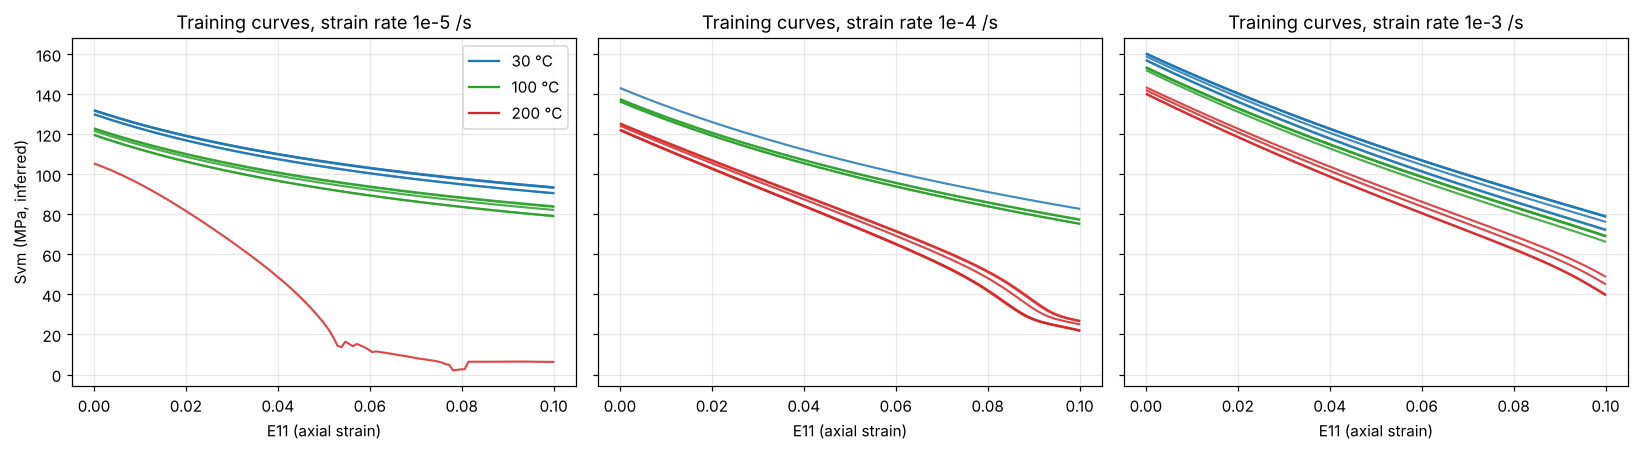

In [2]:
import collections
T_levels = sorted({c['T'] for c in CASES.values()})
print('Cases available per temperature:', {T: sum(c['T'] == T for c in CASES.values()) for T in T_levels})
print('Rows per file:', dict(collections.Counter(c['rows'] for c in CASES.values())))
print('Strain grid:', len(GRID), 'points from', GRID[0], 'to', GRID[-1])
print('Training IDs:', TRAIN.tolist())
print('Test IDs:    ', TEST.tolist())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
colours = {30.0: 'tab:blue', 100.0: 'tab:green', 200.0: 'tab:red'}
for ax, lr in zip(axes, (-5.0, -4.0, -3.0)):
    for i in TRAIN:
        c = CASES[i]
        if c['lr'] == lr:
            ax.plot(GRID, c['S'], color=colours[c['T']], lw=1.4, alpha=0.85)
    ax.set(title=f'Training curves, strain rate 1e{lr:g} /s', xlabel='E11 (axial strain)')
axes[0].set_ylabel('Svm (MPa, inferred)')
for T, col in colours.items():
    axes[0].plot([], [], color=col, label=f'{T:g} °C')
axes[0].legend()
plt.tight_layout(); plt.show()

**What to notice:**
* Every curve *falls* as strain grows. The material softens; it never hardens.
* Higher temperature gives lower stress.
* The **shape** changes with temperature and rate: some curves stay almost straight, while 200 °C at 1e-5 /s collapses.
  The table below measures that shape change as end stress ÷ start stress. Section 4 shows why it matters.

In [3]:
print(f"{'T (°C)':>7} {'rate':>6} {'cases':>6} {'end/start stress':>18}")
for T in T_levels:
    for lr in (-5.0, -4.0, -3.0):
        ids = [i for i in TRAIN if CASES[i]['T'] == T and CASES[i]['lr'] == lr]
        if ids:
            ratio = np.mean([CASES[i]['S'][-1] / CASES[i]['S'][0] for i in ids])
            print(f'{T:7g} {"1e%g" % lr:>6} {len(ids):6d} {ratio:18.3f}')

 T (°C)   rate  cases   end/start stress
     30   1e-5      5              0.704
     30   1e-4      1              0.579
     30   1e-3      6              0.481
    100   1e-5      5              0.674
    100   1e-4      4              0.558
    100   1e-3      4              0.448
    200   1e-5      1              0.060
    200   1e-4      6              0.195
    200   1e-3      4              0.308


## 3. The governing equation: our customised Johnson–Cook law

$$
\sigma_{JC}=\underbrace{\left[A-B\,\varepsilon^{\,n}\right]}_{\text{strain softening}}
\;\underbrace{\left[1+C\ln\dot\varepsilon^*\right]}_{\text{strain rate}}
\;\underbrace{\left[1-T^{*m}\right]}_{\text{temperature}}
\;\underbrace{\left[\tfrac{G}{G_0}\right]^{q}}_{\text{shear modulus}}
\;\underbrace{\left[1-\phi\right]^{r}}_{\text{porosity}}
$$

| Quantity | Definition used | Values in the data |
|---|---|---|
| strain $\varepsilon$ | axial strain `E11` | 0.0002 – 0.0999 |
| rate ratio $\dot\varepsilon^*$ | $\dot\varepsilon/\dot\varepsilon_0$, with $\dot\varepsilon_0=10^{-5}$ s⁻¹ | $\ln\dot\varepsilon^*$ = 0, 2.30, 4.61 |
| homologous temperature $T^*$ | $(T-T_r)/(T_m-T_r)$, with $T_r=30$ °C and $T_m=600$ °C | 0, 0.123, 0.298 |
| modulus ratio $G/G_0$ | $G_0=25300$ MPa | 1, 0.970, 0.9215 |
| porosity $\phi$ | $1-\rho/\rho_0$, with $\rho_0=2700$ kg/m³ | 0, 3 %, 7.85 % (our study point is 4 %) |

* **The minus sign.** Classic Johnson–Cook has $A+B\varepsilon^n$ (hardening). We use $A-B\varepsilon^n$ because all 73 curves soften.
* **Bounds.** The seven constants are kept physical:
  * $B$ is written as $B=A\beta/0.1^n$ with $0\le\beta\le0.99$, so $A-B\varepsilon^n>0$ up to $\varepsilon=0.1$;
  * $C,q,r\ge0$, because in every training pair stress rises with G and with density, i.e. falls with porosity.

  Without the bounds, a plain fit returned r = −0.027, which would mean stress rises with porosity.

The cell below evaluates the equation in code (`J.jc_numpy`) and checks one value by hand.

In [4]:
c = CFG['constants']
print('Constants of the definitions:', c)
for T in (30, 100, 200, 300):
    print(f'T = {T:3d} °C  ->  T* = {(T - c["T_ref"]) / (c["T_melt"] - c["T_ref"]):.4f}')
for lr in (-5, -4, -3):
    print(f'rate 1e{lr} /s  ->  ln(rate*) = {np.log(10.0**lr / c["rate0"]):.4f}')
for rho in (2700, 2619, 2592, 2488.05):
    print(f'density {rho:7.2f}  ->  phi = {100 * (1 - rho / c["rho0"]):.2f} %')

theta = [150.0, 400.0, 0.8, 0.03, 1.1, 0.7, 0.05]          # an example set of A, B, n, C, m, q, r
x = np.array([[100.0, -4.0, 2619.0, 24541.0, 0.05]])         # T, log10 rate, density, G, E11
A, B, n, C_, m, q, r = theta
by_hand = (A - B * 0.05**n) * (1 + C_ * np.log(10)) * (1 - (70 / 570)**m) * (24541 / 25300)**q * (2619 / 2700)**r
print('\nEquation 1 in code:', J.jc_numpy(theta, x, c)[0], '| by hand:', by_hand)

Constants of the definitions: {'rate0': 1e-05, 'T_ref': 30.0, 'T_melt': 600.0, 'G0': 25300.0, 'rho0': 2700.0, 'eps_ref': 0.1}
T =  30 °C  ->  T* = 0.0000
T = 100 °C  ->  T* = 0.1228
T = 200 °C  ->  T* = 0.2982
T = 300 °C  ->  T* = 0.4737
rate 1e-5 /s  ->  ln(rate*) = 0.0000
rate 1e-4 /s  ->  ln(rate*) = 2.3026
rate 1e-3 /s  ->  ln(rate*) = 4.6052
density 2700.00  ->  phi = 0.00 %
density 2619.00  ->  phi = 3.00 %
density 2592.00  ->  phi = 4.00 %
density 2488.05  ->  phi = 7.85 %

Equation 1 in code: 106.87380662939994 | by hand: 106.87380662939992


## 4. Why the equation alone is not enough

First we fit **only** the seven constants to the 36 training curves, with no neural network. The fit is bounded nonlinear
least squares (SciPy `least_squares`) started from 8 points; the lowest error wins. This is exactly the calibration used
inside the model code (`J.calibrate_jc`).

Equation 1 is a **product of separate terms**. Temperature, rate, G and porosity can therefore only scale a curve up or down;
they cannot change its *shape*, because $A-B\varepsilon^n$ is the same for every condition. Section 2 showed that the shape
does change, so even the best possible constants leave a large error. That error is a property of the equation, not of
the fit.

Calibrated in 0.8 s. Constants at a bound: ['r']
  A =      148.769   (saved run: 148.769)
  B =      526.229   (saved run: 526.229)
  n =     0.827558   (saved run: 0.827558)
  C =    0.0292469   (saved run: 0.0292469)
  m =      1.11323   (saved run: 1.11323)
  q =     0.717322   (saved run: 0.717322)
  r =  6.50974e-21   (saved run: 6.50974e-21)

Equation 1 alone on its own training curves: mean RMSE 8.95 MPa (10.3 % of the stress), worst 39.7 MPa (case 60)


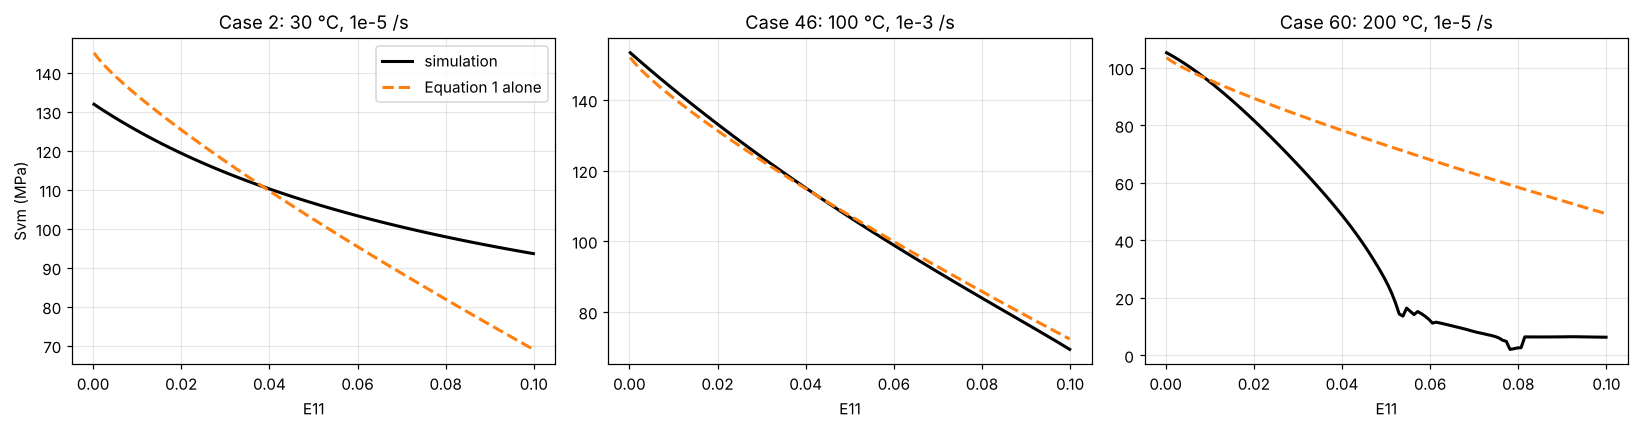

In [5]:
Xq, yq = J.queries(X_train, GRID), Y_train.ravel()
x_mean, x_scale, y_scale = J.scalers(Xq, Y_train)
t0 = time.time()
v, cal = J.calibrate_jc(Xq, yq, CFG, y_scale)
theta_alone = J.theta_from_cal(v, c)
print(f'Calibrated in {time.time() - t0:.1f} s. Constants at a bound: {cal["at_bounds"]}')
for k, a, b in zip(J.PARAMS, theta_alone, EQ_ONLY['theta'].values()):
    print(f'  {k} = {a:12.6g}   (saved run: {b:.6g})')
p_alone = J.jc_numpy(theta_alone, Xq, c).reshape(Y_train.shape)
s = J.scores(Y_train, p_alone)
print(f'\nEquation 1 alone on its own training curves: mean RMSE {s["mean_rmse"]:.2f} MPa '
      f'({100 * s["mean_nrmse"]:.1f} % of the stress), worst {s["worst_rmse"]:.1f} MPa (case {TRAIN[np.argmax(s["case_rmse"])]})')

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, i in zip(axes, (2, 46, 60)):
    k = list(TRAIN).index(i)
    ax.plot(GRID, Y_train[k], 'k', lw=2, label='simulation')
    ax.plot(GRID, p_alone[k], '--', color='tab:orange', lw=2, label='Equation 1 alone')
    ax.set(title=f'Case {i}: {CASES[i]["T"]:g} °C, 1e{CASES[i]["lr"]:g} /s', xlabel='E11')
axes[0].set_ylabel('Svm (MPa)'); axes[0].legend(); plt.tight_layout(); plt.show()

**Reading the result.**
* **r = 0:** the separable fit finds no porosity effect it can use. In these simulations density changes stress by only
  about 0.2 %, much less than the shape mismatch.
* **The calibrated law** (these are the constants to quote for Equation 1) is:

  **A ≈ 148.8, B ≈ 526.2, n ≈ 0.83, C ≈ 0.029, m ≈ 1.11, q ≈ 0.72, r = 0.**

## 5. The model: equation backbone × neural-network correction

$$
\hat\sigma(T,\dot\varepsilon,\rho,G,\varepsilon)=\sigma_{JC}(A,B,n,C,m,q,r)\cdot\exp\!\big(\delta(z)\big),\qquad
z=\frac{x-\mu}{s}
$$

* **Backbone:** Equation 1 with its seven bounded constants.
* **Correction δ:** a small multilayer perceptron. It has 5 inputs (T, log₁₀ rate, ρ, G, E11, each standardised with the training
  mean μ and standard deviation s), two hidden layers of 16 tanh units and one linear output: **385 weights and biases**.
  * Its output layer starts at **zero**, so before training δ = 0 and the model *is* Equation 1.
  * exp(δ) is a multiplicative correction: exp(δ) = 0.9 means "10 % below Equation 1".
  * The exponential also keeps the predicted stress positive.
* **Ensemble:** five such networks with different random starts (seeds 0–4), combined by a geometric mean:
  $\hat\sigma=\exp\big(\tfrac15\sum_k[\ln\sigma_{JC}(\theta_k)+\delta_k]\big)$.
* **Constants frozen or joint:** "frozen" keeps the calibrated constants fixed. "Joint" lets training adjust them
  together with the network, which is the "alter the weights" option. Both were tested; joint won (Section 7).

The cell builds one untrained model and checks the two claims above: 385 parameters, and output identical to Equation 1.

In [6]:
torch = J._torch()
model = J.build_model(v, CFG, x_mean, x_scale, joint=True, seed=0)
n_net = sum(p.numel() for name, p in model.named_parameters() if name != 'u')
print(model.l1, model.l2, model.l3, sep='\n')
print('Network weights and biases:', n_net, '| trainable Equation 1 variables:', model.u.numel())
with torch.no_grad():
    s0, base0, d0 = model(torch.tensor(Xq))
start_theta = model.theta().detach().numpy()
print('Untrained model vs Equation 1 at its starting constants, max difference:',
      float(np.max(np.abs(s0.numpy() - J.jc_numpy(start_theta, Xq, c)))), 'MPa')
print('Starting constants vs calibrated ones, max relative difference:',
      float(np.max(np.abs(start_theta - theta_alone) / np.maximum(np.abs(theta_alone), 1e-3))),
      '(the trainable bound mapping holds a constant sitting exactly on a bound, here r = 0, a hair inside it)')
print('Untrained correction delta: max |delta| =', float(d0.abs().max()))

Linear(in_features=5, out_features=16, bias=True)
Linear(in_features=16, out_features=16, bias=True)
Linear(in_features=16, out_features=1, bias=True)
Network weights and biases: 385 | trainable Equation 1 variables: 7


Untrained model vs Equation 1 at its starting constants, max difference: 2.842170943040401e-14 MPa
Starting constants vs calibrated ones, max relative difference: 0.020000000000000007 (the trainable bound mapping holds a constant sitting exactly on a bound, here r = 0, a hair inside it)
Untrained correction delta: max |delta| = 0.0


## 6. The loss function and the physics (PINN) terms

Training minimises

$$
\mathcal L=\underbrace{\frac1N\sum_i\Big(\frac{\hat\sigma_i-\sigma_i}{s_y}\Big)^2}_{\text{data: 36 curves × 120 points}}
+\lambda\,\underbrace{\frac1M\sum_{j}R_j^2}_{\text{physics residual}}
+\underbrace{\frac{\alpha}{N}\sum W^2}_{\text{weight decay}}
$$

* **Data term:** the mean squared stress error, scaled by the training stress spread $s_y$, so it has no units. Every curve
  contributes 120 equally weighted points.
* **Physics term:** evaluated at **M = 4,096 collocation points**. These are input combinations spread evenly (a scrambled
  Sobol sequence) over the whole planned design box: 30–300 °C, all rates, densities, G values and strains. They include
  conditions that have no simulation file. No stress values are used there; the points only say "obey the equation here".
  Two residual forms were tested:
  * **level:** $R=\delta=\ln\hat\sigma-\ln\sigma_{JC}$, so the prediction should stay close to Equation 1;
  * **trend:** $R=\partial\delta/\partial z_c$ for the four conditions (T, rate, ρ, G), computed by **automatic
    differentiation**. The model's *sensitivities* to the conditions should equal Equation 1's, while the strain-shape
    correction stays free.
* **λ** sets how strongly the physics is enforced. λ = 0 is a pure data fit; a huge λ returns Equation 1 exactly.
* **Weight decay α = 1** keeps the network smooth. It was fixed beforehand from a check on the training folds only, because
  a weak α let exp(δ) blow up when extrapolating (fold error 25 against 2.4).

Collocation points: (4096, 5) - columns T, log10 rate, density, G, E11 (inputs only, no stresses)


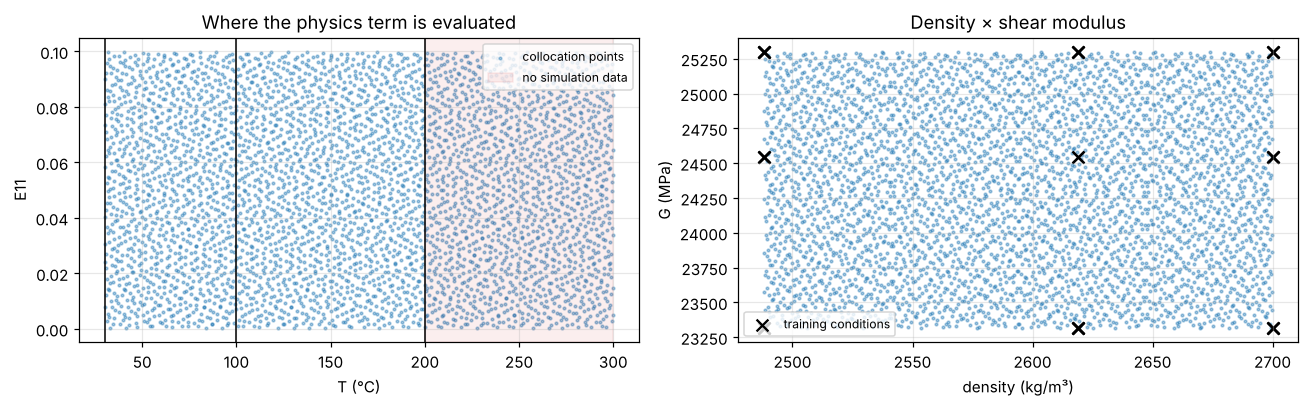

level residual of the untrained model (equal to Equation 1): 0.0


trend residual of the untrained model (equal to Equation 1): 0.0


In [7]:
Cq = J.collocation(CFG)
print('Collocation points:', Cq.shape, '- columns T, log10 rate, density, G, E11 (inputs only, no stresses)')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(Cq[:, 0], Cq[:, 4], s=3, alpha=0.4, label='collocation points')
for T in (30, 100, 200):
    axes[0].axvline(T, color='k', lw=1)
axes[0].axvspan(200, 300, color='tab:red', alpha=0.08, label='no simulation data')
axes[0].set(xlabel='T (°C)', ylabel='E11', title='Where the physics term is evaluated'); axes[0].legend(loc='upper right', fontsize=8)
axes[1].scatter(Cq[:, 2], Cq[:, 3], s=3, alpha=0.4)
axes[1].scatter(X_train[:, 2], X_train[:, 3], s=60, c='k', marker='x', label='training conditions')
axes[1].set(xlabel='density (kg/m³)', ylabel='G (MPa)', title='Density × shear modulus'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

for form in ('level', 'trend'):
    print(f'{form:>5} residual of the untrained model (equal to Equation 1):', J.physics_residual(model, torch.tensor(Cq), form).item())

## 7. Training and choosing the settings without seeing the test data

### 7.1 How one network is trained
Each network is trained on the whole training set at once (full batch, float64, CPU, fixed seed, so runs are
repeatable): **1,500 Adam steps** (learning rate 0.005) to get close, then up to **2,500 L-BFGS iterations** with a
strong-Wolfe line search to settle precisely. The next cell trains member 0 of the final model live with the selected
settings and compares it with the saved member. On this exact software it matches bit for bit; on other hardware tiny
rounding differences can grow slightly through L-BFGS.

In [8]:
chosen = SUM['selected']
print('Selected settings:', chosen)
t0 = time.time()
member, info = J.train_member(Xq, yq, Cq, v, CFG, x_mean, x_scale, y_scale, chosen, seed=0)
print(f"Trained in {time.time() - t0:.0f} s: loss after Adam {info['loss_after_adam']:.3e}, final {info['loss']:.3e} "
      f"(data {info['data_loss']:.3e}, weight decay {info['weight_loss']:.3e}), L-BFGS iterations {info['lbfgs_iterations']}")
saved = EQ['members'][0]
diff = max(np.max(np.abs(np.array(member[k]) - np.array(saved[k]))) for k in ('W1', 'W2', 'w3', 'theta'))
print('Largest difference from the saved member 0:', diff)

Selected settings: {'physics': 'none', 'lambda_phys': 0.0, 'theta_mode': 'joint'}


Trained in 25 s: loss after Adam 5.954e-03, final 2.796e-03 (data 3.930e-04, weight decay 2.403e-03), L-BFGS iterations 2500
Largest difference from the saved member 0: 0.0


### 7.2 Choosing the settings
We do **not** pick settings by looking at test results. Each candidate setting is scored on the 36 training cases in two ways:
1. **Case cross-validation:** split the 36 cases into 3 folds; train on two, predict the third, and repeat.
2. **Unseen-condition holdouts:** for each of the 9 temperature/rate groups, hide *all* its cases, train on the rest and predict
   them. This tests prediction for a condition the model has never seen.

The **balanced score** we chose is ½ × (case-CV error + mean group-holdout error). The candidates were the physics form
(none / level / trend), λ, and frozen or joint constants: **14 settings**.
* Every split refits the scalers and the Equation 1 constants on its own fitting cases.
* Each setting is a 3-seed ensemble.
* In total: 14 × 12 splits × 3 seeds = **504 trained networks**.

In [9]:
sp = J.splits(X_train, TRAIN, CFG)
for s_ in sp:
    print(f"{s_['name']:>14}: fit on {len(s_['fit_ids']):2d} cases, predict {len(s_['val_ids']):2d} -> {s_['val_ids']}")
print()
rows = sorted(SUM['trials'], key=lambda t: t['score'])
print(f"{'physics':>8} {'lambda':>7} {'constants':>9} {'case-CV':>8} {'unseen':>8} {'score':>7}")
for t in rows:
    cd = t['candidate']
    mark = '  <- selected' if cd == chosen else ''
    print(f"{cd['physics']:>8} {cd['lambda_phys']:7g} {cd['theta_mode']:>9} {t['cv']:8.3f} {t['groups']:8.3f} {t['score']:7.3f}{mark}")
print(f"{'Equation 1 alone':>26} {SUM['equation_only']['cv']:8.3f} {SUM['equation_only']['groups']:8.3f}")
print(f"{'Curve-copy baseline':>26} {SUM['lookup']['cv']:8.3f} {SUM['lookup']['groups']:8.3f}")

         fold0: fit on 24 cases, predict 12 -> [22, 25, 28, 29, 34, 38, 46, 64, 70, 72, 80, 81]
         fold1: fit on 24 cases, predict 12 -> [2, 3, 5, 6, 8, 18, 27, 33, 41, 53, 69, 78]
         fold2: fit on 24 cases, predict 12 -> [19, 21, 26, 30, 40, 43, 49, 52, 60, 65, 66, 76]
    T30_rate-5: fit on 31 cases, predict  5 -> [2, 3, 5, 6, 8]
    T30_rate-4: fit on 35 cases, predict  1 -> [18]
    T30_rate-3: fit on 30 cases, predict  6 -> [19, 21, 22, 25, 26, 27]
   T100_rate-5: fit on 31 cases, predict  5 -> [28, 29, 30, 33, 34]
   T100_rate-4: fit on 32 cases, predict  4 -> [38, 40, 41, 43]
   T100_rate-3: fit on 32 cases, predict  4 -> [46, 49, 52, 53]
   T200_rate-5: fit on 35 cases, predict  1 -> [60]
   T200_rate-4: fit on 30 cases, predict  6 -> [64, 65, 66, 69, 70, 72]
   T200_rate-3: fit on 32 cases, predict  4 -> [76, 78, 80, 81]

 physics  lambda constants  case-CV   unseen   score
    none       0     joint    2.098    6.235   4.166  <- selected
    none       0    frozen

**Reading the selection.**
* The winner is **the Equation 1 backbone with jointly trained constants and no extra physics penalty (λ = 0)**.
* Every level or trend penalty made *both* errors worse. Equation 1 is about 10 % off in level, and its fixed shape is wrong for
  hot or slow conditions, so pulling the model toward it, or toward its trends, moves predictions away from the simulations.
* A PINN penalty only helps when the governing equation is right where the data are missing.

### 7.3 Lock, then test once
The selected setting is retrained on all 36 training cases as a 5-seed ensemble. Its complete equation is saved, and its
SHA-256 fingerprint is written to `selection_lock.json` **before** the code opens any of the 37 test files. The test score
is computed once. An independent script (`scripts/verify_jc_pinn.py`) re-implements the equation in plain NumPy and
reproduces every prediction to 2.6e-13 MPa.

## 8. The output

### 8.1 Test results on the 37 held-out simulations
The next cell recomputes the test predictions from the saved equation (NumPy only) and checks that they equal the verified run.

Model                                              mean RMSE (MPa)  % of stress
Equation 1 alone                                            7.3656       7.32 %
Curve-copy baseline                                         1.3790       1.27 %
JC-PINN (this model)                                        0.4386       0.42 %
Same network, Equation 1 switched off (control)             0.3375       0.33 %
Single MLP (2 Nov, no physics)                              0.1427            -
5-net MLP ensemble (24 Oct, no physics)                     0.0591            -

JC-PINN median 0.3952, worst 0.8406 MPa (case 10); 17x lower error than Equation 1 alone


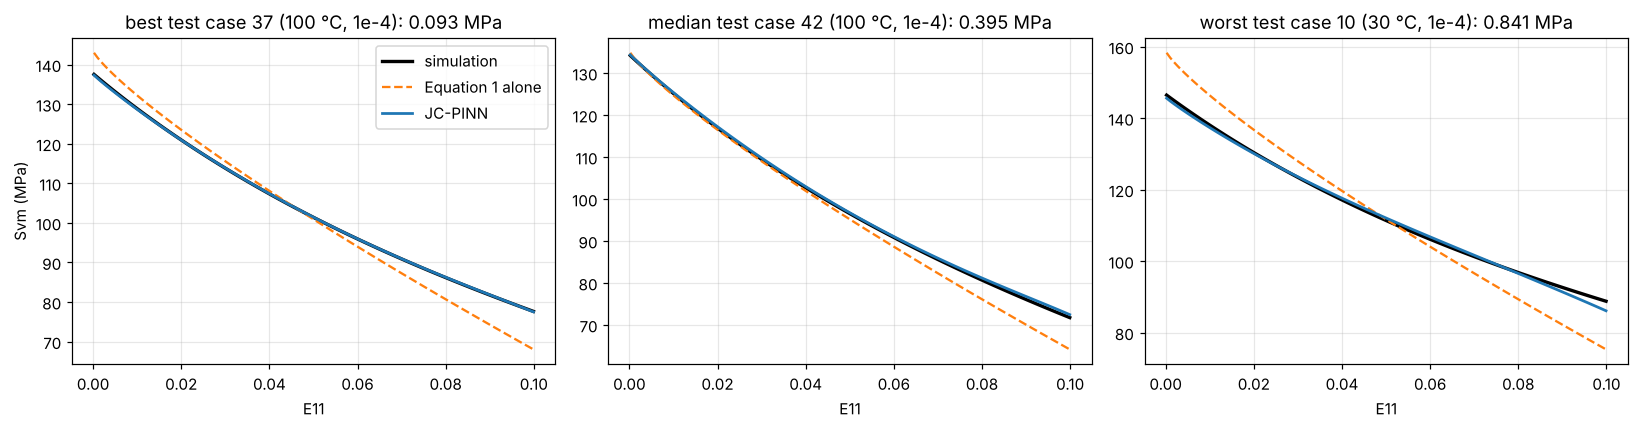

In [10]:
Vq = J.queries(X_test, GRID)
p_test = J.equation_predict(EQ, Vq).reshape(Y_test.shape)
p_eq1 = J.jc_numpy(list(EQ_ONLY['theta'].values()), Vq, c).reshape(Y_test.shape)
m_pinn, m_eq1 = J.scores(Y_test, p_test), J.scores(Y_test, p_eq1)
assert abs(m_pinn['mean_rmse'] - SUM['test']['jc_pinn']['mean_rmse']) < 1e-9
ctl = SUM['control']['control']
table = [('Equation 1 alone', m_eq1['mean_rmse'], m_eq1['mean_nrmse']),
         ('Curve-copy baseline', SUM['test']['lookup']['mean_rmse'], SUM['test']['lookup']['mean_nrmse']),
         ('JC-PINN (this model)', m_pinn['mean_rmse'], m_pinn['mean_nrmse']),
         ('Same network, Equation 1 switched off (control)', ctl['test']['mean_rmse'], ctl['test']['mean_nrmse']),
         ('Single MLP (2 Nov, no physics)', SUM['single_mlp']['test'], None),
         ('5-net MLP ensemble (24 Oct, no physics)', SUM['ensemble_mlp']['test'], None)]
print(f"{'Model':<50}{'mean RMSE (MPa)':>16}{'% of stress':>13}")
for name, e, nr in table:
    print(f"{name:<50}{e:16.4f}{('%.2f %%' % (100 * nr)) if nr is not None else '-':>13}")
print(f"\nJC-PINN median {m_pinn['median_rmse']:.4f}, worst {m_pinn['worst_rmse']:.4f} MPa (case {TEST[np.argmax(m_pinn['case_rmse'])]});"
      f" {m_eq1['mean_rmse'] / m_pinn['mean_rmse']:.0f}x lower error than Equation 1 alone")

order = np.argsort(m_pinn['case_rmse'])
picks = [order[0], order[len(order) // 2], order[-1]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, lab in zip(axes, picks, ('best', 'median', 'worst')):
    ax.plot(GRID, Y_test[k], 'k', lw=2.2, label='simulation')
    ax.plot(GRID, p_eq1[k], '--', color='tab:orange', label='Equation 1 alone')
    ax.plot(GRID, p_test[k], color='tab:blue', lw=1.8, label='JC-PINN')
    i = TEST[k]
    ax.set(title=f'{lab} test case {i} ({CASES[i]["T"]:g} °C, 1e{CASES[i]["lr"]:g}): {m_pinn["case_rmse"][k]:.3f} MPa', xlabel='E11')
axes[0].set_ylabel('Svm (MPa)'); axes[0].legend(); plt.tight_layout(); plt.show()

### 8.2 Unseen temperature/rate conditions
Each bar is the error when that whole condition was hidden during training. The JC-PINN's own numbers are slightly
optimistic, because the selection score used them.

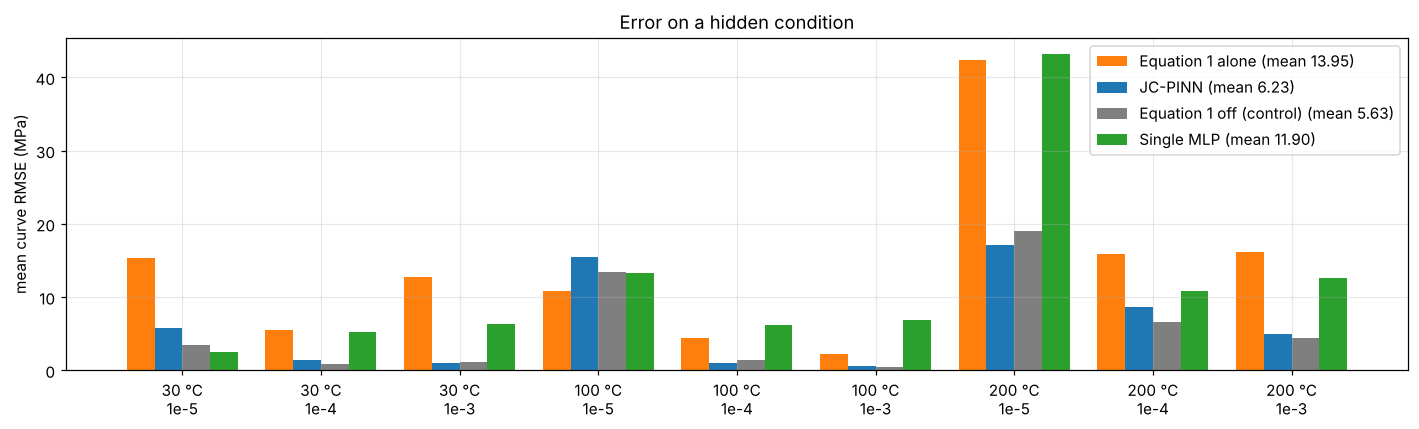

In [11]:
G_ = SUM['selected_groups']
labels = [f"{g['T']:g} °C\n1e{g['lr']:g}" for g in G_]
series = [('Equation 1 alone', SUM['equation_only']['group_rows'], 'tab:orange'),
          ('JC-PINN', [g['rmse'] for g in G_], 'tab:blue'),
          ('Equation 1 off (control)', [g['mean_rmse'] for g in SUM['control']['control']['groups']], 'tab:gray'),
          ('Single MLP', SUM['single_mlp']['groups'], 'tab:green')]
w = 0.2
fig, ax = plt.subplots(figsize=(13, 4))
for k, (lab, vals, col) in enumerate(series):
    ax.bar(np.arange(9) + (k - 1.5) * w, vals, w, label=f'{lab} (mean {np.mean(vals):.2f})', color=col)
ax.set_xticks(range(9), labels); ax.set_ylabel('mean curve RMSE (MPa)'); ax.legend(); ax.set_title('Error on a hidden condition')
plt.tight_layout(); plt.show()

### 8.3 The control experiment: does Equation 1 help?
To test the equation's contribution, the identical network and training were run with Equation 1 **switched off**: the
backbone was made constant. This control was not used to choose anything; the delivered model is unchanged.

In [12]:
j, ctl = SUM['control']['jc_pinn'], SUM['control']['control']
print(f"{'':<36}{'case-CV':>9}{'unseen':>9}{'test':>9}")
print(f"{'JC-PINN (Equation 1 backbone)':<36}{j['cv_mean_rmse']:9.3f}{j['group_mean_rmse']:9.3f}{j['test']['mean_rmse']:9.4f}")
print(f"{'Same network, Equation 1 off':<36}{ctl['cv_mean_rmse']:9.3f}{ctl['group_mean_rmse']:9.3f}{ctl['test']['mean_rmse']:9.4f}")

                                      case-CV   unseen     test
JC-PINN (Equation 1 backbone)           2.098    6.235   0.4386
Same network, Equation 1 off            1.315    5.629   0.3375


**What the comparison shows.**
* **Accuracy comes from the network and the training recipe, not from the equation.** The control is better on every
  measure. Equation 1's separable form forces one curve shape on every condition, and the network spends part of its
  capacity undoing that.
* **Against the earlier models:** on unseen conditions the new recipe (strong weight decay, log-space output) beats the
  single MLP (6.2 against 11.9). On the professor's random 50/50 test, the earlier MLPs remain more precise
  (0.143 and 0.059 against 0.439). The balanced criterion we chose traded some interpolation precision for better
  behaviour on new conditions.
* **What Equation 1 gives us:**
  * seven named, physically bounded constants;
  * a model that starts from a stated physical law;
  * a 17-fold error reduction over that law alone.

  It does **not** make the predictions more accurate. The data say that its separable form is not the governing law of
  these simulations, and that is a valid scientific result.

### 8.4 Physical sanity checks
Using autograd on the collocation points, we count how often the model breaks the sign rules seen in every training-data
pair:
* stress falls with strain and with temperature;
* stress rises with G and with density.

Strain rate is not checked, because the data itself is mixed: at large strain, stress falls with rate at 30 °C.

In [13]:
mono = J.monotonicity(EQ, CFG)
for region in ('observed_30_200C', 'physics_only_200_300C'):
    m_ = mono[region]
    print(f"{region:>24}: {m_['points']} points | dS/dE11>0 {100*m_['dS_dE11_positive']:.1f} % | dS/dT>0 {100*m_['dS_dT_positive']:.1f} % | "
          f"dS/dG<0 {100*m_['dS_dG_negative']:.1f} % | dS/drho<0 {100*m_['dS_ddensity_negative']:.1f} %")

        observed_30_200C: 2579 points | dS/dE11>0 0.0 % | dS/dT>0 0.0 % | dS/dG<0 0.0 % | dS/drho<0 0.0 %
   physics_only_200_300C: 1517 points | dS/dE11>0 0.0 % | dS/dT>0 0.0 % | dS/dG<0 0.0 % | dS/drho<0 2.5 %


### 8.5 Using the model: predict any condition
`predict_curve` evaluates the saved equation with NumPy. Give a temperature (°C), a strain rate (1/s) and either a porosity
`phi` (fraction) or a `density`; G is in MPa.
* **Valid range:** 30–200 °C, rates 1e-5 to 1e-3 /s, φ = 0–7.85 %, G from 23,314 to 25,300 MPa, E11 up to 0.0999.
* **Above 200 °C** there is no data and no physics penalty, so those curves are **unvalidated extrapolation**.

The figure shows our study condition, φ = 4 % (ρ = 2592 kg/m³) with G = 24,541 MPa. The final cell of this part saves the
curves to a CSV file.

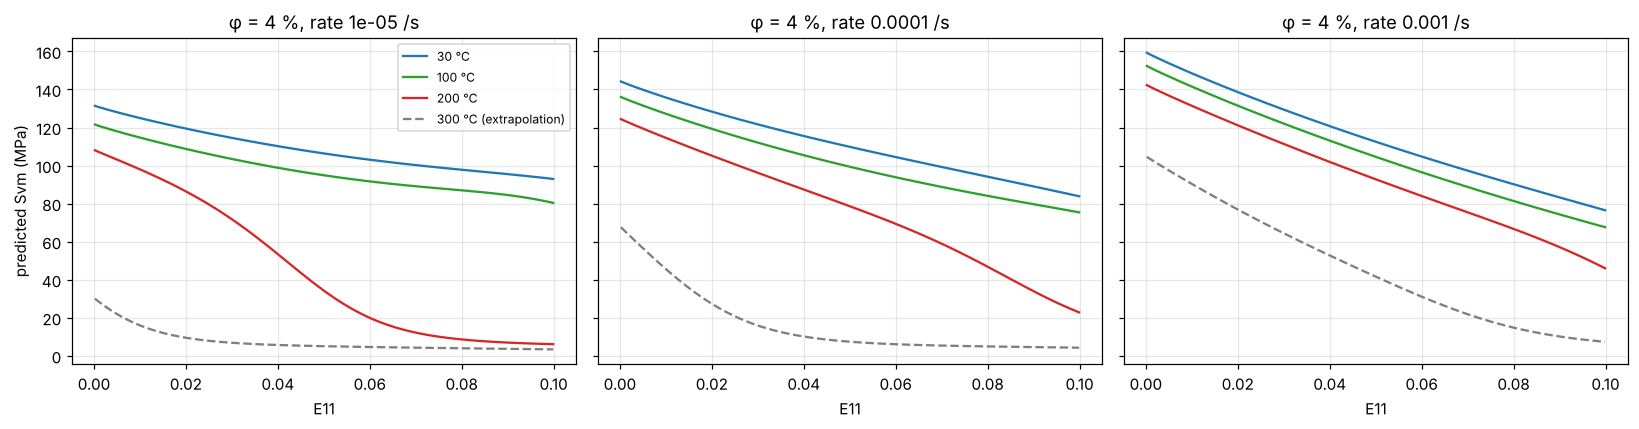

100 °C, 1e-4 /s, phi = 4 %: E11=0.000: 136.06 MPa, E11=0.050: 99.12 MPa, E11=0.100: 75.41 MPa


In [14]:
def predict_curve(T, rate, phi=None, density=None, G=24541.0, eq=EQ):
    rho = density if density is not None else 2700.0 * (1 - (0.04 if phi is None else phi))
    X5 = np.c_[np.tile([T, np.log10(rate), rho, G], (len(GRID), 1)), GRID]
    return J.equation_predict(eq, X5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows_out = []
for ax, rate in zip(axes, (1e-5, 1e-4, 1e-3)):
    for T, col in ((30, 'tab:blue'), (100, 'tab:green'), (200, 'tab:red'), (300, 'tab:gray')):
        s_ = predict_curve(T, rate, phi=0.04)
        ax.plot(GRID, s_, '--' if T > 200 else '-', color=col, label=f'{T} °C' + (' (extrapolation)' if T > 200 else ''))
        rows_out += [(T, rate, e, v_) for e, v_ in zip(GRID, s_)]
    ax.set(title=f'φ = 4 %, rate {rate:g} /s', xlabel='E11')
axes[0].set_ylabel('predicted Svm (MPa)'); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

s_ = predict_curve(100, 1e-4, phi=0.04)
print('100 °C, 1e-4 /s, phi = 4 %:', ', '.join(f'E11={GRID[k]:.3f}: {s_[k]:.2f} MPa' for k in (0, 60, 119)))

In [15]:
import csv as _csv
out_csv = WORK / 'predictions_phi4.csv'
with open(out_csv, 'w', newline='') as f:
    w_ = _csv.writer(f); w_.writerow(['T_C', 'rate_per_s', 'E11', 'Svm_MPa'])
    w_.writerows(rows_out)
print('Saved', len(rows_out), 'rows to', out_csv)

Saved 1440 rows to /home/user/MMM-ML/notebooks/jc_pinn_work/predictions_phi4.csv


## 9. Optional: retrain from the professor's data

Set `RUN_TRAINING = True` and choose a mode:
* `'FAST'` retrains the selected setting on the 36 training cases, locks it and scores the 37 test cases. It takes about
  2–5 minutes on Colab.
* `'FULL'` repeats the whole 504-network selection. It takes about 1–2 hours on Colab's 2 CPUs, or 37 minutes on 4 cores.

**Where the data must be:**
* **Colab:** `TEAM_8_extracted_results_set_1`, or its ZIP, anywhere in My Drive. If the folder was shared with you, add a shortcut to My Drive first.
* **Kaggle:** add it as a Dataset input.
* **Local:** next to this notebook, or set `DATA_PATH`.

The code reads the training files first, saves and locks the model, and only then reads the test files. It also checks that
the curves it reads match the verified run.

In [16]:
RUN_TRAINING = False      # set True to retrain
MODE = 'FAST'             # 'FAST' or 'FULL'
DATA_PATH = ''            # optional: folder or ZIP path
WORKERS = None            # None = all CPU cores

In [17]:
import zipfile

def find_data(hint=''):
    if hint:
        p = Path(hint)
        if p.is_dir():
            return p
        return unzip(p)
    roots = []
    if IN_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
        roots += [Path('/content/drive/MyDrive'), Path('/content/drive/Shareddrives')]
    if IN_KAGGLE:
        roots.append(Path('/kaggle/input'))
    roots += [Path.cwd(), Path.cwd().parent]
    for root_ in roots:
        if not root_.exists():
            continue
        for depth in range(5):
            for h in sorted(root_.glob('/'.join(['*'] * depth + ['simulation_matrix.csv']))):
                if any(h.parent.glob('simulation_0*')):
                    return h.parent
        for z in sorted(root_.glob('TEAM_8*.zip')) + sorted(root_.glob('*/TEAM_8*.zip')):
            return unzip(z)
    raise FileNotFoundError('TEAM_8_extracted_results_set_1 not found: set DATA_PATH')

def unzip(z):
    target = WORK / 'raw'
    with zipfile.ZipFile(z) as archive:
        names = [n.replace('\\', '/') for n in archive.namelist()]
        for rel in ['simulation_matrix.csv'] + [f'simulation_{i:04d}/STR_STR.OUT' for i in SPLIT['train'] + SPLIT['test']]:
            hit = [archive.namelist()[k] for k, n in enumerate(names) if n == rel or n.endswith('/' + rel)]
            if len(hit) != 1:
                raise ValueError(f'{rel}: {len(hit)} matches in {z}')
            out = target / rel
            out.parent.mkdir(parents=True, exist_ok=True)
            out.write_bytes(archive.read(hit[0]))
    return target

if RUN_TRAINING:
    RAW = find_data(DATA_PATH)
    base = (Path('/content/drive/MyDrive/MMM-ML/jc_pinn_runs') if IN_COLAB else
            Path('/kaggle/working/jc_pinn_runs') if IN_KAGGLE else WORK / 'runs')
    OUT = base / time.strftime('%Y%m%dT%H%M%SZ', time.gmtime())
    result = J.run(WORK, RAW, OUT, mode=MODE.lower(), workers=WORKERS,
                   selected=dict(selected=SUM['selected']) if MODE == 'FAST' else None, expected=SUM['fingerprints'])
    print('Saved to', OUT)
    print('Test mean RMSE this run:', result['test']['jc_pinn']['mean_rmse'], '| verified run:', SUM['test']['jc_pinn']['mean_rmse'])
    from IPython.display import Image, display
    for name in ('test_comparison.png', 'condition_holdouts.png', 'study_point_curves.png'):
        if (OUT / name).exists():
            display(Image(filename=str(OUT / name)))
else:
    print('Retraining skipped (RUN_TRAINING = False). Every result above comes from the verified saved model.')

Retraining skipped (RUN_TRAINING = False). Every result above comes from the verified saved model.


## 10. Limits and questions to expect in the viva

**Limits**
* **Not a blind test.** The 37 test cases were explored in earlier project stages. The group-holdout errors were part of the
  selection score, so the selected model's group errors are slightly optimistic.
* **Units.** Stress units are inferred as MPa. The model reproduces the professor's simulations; it is not validated
  against experiments.
* **Above 200 °C** there is no data, so 300 °C curves are unvalidated extrapolation.
* **Case 60** (200 °C, 1e-5 /s) collapses abruptly. Every model misses it when it is held out.
* **Two sets of constants.** The constants inside the JC-PINN are trained together with the network, so they only mean something
  together with it. Quote the "Equation 1 alone" constants as the calibrated law.

**Likely questions**
* **Is this a PINN?** It is a constitutive (material-point) physics-informed network. The physics is built into the model's
  structure, and physics residuals at collocation points were tested in its loss. The selection found that this equation's
  residuals did not help. It is not a 3D equilibrium PINN, because the data have no spatial fields.
* **Why multiply by exp(δ)?** It is a relative correction that keeps stress positive, and with δ = 0 the model is exactly the
  physical law.
* **Why 120 points per curve?** So that every simulation counts equally, whatever its number of output rows.
* **How do you know you didn't tune on the test set?** Every setting was chosen with training-only scores. The model's
  fingerprint was saved before the test files were opened, and an independent script re-checks this order.
* **What would improve the physics?** Let B and n depend on temperature and rate, so the equation itself can change the curve
  shape. That would be a new, extended law, to be qualified the same way.